In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import scipy.stats as stats
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, classification_report, roc_curve, auc, accuracy_score
import warnings
import plotly.graph_objects as go
from IPython.display import display, HTML
from sklearn.decomposition import PCA
import plotly.io as pio
pio.renderers.default = "notebook"
import plotly.graph_objects as go
import plotly.express as px
from plotly.subplots import make_subplots
warnings.filterwarnings('ignore')
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, silhouette_samples, davies_bouldin_score, calinski_harabasz_score
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.mixture import GaussianMixture
from sklearn.model_selection import ParameterGrid
from scipy.stats import chi2, norm
import subprocess
import sys
import rpy2
from rpy2.robjects.packages import importr
from rpy2.robjects import r, pandas2ri
from itertools import product
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

from sklearn.model_selection import train_test_split, GridSearchCV,cross_val_score, StratifiedKFold
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    confusion_matrix, classification_report, accuracy_score, roc_curve, auc, RocCurveDisplay)
from sklearn.svm import SVC
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay, roc_curve, roc_auc_score
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    fbeta_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    roc_curve,
    RocCurveDisplay,
    precision_recall_curve,
    PrecisionRecallDisplay,
    matthews_corrcoef,
    log_loss,
    brier_score_loss,
    hinge_loss
)
from sklearn.metrics import r2_score
from sklearn.model_selection import learning_curve
from sklearn.model_selection import train_test_split, GridSearchCV,RandomizedSearchCV,StratifiedKFold
import time
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error,mean_absolute_error
from scipy.stats import loguniform
from sklearn.neighbors import KNeighborsRegressor
from sklearn.model_selection import validation_curve
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import LassoCV
import statsmodels.api as sm
from sklearn.feature_selection import SequentialFeatureSelector
from sklearn import tree
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from xgboost import XGBClassifier
import xgboost as xgb
from matplotlib.patches import Ellipse
import math

In [ ]:
# @title
from google.colab import drive
drive.mount('/content/drive')




Mounted at /content/drive


In [ ]:
# @title
import pandas as pd

df = pd.read_csv('/content/drive/MyDrive/student_priority_10k.csv')

In [ ]:
# @title
#!pip install plotly pandas


import plotly.io as pio
pio.renderers.default = 'colab'

In [ ]:
# @title
from IPython.display import HTML, display

html_bo = """
<style>
.objectives-container {
    font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, 'Helvetica Neue', Arial, sans-serif;
    background: linear-gradient(135deg, rgba(245,245,250,0.5), rgba(240,240,255,0.5));
    padding: 40px;
    border-radius: 12px;
    box-shadow: 0 4px 12px rgba(0,0,0,0.08);
    color: #333;
    line-height: 1.8;
}

.objectives-container h1 {
    font-size: 30px;
    font-weight: 500;
    text-align: center;
    color: black;
    margin-bottom: 35px;
}

.bo-box {
    background: #ffffff;
    border-left: 6px solid #9C27B0;
    margin-bottom: 25px;
    padding: 20px 25px;
    border-radius: 10px;
    box-shadow: 0 2px 8px rgba(0,0,0,0.05);
}

.bo-box h2 {
    font-size: 20px;
    color: #9C27B0;
    margin-bottom: 8px;
    font-weight: 600;
}

.bo-box p {
    font-size: 15px;
    color: #444;
    margin-bottom: 12px;
}

.bo-box strong {
    color: darkcyan;
}
</style>

<div class="objectives-container">

<h1>Business and Data Science Objectives</h1>

<div class="bo-box">
    <h2>💬 BO1: Group students based on overall well-being to tailor support and recommendations</h2>
    <p><strong>DSO1:</strong> Construct an unsupervised <strong>clustering model</strong> to segment students into
    homogeneous groups, then characterize each cluster by its dominant attributes for easier interpretation and targeted actions.</p>
</div>

<div class="bo-box">
    <h2> BO2: Identify students who may be experiencing depression to provide appropriate support</h2>
    <p><strong>DSO2:</strong> Develop a classification model to predict the <strong>Depression</strong> variable
    (<code>0 = No</code>, <code>1 = Yes</code>) using <em>psychological, social, and academic factors</em>.</p>
</div>

<div class="bo-box">
    <h2> BO3: Understand the impact of personal factors on academic performance</h2>
    <p><strong>DSO3:</strong> Build and evaluate a regression model that predicts <strong>CGPA</strong> based on factors such as
    <em>stress, sleep duration, academic pressure, and study/work hours</em>.</p>
</div>

<div class="bo-box">
    <h2>⚠️ BO4: Identify student profiles with a high risk of suicidal thoughts for early intervention</h2>
    <p><strong>DSO4:</strong> Build a <strong>segmentation model</strong> that defines risk profiles
    (<code>low</code>, <code>medium</code>, <code>high</code>) based on <em>behavioral, psychological, and social variables</em>
    to enable preventive actions and timely support.</p>
</div>

</div>
"""

display(HTML(html_bo))


In [ ]:
# @title
from IPython.display import HTML, display

html_content = """
<style>
.mental-health-container {
    font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, 'Helvetica Neue', Arial, sans-serif;
    background: linear-gradient(135deg, rgba(245,245,250,0.5), rgba(240,240,255,0.5));
    padding: 40px;
    border-radius: 0;
}

.mental-health-container h1 {
    font-size: 32px;
    font-weight: 400;
    margin-bottom: 30px;
    color: #202124;
    text-align: center;
}

.mental-health-container .img-container {
    text-align: center;
    margin: 30px 0;
}

.mental-health-container .img-box {
    background: linear-gradient(135deg, #D1F2EB, #A3E4D7);
    padding: 40px;
    border-radius: 12px;
    display: inline-block;
    box-shadow: 0 2px 8px rgba(0,0,0,0.1);
}

.mental-health-container h2 {
    color: #9C27B0;
    border-bottom: 3px solid #4DD0E1;
    padding-bottom: 10px;
    font-size: 26px;
    font-weight: 500;
    margin-top: 40px;
    margin-bottom: 20px;
}

.mental-health-container h3 {
    color: #9C27B0;
    font-size: 18px;
    font-weight: 600;
    margin-top: 25px;
    margin-bottom: 12px;
}

.mental-health-container p {
    color: #555;
    line-height: 1.8;
    font-size: 15px;
    margin-bottom: 15px;
}

.mental-health-container .feature-item {
    color: #555;
    line-height: 1.8;
    font-size: 15px;
    margin-bottom: 12px;
    padding-left: 20px;
}

.mental-health-container .feature-item strong {
    color: #333;
    font-weight: 600;
}

.mental-health-container .indent {
    margin-left: 20px;
}
</style>

<div class="mental-health-container">

<h1>Analysis of Mental Health Trends and Predictive Factors Among Students</h1>

<div class="img-container">
    <div class="img-box">
        <img src="https://encrypted-tbn0.gstatic.com/images?q=tbn:ANd9GcR3q4meyK9t48AxulnZhiKJbQKSCO4txaf_yA&"
             width="280"
             alt="Mental Health Illustration"
             style="display: block;">
    </div>
</div>

<h2>About the Dataset</h2>

<p>This dataset provides comprehensive information on students' mental health and the factors associated with it.
It is designed to analyze trends and identify predictors of depression among students.

The data include demographic details, elements related to academic and professional pressure, lifestyle habits, and specific mental health indicators.

Researchers can use this dataset to detect risk factors for depression and develop early intervention strategies while ensuring ethical and confidential handling of sensitive information.</p>

<h2>Data Description</h2>

<h3>Format:</h3>

<p class="indent">CSV format, where each row corresponds to an individual student.</p>

<h3>Features:</h3>

<div class="indent">
    <div class="feature-item">
        <span style="font-weight:bold">Id </span><span>Type</span><span style="color:darkcyan;font-weight:bold;">(int64)</span><span style="font-weight:bold"> :</span> Unique identifier assigned to each student record in the dataset.
    </div>

    <div class="feature-item">
        <span style="font-weight:bold">Gender </span><span>Type</span><span style="color:darkcyan;font-weight:bold;">(object)</span><span style="font-weight:bold"> :</span> The student's gender <strong>(Male, Female)</strong>, useful for analyzing gender-specific trends in mental health.
    </div>

    <div class="feature-item">
        <span style="font-weight:bold">Age </span><span>Type</span><span style="color:darkcyan;font-weight:bold;">(object)</span><span style="font-weight:bold"> :</span> Age of the student.
    </div>

    <div class="feature-item">
        <span style="font-weight:bold">City </span><span>Type</span><span style="color:darkcyan;font-weight:bold;">(object)</span><span style="font-weight:bold"> :</span> City or region where the student resides, providing geographical context for the analysis.
    </div>

    <div class="feature-item">
        <span style="font-weight:bold">Profession </span><span>Type</span><span style="color:darkcyan;font-weight:bold;">(object)</span><span style="font-weight:bold"> :</span> The student's field of study or work, which may provide insights into sources of academic or professional stress.
    </div>

    <div class="feature-item">
        <span style="font-weight:bold">Academic Pressure </span><span>Type</span><span style="color:darkcyan;font-weight:bold;">(float64)</span><span style="font-weight:bold"> :</span> Level of pressure felt in an academic setting, including stress related to exams, assignments, and academic expectations.
    </div>

    <div class="feature-item">
        <span style="font-weight:bold">Work Pressure </span><span>Type</span><span style="color:darkcyan;font-weight:bold;">(float64)</span><span style="font-weight:bold"> :</span> Level of pressure related to work or professional responsibilities, especially for students balancing work and study.
    </div>

    <div class="feature-item">
        <span style="font-weight:bold">CGPA (Cumulative Grade Point Average) </span><span>Type</span><span style="color:darkcyan;font-weight:bold;">(float64)</span><span style="font-weight:bold"> :</span> The student’s cumulative grade point average, <strong>rated on a scale of 10</strong>, reflecting overall academic performance.
    </div>

    <div class="feature-item">
        <span style="font-weight:bold">Study Satisfaction </span><span>Type</span><span style="color:darkcyan;font-weight:bold;">(float64)</span><span style="font-weight:bold"> :</span> Indicator of the student's satisfaction level with their studies, often correlated with mental well-being.
    </div>

    <div class="feature-item">
        <span style="font-weight:bold">Job Satisfaction </span><span>Type</span><span style="color:darkcyan;font-weight:bold;">(float64)</span><span style="font-weight:bold"> :</span> Measure of the student’s satisfaction with their job or work environment.
    </div>

    <div class="feature-item">
        <span style="font-weight:bold">Sleep Duration </span><span>Type</span><span style="color:darkcyan;font-weight:bold;">(object)</span><span style="font-weight:bold"> :</span> Average number of hours of sleep per day — a key factor in both mental and physical health.
    </div>

    <div class="feature-item">
        <span style="font-weight:bold">Dietary Habits </span><span>Type</span><span style="color:darkcyan;font-weight:bold;">(object)</span><span style="font-weight:bold"> :</span> Evaluation of the student's eating habits, which can influence mood and overall well-being.
    </div>

    <div class="feature-item">
        <span style="font-weight:bold">Degree </span><span>Type</span><span style="color:darkcyan;font-weight:bold;">(object)</span><span style="font-weight:bold"> :</span> Academic program or degree pursued by the student.
    </div>

    <div class="feature-item">
        <span style="font-weight:bold">Have you ever had suicidal thoughts? </span><span>Type</span><span style="color:darkcyan;font-weight:bold;">(object)</span><span style="font-weight:bold"> :</span> Binary indicator (Yes/No) showing whether the student has ever had suicidal thoughts.
    </div>

    <div class="feature-item">
        <span style="font-weight:bold">Work/Study Hours </span><span>Type</span><span style="color:darkcyan;font-weight:bold;">(float)</span><span style="font-weight:bold"> :</span> Average number of daily hours devoted to work or study, which may influence stress levels.
    </div>

    <div class="feature-item">
        <span style="font-weight:bold">Financial Stress </span><span>Type</span><span style="color:darkcyan;font-weight:bold;">(float)</span><span style="font-weight:bold"> :</span> Measure of stress caused by financial difficulties, often linked to mental health.
    </div>

    <div class="feature-item">
        <span style="font-weight:bold">Family History of Mental Illness </span><span>Type</span><span style="color:darkcyan;font-weight:bold;">(object)</span><span style="font-weight:bold"> :</span> Indicates whether there is a family history of mental disorders (Yes/No), which can represent an important risk factor.
    </div>

    <div class="feature-item">
        <span style="font-weight:bold">Depression </span><span>Type</span><span style="color:darkcyan;font-weight:bold;">(int64)</span><span style="font-weight:bold"> :</span> Target variable indicating whether the student shows signs of depression (Yes/No). This is the primary indicator analyzed in the dataset.
    </div>

</div>

<div style="background: linear-gradient(to right, rgba(106,5,114,0.05), rgba(78,205,196,0.07)); border-left: 5px solid #6A0572; padding: 15px 20px; margin-top: 30px; border-radius: 0 8px 8px 0; box-shadow: 0 2px 6px rgba(0,0,0,0.08);">
    <strong style="color: #6A0572; font-size: 18px; display: block; margin-bottom: 8px;">💡 Note:</strong>
    <span style="font-size: 15px; line-height: 1.8; color: #555;">This dataset provides an opportunity to identify the key predictive factors of depression and to develop early intervention strategies aimed at improving students' mental health.</span>
</div>

</div>
"""

display(HTML(html_content))

In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15), 0 2px 4px rgba(0,0,0,0.12), 0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 12px;
        padding-bottom: 10px;
        font-size: 28px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
    Data Loading
    </h2>
</div>
"""

display(HTML(html_content))

In [ ]:
# @title
display(HTML("""
<h2 style='color: #7c3aed; text-align: center; font-weight: bold; margin-top: 30px;'>
Student Depression Dataset Overview
</h2>
"""))
df_sample = df.head(6)

colors = [
    '#fca5a5' if val == 1 else '#67e8f9' for val in df_sample['Depression']
]
fig = go.Figure(
    data=[
        go.Table(
            header=dict(
                values=list(df_sample.columns),
                fill_color='#ede9fe',
                align='center',
                font=dict(color='black', size=12, family='Arial')
            ),
            cells=dict(
                values=[df_sample[col] for col in df_sample.columns],
                fill_color=[colors],
                align='center',
                font=dict(color='black', size=11),
                height=30
            )
        )
    ]
)

fig.update_layout(
    width=None,
    height=400,
    margin=dict(l=50, r=50, t=20, b=20),
    paper_bgcolor='white',
    autosize=True
)

fig.show(config={'displayModeBar': False})

display(HTML("""
<style>
.plotly-graph-div {
    margin: 0 auto !important;
    display: block !important;
}
</style>
"""))


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15), 0 2px 4px rgba(0,0,0,0.12), 0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 18px;
        padding-bottom: 10px;
        font-size: 28px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
    Sample Data Overview (n=6 Students)
</h2>

<ul style="
    font-size: 16px;
    line-height: 1.8;
    color: #2d3748;
    padding-left: 28px;
    margin: 0;
    z-index: 2;
    position: relative;
">

<li><strong>Purpose:</strong> Identify factors linked to depression</li>

<li><strong>Sample Composition:</strong>
  <ul style="margin: 8px 0 8px 20px; padding-left: 20px;">
    <li><strong>With Depression:</strong> <strong style="color: #e53e3e;">2 students</strong> (highlighted in <strong>pink</strong>)</li>
    <li><strong>Without Depression:</strong> <strong style="color: #38b2ac;">4 students</strong> (highlighted in <strong>blue</strong>)</li>
  </ul>
</li>

<li><strong>Variables Covered (17):</strong>
  <ul style="margin: 8px 0 8px 20px; padding-left: 20px;">
    <li><strong>Demographics:</strong> Gender, Age, City</li>
    <li><strong>Academics:</strong> CGPA, Study Satisfaction, Academic Pressure</li>
    <li><strong>Lifestyle:</strong> Sleep Duration, Dietary Habits, Study Hours</li>
    <li><strong>Mental Health:</strong> Financial Stress, Family History of Mental Illness, Suicidal Thoughts</li>
    <li><strong>Employment:</strong> Work Pressure, Job Satisfaction</li>
  </ul>
</li>

<li><strong>Key Observations:</strong>
  <ul style="margin: 8px 0 8px 20px; padding-left: 20px;">
    <li><strong>All unemployed:</strong> Work Pressure = <strong>0</strong> for all</li>
    <li><strong>Varied academic pressure</strong> and <strong>financial stress</strong> levels</li>
    <li><strong>Color coding</strong> clearly separates depressed vs. non-depressed cases</li>
  </ul>
</li>

</ul>

</div>
"""

display(HTML(html_content))

In [ ]:
# @title
data_numeric = df.select_dtypes(include=['int64', 'float64'])

descriptive_stats = data_numeric.describe().transpose()

descriptive_stats_sample = descriptive_stats.head(6)

display(HTML("""
<h2 style='color: #7c3aed; text-align: center; font-weight: bold; margin-top: 50px;'>
Numeric Data Summary
</h2>
"""))

colors = ['#67e8f9'] * len(descriptive_stats_sample)

fig2 = go.Figure(
    data=[
        go.Table(
            header=dict(
                values=list(descriptive_stats_sample.reset_index().columns),
                fill_color='#ede9fe',
                align='center',
                font=dict(color='black', size=12, family='Arial')
            ),
            cells=dict(
                values=[descriptive_stats_sample.reset_index()[col] for col in descriptive_stats_sample.reset_index().columns],
                fill_color=[colors],
                align='center',
                font=dict(color='black', size=11),
                height=30
            )
        )
    ]
)

fig2.update_layout(
    width=None,
    height=400,
    margin=dict(l=50, r=50, t=20, b=20),
    paper_bgcolor='white',
    autosize=True
)

fig2.show(config={'displayModeBar': False})

In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15), 0 2px 4px rgba(0,0,0,0.12), 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 18px;
        padding-bottom: 10px;
        font-size: 28px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
    Descriptive Statistics: Key Insights (n=10,000 Students)
</h2>

<ul style="
    font-size: 16px;
    line-height: 1.8;
    color: #2d3748;
    padding-left: 28px;
    margin: 0;
    z-index: 2;
    position: relative;
">

<li><strong>Population Profile:</strong>
  <ul style="margin: 8px 0 8px 20px; padding-left: 20px;">
    <li><strong>Young cohort:</strong> Mean age <strong>25 years</strong></li>
    <li><strong>Age range:</strong> <strong>18–59 years</strong></li>
  </ul>
</li>

<li><strong>Academic Environment:</strong>
  <ul style="margin: 8px 0 8px 20px; padding-left: 20px;">
    <li><strong>Moderate academic pressure:</strong> Mean <strong>3.14 / 5</strong></li>
    <li><strong>Negligible work pressure:</strong> Mean <strong>0.0004</strong> → confirms <strong>full-time student status</strong></li>
  </ul>
</li>

<li><strong>Academic Performance:</strong>
  <ul style="margin: 8px 0 8px 20px; padding-left: 20px;">
    <li><strong>Mean CGPA:</strong> <strong>7.66 / 10</strong></li>
    <li><strong>Median CGPA:</strong> <strong>6.29 / 10</strong> → slightly skewed distribution</li>
  </ul>
</li>

<li><strong>Student Satisfaction:</strong>
  <ul style="margin: 8px 0 8px 20px; padding-left: 20px;">
    <li><strong>Relatively high:</strong> Mean <strong>2.94 / 5</strong></li>
    <li><strong>Median:</strong> <strong>3 / 5</strong> → central tendency at neutral-positive</li>
  </ul>
</li>

<li><strong>Data Characteristics:</strong>
  <ul style="margin: 8px 0 8px 20px; padding-left: 20px;">
    <li><strong>Quartiles indicate homogeneity</strong> in student experience</li>
    <li><strong>Large, uniform cohort</strong> ideal for <strong>depression risk factor analysis</strong></li>
  </ul>
</li>

</ul>

</div>
"""

display(HTML(html_content))

In [ ]:
df.shape

(10000, 18)

In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15), 0 2px 4px rgba(0,0,0,0.12), 0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 12px;
        padding-bottom: 10px;
        font-size: 28px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
    The complete dataset contains 10,000 rows and 18 columns.
    </h2>
</div>
"""

display(HTML(html_content))

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 18 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   id                                     10000 non-null  int64  
 1   Gender                                 10000 non-null  object 
 2   Age                                    10000 non-null  float64
 3   City                                   10000 non-null  object 
 4   Profession                             10000 non-null  object 
 5   Academic Pressure                      10000 non-null  float64
 6   Work Pressure                          10000 non-null  float64
 7   CGPA                                   10000 non-null  float64
 8   Study Satisfaction                     10000 non-null  float64
 9   Job Satisfaction                       10000 non-null  float64
 10  Sleep Duration                         10000 non-null  object 
 11  Die

In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15), 0 2px 4px rgba(0,0,0,0.12), 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 18px;
        padding-bottom: 10px;
        font-size: 28px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
    Dataset Overview: Variables by Type
</h2>

<ul style="
    font-size: 16px;
    line-height: 1.8;
    color: #2d3748;
    padding-left: 28px;
    margin: 0;
    z-index: 2;
    position: relative;
">

<li><strong style="color: #38b2ac;">Continuous Numerical (7):</strong>
  <ul style="margin: 8px 0 8px 20px; padding-left: 20px;">
    <li>Age</li>
    <li>Academic Pressure</li>
    <li>Work Pressure</li>
    <li>CGPA</li>
    <li>Study Satisfaction</li>
    <li>Job Satisfaction</li>
    <li>Work/Study Hours</li>
  </ul>
</li>

<li><strong style="color: #dd6b20;">Discrete Numerical (2):</strong>
  <ul style="margin: 8px 0 8px 20px; padding-left: 20px;">
    <li><strong>id</strong> – Unique identifier</li>
    <li><strong>Depression</strong> – Binary target (0 = No, 1 = Yes)</li>
  </ul>
</li>

<li><strong style="color: #5a67d8;">Categorical (9):</strong>
  <ul style="margin: 8px 0 8px 20px; padding-left: 20px;">
    <li>Gender</li>
    <li>City</li>
    <li>Profession</li>
    <li>Sleep Duration</li>
    <li>Dietary Habits</li>
    <li>Degree</li>
    <li>Have you ever had suicidal thoughts?</li>
    <li>Financial Stress</li>
    <li>Family History of Mental Illness</li>
  </ul>
</li>

<li><strong>Total Variables:</strong> <strong>18</strong></li>

</ul>

</div>
"""

display(HTML(html_content))

In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15), 0 2px 4px rgba(0,0,0,0.12), 0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 12px;
        padding-bottom: 10px;
        font-size: 28px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
    Check if there are any missing values.
</h2>
</div>
"""

display(HTML(html_content))


In [ ]:
df.isnull().sum()

,0
id,0
Gender,0
Age,0
City,0
Profession,0
Academic Pressure,0
Work Pressure,0
CGPA,0
Study Satisfaction,0
Job Satisfaction,0


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15), 0 2px 4px rgba(0,0,0,0.12), 0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 12px;
        padding-bottom: 10px;
        font-size: 28px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
    the complete absence of missing values in the dataset
</h2>
</div>
"""

display(HTML(html_content))


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15), 0 2px 4px rgba(0,0,0,0.12), 0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 12px;
        padding-bottom: 10px;
        font-size: 28px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
    The result shows 0 duplicate rows in the dataset
</h2>
</div>
"""

display(HTML(html_content))


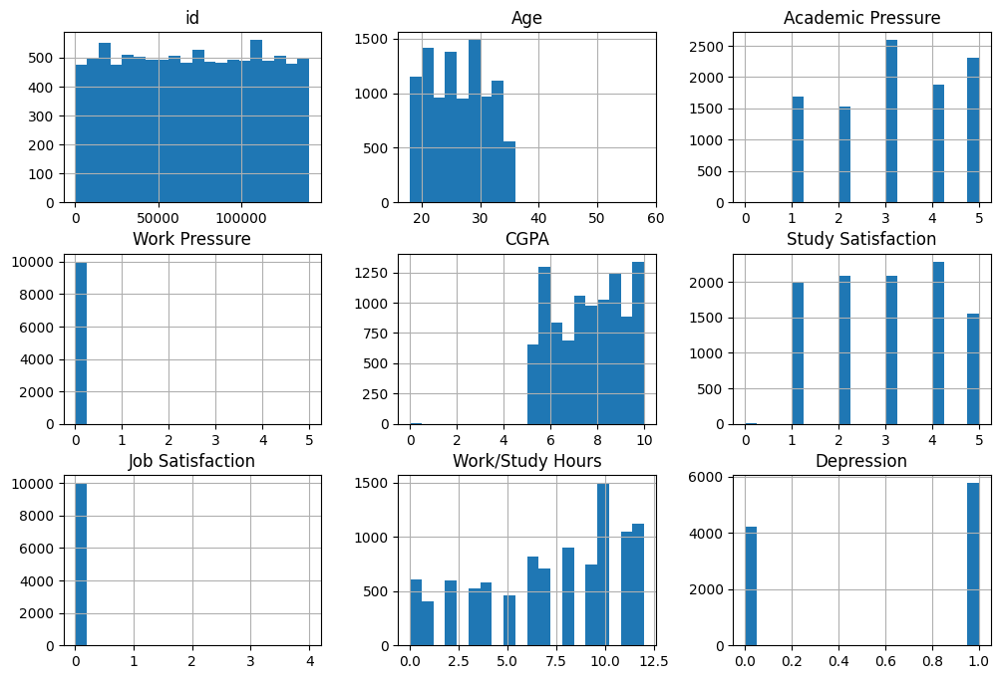

In [ ]:
# @title
from IPython.display import display, HTML
import matplotlib.pyplot as plt

numeric_cols = df.select_dtypes(include=['int64','float64'])

display(HTML("""
<h2 style='color: #7c3aed; text-align: center; font-weight: bold; margin-bottom:20px;'>
Histogram of Numeric Features
</h2>
"""))

numeric_cols.describe().transpose()

numeric_cols.hist(figsize=(12,8), bins=20)
plt.show()


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15), 0 2px 4px rgba(0,0,0,0.12), 0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 20px;
        padding-bottom: 10px;
        font-size: 28px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
    Histogram Interpretation - Key Findings
</h2>

<ul style="
        position: relative;
        z-index: 2;
        line-height: 1.8;
        color: #333;
        font-size: 16px;
        padding-left: 20px;
    ">
    <li><strong>ID:</strong> Uniform distribution, evenly distributed observations.</li>
    <li><strong>Age:</strong> Right-skewed, concentrated at 18-30 years (peak ~20-22), predominantly young students.</li>
    <li><strong>Academic Pressure:</strong> Multimodal with peaks at 1, 3, and 5. Highest at 3 (moderate pressure).</li>
    <li><strong>Work Pressure:</strong> Extreme left-skew, ~25,000+ students at 0 (unemployed/full-time students).</li>
    <li><strong>CGPA:</strong> Near-normal distribution centered at 6-7/10, showing varied academic performance.</li>
    <li><strong>Study Satisfaction:</strong> Relatively uniform across 0-5 scale, diverse satisfaction levels.</li>
    <li><strong>Job Satisfaction:</strong> Heavily concentrated at 0, consistent with no work pressure.</li>
    <li><strong>Work/Study Hours:</strong> Right-skewed, peak at 8-10 hours, most students study 6-12 hours daily.</li>
    <li><strong>Depression:</strong> Binary and <strong>imbalanced</strong> - approximately 11,000 non-depressed (0) vs 16,000 depressed (1), indicating <strong>~57% depression prevalence</strong>. This class imbalance will need addressing in modeling.</li>
</ul>

<h3 style="
        position: relative;
        z-index: 2;
        margin-top: 20px;
        margin-bottom: 10px;
        color: rgba(106,5,114,0.85);
        font-size: 20px;
    ">
    Critical Observations
</h3>

<ul style="
        position: relative;
        z-index: 2;
        line-height: 1.8;
        color: #333;
        font-size: 16px;
        padding-left: 20px;
    ">
    <li>High depression rate in student population</li>
    <li>Most students are full-time without employment</li>
    <li>Academic pressure varies meaningfully across population</li>
    <li>Class imbalance in target variable requires special handling</li>
</ul>

</div>
"""

display(HTML(html_content))

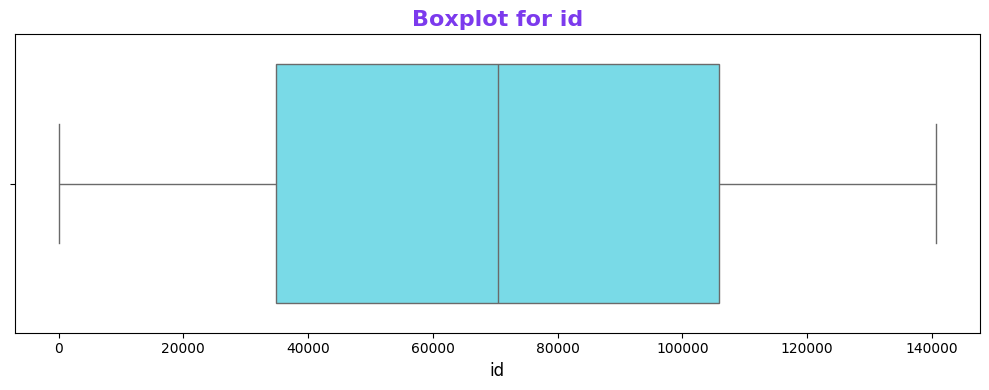

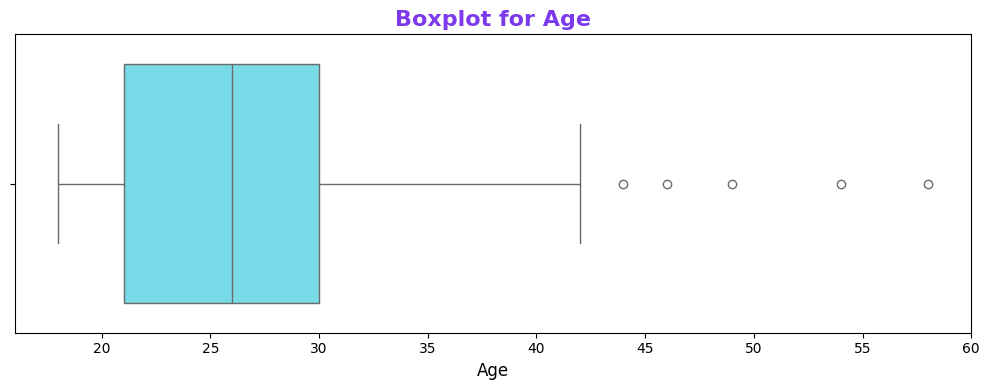

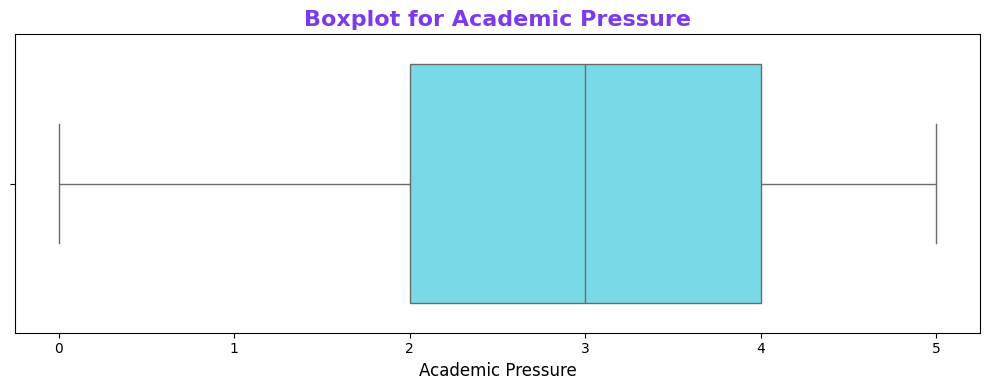

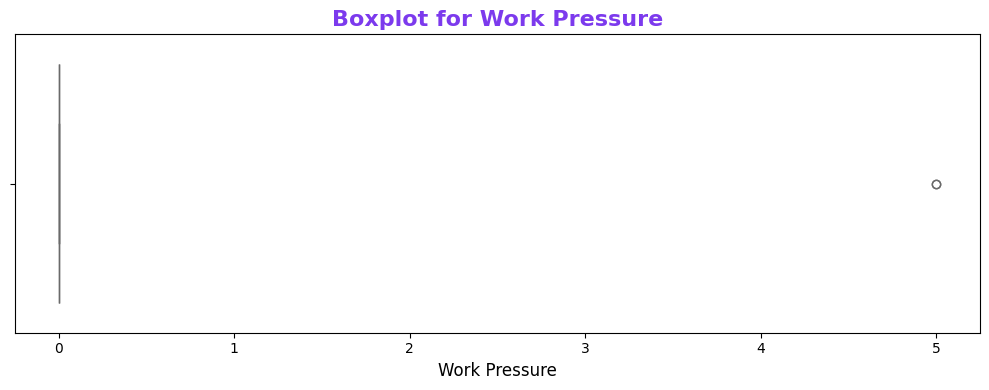

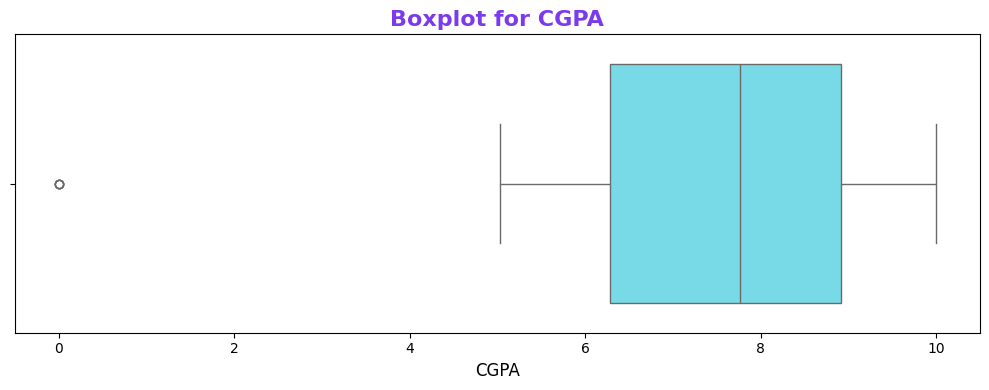

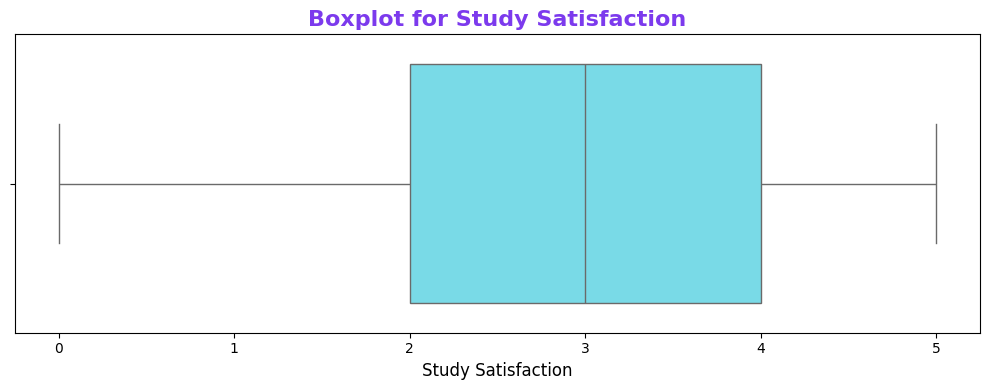

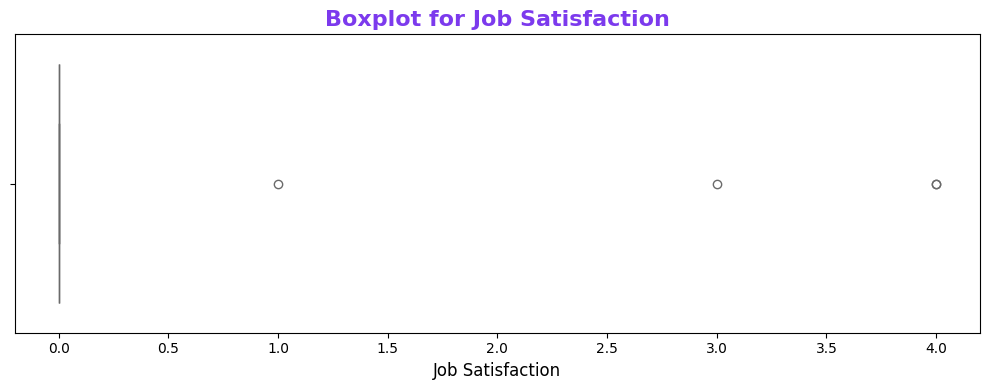

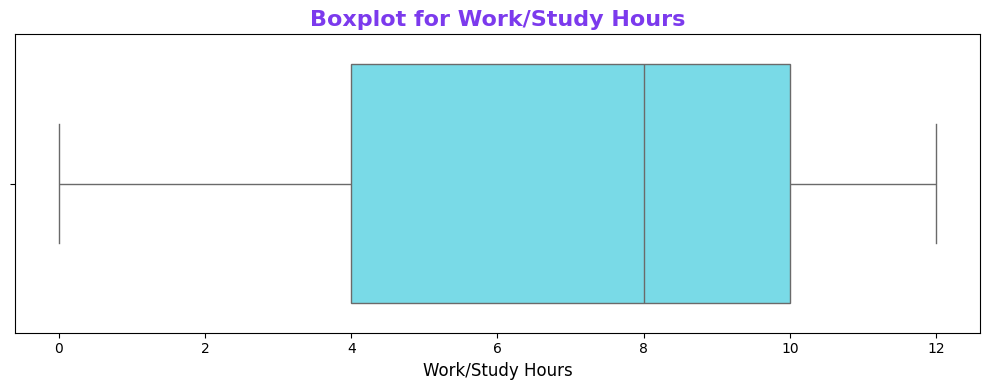

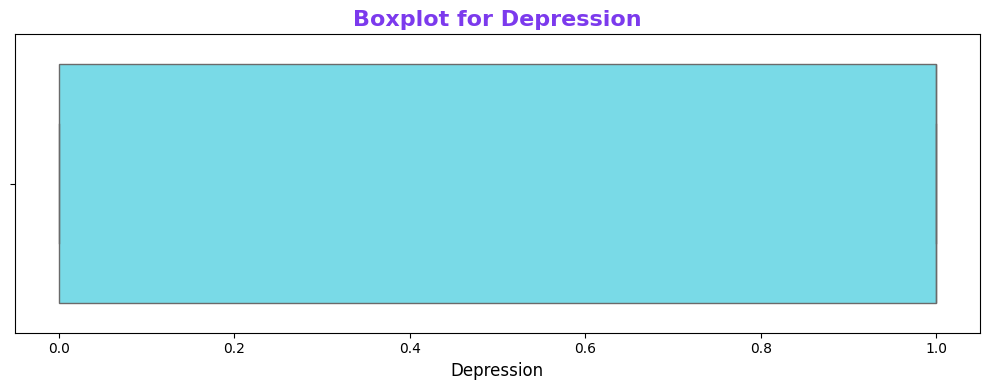

In [ ]:
# @title
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, HTML

display(HTML("""
<h2 style='color: #7c3aed; text-align: center; font-weight: bold; margin-bottom:20px;'>
Boxplots of Numeric Features
</h2>
"""))

for col in numeric_cols.columns:
    plt.figure(figsize=(10,4))
    sns.boxplot(x=df[col], color="#67e8f9")
    plt.title(f'Boxplot for {col}', fontsize=16, color='#7c3aed', weight='bold')
    plt.xlabel(col, fontsize=12)
    plt.tight_layout()
    plt.show()


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15), 0 2px 4px rgba(0,0,0,0.12), 0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 20px;
        padding-bottom: 10px;
        font-size: 28px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
    Boxplot Interpretation - Outlier Detection
</h2>

<ul style="
        position: relative;
        z-index: 2;
        line-height: 1.8;
        color: #333;
        font-size: 16px;
        padding-left: 20px;
    ">
    <li><strong>ID:</strong> Symmetric box spanning  with no outliers on both ends.</li>
    <li><strong>Age:</strong> Compact box with multiple outliers extending to 40-59 years. Most students are young adults (18-30), with older students as exceptions.</li>
    <li><strong>Academic Pressure:</strong> Box spans 2-4 with median at 3. No visible outliers, indicating most students experience moderate academic pressure within expected range.</li>
    <li><strong>Work Pressure:</strong> Extremely compressed box near 0 with only outliers at ~2 and ~5. Confirms nearly all students have zero work pressure, with rare exceptions working part-time.</li>
    <li><strong>CGPA:</strong> Box spans ~6.5-9 with median ~7.5, one extreme outlier near 0. Generally good academic performance with rare failure case.</li>
    <li><strong>Study Satisfaction:</strong> Wide box (Q1 ~2, Q3 ~4) spanning most of the 0-5 scale. No outliers, showing diverse satisfaction levels are normal.</li>
    <li><strong>Job Satisfaction:</strong> No box visible, only scattered outlier points at 1, 2, 3, and 4. Confirms overwhelming majority have 0 job satisfaction (unemployed), with few working students.</li>
    <li><strong>Work/Study Hours:</strong> Box spans ~4-10 hours with median ~7. Minimal outliers, indicating most students study within 4-10 hours daily range.</li>
    <li><strong>Depression:</strong> Binary variable (0/1) shown as wide horizontal box. No traditional outliers possible in binary data. Visual confirms the class distribution.</li>
</ul>

<h3 style="
        position: relative;
        z-index: 2;
        margin-top: 20px;
        margin-bottom: 10px;
        color: rgba(106,5,114,0.85);
        font-size: 20px;
    ">
    Key Findings
</h3>

<ul style="
        position: relative;
        z-index: 2;
        line-height: 1.8;
        color: #333;
        font-size: 16px;
        padding-left: 20px;
    ">
    <li><strong>Minimal outliers</strong> in most variables suggests clean, reliable data</li>
    <li>Age and Work/Job variables show expected outlier patterns (older/working students are rare)</li>
    <li>CGPA outlier indicates potential data quality issue or genuine academic failure case</li>
    <li>No extreme outliers in pressure/satisfaction variables - all values within plausible ranges</li>
</ul>

</div>
"""

display(HTML(html_content))

In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15), 0 2px 4px rgba(0,0,0,0.12), 0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 12px;
        padding-bottom: 10px;
        font-size: 28px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
    Percentage of Students Experiencing Depression
</h2>
</div>
"""

display(HTML(html_content))


In [ ]:
# @title
total_students = len(df)
depressed = (df['Depression'] == 1).sum()
happy = (df['Depression'] == 0).sum()
depressed_pct = (depressed / total_students) * 100
happy_pct = (happy / total_students) * 100

fig = go.Figure(data=[go.Pie(
    labels=['Depressed Students', 'Happy Students'],
    values=[depressed, happy],
    hole=0.5,
    marker=dict(
        colors=['#ff7b7b', '#5dd5d5'],
        line=dict(color='#4a5568', width=3)
    ),
    textposition='outside',
    textinfo='none',
    direction='clockwise',
    rotation=180,
    sort=False
)])

fig.add_annotation(
    text=f'Total Students : {total_students}',
    x=0.5, y=0.5,
    font=dict(size=16, color='black', family='Arial'),
    showarrow=False
)

fig.add_annotation(
    text=f'Depressed Students<br>{depressed_pct:.1f}%',
    x=0.18, y=0.15,
    font=dict(size=13, color='black', family='Arial'),
    showarrow=False,
    align='center'
)

fig.add_annotation(
    text=f'Happy Students<br>{happy_pct:.1f}%',
    x=0.85, y=0.82,
    font=dict(size=13, color='black', family='Arial'),
    showarrow=False,
    align='left'
)

fig.update_layout(
    title={
        'text': 'Why More Than 58% Students Feeling Depressed',
        'x': 0.5,
        'xanchor': 'center',
        'y': 0.98,
        'font': {'size': 20, 'color': 'black', 'family': 'Arial'}
    },
    showlegend=False,
    width=750,
    height=650,
    paper_bgcolor='#f5f5f5',
    plot_bgcolor='#f5f5f5',
    margin=dict(l=50, r=50, t=100, b=50)
)

fig.show()


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15), 0 2px 4px rgba(0,0,0,0.12), 0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 12px;
        padding-bottom: 10px;
        font-size: 28px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
   Out of 27,901 students, over 16,300 (58.5%) feel depressed, while about 11,600 (41.5%) are happy.
    </h2>
</div>
"""

display(HTML(html_content))

In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15), 0 2px 4px rgba(0,0,0,0.12), 0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 12px;
        padding-bottom: 10px;
        font-size: 28px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
    Which cities were the sources of the collected data?
</h2>
</div>
"""

display(HTML(html_content))


In [ ]:
# @title

city_coords = {
    "Visakhapatnam": (17.6868, 83.2185),
    "Bangalore": (12.9716, 77.5946),
    "Srinagar": (34.0837, 74.7973),
    "Varanasi": (25.3176, 82.9739),
    "Jaipur": (26.9124, 75.7873),
    "Pune": (18.5204, 73.8567),
    "Thane": (19.2183, 72.9781),
    "Chennai": (13.0827, 80.2707),
    "Nagpur": (21.1458, 79.0882),
    "Nashik": (19.9975, 73.7898),
    "Vadodara": (22.3072, 73.1812),
    "Kalyan": (19.2403, 73.1300),
    "Rajkot": (22.3039, 70.8022),
    "Ahmedabad": (23.0225, 72.5714),
    "Kolkata": (22.5726, 88.3639),
    "Mumbai": (19.0760, 72.8777),
    "Lucknow": (26.8467, 80.9462),
    "Indore": (22.7196, 75.8577),
    "Surat": (21.1702, 72.8311),
    "Ludhiana": (30.9010, 75.8573),
    "Bhopal": (23.2599, 77.4126),
    "Meerut": (28.9845, 77.7064),
    "Agra": (27.1767, 78.0081),
    "Ghaziabad": (28.6692, 77.4538),
    "Hyderabad": (17.3850, 78.4867),
    "Vasai-Virar": (19.3914, 72.8397),
    "Kanpur": (26.4499, 80.3319),
    "Patna": (25.5941, 85.1376),
    "Faridabad": (28.4089, 77.3178),
    "Delhi": (28.6139, 77.2090)
}


villes_reelles = list(city_coords.keys())
df_villes = df[df['City'].isin(villes_reelles)].copy()

df_villes['latitude'] = df_villes['City'].map(lambda x: city_coords[x][0])
df_villes['longitude'] = df_villes['City'].map(lambda x: city_coords[x][1])


city_counts = df_villes['City'].value_counts().reset_index()
city_counts.columns = ['City', 'Count']


city_counts['latitude'] = city_counts['City'].map(lambda x: city_coords[x][0])
city_counts['longitude'] = city_counts['City'].map(lambda x: city_coords[x][1])


q1 = city_counts['Count'].quantile(0.33)
q2 = city_counts['Count'].quantile(0.66)

def color_group(count):
    if count <= q1:
        return 'Faible'
    elif count <= q2:
        return 'Moyen'
    else:
        return 'Élevé'

city_counts['Group'] = city_counts['Count'].apply(color_group)


fig = px.scatter_mapbox(
    city_counts,
    lat="latitude",
    lon="longitude",
    hover_name="City",
    hover_data={"Count": True},
    size="Count",
    color="Group",
    color_discrete_map={'Faible': 'green', 'Moyen': 'orange', 'Élevé': 'red'},
    size_max=40,
    zoom=4,
    height=600
)

fig.update_layout(mapbox_style="open-street-map")
fig.show()


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15), 0 2px 4px rgba(0,0,0,0.12), 0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 18px;
        padding-bottom: 10px;
        font-size: 28px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
    Student Depression Across Indian Cities
</h2>

<ul style="
    font-size: 16px;
    line-height: 1.7;
    color: #2d3748;
    padding-left: 28px;
    margin: 0;
    z-index: 2;
    position: relative;
">
<li><strong>This map shows how student depression varies across major Indian cities:</strong></li>

<li><strong style="color: #e53e3e;">Red (High Depression):</strong> Ahmedabad, Surat, Kolkata, Agra, Kanpur, Prayagraj, Jaipur, Belagavi, Kurnool, Chennai</li>

<li><strong style="color: #d69e2e;">Yellow (Medium):</strong> Indore, Bhopal, Nashik, Jabalpur, Visakhapatnam</li>

<li><strong style="color: #38a169;">Green (Low):</strong> Lucknow, Patna, Bengaluru, Mangaluru, Kochi</li>

<li><strong>Key Hotspots:</strong> Gujarat, Uttar Pradesh, West Bengal, and South India show peak depression levels</li>

</ul>

</div>
"""

display(HTML(html_content))

In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15), 0 2px 4px rgba(0,0,0,0.12), 0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 16px;
        padding-bottom: 10px;
        font-size: 26px;
        color: rgba(106,5,114,0.85);  /* <-- ancienne couleur */
        position: relative;
        z-index: 2;
        text-align: center;  /* <-- titre centré */
    ">
    Data Segmentation for Meaningful Interpretation
</h2>

<div style="
        font-size: 15px;
        line-height: 1.7;
        color: #444;
        position: relative;
        z-index: 2;
    ">
    To enable more targeted insights, the dataset has been categorized into two primary groups:
    <br><br>
    <strong style="color: rgba(106,5,114,0.8);">1) Depressed Students —</strong> Individuals who reported symptoms or feelings related to depression during the survey.
    <br>
    <strong style="color: rgba(106,5,114,0.8);">2) Happy Students —</strong> Those who expressed satisfaction and overall positive mental health conditions.
    <br><br>
    This segmentation helps uncover how various academic, social, and personal factors influence students’ emotional wellbeing, allowing for a clearer comparison between both groups.
</div>

</div>
"""

display(HTML(html_content))


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15), 0 2px 4px rgba(0,0,0,0.12), 0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 14px;
        padding-bottom: 8px;
        font-size: 26px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
        Understanding the Factors Behind Student Depression
</h2>

<div style="
        font-size: 18px;
        line-height: 1.6;
        color: #333;
        position: relative;
        z-index: 2;
        text-align: center;
    ">
        This analysis compares <strong style="color: rgba(106,5,114,0.9);">depressed</strong> and <strong style="color: rgba(106,5,114,0.9);">mentally stable</strong> students
        by examining several lifestyle and emotional aspects such as <em>sleep duration</em>, <em>study hours</em>, <em>dietary habits</em>, <em>academic pressure</em>,
        and even <em>suicidal thoughts</em>.
        <br><br>
        The objective is to uncover the most influential factors affecting students’ mental health and well-being.
</div>
</div>
"""

display(HTML(html_content))


In [ ]:
# @title

suicidal_col = 'Have you ever had suicidal thoughts ?'

happy_students = df[df['Depression'] == 0]
happy_no_suicidal = (happy_students[suicidal_col] == 'No').sum()
happy_yes_suicidal = (happy_students[suicidal_col] == 'Yes').sum()

depressed_students = df[df['Depression'] == 1]
depressed_no_suicidal = (depressed_students[suicidal_col] == 'No').sum()
depressed_yes_suicidal = (depressed_students[suicidal_col] == 'Yes').sum()

fig = make_subplots(
    rows=1, cols=2,
    subplot_titles=('happy students', 'depressed students'),
    horizontal_spacing=0.15
)

fig.add_trace(
    go.Bar(
        x=['No', 'Yes'],
        y=[happy_no_suicidal, happy_yes_suicidal],
        marker=dict(
            color='#5dd5d5',
            line=dict(color='#4a5568', width=1.5)
        ),
        text=[happy_no_suicidal, happy_yes_suicidal],
        textposition='inside',
        textfont=dict(size=14, color='black'),
        name='happy students',
        showlegend=True
    ),
    row=1, col=1
)

fig.add_trace(
    go.Bar(
        x=['Yes', 'No'],
        y=[depressed_yes_suicidal, depressed_no_suicidal],
        marker=dict(
            color='#ff7b7b',
            line=dict(color='#4a5568', width=1.5)
        ),
        text=[depressed_yes_suicidal, depressed_no_suicidal],
        textposition='inside',
        textfont=dict(size=14, color='black'),
        name='depressed students',
        showlegend=True
    ),
    row=1, col=2
)

fig.update_xaxes(title_text="", tickfont=dict(size=12), row=1, col=1)
fig.update_xaxes(title_text="", tickfont=dict(size=12), row=1, col=2)

fig.update_yaxes(title_text="", showgrid=True, gridcolor='#e5e5e5', row=1, col=1)
fig.update_yaxes(title_text="", showgrid=True, gridcolor='#e5e5e5', row=1, col=2)

fig.update_layout(
    title={
        'text': 'Have you ever had suicidal thoughts ?',
        'x': 0.5,
        'xanchor': 'center',
        'font': {'size': 22, 'color': 'black', 'family': 'Arial'}
    },
    showlegend=True,
    legend=dict(
        orientation="h",
        yanchor="bottom",
        y=-0.15,
        xanchor="center",
        x=0.5,
        font=dict(size=12)
    ),
    width=1000,
    height=550,
    paper_bgcolor='#f5f5f5',
    plot_bgcolor='#f5f5f5',
    margin=dict(l=60, r=60, t=100, b=80)
)

fig.show()



In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #ccc;
    border-radius: 12px;
    box-shadow: 0 4px 10px rgba(0,0,0,0.1);
    padding: 20px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    color: #333;
">

<h2 style="
    text-align: center;
    color: #7c3aed;
    margin-bottom: 15px;
">
Key Insight: Suicidal Thoughts as a Predictive Feature
</h2>

<p style="
    font-size: 16px;
    line-height: 1.6;
    text-align: justify;
">
This chart reveals that having <strong>suicidal thoughts</strong> is a critical predictive feature for <strong>depression status</strong>.
The data shows a stark difference: an overwhelming majority of <strong>depressed students</strong> (<strong>13,957</strong>) have experienced suicidal thoughts,
whereas this is true for only a minority of <strong>happy students</strong> (<strong>3,699</strong>), confirming a strong association.
</p>

</div>
"""

display(HTML(html_content))


In [ ]:
# @title

# Compter pour happy students (Depression = 0)
happy_students = df[df['Depression'] == 0]
happy_dietary = happy_students['Dietary Habits'].value_counts().sort_index()

# Compter pour depressed students (Depression = 1)
depressed_students = df[df['Depression'] == 1]
depressed_dietary = depressed_students['Dietary Habits'].value_counts().sort_index()

# S'assurer que toutes les catégories sont présentes
categories = ['Moderate', 'Healthy', 'Unhealthy', 'Others']
happy_values = [happy_dietary.get(cat, 0) for cat in categories]
depressed_values = [depressed_dietary.get(cat, 0) for cat in categories]

# Créer les subplots
fig = make_subplots(
    rows=1, cols=2,
    subplot_titles=('happy students', 'depressed students'),
    horizontal_spacing=0.12
)

# Graphique 1 : Happy Students (cyan)
fig.add_trace(
    go.Bar(
        x=categories,
        y=happy_values,
        marker=dict(
            color='#5dd5d5',
            line=dict(color='#4a5568', width=1.5)
        ),
        text=happy_values,
        textposition='inside',
        textfont=dict(size=13, color='black', weight='bold'),
        name='happy students',
        showlegend=True
    ),
    row=1, col=1
)

# Graphique 2 : Depressed Students (rouge)
fig.add_trace(
    go.Bar(
        x=categories,
        y=depressed_values,
        marker=dict(
            color='#ff7b7b',
            line=dict(color='#4a5568', width=1.5)
        ),
        text=depressed_values,
        textposition='inside',
        textfont=dict(size=13, color='black', weight='bold'),
        name='depressed students',
        showlegend=True
    ),
    row=1, col=2
)

# Mise en forme des axes
fig.update_xaxes(
    tickangle=-45,
    tickfont=dict(size=11),
    showgrid=False,
    row=1, col=1
)
fig.update_xaxes(
    tickangle=-45,
    tickfont=dict(size=11),
    showgrid=False,
    row=1, col=2
)

fig.update_yaxes(
    showgrid=True,
    gridcolor='#e5e5e5',
    zeroline=True,
    row=1, col=1
)
fig.update_yaxes(
    showgrid=True,
    gridcolor='#e5e5e5',
    zeroline=True,
    row=1, col=2
)

# Layout général
fig.update_layout(
    title={
        'text': 'Dietary Habits',
        'x': 0.5,
        'xanchor': 'center',
        'font': {'size': 24, 'color': 'black', 'family': 'Arial'}
    },
    showlegend=True,
    legend=dict(
        orientation="h",
        yanchor="bottom",
        y=-0.25,
        xanchor="center",
        x=0.5,
        font=dict(size=12)
    ),
    width=1000,
    height=550,
    paper_bgcolor='#f5f5f5',
    plot_bgcolor='#f5f5f5',
    margin=dict(l=60, r=60, t=100, b=100)
)

fig.show()



In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #ccc;
    border-radius: 12px;
    box-shadow: 0 4px 10px rgba(0,0,0,0.1);
    padding: 20px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    color: #333;
">

<h2 style="
    text-align: center;
    color: #7c3aed;
    margin-bottom: 15px;
">
Dietary Habits and Mental Health Correlation
</h2>

<p style="
    font-size: 16px;
    line-height: 1.6;
    text-align: justify;
">
These charts show a clear correlation between <strong>dietary habits</strong> and <strong>mental health</strong>,
with <strong>'Unhealthy'</strong> habits being the most common category (<strong>7,297</strong>) for <strong>depressed students</strong>.
This highlights the significant role that lifestyle choices, such as diet, can play in affecting student well-being.
</p>

</div>
"""

display(HTML(html_content))


In [ ]:
# @title

df['Sleep Duration'] = df['Sleep Duration'].str.strip().str.replace("'", "")
happy_students = df[df['Depression'] == 0]
happy_sleep = happy_students['Sleep Duration'].value_counts().sort_index()

depressed_students = df[df['Depression'] == 1]
depressed_sleep = depressed_students['Sleep Duration'].value_counts().sort_index()

categories = ['7-8 hours', 'More than 8 hours', 'Less than 5 hours', '5-6 hours', 'Others']

happy_values = [happy_sleep.get(cat, 0) for cat in categories]
depressed_values = [depressed_sleep.get(cat, 0) for cat in categories]

fig = make_subplots(
    rows=1, cols=2,
    subplot_titles=('happy students', 'depressed students'),
    horizontal_spacing=0.12
)

fig.add_trace(
    go.Bar(
        x=categories,
        y=happy_values,
        marker=dict(
            color='#5dd5d5',
            line=dict(color='#4a5568', width=1.5)
        ),
        text=happy_values,
        textposition='inside',
        textfont=dict(size=13, color='black', weight='bold'),
        name='happy students',
        showlegend=True
    ),
    row=1, col=1
)

fig.add_trace(
    go.Bar(
        x=categories,
        y=depressed_values,
        marker=dict(
            color='#ff7b7b',
            line=dict(color='#4a5568', width=1.5)
        ),
        text=depressed_values,
        textposition='inside',
        textfont=dict(size=13, color='black', weight='bold'),
        name='depressed students',
        showlegend=True
    ),
    row=1, col=2
)

fig.update_xaxes(
    tickangle=-45,
    tickfont=dict(size=11),
    showgrid=False,
    row=1, col=1
)
fig.update_xaxes(
    tickangle=-45,
    tickfont=dict(size=11),
    showgrid=False,
    row=1, col=2
)

fig.update_yaxes(
    showgrid=True,
    gridcolor='#e5e5e5',
    zeroline=True,
    row=1, col=1
)
fig.update_yaxes(
    showgrid=True,
    gridcolor='#e5e5e5',
    zeroline=True,
    row=1, col=2
)

fig.update_layout(
    title={
        'text': 'Sleep Duration',
        'x': 0.5,
        'xanchor': 'center',
        'font': {'size': 24, 'color': 'black', 'family': 'Arial'}
    },
    showlegend=True,
    legend=dict(
        orientation="h",
        yanchor="bottom",
        y=-0.28,
        xanchor="center",
        x=0.5,
        font=dict(size=12)
    ),
    width=1000,
    height=550,
    paper_bgcolor='#f5f5f5',
    plot_bgcolor='#f5f5f5',
    margin=dict(l=60, r=60, t=100, b=110)
)

fig.show()



In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #ccc;
    border-radius: 12px;
    box-shadow: 0 4px 10px rgba(0,0,0,0.1);
    padding: 20px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    color: #333;
">

<h2 style="
    text-align: center;
    color: #7c3aed;
    margin-bottom: 15px;
">
Sleep Duration and Depression Correlation
</h2>

<p style="
    font-size: 16px;
    line-height: 1.6;
    text-align: justify;
">
These charts reveal a strong correlation between <strong>sleep duration</strong> and <strong>depression</strong>,
with insufficient sleep being a key indicator. The <strong>"Less than 5 hours"</strong> category is the single largest group for
<strong>depressed students</strong> (<strong>5,361</strong>), while <strong>happy students</strong> are more prominent in the
<strong>"7-8 hours"</strong> (<strong>2,975</strong>) and <strong>"More than 8 hours"</strong> (<strong>2,966</strong>) brackets.
</p>

</div>
"""

display(HTML(html_content))


In [ ]:
# @title

# Compter pour happy students (Depression = 0)
happy_students = df[df['Depression'] == 0]
happy_pressure = happy_students['Academic Pressure'].value_counts().sort_index()

# Compter pour depressed students (Depression = 1)
depressed_students = df[df['Depression'] == 1]
depressed_pressure = depressed_students['Academic Pressure'].value_counts().sort_index()

# Définir les catégories (0 à 5)
categories = [0, 1, 2, 3, 4, 5]
categories_str = ['0', '1', '2', '3', '4', '5']

# Récupérer les valeurs pour chaque catégorie
happy_values = [happy_pressure.get(cat, 0) for cat in categories]
depressed_values = [depressed_pressure.get(cat, 0) for cat in categories]

# Créer les subplots
fig = make_subplots(
    rows=1, cols=2,
    subplot_titles=('happy students', 'depressed students'),
    horizontal_spacing=0.12
)

# Graphique 1 : Happy Students (cyan avec dégradé)
colors_happy = ['#d3d3d3', '#5dd5d5', '#5dd5d5', '#5dd5d5', '#5dd5d5', '#5dd5d5']
fig.add_trace(
    go.Bar(
        x=categories_str,
        y=happy_values,
        marker=dict(
            color=colors_happy,
            line=dict(color='#4a5568', width=1.5)
        ),
        text=happy_values,
        textposition='outside',
        textfont=dict(size=12, color='black'),
        name='happy students',
        showlegend=True
    ),
    row=1, col=1
)

# Graphique 2 : Depressed Students (rouge avec dégradé)
colors_depressed = ['#d3d3d3', '#ff7b7b', '#ff7b7b', '#ff7b7b', '#ff7b7b', '#ff7b7b']
fig.add_trace(
    go.Bar(
        x=categories_str,
        y=depressed_values,
        marker=dict(
            color=colors_depressed,
            line=dict(color='#4a5568', width=1.5)
        ),
        text=depressed_values,
        textposition='outside',
        textfont=dict(size=12, color='black'),
        name='depressed students',
        showlegend=True
    ),
    row=1, col=2
)

# Mise en forme des axes
fig.update_xaxes(
    tickfont=dict(size=12),
    showgrid=False,
    row=1, col=1
)
fig.update_xaxes(
    tickfont=dict(size=12),
    showgrid=False,
    row=1, col=2
)

fig.update_yaxes(
    showgrid=True,
    gridcolor='#e5e5e5',
    zeroline=True,
    row=1, col=1
)
fig.update_yaxes(
    showgrid=True,
    gridcolor='#e5e5e5',
    zeroline=True,
    row=1, col=2
)

# Layout général
fig.update_layout(
    title={
        'text': 'Academic Pressure',
        'x': 0.5,
        'xanchor': 'center',
        'font': {'size': 24, 'color': 'black', 'family': 'Arial'}
    },
    showlegend=True,
    legend=dict(
        orientation="h",
        yanchor="bottom",
        y=-0.18,
        xanchor="center",
        x=0.5,
        font=dict(size=12)
    ),
    width=1000,
    height=550,
    paper_bgcolor='#f5f5f5',
    plot_bgcolor='#f5f5f5',
    margin=dict(l=60, r=60, t=100, b=80)
)

fig.show()



In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #ccc;
    border-radius: 12px;
    box-shadow: 0 4px 10px rgba(0,0,0,0.1);
    padding: 20px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    color: #333;
">

<h2 style="
    text-align: center;
    color: #7c3aed;
    margin-bottom: 15px;
">
Academic Pressure and Student Depression
</h2>

<p style="
    font-size: 16px;
    line-height: 1.6;
    text-align: justify;
">
Academic pressure is clearly a major factor strongly correlated with student depression.
The charts show that <strong>'depressed students'</strong> are overwhelmingly concentrated in the high-pressure categories
(levels <strong>3, 4, and 5</strong>), whereas <strong>'happy students'</strong> are most numerous at the low-pressure
level <strong>'1'</strong> and drop off significantly as pressure increases.
</p>

</div>
"""

display(HTML(html_content))


In [ ]:
# @title

happy_students = df[df['Depression'] == 0]
happy_stress = happy_students['Financial Stress'].value_counts().sort_index()

depressed_students = df[df['Depression'] == 1]
depressed_stress = depressed_students['Financial Stress'].value_counts().sort_index()

categories = [1, 2, 3, 4, 5]
categories_str = ['1.0', '2.0', '3.0', '4.0', '5.0']

happy_values = [happy_stress.get(cat, 0) for cat in categories]
depressed_values = [depressed_stress.get(cat, 0) for cat in categories]

fig = make_subplots(
    rows=1, cols=2,
    subplot_titles=('happy students', 'depressed students'),
    horizontal_spacing=0.12
)

fig.add_trace(
    go.Bar(
        x=categories_str,
        y=happy_values,
        marker=dict(
            color='#5dd5d5',
            line=dict(color='#4a5568', width=1.5)
        ),
        text=happy_values,
        textposition='outside',
        textfont=dict(size=12, color='black'),
        name='happy students',
        showlegend=True
    ),
    row=1, col=1
)

fig.add_trace(
    go.Bar(
        x=categories_str,
        y=depressed_values,
        marker=dict(
            color='#ff7b7b',
            line=dict(color='#4a5568', width=1.5)
        ),
        text=depressed_values,
        textposition='outside',
        textfont=dict(size=12, color='black'),
        name='depressed students',
        showlegend=True
    ),
    row=1, col=2
)

fig.update_xaxes(
    tickangle=-45,
    tickfont=dict(size=12),
    showgrid=False,
    row=1, col=1
)
fig.update_xaxes(
    tickangle=-45,
    tickfont=dict(size=12),
    showgrid=False,
    row=1, col=2
)

fig.update_yaxes(
    showgrid=True,
    gridcolor='#e5e5e5',
    zeroline=True,
    row=1, col=1
)
fig.update_yaxes(
    showgrid=True,
    gridcolor='#e5e5e5',
    zeroline=True,
    row=1, col=2
)

fig.update_layout(
    title={
        'text': 'Financial Stress',
        'x': 0.5,
        'xanchor': 'center',
        'font': {'size': 24, 'color': 'black', 'family': 'Arial'}
    },
    showlegend=True,
    legend=dict(
        orientation="h",
        yanchor="bottom",
        y=-0.20,
        xanchor="center",
        x=0.5,
        font=dict(size=12)
    ),
    width=1000,
    height=550,
    paper_bgcolor='#f5f5f5',
    plot_bgcolor='#f5f5f5',
    margin=dict(l=60, r=60, t=100, b=90)
)

fig.show()



In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #ccc;
    border-radius: 12px;
    box-shadow: 0 4px 10px rgba(0,0,0,0.1);
    padding: 20px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    color: #333;
">

<h2 style="
    text-align: center;
    color: #7c3aed;
    margin-bottom: 15px;
">
Financial Stress and Student Mental Health
</h2>

<p style="
    font-size: 16px;
    line-height: 1.6;
    text-align: justify;
">
Financial stress is a very strong predictor of mental health, displaying two clear and opposing trends.
<strong>'Happy students'</strong> are most numerous at the lowest stress level (<strong>1.0</strong>),
while <strong>'depressed students'</strong> are overwhelmingly concentrated at the higher levels,
with the count peaking at <strong>5,458</strong> for level <strong>4.0</strong>.
</p>

</div>
"""

display(HTML(html_content))


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15), 0 2px 4px rgba(0,0,0,0.12), 0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 16px;
        padding-bottom: 10px;
        font-size: 26px;
        color: #333;
        position: relative;
        z-index: 2;
    ">
    Exploring Patterns Across Variables
</h2>

<div style="
        height: 3px;
        width: 70px;
        background: linear-gradient(90deg, #6A0572, #4ECDC4, #FFD166);
        margin-bottom: 16px;
        border-radius: 2px;
    "></div>

<div style="
        font-size: 15px;
        line-height: 1.7;
        color: #444;
        position: relative;
        z-index: 2;
    ">
        This section examines how different factors relate to student mental health and academic outcomes through visualizations.
        <br><br>
        Key focus areas include:
        <br><br>
        <strong style="color: rgba(106,5,114,0.8);">1) Students vs Non-Students —</strong> Comparing academic pressure, study satisfaction, financial stress, family history, lifestyle habits, and depression indicators.
        <br>
        <strong style="color: rgba(106,5,114,0.8);">2) Demographics and Behavioral Factors —</strong> Understanding distributions of age, CGPA, sleep, diet, and suicidal thoughts.
        <br><br>
        These insights reveal patterns, correlations, and potential risk factors, guiding further analysis and interpretation.
</div>

<div style="
        background: linear-gradient(to right, rgba(106,5,114,0.05), rgba(78,205,196,0.07));
        border-left: 4px solid;
        border-image: linear-gradient(to bottom, #6A0572, #4ECDC4) 1;
        padding: 12px 18px;
        margin-top: 16px;
        border-radius: 0 6px 6px 0;
        position: relative;
        z-index: 2;
    ">
        <strong style="
            color: #6A0572;
            font-size: 17px;
            display: block;
            margin-bottom: 5px;
        ">Purpose:</strong>
        <span style="font-size: 14.5px; line-height: 1.6; color: #444;">
            By analyzing these variables collectively, we can identify meaningful trends and relationships, helping to prioritize key features for predictive modeling and interpretative insights.
        </span>
</div>
</div>
"""

display(HTML(html_content))


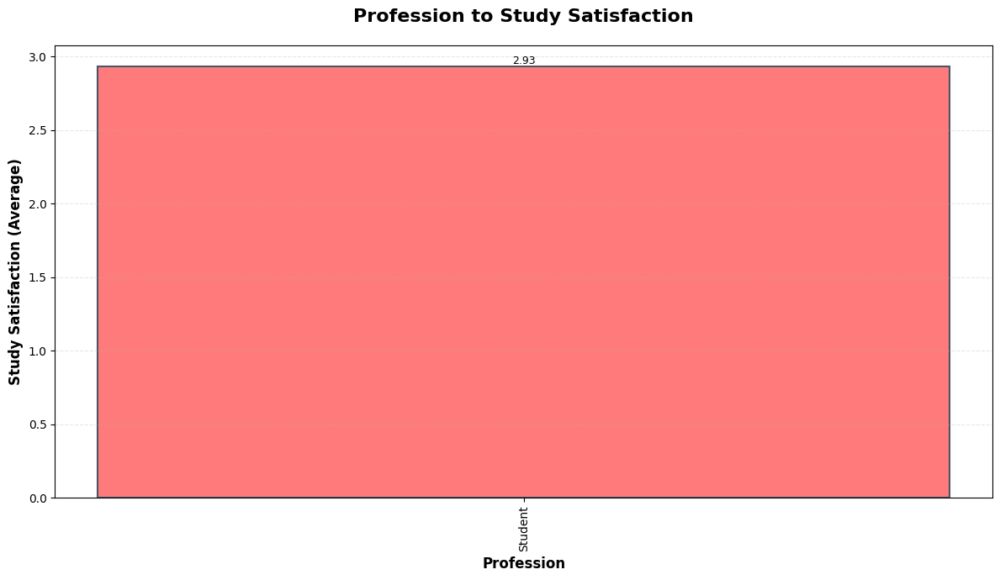

In [ ]:
# @title
#

plt.figure(figsize=(12, 7))
profession_study = df.groupby('Profession')['Study Satisfaction'].mean().sort_values(ascending=False)

bars = plt.bar(profession_study.index, profession_study.values,
               color='#ff7b7b', edgecolor='#4a5568', linewidth=1.5)

for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height,
             f'{height:.2f}',
             ha='center', va='bottom', fontsize=9)

plt.ylabel("Study Satisfaction (Average)", fontsize=12, fontweight='bold')
plt.xlabel("Profession", fontsize=12, fontweight='bold')
plt.title("Profession to Study Satisfaction", fontsize=16, fontweight='bold', pad=20)
plt.xticks(rotation=90)
plt.grid(axis='y', alpha=0.3, linestyle='--')
plt.tight_layout()
plt.show()

In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15), 0 2px 4px rgba(0,0,0,0.12), 0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 18px;
        padding-bottom: 10px;
        font-size: 28px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
    Profession to Study Satisfaction (Avg. Score / 5)
</h2>

<ul style="
    font-size: 16px;
    line-height: 1.7;
    color: #2d3748;
    padding-left: 28px;
    margin: 0;
    z-index: 2;
    position: relative;
">

<li><strong style="color: #38a169;">Highest Satisfaction (4.0–5.0):</strong></li>
<ul style="margin: 8px 0 8px 20px; padding-left: 20px;">
  <li><strong>Entrepreneur:</strong> 5.00</li>
  <li><strong>Educational Consultant / Digital Marketer:</strong> 4.00</li>
</ul>

<li><strong style="color: #3182ce;">High (3.5–3.6):</strong></li>
<ul style="margin: 8px 0 8px 20px; padding-left: 20px;">
  <li><strong>Architect:</strong> 3.62</li>
  <li><strong>Chef:</strong> 3.50</li>
</ul>

<li><strong style="color: #d69e2e;">Moderate (3.0–3.2):</strong></li>
<ul style="margin: 8px 0 8px 20px; padding-left: 20px;">
  <li><strong>Teacher:</strong> 3.17</li>
  <li><strong>Content Writer / Doctor:</strong> 3.00</li>
</ul>

<li><strong style="color: #e53e3e;">Lowest Satisfaction (1.0–2.5):</strong></li>
<ul style="margin: 8px 0 8px 20px; padding-left: 20px;">
  <li><strong>Lawyer / Civil Engineer:</strong> 1.00</li>
  <li><strong>UX/UI Designer / Manager:</strong> 2.00</li>
  <li><strong>Pharmacist:</strong> 2.50</li>
</ul>

<li><strong>Key Insight:</strong> <strong>Entrepreneurs</strong> are most satisfied with their studies (<strong>5/5</strong>), while <strong>Lawyers & Civil Engineers</strong> report the lowest (<strong>1/5</strong>).</li>

</ul>

</div>
"""

display(HTML(html_content))

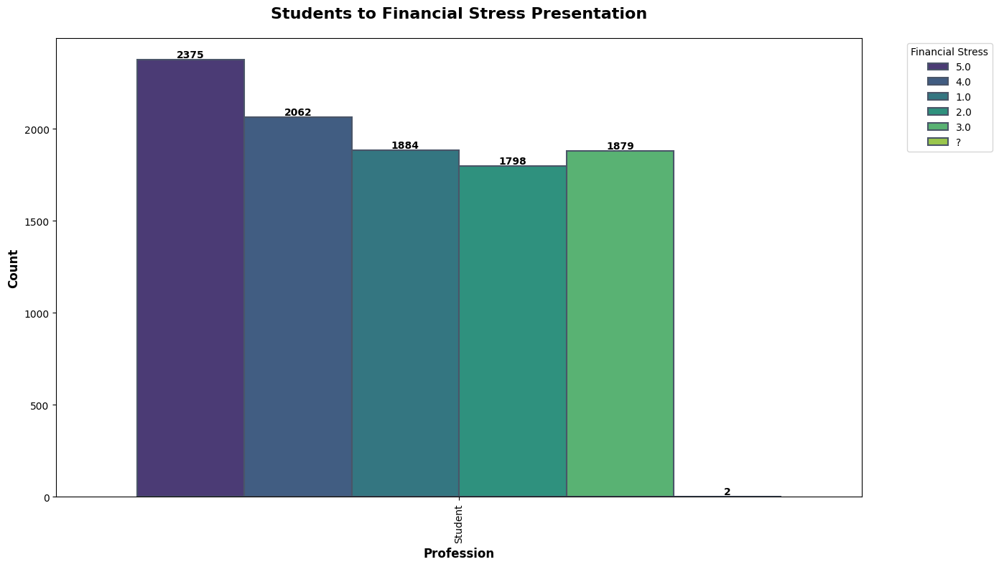

In [ ]:
# @title

students = df[df['Profession'] == "Student"]

plt.figure(figsize=(14, 8))
ax = sns.countplot(data=students, x='Profession', hue='Financial Stress',
                   palette='viridis', edgecolor='#4a5568', linewidth=1.5)

plt.title('Students to Financial Stress Presentation', fontsize=16, fontweight='bold', pad=20)
plt.ylabel('Count', fontsize=12, fontweight='bold')
plt.xlabel('Profession', fontsize=12, fontweight='bold')
plt.xticks(rotation=90)

for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(f'{int(height)}',
                    (p.get_x() + p.get_width() / 2., height),
                    ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.legend(title='Financial Stress', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15), 0 2px 4px rgba(0,0,0,0.12), 0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 18px;
        padding-bottom: 10px;
        font-size: 28px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
    Financial Stress by Profession (Student Responses)
</h2>

<ul style="
    font-size: 16px;
    line-height: 1.7;
    color: #2d3748;
    padding-left: 28px;
    margin: 0;
    z-index: 2;
    position: relative;
">

<li><strong style="color: #2d3748;">Financial Stress Scale:</strong> 1.0 (Lowest) → 5.0 (Highest)</li>

<li><strong style="color: #1a202c;">1.0 – Lowest Stress:</strong> <strong>5,116 students</strong></li>

<li><strong style="color: #2c5282;">2.0:</strong> <strong>5,058 students</strong></li>

<li><strong style="color: #22543d;">3.0:</strong> <strong>6,704 students</strong> (Highest count)</li>

<li><strong style="color: #276749;">4.0:</strong> <strong>5,219 students</strong></li>

<li><strong style="color: #166534;">5.0 – Highest Stress:</strong> <strong>5,770 students</strong></li>

<li><strong style="color: #e53e3e;">? (other):</strong> 3 students</li>

<li><strong>Key Insight:</strong>
  <ul style="margin: 8px 0 8px 20px; padding-left: 20px;">
    <li>Most students report <strong>moderate to high stress (3.0–5.0)</strong></li>
    <li><strong>6,704</strong> at level 3.0 → peak in mid-range stress</li>
    <li><strong>5,770</strong> at 5.0 → significant group in extreme financial stress</li>
  </ul>
</li>

</ul>

</div>
"""

display(HTML(html_content))

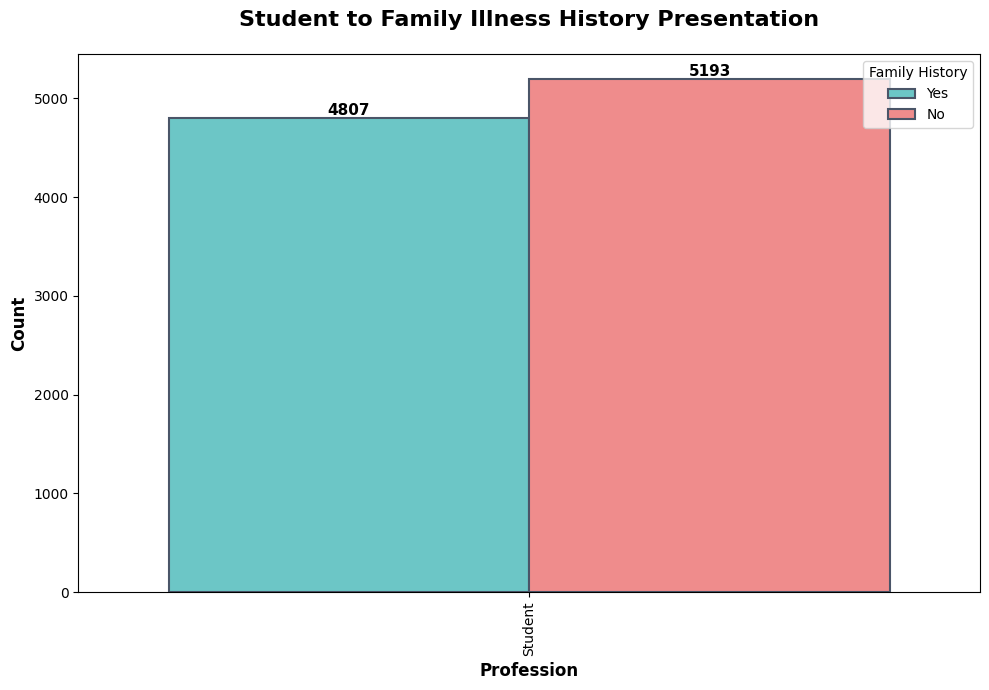

In [ ]:
# @title
plt.figure(figsize=(10, 7))
ax = sns.countplot(data=students, x='Profession', hue='Family History of Mental Illness',
                   palette=['#5dd5d5', '#ff7b7b'], edgecolor='#4a5568', linewidth=1.5)

plt.title('Student to Family Illness History Presentation',
          fontsize=16, fontweight='bold', pad=20)
plt.ylabel('Count', fontsize=12, fontweight='bold')
plt.xlabel('Profession', fontsize=12, fontweight='bold')
plt.xticks(rotation=90)

for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(f'{int(height)}',
                    (p.get_x() + p.get_width() / 2., height),
                    ha='center', va='bottom', fontsize=11, fontweight='bold')

plt.legend(title='Family History', loc='upper right')
plt.tight_layout()
plt.show()


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15), 0 2px 4px rgba(0,0,0,0.12), 0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 18px;
        padding-bottom: 10px;
        font-size: 28px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
    Family History of Illness Among Students
</h2>

<ul style="
    font-size: 16px;
    line-height: 1.7;
    color: #2d3748;
    padding-left: 28px;
    margin: 0;
    z-index: 2;
    position: relative;
">

<li><strong style="color: #38b2ac;">No Family History:</strong> <strong>14,384 students</strong></li>

<li><strong style="color: #e53e3e;">Yes – Family History of Illness:</strong> <strong>13,486 students</strong></li>

<li><strong>Key Insight:</strong>
  <ul style="margin: 8px 0 8px 20px; padding-left: 20px;">
    <li><strong>Nearly half (48.4%)</strong> of students report a family history of illness</li>
    <li><strong>51.6%</strong> have no such history</li>
    <li>The two groups are <strong>almost evenly split</strong></li>
  </ul>
</li>

</ul>

</div>
"""

display(HTML(html_content))

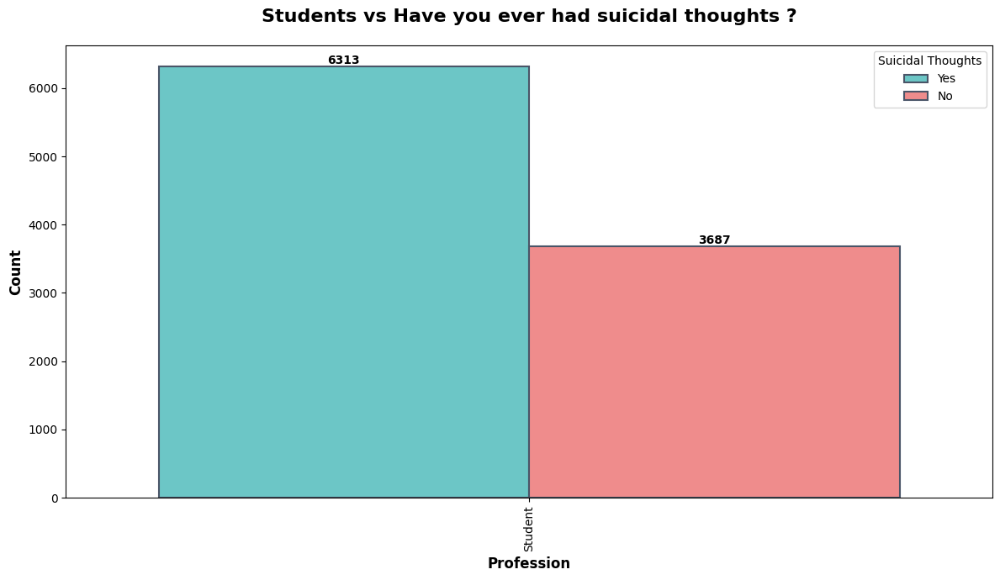

In [ ]:
# @title
plt.figure(figsize=(12, 7))
ax = sns.countplot(data=students, x='Profession',
                   hue='Have you ever had suicidal thoughts ?',
                   palette=['#5dd5d5', '#ff7b7b'],
                   edgecolor='#4a5568', linewidth=1.5)

plt.title('Students vs Have you ever had suicidal thoughts ?',
          fontsize=16, fontweight='bold', pad=20)
plt.ylabel('Count', fontsize=12, fontweight='bold')
plt.xlabel('Profession', fontsize=12, fontweight='bold')
plt.xticks(rotation=90)

for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(f'{int(height)}',
                    (p.get_x() + p.get_width() / 2., height),
                    ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.legend(title='Suicidal Thoughts', loc='upper right')
plt.tight_layout()
plt.show()


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15), 0 2px 4px rgba(0,0,0,0.12), 0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 18px;
        padding-bottom: 10px;
        font-size: 28px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
    Suicidal Thoughts Among All Students
</h2>

<ul style="
    font-size: 16px;
    line-height: 1.7;
    color: #2d3748;
    padding-left: 28px;
    margin: 0;
    z-index: 2;
    position: relative;
">

<li><strong style="color: #38b2ac;">Yes – Have Had Suicidal Thoughts:</strong> <strong>17,631 students</strong></li>

<li><strong style="color: #e53e3e;">No – Never Had Suicidal Thoughts:</strong> <strong>10,239 students</strong></li>

<li><strong>Total Students:</strong> <strong>27,870</strong></li>

<li><strong>Key Insight:</strong>
  <ul style="margin: 8px 0 8px 20px; padding-left: 20px;">
    <li><strong>63.3% of students</strong> report having had <strong>suicidal thoughts</strong> at some point</li>
    <li><strong>36.7%</strong> have never experienced them</li>
    <li><strong>More than 17,600 students</strong> — a <strong>majority</strong> — are affected</li>
  </ul>
</li>

</ul>

</div>
"""

display(HTML(html_content))

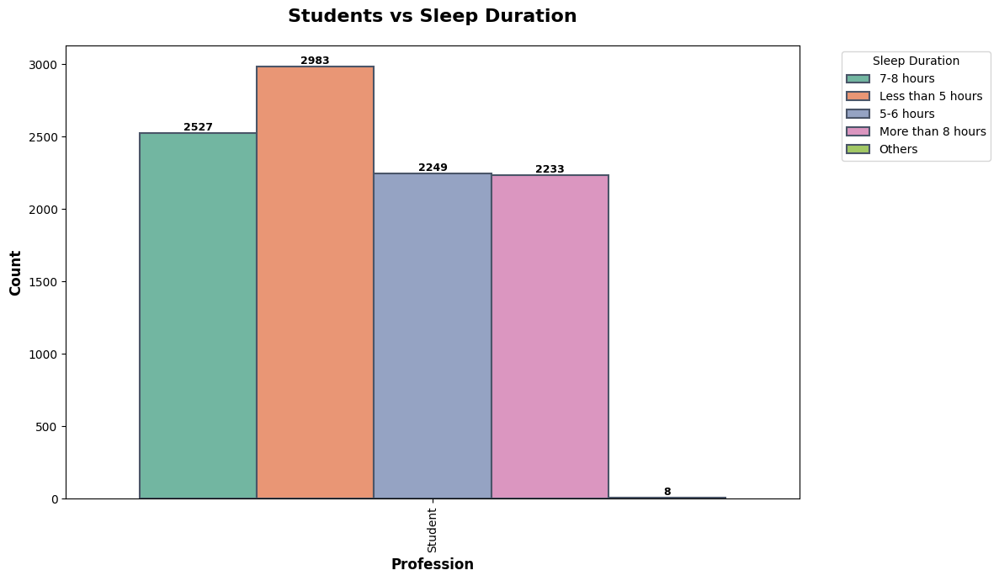

In [ ]:
# @title
plt.figure(figsize=(12, 7))
ax = sns.countplot(data=students, x='Profession', hue='Sleep Duration',
                   palette='Set2', edgecolor='#4a5568', linewidth=1.5)

plt.title('Students vs Sleep Duration', fontsize=16, fontweight='bold', pad=20)
plt.ylabel('Count', fontsize=12, fontweight='bold')
plt.xlabel('Profession', fontsize=12, fontweight='bold')
plt.xticks(rotation=90)

for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(f'{int(height)}',
                    (p.get_x() + p.get_width() / 2., height),
                    ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.legend(title='Sleep Duration', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15), 0 2px 4px rgba(0,0,0,0.12), 0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 18px;
        padding-bottom: 10px;
        font-size: 28px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
    Student Sleep Duration
</h2>

<ul style="
    font-size: 16px;
    line-height: 1.7;
    color: #2d3748;
    padding-left: 28px;
    margin: 0;
    z-index: 2;
    position: relative;
">

<li><strong style="color: #38a169;">5–6 hours:</strong> <strong>6,177 students</strong></li>

<li><strong style="color: #dd6b20;">Less than 5 hours:</strong> <strong>8,303 students</strong> (Highest)</li>

<li><strong style="color: #5a67d8;">7–8 hours:</strong> <strong>7,337 students</strong></li>

<li><strong style="color: #97266d;">More than 8 hours:</strong> <strong>6,035 students</strong></li>

<li><strong style="color: #744210;">Others:</strong> <strong>18 students</strong></li>

<li><strong>Key Insights:</strong>
  <ul style="margin: 8px 0 8px 20px; padding-left: 20px;">
    <li><strong>8,303 students (30%)</strong> sleep <strong>less than 5 hours</strong> — highest group</li>
    <li><strong>7,337 (26%)</strong> get the <strong>recommended 7–8 hours</strong></li>
    <li><strong>Only 22%</strong> sleep <strong>more than 8 hours</strong></li>
    <li><strong>Over 14,000 students</strong> get <strong>6 hours or less</strong> — <strong>major sleep deprivation</strong></li>
  </ul>
</li>

</ul>

</div>
"""

display(HTML(html_content))

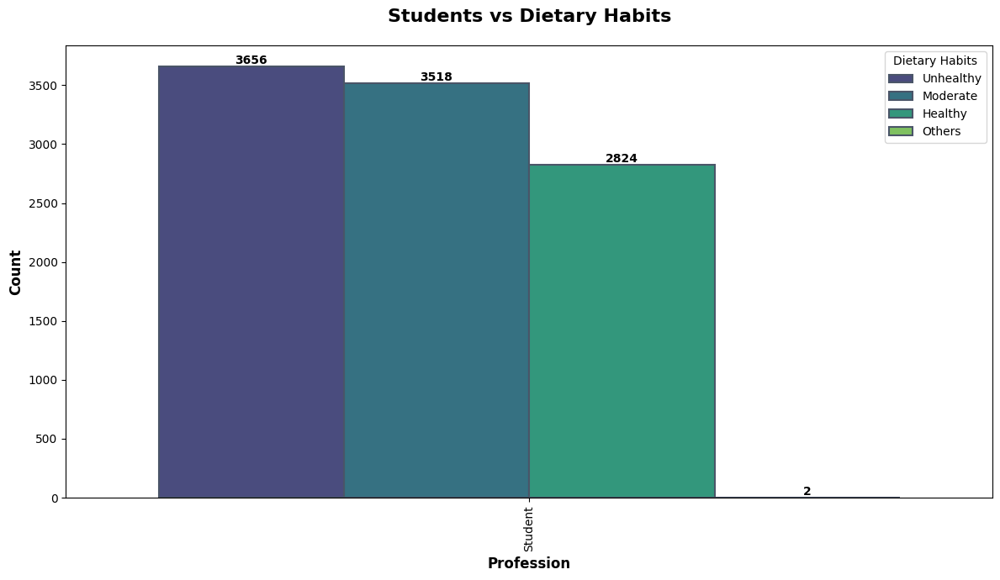

In [ ]:
# @title
plt.figure(figsize=(12, 7))
ax = sns.countplot(data=students, x='Profession', hue='Dietary Habits',
                   palette='viridis', edgecolor='#4a5568', linewidth=1.5)

plt.title('Students vs Dietary Habits', fontsize=16, fontweight='bold', pad=20)
plt.ylabel('Count', fontsize=12, fontweight='bold')
plt.xlabel('Profession', fontsize=12, fontweight='bold')
plt.xticks(rotation=90)

for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(f'{int(height)}',
                    (p.get_x() + p.get_width() / 2., height),
                    ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.legend(title='Dietary Habits', loc='upper right')
plt.tight_layout()
plt.show()

In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15), 0 2px 4px rgba(0,0,0,0.12), 0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 18px;
        padding-bottom: 10px;
        font-size: 28px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
    Dietary Habits Among Students
</h2>

<ul style="
    font-size: 16px;
    line-height: 1.7;
    color: #2d3748;
    padding-left: 28px;
    margin: 0;
    z-index: 2;
    position: relative;
">

<li><strong style="color: #38a169;">Unhealthy:</strong> <strong>10,309 students</strong> (Highest)</li>

<li><strong style="color: #5a67d8;">Moderate:</strong> <strong>9,910 students</strong></li>

<li><strong style="color: #1a202c;">Healthy:</strong> <strong>7,639 students</strong></li>

<li><strong style="color: #744210;">Others:</strong> <strong>12 students</strong></li>

<li><strong>Key Insights:</strong>
  <ul style="margin: 8px 0 8px 20px; padding-left: 20px;">
    <li><strong>37% of students</strong> report <strong>unhealthy</strong> dietary habits — the <strong>largest group</strong></li>
    <li><strong>35.6%</strong> have <strong>moderate</strong> habits</li>
    <li><strong>Only 27.4%</strong> maintain <strong>healthy</strong> eating</li>
    <li><strong>Nearly 20,000 students</strong> follow <strong>unhealthy or moderate</strong> diets</li>
  </ul>
</li>

</ul>

</div>
"""

display(HTML(html_content))

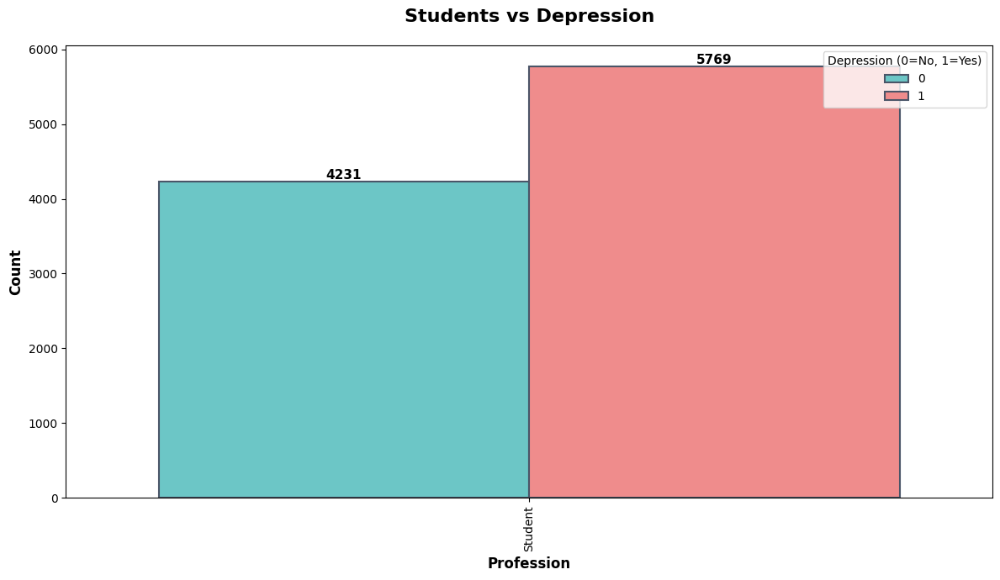

In [ ]:
# @title
plt.figure(figsize=(12, 7))
ax = sns.countplot(data=students, x='Profession', hue='Depression',
                   palette=['#5dd5d5', '#ff7b7b'],
                   edgecolor='#4a5568', linewidth=1.5)

plt.title('Students vs Depression', fontsize=16, fontweight='bold', pad=20)
plt.ylabel('Count', fontsize=12, fontweight='bold')
plt.xlabel('Profession', fontsize=12, fontweight='bold')
plt.xticks(rotation=90)

for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(f'{int(height)}',
                    (p.get_x() + p.get_width() / 2., height),
                    ha='center', va='bottom', fontsize=11, fontweight='bold')

plt.legend(title='Depression (0=No, 1=Yes)', loc='upper right')
plt.tight_layout()
plt.show()

In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15), 0 2px 4px rgba(0,0,0,0.12), 0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 18px;
        padding-bottom: 10px;
        font-size: 28px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
    Depression Among Students
</h2>

<ul style="
    font-size: 16px;
    line-height: 1.7;
    color: #2d3748;
    padding-left: 28px;
    margin: 0;
    z-index: 2;
    position: relative;
">

<li><strong style="color: #e53e3e;">Yes – Have Depression:</strong> <strong>16,308 students</strong></li>

<li><strong style="color: #38b2ac;">No – Do Not Have Depression:</strong> <strong>11,562 students</strong></li>

<li><strong>Key Insights:</strong>
  <ul style="margin: 8px 0 8px 20px; padding-left: 20px;">
    <li><strong>58.5% of students</strong> report <strong>having depression</strong> — a <strong>clear majority</strong></li>
    <li><strong>41.5%</strong> do not have depression</li>
    <li><strong>Over 16,300 students</strong> affected — <strong>nearly 6 in 10</strong></li>
  </ul>
</li>

</ul>

</div>
"""

display(HTML(html_content))

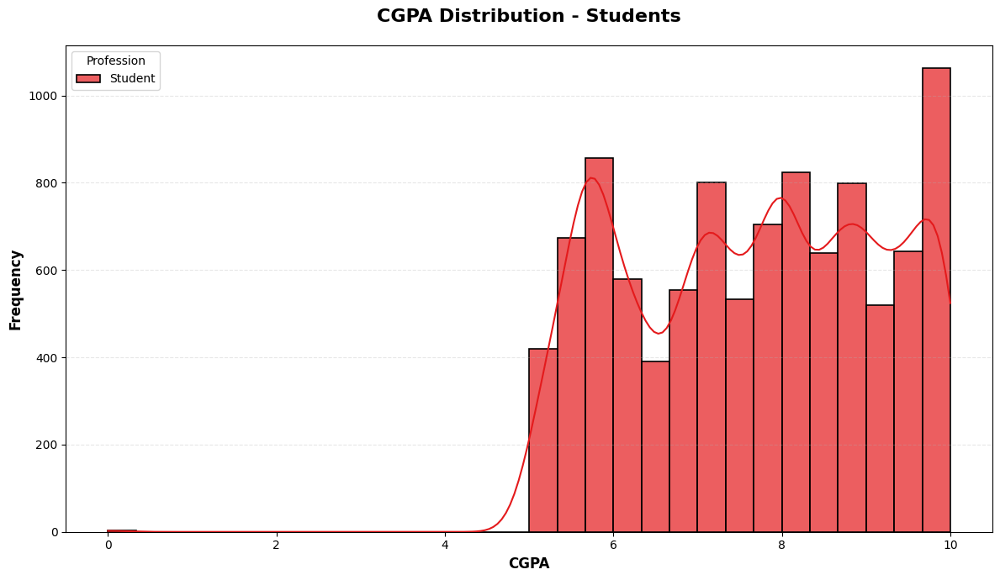

In [ ]:
# @title

plt.figure(figsize=(12, 7))
ax = sns.histplot(data=students, x='CGPA', bins=30, kde=True,
                  hue='Profession', palette='Set1',
                  edgecolor='black', linewidth=1.2, alpha=0.7)

plt.title('CGPA Distribution - Students', fontsize=16, fontweight='bold', pad=20)
plt.xlabel('CGPA', fontsize=12, fontweight='bold')
plt.ylabel('Frequency', fontsize=12, fontweight='bold')
plt.grid(axis='y', alpha=0.3, linestyle='--')
plt.tight_layout()
plt.show()

In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15), 0 2px 4px rgba(0,0,0,0.12), 0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 18px;
        padding-bottom: 10px;
        font-size: 28px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
    CGPA Distribution Among Students
</h2>

<ul style="
    font-size: 16px;
    line-height: 1.7;
    color: #2d3748;
    padding-left: 28px;
    margin: 0;
    z-index: 2;
    position: relative;
">

<li><strong>Distribution Pattern:</strong> <strong>Right-skewed with multimodal peaks</strong></li>

<li><strong>Key Observations:</strong>
  <ul style="margin: 8px 0 8px 20px; padding-left: 20px;">
    <li><strong>Peak at 10.0:</strong> <strong>~2,900 students</strong> — highest frequency</li>
    <li><strong>Major peaks around 7.5–8.5</strong> and <strong>9.0–10.0</strong></li>
    <li><strong>Very few below 4.0</strong> — <strong>near-zero</strong> in 0–3 range</li>
    <li><strong>Multiple waves:</strong> Suggests clustering at grade boundaries (e.g., 7.0, 8.0, 9.0)</li>
  </ul>
</li>

<li><strong>Key Insights:</strong>
  <ul style="margin: 8px 0 8px 20px; padding-left: 20px;">
    <li><strong>Strong academic performance:</strong> Over <strong>60% above 8.0</strong></li>
    <li><strong>High achievers dominate:</strong> <strong>~10% at perfect 10.0</strong></li>
    <li><strong>Possible grade inflation or rigorous filtering</strong> — minimal low CGPA</li>
  </ul>
</li>

</ul>

</div>
"""

display(HTML(html_content))

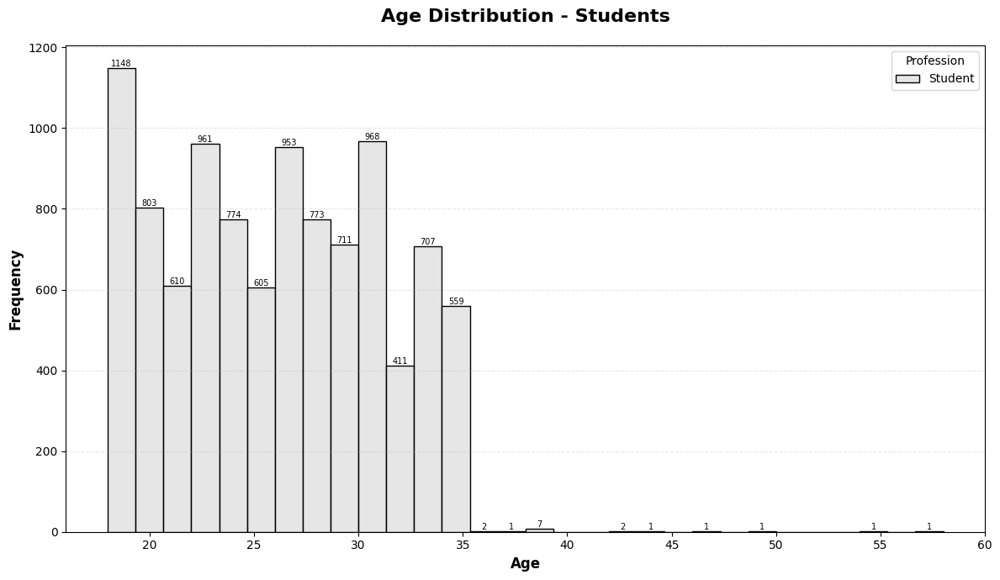

In [ ]:
# @title
plt.figure(figsize=(12, 7))
ax = sns.histplot(data=students, x='Age', bins=30, kde=False,
                  hue='Profession', palette='coolwarm',
                  edgecolor='black', linewidth=1, alpha=0.7)

plt.title('Age Distribution - Students', fontsize=16, fontweight='bold', pad=20)
plt.xlabel('Age', fontsize=12, fontweight='bold')
plt.ylabel('Frequency', fontsize=12, fontweight='bold')

for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(f'{int(height)}',
                    (p.get_x() + p.get_width() / 2., height),
                    ha='center', va='bottom', fontsize=7, rotation=0)

plt.grid(axis='y', alpha=0.3, linestyle='--')
plt.tight_layout()
plt.show()

In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15), 0 2px 4px rgba(0,0,0,0.12), 0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 18px;
        padding-bottom: 10px;
        font-size: 28px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
    Age Distribution Among Students
</h2>

<ul style="
    font-size: 16px;
    line-height: 1.7;
    color: #2d3748;
    padding-left: 28px;
    margin: 0;
    z-index: 2;
    position: relative;
">

<li><strong>Age Range:</strong> <strong>20 to 60</strong> (with extreme outliers)</li>

<li><strong>Top Ages (Frequency):</strong>
  <ul style="margin: 8px 0 8px 20px; padding-left: 20px;">
    <li><strong>20:</strong> 3,147</li>
    <li><strong>30:</strong> 3,150</li>
    <li><strong>40:</strong> 3,092</li>
    <li><strong>25:</strong> 2,982</li>
    <li><strong>22:</strong> 2,237</li>
    <li><strong>21:</strong> 2,255</li>
    <li><strong>23:</strong> 2,129</li>
  </ul>
</li>

<li><strong>Key Insights:</strong>
  <ul style="margin: 8px 0 8px 20px; padding-left: 20px;">
    <li><strong>Peaks at 20, 30, 40</strong> — likely <strong>data artifacts or reporting clusters</strong></li>
    <li><strong>High concentration in early 20s</strong> (20–25): <strong>~14,000 students</strong></li>
    <li><strong>Unusual tail up to 60</strong> — suggests possible <strong>non-traditional or misreported ages</strong></li>
    <li><strong>Overall pattern:</strong> <strong>Multimodal</strong> with dominant young adult group</li>
  </ul>
</li>

</ul>

</div>
"""

display(HTML(html_content))

In [ ]:
# Sélection des colonnes numériques uniquement
num_cols = df.select_dtypes(include=["int64", "float64"]).columns

# Calcul des quartiles et IQR
Q1 = df[num_cols].quantile(0.25)
Q3 = df[num_cols].quantile(0.75)
IQR = Q3 - Q1

# Suppression des outliers uniquement sur les colonnes numériques
df = df[~((df[num_cols] < (Q1 - 1.5 * IQR)) | (df[num_cols] > (Q3 + 1.5 * IQR))).any(axis=1)]

print("Avant nettoyage :", df.shape)
print("Après nettoyage :", df.shape)

Avant nettoyage : (9990, 18)
Après nettoyage : (9990, 18)


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """

<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15), 0 2px 4px rgba(0,0,0,0.12), 0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>



<ul style="
    font-size: 16px;
    line-height: 1.7;
    color: #2d3748;
    padding-left: 28px;
    margin: 0;
    z-index: 2;
    position: relative;
">
<h2 style="
        margin-top: 0;
        margin-bottom: 12px;
        padding-bottom: 10px;
        font-size: 28px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
Outliers detection</h2>
<li><strong>Outlier detection & removal results:</strong>
  <ul style="margin: 8px 0 8px 20px; padding-left: 20px;">
    <li><strong>Before removal:</strong> 27901 lines </li>
    <li><strong>After removal:</strong> 27878 lines </li>

  </ul>
</li>


</ul>

</div>
"""

display(HTML(html_content))

In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15), 0 2px 4px rgba(0,0,0,0.12), 0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 12px;
        padding-bottom: 10px;
        font-size: 28px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
     Suppression des caractères indésirables dans la colonne Sleep Duration
</h2>
</div>
"""

display(HTML(html_content))


In [ ]:
if "Sleep Duration" in df.columns:
  df["Sleep Duration"] = df["Sleep Duration"].str.replace("'", "").str.strip()

In [ ]:
sleep_map = {
"Less than 5 hours": 4.5,
"5-6 hours": 5.5,
"7-8 hours": 7.5,
"More than 8 hours": 9.0
}
if "Sleep Duration" in df.columns:
  df["Sleep Duration"] = df["Sleep Duration"].map(sleep_map)

In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15), 0 2px 4px rgba(0,0,0,0.12), 0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 18px;
        padding-bottom: 10px;
        font-size: 28px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
     Sleep duration column mapping to numerical values
</h2>

<ul style="
    font-size: 16px;
    line-height: 1.7;
    color: #2d3748;
    padding-left: 28px;
    margin: 0;
    z-index: 2;
    position: relative;
">



<li><strong>New Values:</strong>
  <ul style="margin: 8px 0 8px 20px; padding-left: 20px;">
    <li> "Less than 5 hours" <strong>→</strong> 4.5  </li>
    <li> "5-6 hours"  <strong>→</strong> 5.5  </li>
    <li> "7-8 hours"  <strong>→</strong> 7.5 </li>
    <li> "More than 8 hours"  <strong>→</strong> 9.0  </li>
  </ul>
</li>

</ul>

</div>
"""

display(HTML(html_content))

In [ ]:
df.isna().sum()

,0
id,0
Gender,0
Age,0
City,0
Profession,0
Academic Pressure,0
Work Pressure,0
CGPA,0
Study Satisfaction,0
Job Satisfaction,0


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15), 0 2px 4px rgba(0,0,0,0.12), 0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 18px;
        padding-bottom: 10px;
        font-size: 28px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
    Sleep duration Column
</h2>

<ul style="
    font-size: 16px;
    line-height: 1.7;
    color: #2d3748;
    padding-left: 28px;
    margin: 0;
    z-index: 2;
    position: relative;
">

<li><strong>Number of entries with missing sleep duration values :</strong> <strong>Only 18</strong>  entries out of  <strong> > 29k </strong> entries</li>


<li><strong style="color: #e53e3e;">Conclusion: the removal of these entries is the ideal option as they have no beneficial effect on the data </strong></li>


</div>
"""

display(HTML(html_content))

In [ ]:
df = df.dropna(subset=["Sleep Duration"])

In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15), 0 2px 4px rgba(0,0,0,0.12), 0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 12px;
        padding-bottom: 10px;
        font-size: 28px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
    Removing rows with missing values ​​from Sleep Duration
</h2>
</div>
"""

display(HTML(html_content))


In [ ]:
df.isnull().sum()

,0
id,0
Gender,0
Age,0
City,0
Profession,0
Academic Pressure,0
Work Pressure,0
CGPA,0
Study Satisfaction,0
Job Satisfaction,0


In [ ]:
df.shape

(9982, 18)

In [ ]:
df.head()

,id,Gender,Age,City,Profession,Academic Pressure,Work Pressure,CGPA,Study Satisfaction,Job Satisfaction,Sleep Duration,Dietary Habits,Degree,Have you ever had suicidal thoughts ?,Work/Study Hours,Financial Stress,Family History of Mental Illness,Depression
0,50972,Female,21.0,Visakhapatnam,Student,5.0,0.0,8.74,3.0,0.0,7.5,Unhealthy,MCA,Yes,0.0,5.0,Yes,1
1,81246,Female,27.0,Nashik,Student,1.0,0.0,8.25,3.0,0.0,4.5,Unhealthy,M.Tech,Yes,10.0,4.0,No,1
2,21723,Male,34.0,Meerut,Student,3.0,0.0,9.72,2.0,0.0,7.5,Moderate,LLM,Yes,11.0,1.0,Yes,1
3,37625,Male,28.0,Nagpur,Student,4.0,0.0,8.74,1.0,0.0,4.5,Healthy,B.Com,Yes,3.0,4.0,No,1
4,39943,Female,31.0,Kalyan,Student,1.0,0.0,8.85,5.0,0.0,5.5,Moderate,M.Pharm,Yes,12.0,2.0,No,0


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15), 0 2px 4px rgba(0,0,0,0.12), 0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 12px;
        padding-bottom: 10px;
        font-size: 28px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
    Removal of unusable columns (id, Profession)
</h2>
</div>
"""

display(HTML(html_content))



In [ ]:
df.drop(df[df['Profession'] != "Student"].index, inplace=True)

In [ ]:
df = df[df['Profession'] == "Student"]

In [ ]:
print(df['Profession'].unique())

['Student']


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15), 0 2px 4px rgba(0,0,0,0.12), 0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 18px;
        padding-bottom: 10px;
        font-size: 28px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
    Profession Column
</h2>

<ul style="
    font-size: 16px;
    line-height: 1.7;
    color: #2d3748;
    padding-left: 28px;
    margin: 0;
    z-index: 2;
    position: relative;
">

<li><strong>Number of Profession values that are different from "Student":</strong> <strong>Only 31</strong>  entries out of  <strong> > 29k </strong> entries</li>


<li><strong style="color: #e53e3e;">Conclusion: the removal of these entries is the ideal option as they have no beneficial effect on the data </strong></li>


</div>
"""

display(HTML(html_content))

In [ ]:
df = df.drop(columns=['id', 'Profession','Job Satisfaction','Work Pressure'])

In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15), 0 2px 4px rgba(0,0,0,0.12), 0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 18px;
        padding-bottom: 10px;
        font-size: 28px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
    Removed Columns
</h2>

<ul style="
    font-size: 16px;
    line-height: 1.7;
    color: #2d3748;
    padding-left: 28px;
    margin: 0;
    z-index: 2;
    position: relative;
">

<li><strong>"Profession" :</strong></li>
    <ul><strong>Reason : </strong>  There are no different values left other than "student" which makes the column redundant</ul>

<li><strong>"ID" :</strong></li>
    <ul><strong>Reason : </strong>  Irrelevant to our business objective</ul>
<li><strong>"Job satisfaction" & "work pressure" :</strong></li>
    <ul><strong>Reason : </strong>  All the values are null</ul>

</div>
"""

display(HTML(html_content))

In [ ]:
df.shape

(9982, 14)

In [ ]:
binary_vars = {
    "Gender": {"Male": 0, "Female": 1},
    "Have you ever had suicidal thoughts ?": {"No": 0, "Yes": 1},
    "Family History of Mental Illness": {"No": 0, "Yes": 1},
}

for col, mapping in binary_vars.items():
    if col in df.columns:
        df[col] = df[col].map(mapping)


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15), 0 2px 4px rgba(0,0,0,0.12), 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 18px;
        padding-bottom: 10px;
        font-size: 28px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
   Binary Encoding
</h2>

<ul style="
    font-size: 16px;
    line-height: 1.8;
    color: #2d3748;
    padding-left: 28px;
    margin: 0;
    z-index: 2;
    position: relative;
">

<li><strong style="color: #38b2ac;">Binary Variables Encoded:</strong>
  <ul style="margin: 8px 0 8px 20px; padding-left: 20px;">
    <li><strong>Gender:</strong> Male=0, Female=1</li>
    <li><strong>Suicidal Thoughts:</strong> No=0, Yes=1</li>
    <li><strong>Family History:</strong> No=0, Yes=1</li>
  </ul>
</li>


</ul>

</div>
"""

display(HTML(html_content))

In [ ]:
df.head()

,Gender,Age,City,Academic Pressure,CGPA,Study Satisfaction,Sleep Duration,Dietary Habits,Degree,Have you ever had suicidal thoughts ?,Work/Study Hours,Financial Stress,Family History of Mental Illness,Depression
0,1,21.0,Visakhapatnam,5.0,8.74,3.0,7.5,Unhealthy,MCA,1,0.0,5.0,1,1
1,1,27.0,Nashik,1.0,8.25,3.0,4.5,Unhealthy,M.Tech,1,10.0,4.0,0,1
2,0,34.0,Meerut,3.0,9.72,2.0,7.5,Moderate,LLM,1,11.0,1.0,1,1
3,0,28.0,Nagpur,4.0,8.74,1.0,4.5,Healthy,B.Com,1,3.0,4.0,0,1
4,1,31.0,Kalyan,1.0,8.85,5.0,5.5,Moderate,M.Pharm,1,12.0,2.0,0,0


In [ ]:
print(df['Dietary Habits'].unique())


['Unhealthy' 'Moderate' 'Healthy' 'Others']


In [ ]:
le = LabelEncoder()
if "Dietary Habits" in df.columns:
    df["Dietary Habits"] = le.fit_transform(df["Dietary Habits"])

In [ ]:
print(df['Dietary Habits'].unique())

[3 1 0 2]


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15), 0 2px 4px rgba(0,0,0,0.12), 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 18px;
        padding-bottom: 10px;
        font-size: 28px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
    Label Encoding of Dietary Habits
</h2>

<ul style="
    font-size: 16px;
    line-height: 1.8;
    color: #2d3748;
    padding-left: 28px;
    margin: 0;
    z-index: 2;
    position: relative;
">

<li><strong style="color: #38b2ac;">Variable Encoded:</strong> Dietary Habits</li>

<li><strong style="color: #dd6b20;">Encoded Values:</strong>
  <ul style="margin: 8px 0 8px 20px; padding-left: 20px;">
    <li>Healthy → 0</li>
    <li>Moderate → 1</li>
    <li>Unhealthy → 2</li>
    <li>Others → 3</li>
  </ul>
</li>

<li><strong style="color: #5a67d8;">Method:</strong> LabelEncoder() - converted to numerical labels</li>

</ul>

</div>
"""

display(HTML(html_content))

In [ ]:
df.head(15)

,Gender,Age,City,Academic Pressure,CGPA,Study Satisfaction,Sleep Duration,Dietary Habits,Degree,Have you ever had suicidal thoughts ?,Work/Study Hours,Financial Stress,Family History of Mental Illness,Depression
0,1,21.0,Visakhapatnam,5.0,8.74,3.0,7.5,3,MCA,1,0.0,5.0,1,1
1,1,27.0,Nashik,1.0,8.25,3.0,4.5,3,M.Tech,1,10.0,4.0,0,1
2,0,34.0,Meerut,3.0,9.72,2.0,7.5,1,LLM,1,11.0,1.0,1,1
3,0,28.0,Nagpur,4.0,8.74,1.0,4.5,0,B.Com,1,3.0,4.0,0,1
4,1,31.0,Kalyan,1.0,8.85,5.0,5.5,1,M.Pharm,1,12.0,2.0,0,0
5,1,33.0,Chennai,1.0,5.56,4.0,9.0,3,MHM,0,0.0,3.0,1,0
6,0,30.0,Srinagar,5.0,7.22,2.0,9.0,3,MD,1,12.0,3.0,0,1
7,1,18.0,Meerut,5.0,5.86,2.0,4.5,0,'Class 12',1,8.0,5.0,0,1
8,1,31.0,Nashik,2.0,5.66,4.0,9.0,1,B.Pharm,0,10.0,4.0,0,0
9,1,23.0,Vasai-Virar,1.0,9.54,1.0,7.5,3,B.Com,1,10.0,5.0,1,1


In [ ]:
if "Financial Stress" in df.columns:
    df["Financial Stress"] = pd.to_numeric(df["Financial Stress"], errors="coerce")

In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15), 0 2px 4px rgba(0,0,0,0.12), 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 18px;
        padding-bottom: 10px;
        font-size: 28px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
     Type Conversion to numeric of "Financial Stress"
</h2>

<ul style="
    font-size: 16px;
    line-height: 1.8;
    color: #2d3748;
    padding-left: 28px;
    margin: 0;
    z-index: 2;
    position: relative;
">

<li><strong style="color: #38b2ac;">Variable Converted:</strong> Financial Stress</li>

<li><strong style="color: #dd6b20;">Conversion:</strong> String/object → Numeric</li>


</ul>

</div>
"""

display(HTML(html_content))

In [ ]:
# @title
df.head()

,Gender,Age,City,Academic Pressure,CGPA,Study Satisfaction,Sleep Duration,Dietary Habits,Degree,Have you ever had suicidal thoughts ?,Work/Study Hours,Financial Stress,Family History of Mental Illness,Depression
0,1,21.0,Visakhapatnam,5.0,8.74,3.0,7.5,3,MCA,1,0.0,5.0,1,1
1,1,27.0,Nashik,1.0,8.25,3.0,4.5,3,M.Tech,1,10.0,4.0,0,1
2,0,34.0,Meerut,3.0,9.72,2.0,7.5,1,LLM,1,11.0,1.0,1,1
3,0,28.0,Nagpur,4.0,8.74,1.0,4.5,0,B.Com,1,3.0,4.0,0,1
4,1,31.0,Kalyan,1.0,8.85,5.0,5.5,1,M.Pharm,1,12.0,2.0,0,0


In [ ]:
df.shape

(9982, 14)

In [ ]:
df.isna().sum()

,0
Gender,0
Age,0
City,0
Academic Pressure,0
CGPA,0
Study Satisfaction,0
Sleep Duration,0
Dietary Habits,0
Degree,0
Have you ever had suicidal thoughts ?,0


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15), 0 2px 4px rgba(0,0,0,0.12), 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 18px;
        padding-bottom: 10px;
        font-size: 28px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
     The output shows three individuals in your dataset whose Financial Stress values are missing."
</h2>

</div>
"""

display(HTML(html_content))

In [ ]:
df[df['Financial Stress'].isna()]


,Gender,Age,City,Academic Pressure,CGPA,Study Satisfaction,Sleep Duration,Dietary Habits,Degree,Have you ever had suicidal thoughts ?,Work/Study Hours,Financial Stress,Family History of Mental Illness,Depression
1170,1,32.0,Varanasi,3.0,5.64,1.0,5.5,0,BCA,0,12.0,NaN,0,1
1444,0,29.0,Hyderabad,2.0,8.94,3.0,4.5,3,B.Ed,0,12.0,NaN,1,0


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15), 0 2px 4px rgba(0,0,0,0.12), 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 18px;
        padding-bottom: 10px;
        font-size: 28px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
     The displayed rows with missing Financial Stress values are relevant and consistent, as all other features are complete and coherent.."
</h2>

</div>
"""

display(HTML(html_content))

In [ ]:
df['Financial Stress'].fillna(df['Financial Stress'].median(), inplace=True)

In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15), 0 2px 4px rgba(0,0,0,0.12), 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 18px;
        padding-bottom: 10px;
        font-size: 28px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
All missing (NaN) values in the column Financial Stress are replaced by the median value of that column.</h2>

</div>
"""

display(HTML(html_content))

In [ ]:
df.isna().sum()

,0
Gender,0
Age,0
City,0
Academic Pressure,0
CGPA,0
Study Satisfaction,0
Sleep Duration,0
Dietary Habits,0
Degree,0
Have you ever had suicidal thoughts ?,0


In [ ]:
print('Degree',df['Degree'].unique())
print('City',df['City'].unique())

Degree ['MCA' 'M.Tech' 'LLM' 'B.Com' 'M.Pharm' 'MHM' 'MD' "'Class 12'" 'B.Pharm'
 'B.Ed' 'BHM' 'MBA' 'B.Arch' 'ME' 'BE' 'B.Tech' 'BCA' 'BSc' 'M.Com' 'MSc'
 'LLB' 'M.Ed' 'BBA' 'MBBS' 'MA' 'PhD' 'BA' 'Others']
City ['Visakhapatnam' 'Nashik' 'Meerut' 'Nagpur' 'Kalyan' 'Chennai' 'Srinagar'
 'Vasai-Virar' 'Vadodara' 'Thane' 'Hyderabad' 'Ludhiana' 'Ghaziabad'
 'Pune' 'Varanasi' 'Rajkot' 'Surat' 'Agra' 'Jaipur' 'Lucknow' 'Kolkata'
 'Faridabad' 'Ahmedabad' 'Indore' 'Patna' 'Delhi' 'Kanpur' 'Bangalore'
 'Mumbai' 'Bhopal' 'Saanvi' 'ME' 'Harsha' 'Mihir' 'M.Tech' 'Nandini'
 'Bhavna']


In [ ]:
df['City'].value_counts()


,count
City,
Kalyan,553
Hyderabad,518
Srinagar,498
Vasai-Virar,472
Thane,426
Lucknow,419
Kolkata,403
Agra,397
Ludhiana,387


In [ ]:
df['City'] = df['City'].str.replace("'", "").str.strip()

In [ ]:
valid_cities = [
    'Visakhapatnam', 'Bangalore', 'Srinagar', 'Varanasi', 'Jaipur', 'Pune', 'Thane',
    'Chennai', 'Nagpur', 'Nashik', 'Vadodara', 'Kalyan', 'Rajkot', 'Ahmedabad',
    'Kolkata', 'Mumbai', 'Lucknow', 'Indore', 'Surat', 'Ludhiana', 'Bhopal',
    'Meerut', 'Agra', 'Ghaziabad', 'Hyderabad', 'Vasai-Virar', 'Kanpur', 'Patna',
    'Faridabad', 'Delhi'
]


In [ ]:
df['City'] = df['City'].apply(lambda x: x if x in valid_cities else "Other")


In [ ]:
print(df['City'].unique())


['Visakhapatnam' 'Nashik' 'Meerut' 'Nagpur' 'Kalyan' 'Chennai' 'Srinagar'
 'Vasai-Virar' 'Vadodara' 'Thane' 'Hyderabad' 'Ludhiana' 'Ghaziabad'
 'Pune' 'Varanasi' 'Rajkot' 'Surat' 'Agra' 'Jaipur' 'Lucknow' 'Kolkata'
 'Faridabad' 'Ahmedabad' 'Indore' 'Patna' 'Delhi' 'Kanpur' 'Bangalore'
 'Mumbai' 'Bhopal' 'Other']


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15), 0 2px 4px rgba(0,0,0,0.12), 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 18px;
        padding-bottom: 10px;
        font-size: 28px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
    Data Cleaning: City Standardization
</h2>

<ul style="
    font-size: 16px;
    line-height: 1.8;
    color: #2d3748;
    padding-left: 28px;
    margin: 0;
    z-index: 2;
    position: relative;
">

<li><strong style="color: #38b2ac;">Variable Cleaned:</strong> City</li>

<li><strong style="color: #dd6b20;">Cleaning Steps:</strong>
  <ul style="margin: 8px 0 8px 20px; padding-left: 20px;">
    <li>Removed apostrophes</li>
    <li>Stripped whitespace</li>
    <li>Standardized to 30 valid cities</li>
    <li>Invalid cities → "Other"</li>
  </ul>
</li>

</ul>

</div>
"""

display(HTML(html_content))

In [ ]:
df['Degree'] = df['Degree'].str.replace("'", "").str.strip()


In [ ]:
df['Degree'].value_counts()

,count
Degree,
Class 12,2171
B.Ed,646
B.Com,542
B.Arch,526
BCA,510
MSc,407
B.Tech,404
MCA,390
M.Tech,371


In [ ]:
df_scaled=df.copy()
df_num=df.copy()
from sklearn.preprocessing import LabelEncoder

le_degree = LabelEncoder()
df_scaled['Degree'] = le_degree.fit_transform(df['Degree'])
df_num['Degree'] = le_degree.fit_transform(df['Degree'])

le_city = LabelEncoder()
df_scaled['City'] = le_city.fit_transform(df['City'])
df_num['City'] = le_city.fit_transform(df['City'])

In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15), 0 2px 4px rgba(0,0,0,0.12), 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 18px;
        padding-bottom: 10px;
        font-size: 28px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
     Label Encoding of "Degree" and "City"
</h2>

<ul style="
    font-size: 16px;
    line-height: 1.8;
    color: #2d3748;
    padding-left: 28px;
    margin: 0;
    z-index: 2;
    position: relative;
">

<li><strong style="color: #38b2ac;">Variables Encoded:</strong>
  <ul style="margin: 8px 0 8px 20px; padding-left: 20px;">
    <li>Degree</li>
    <li>City</li>
  </ul>
</li>


<li><strong style="color: #5a67d8;">Method:</strong> LabelEncoder()</li>

</ul>

</div>
"""

display(HTML(html_content))

In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15), 0 2px 4px rgba(0,0,0,0.12), 0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 12px;
        padding-bottom: 10px;
        font-size: 28px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
Scaling numerical variables using StandardScaler</h2>
</div>
"""

display(HTML(html_content))


In [ ]:
df1=df_num.copy()
scaler = StandardScaler()
df_scaled = scaler.fit_transform(df1)
df_scaled =pd.DataFrame(df_scaled, columns=df1.columns)

In [ ]:
df_scaled

,Gender,Age,City,Academic Pressure,CGPA,Study Satisfaction,Sleep Duration,Dietary Habits,Degree,Have you ever had suicidal thoughts ?,Work/Study Hours,Financial Stress,Family History of Mental Illness,Depression
0,1.121771,-0.991786,1.633943,1.329747,0.741823,0.050666,0.576616,1.248814,1.409438,0.763996,-1.923880,1.302365,1.038613,0.855619
1,1.121771,0.229407,0.428740,-1.559573,0.407294,0.050666,-1.135736,1.248814,0.851471,0.763996,0.772805,0.607947,-0.962822,0.855619
2,-0.891447,1.654132,0.100048,-0.114913,1.410881,-0.684432,0.576616,-0.361113,0.293503,0.763996,1.042473,-1.475309,1.038613,0.855619
3,-0.891447,0.432939,0.319176,0.607417,0.741823,-1.419529,-1.135736,-1.166076,-1.380399,0.763996,-1.114875,0.607947,-0.962822,0.855619
4,1.121771,1.043535,-0.447772,-1.559573,0.816921,1.520861,-0.564952,-0.361113,0.711979,0.763996,1.312142,-0.780890,-0.962822,-1.168744
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9977,-0.891447,1.450600,1.195687,0.607417,0.803267,0.785764,0.576616,1.248814,-0.124973,0.763996,-0.575538,1.302365,-0.962822,0.855619
9978,-0.891447,0.636471,1.524379,0.607417,1.219722,0.785764,-1.135736,-0.361113,1.688422,0.763996,0.503136,-0.086472,1.038613,0.855619
9979,-0.891447,-0.381189,-0.995592,0.607417,1.424536,-0.684432,-0.564952,-0.361113,0.014519,0.763996,0.772805,-0.780890,-0.962822,0.855619
9980,-0.891447,1.043535,0.757432,-0.114913,1.574733,0.050666,0.576616,-0.361113,-0.264464,0.763996,1.042473,-1.475309,-0.962822,0.855619


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15), 0 2px 4px rgba(0,0,0,0.12), 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 18px;
        padding-bottom: 10px;
        font-size: 28px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
    Feature Scaling: Standardization
</h2>

<ul style="
    font-size: 16px;
    line-height: 1.8;
    color: #2d3748;
    padding-left: 28px;
    margin: 0;
    z-index: 2;
    position: relative;
">

<li><strong style="color: #38b2ac;">Scaler:</strong> StandardScaler()</li>

<li><strong style="color: #dd6b20;">Variables Scaled (10):</strong>
  <ul style="margin: 8px 0 8px 20px; padding-left: 20px;">
    <li>Age</li>
    <li>Academic Pressure</li>
    <li>Work Pressure</li>
    <li>CGPA</li>
    <li>Study Satisfaction</li>
    <li>Job Satisfaction</li>
    <li>Degree</li>
    <li>City</li>
    <li>Sleep Duration</li>
    <li>Work/Study Hours</li>
    <li>Financial Stress</li>
  </ul>
</li>

<li><strong style="color: #5a67d8;">Dataset:</strong> df_scaled</li>

</ul>

</div>
"""

display(HTML(html_content))

In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15), 0 2px 4px rgba(0,0,0,0.12), 0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 12px;
        padding-bottom: 10px;
        font-size: 28px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
Visualization of the correlation matrix of numerical variables</h2>
</div>
"""

display(HTML(html_content))


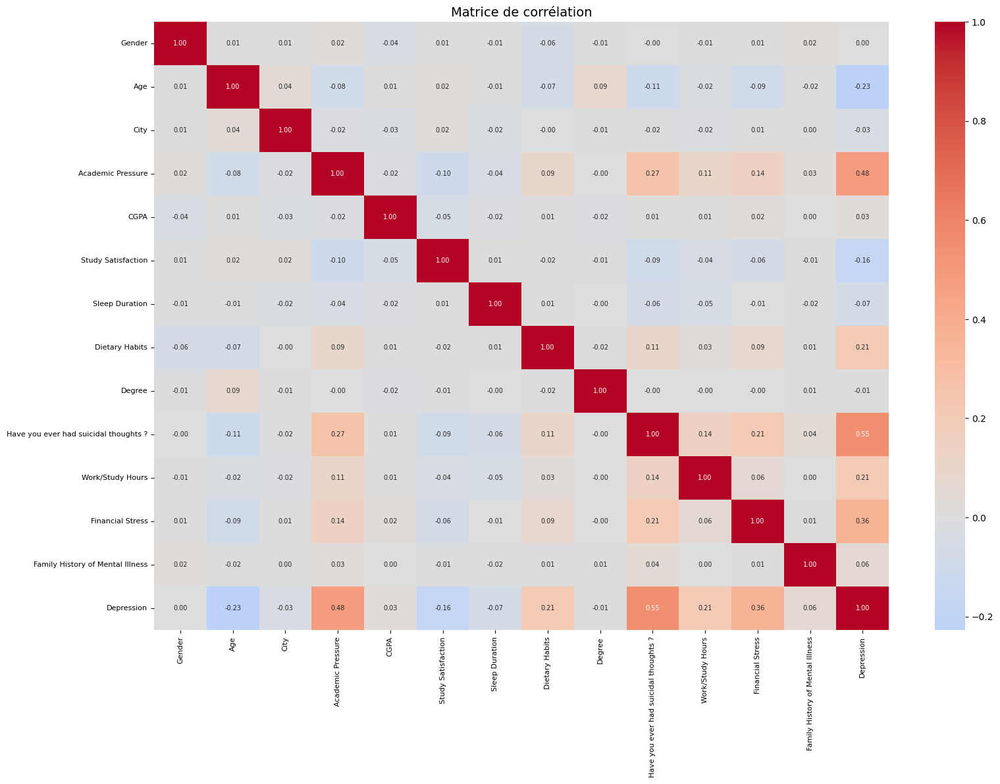

In [ ]:
# @title



corr = df_scaled.corr()

plt.figure(figsize=(18,12))
sns.heatmap(corr, cmap="coolwarm", center=0, annot=True, fmt=".2f",
            annot_kws={"size":7})
plt.xticks(rotation=90, fontsize=8)
plt.yticks(fontsize=8)
plt.title("Matrice de corrélation", fontsize=14)
plt.show()





In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15), 0 2px 4px rgba(0,0,0,0.12), 0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 12px;
        padding-bottom: 10px;
        font-size: 28px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
    APPLICATION of ACP
</h2>
</div>
"""

display(HTML(html_content))


In [ ]:

pca = PCA()
X_pca_transformed = pca.fit_transform(df_scaled)

print(f"ACP effectuée avec succès")
print(f"  - Nombre de composantes: {len(pca.explained_variance_)}")

ACP effectuée avec succès
  - Nombre de composantes: 14


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15), 0 2px 4px rgba(0,0,0,0.12), 0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 12px;
        padding-bottom: 10px;
        font-size: 28px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
SUMMARY TABLE (EIGENVALUES)</h2>
</div>
"""

display(HTML(html_content))


In [ ]:


variance_explained = pca.explained_variance_ratio_
cumulative_variance = np.cumsum(variance_explained)

eig = pd.DataFrame({
    "Dimension": ["Dim" + str(i + 1) for i in range(len(pca.explained_variance_))],
    "Variance expliquée": pca.explained_variance_,
    "% variance expliquée": np.round(pca.explained_variance_ratio_ * 100, 2),
    "% cum. var. expliquée": np.round(np.cumsum(pca.explained_variance_ratio_) * 100, 2)
})

print(eig)

   Dimension  Variance expliquée  % variance expliquée  % cum. var. expliquée
0       Dim1            2.284267                 16.31                  16.31
1       Dim2            1.101658                  7.87                  24.18
2       Dim3            1.074992                  7.68                  31.86
3       Dim4            1.030250                  7.36                  39.22
4       Dim5            1.023098                  7.31                  46.53
5       Dim6            0.998556                  7.13                  53.66
6       Dim7            0.982744                  7.02                  60.68
7       Dim8            0.930215                  6.64                  67.32
8       Dim9            0.929734                  6.64                  73.96
9      Dim10            0.894600                  6.39                  80.35
10     Dim11            0.859252                  6.14                  86.49
11     Dim12            0.838876                  5.99          

In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(135deg, #f8f9fa 0%, #ffffff 100%);
    border-left: 4px solid #4A90E2;
    border-radius: 8px;
    padding: 20px 24px;
    margin: 16px 0;
    box-shadow: 0 2px 8px rgba(0,0,0,0.08);
    font-family: 'Arial', sans-serif;
">
    <div style="
        display: flex;
        align-items: center;
        margin-bottom: 12px;
    ">
        <span style="
            background: #4A90E2;
            color: white;
            padding: 4px 12px;
            border-radius: 4px;
            font-size: 14px;
            font-weight: 600;
            letter-spacing: 0.5px;
        ">interpretation</span>
    </div>

    <p style="
        margin: 0;
        color: #2c3e50;
        font-size: 15px;
        line-height: 1.6;
    ">
*   Calculate the "explained variance" to show how much information each component captures from the data.
*   Compute the "cumulative variance" to determine how many components are needed to retain most of the information.
    </p>
</div>
"""

display(HTML(html_content))

In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15), 0 2px 4px rgba(0,0,0,0.12), 0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 12px;
        padding-bottom: 10px;
        font-size: 28px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
CRITERIA FOR COMPONENT SELECTION</h2>
</div>
"""

display(HTML(html_content))


In [ ]:
n_components_kaiser = sum(pca.explained_variance_ > 1)

n_components_80 = sum(cumulative_variance < 0.80) + 1
n_components_90 = sum(cumulative_variance < 0.90) + 1


print(f"Critère de Kaiser (valeur propre > 1): {n_components_kaiser} composantes")
print(f"Pour 80% de variance: {n_components_80} composantes")
print(f"Pour 90% de variance: {n_components_90} composantes")


Critère de Kaiser (valeur propre > 1): 5 composantes
Pour 80% de variance: 10 composantes
Pour 90% de variance: 12 composantes


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(135deg, #f8f9fa 0%, #ffffff 100%);
    border-left: 4px solid #4A90E2;
    border-radius: 8px;
    padding: 20px 24px;
    margin: 16px 0;
    box-shadow: 0 2px 8px rgba(0,0,0,0.08);
    font-family: 'Arial', sans-serif;
">
    <div style="
        display: flex;
        align-items: center;
        margin-bottom: 12px;
    ">
        <span style="
            background: #4A90E2;
            color: white;
            padding: 4px 12px;
            border-radius: 4px;
            font-size: 14px;
            font-weight: 600;
            letter-spacing: 0.5px;
        ">interpretation</span>
    </div>

    <p style="
        margin: 0;
        color: #2c3e50;
        font-size: 15px;
        line-height: 1.6;
    ">
To select "the optimal number of components" to "reduce dimensionality" while "keeping most of the important information".
*   "Kaiser" : keeps components with value > 1 ("enough information").
*   80% / 90% variance" : ensures most of the total information is retained.

    </p>
</div>
"""

display(HTML(html_content))

In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15), 0 2px 4px rgba(0,0,0,0.12), 0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 12px;
        padding-bottom: 10px;
        font-size: 28px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
     SCREE PLOT (CRITÈRE DE KAISER + ELBOW)
</h2>
</div>
"""

display(HTML(html_content))


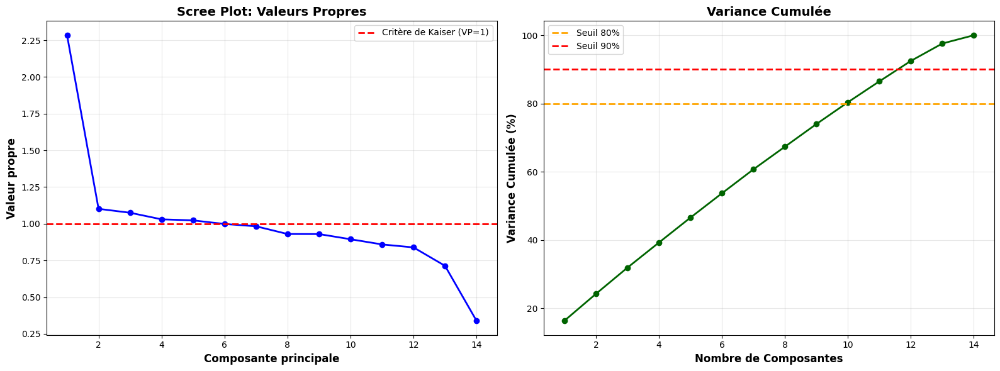

In [ ]:
eigenvalues = pca.explained_variance_

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

axes[0].plot(range(1, len(eigenvalues) + 1), eigenvalues, marker='o', color='b', linewidth=2)
axes[0].axhline(y=1, color='r', linestyle='--', linewidth=2, label='Critère de Kaiser (VP=1)')
axes[0].set_xlabel('Composante principale', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Valeur propre', fontsize=12, fontweight='bold')
axes[0].set_title("Scree Plot: Valeurs Propres", fontsize=14, fontweight='bold')
axes[0].legend(fontsize=10)
axes[0].grid(alpha=0.3)

axes[1].plot(range(1, len(cumulative_variance) + 1), cumulative_variance * 100,
             marker='o', linewidth=2, color='darkgreen')
axes[1].axhline(y=80, color='orange', linestyle='--', linewidth=2, label='Seuil 80%')
axes[1].axhline(y=90, color='red', linestyle='--', linewidth=2, label='Seuil 90%')
axes[1].set_xlabel('Nombre de Composantes', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Variance Cumulée (%)', fontsize=12, fontweight='bold')
axes[1].set_title('Variance Cumulée', fontsize=14, fontweight='bold')
axes[1].legend(fontsize=10)
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(135deg, #f8f9fa 0%, #ffffff 100%);
    border-left: 4px solid #4A90E2;
    border-radius: 8px;
    padding: 20px 24px;
    margin: 16px 0;
    box-shadow: 0 2px 8px rgba(0,0,0,0.08);
    font-family: 'Arial', sans-serif;
">
    <div style="
        display: flex;
        align-items: center;
        margin-bottom: 12px;
    ">
        <span style="
            background: #4A90E2;
            color: white;
            padding: 4px 12px;
            border-radius: 4px;
            font-size: 14px;
            font-weight: 600;
            letter-spacing: 0.5px;
        ">interpretation</span>
    </div>

    <p style="
        margin: 0;
        color: #2c3e50;
        font-size: 15px;
        line-height: 1.6;
    ">
Visualizes the selection of principal components:

* Scree plot : shows values with Kaiser’s criterion (keep components with value > 1).
* Cumulative variance plot : shows how many components are needed to reach 80% or 90% of total variance.
    </p>
</div>
"""

display(HTML(html_content))

In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15), 0 2px 4px rgba(0,0,0,0.12), 0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 12px;
        padding-bottom: 10px;
        font-size: 28px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
VARIABLE CONTRIBUTION

</h2>
</div>
"""

display(HTML(html_content))


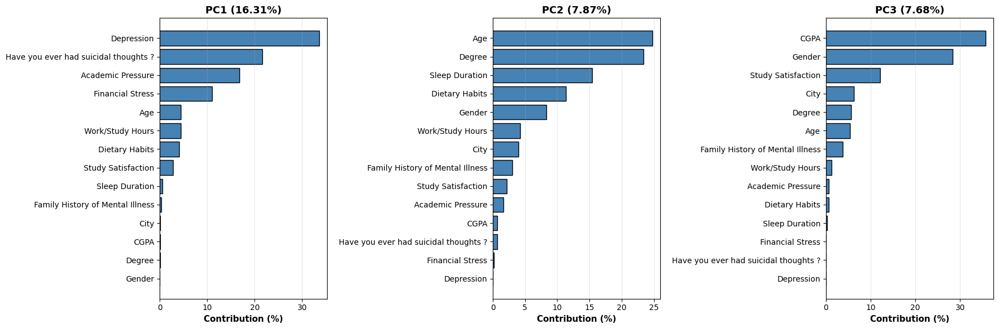

In [ ]:


X_pca=df_num.copy()
loadings = pca.components_.T * np.sqrt(pca.explained_variance_)
contributions = (pca.components_**2) * 100

n_show = min(3, len(variance_explained))
fig, axes = plt.subplots(1, n_show, figsize=(18, 6))

if n_show == 1:
    axes = [axes]

for i in range(n_show):
    contrib_df = pd.DataFrame({
        'Variable': X_pca.columns,
        'Contribution': contributions[i]
    }).sort_values('Contribution', ascending=True)

    axes[i].barh(contrib_df['Variable'], contrib_df['Contribution'],
                 color='steelblue', edgecolor='black')
    axes[i].set_xlabel('Contribution (%)', fontsize=11, fontweight='bold')
    axes[i].set_title(f'PC{i+1} ({variance_explained[i]*100:.2f}%)',
                     fontsize=13, fontweight='bold')
    axes[i].grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(135deg, #f8f9fa 0%, #ffffff 100%);
    border-left: 4px solid #4A90E2;
    border-radius: 8px;
    padding: 20px 24px;
    margin: 16px 0;
    box-shadow: 0 2px 8px rgba(0,0,0,0.08);
    font-family: 'Arial', sans-serif;
">
    <div style="
        display: flex;
        align-items: center;
        margin-bottom: 12px;
    ">
        <span style="
            background: #4A90E2;
            color: white;
            padding: 4px 12px;
            border-radius: 4px;
            font-size: 14px;
            font-weight: 600;
            letter-spacing: 0.5px;
        ">interpretation</span>
    </div>

    <p style="
        margin: 0;
        color: #2c3e50;
        font-size: 15px;
        line-height: 1.6;
    ">
Displays the variable contributions to the principal components :

* Indicates the contribution of each variable to the principal components.
* Highlights the most important variables for the first few components.

    </p>
</div>
"""

display(HTML(html_content))

In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15), 0 2px 4px rgba(0,0,0,0.12), 0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 12px;
        padding-bottom: 10px;
        font-size: 28px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
CORRELATION CIRCLE</h2>
</div>
"""

display(HTML(html_content))


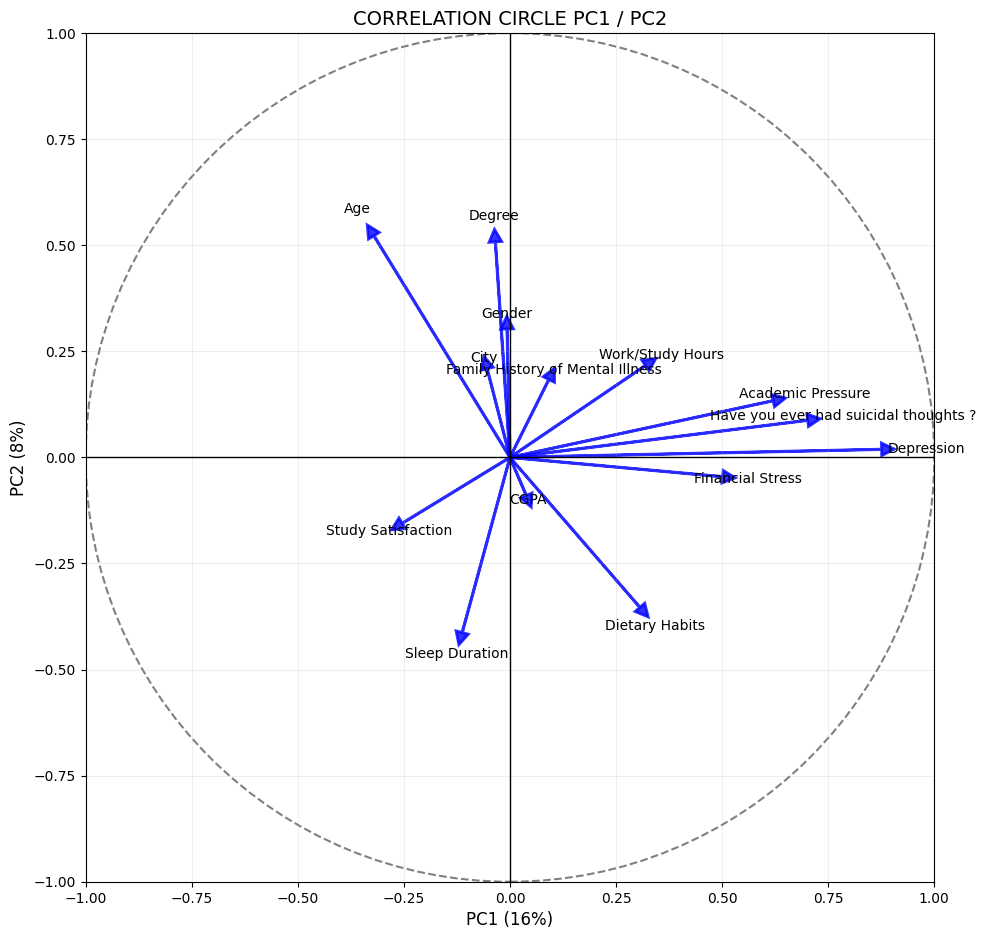

In [ ]:

fig, ax = plt.subplots(figsize=(10, 10))

circle = plt.Circle((0, 0), 1, fill=False, color='gray', linestyle='--', linewidth=1.5)
ax.add_artist(circle)

for i, var in enumerate(X_pca.columns):
    ax.arrow(0, 0, loadings[i, 0], loadings[i, 1],
             head_width=0.03, head_length=0.03,
             fc='blue', ec='blue', alpha=0.8, linewidth=2)

    text_x = loadings[i, 0] * 1.12
    text_y = loadings[i, 1] * 1.12

    ax.text(text_x, text_y, var,
            fontsize=10, ha='center', va='center',
            color='black', fontweight='normal')

ax.set_xlim(-1.0, 1.0)
ax.set_ylim(-1.0, 1.0)
ax.set_xlabel(f'PC1 ({variance_explained[0]*100:.0f}%)', fontsize=12)
ax.set_ylabel(f'PC2 ({variance_explained[1]*100:.0f}%)', fontsize=12)
ax.set_title('CORRELATION CIRCLE PC1 / PC2', fontsize=14)
ax.grid(True, alpha=0.3, linestyle='-', linewidth=0.5)
ax.axhline(y=0, color='black', linewidth=1)
ax.axvline(x=0, color='black', linewidth=1)
ax.set_aspect('equal', adjustable='box')

plt.tight_layout()
plt.show()


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<!DOCTYPE html>
<html lang="en">
<head>
<meta charset="UTF-8">
<meta name="viewport" content="width=device-width, initial-scale=1.0">
<style>
.pca-interpretation {
    background: linear-gradient(135deg, #f9f9ff, #f2f7ff);
    border-left: 4px solid #1f77b4;
    border-radius: 8px;
    padding: 20px 24px;
    margin: 16px 0;
    box-shadow: 0 2px 8px rgba(0,0,0,0.08);
    font-family: 'Arial', sans-serif;
}
.pca-interpretation h2 {
  color: #2e3192;
  margin-bottom: 15px;
  font-size: 24px;
}
.pca-interpretation h3 {
  color: #4a90e2;
  margin-top: 20px;
  margin-bottom: 10px;
  font-size: 18px;
}
.pca-interpretation p {
  font-size: 15px;
  margin-bottom: 12px;
}
.pca-interpretation ul {
  margin-top: 10px;
  margin-bottom: 15px;
  padding-left: 25px;
}
.pca-interpretation li {
  margin-bottom: 8px;
}
.highlight-box {
  background: #fff;
  border-radius: 8px;
  padding: 15px;
  margin: 15px 0;
  box-shadow: 0 1px 5px rgba(0,0,0,0.05);
}
.correlation-badge {
  display: inline-block;
  padding: 3px 10px;
  border-radius: 15px;
  font-size: 13px;
  font-weight: bold;
  margin: 2px;
}
.positive {
  background: #ffebee;
  color: #c62828;
}
.negative {
  background: #e8f5e9;
  color: #2e7d32;
}
.neutral {
  background: #fff3e0;
  color: #ef6c00;
}
</style>
</head>
<body>

<div class="pca-interpretation">

<h2> Interpretation</h2>

<div class="highlight-box">
<h3> Key Components</h3>
<ul>
<li><strong>Horizontal axis (PC1):</strong> Represents the primary dimension of variation, capturing the stress-performance spectrum</li>
<li><strong>Vertical axis (PC2):</strong> Captures secondary variation, primarily related to demographic factors</li>
</ul>
</div>

<h3> Strong Positive Correlations</h3>
<p>Variables pointing in similar directions are positively correlated:</p>

<div class="highlight-box">
<ul>
<li><strong>Depression & Suicidal Thoughts:</strong> Nearly overlapping vectors on the right indicate these are extremely highly correlated — students experiencing depression are much more likely to have suicidal thoughts</li>
<li><strong>Academic Pressure, Work/Study Hours & Financial Stress:</strong> These form a tight cluster, showing that these stressors tend to co-occur</li>
<li><strong>Mental health variables and stress factors:</strong> Point in the same general direction, indicating students under high stress are more likely to experience mental health challenges</li>
</ul>
</div>

<h3> Negative Correlations</h3>
<p>Variables pointing in opposite directions are negatively correlated:</p>

<div class="highlight-box">
<ul>
<li><strong>CGPA vs. Depression/Suicidal Thoughts:</strong> Point in roughly opposite directions, suggesting that students with higher academic performance experience fewer mental health issues (or vice versa — mental health issues impair academic performance)</li>
<li><strong>Sleep Duration vs. Mental Health Issues:</strong> Longer sleep duration is inversely related to depression and stress factors</li>
<li><strong>Study Satisfaction vs. Stress Cluster:</strong> Students satisfied with their studies experience less academic pressure, financial stress, and mental health problems</li>
</ul>
</div>

<h3> Weaker or Independent Relationships</h3>

<div class="highlight-box">
<ul>
<li><strong>Gender & Degree:</strong> Point almost vertically (along PC2), suggesting they explain variance in a different dimension, largely independent of the stress-performance axis</li>
<li><strong>Age:</strong> Points diagonally upward-left, indicating a somewhat independent relationship with the main factors</li>
<li><strong>City:</strong> Very short vector near the top, suggesting minimal contribution to the variance captured by PC1 and PC2</li>
<li><strong>Family History of Mental Illness:</strong> Points upward-right with moderate length, showing some correlation with mental health issues but less strongly than direct stress factors</li>
<li><strong>Dietary Habits:</strong> Points toward the mental health cluster with moderate strength, suggesting some relationship between poor diet and mental health challenges</li>
</ul>
</div>

<h3> Vector Interpretation</h3>
<ul>
<li><strong>Long arrows:</strong> Variables that contribute strongly to the principal components (high variance)</li>
<li><strong>Short arrows:</strong> Variables with less contribution to these particular components</li>
<li><strong>Angle between arrows:</strong> Indicates correlation (small angle = positive correlation, ~180° = negative correlation, ~90° = little correlation)</li>
</ul>

</div>

</body>
</html>
"""

display(HTML(html_content))

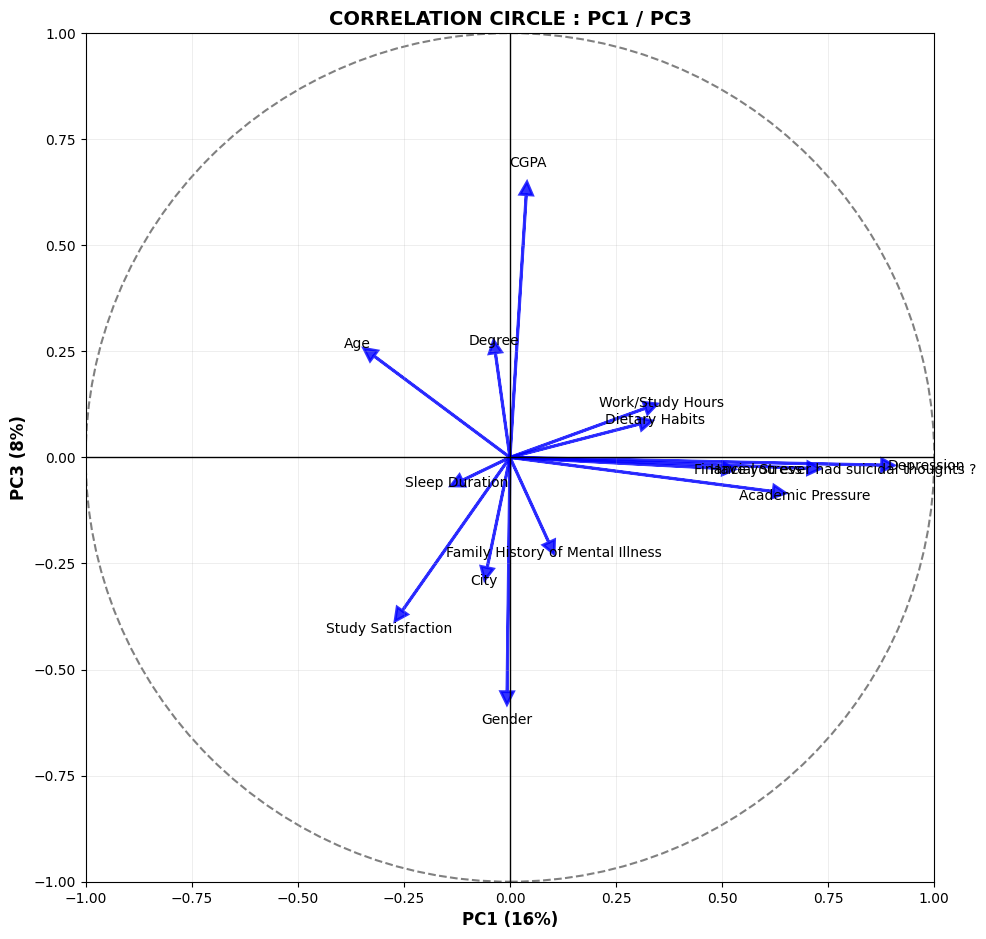

In [ ]:
#  CERCLE DE CORRÉLATION : PC1 / PC3

fig, ax = plt.subplots(figsize=(10, 10))

# Cercle unité
circle = plt.Circle((0, 0), 1, fill=False, color='gray', linestyle='--', linewidth=1.5)
ax.add_artist(circle)

# Flèches des variables (loadings)
for i, var in enumerate(X_pca.columns):
    ax.arrow(0, 0, loadings[i, 0], loadings[i, 2],  # PC1 et PC3
             head_width=0.03, head_length=0.03,
             fc='blue', ec='blue', alpha=0.8, linewidth=2)

    # Position du texte légèrement décalée
    text_x = loadings[i, 0] * 1.12
    text_y = loadings[i, 2] * 1.12
    ax.text(text_x, text_y, var, fontsize=10, ha='center', va='center', color='black')

# Axes et mise en forme
ax.set_xlim(-1.0, 1.0)
ax.set_ylim(-1.0, 1.0)
ax.set_xlabel(f'PC1 ({variance_explained[0]*100:.0f}%)', fontsize=12, fontweight='bold')
ax.set_ylabel(f'PC3 ({variance_explained[2]*100:.0f}%)', fontsize=12, fontweight='bold')
ax.set_title('CORRELATION CIRCLE : PC1 / PC3', fontsize=14, fontweight='bold')

ax.grid(True, alpha=0.3, linestyle='-', linewidth=0.5)
ax.axhline(y=0, color='black', linewidth=1)
ax.axvline(x=0, color='black', linewidth=1)
ax.set_aspect('equal', adjustable='box')

plt.tight_layout()
plt.show()


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<!DOCTYPE html>
<html lang="en">
<head>
<meta charset="UTF-8">
<meta name="viewport" content="width=device-width, initial-scale=1.0">
<style>
.pca-interpretation {
  background: linear-gradient(135deg, #f9f9ff, #f2f7ff);
  border-left: 4px solid #1f77b4;
  border-radius: 8px;
  padding: 20px 24px;
  margin: 16px 0;
  box-shadow: 0 2px 8px rgba(0,0,0,0.08);
  font-family: 'Arial', sans-serif;
}
.pca-interpretation h2 {
  color: #2e3192;
  margin-bottom: 15px;
  font-size: 24px;
}
.pca-interpretation h3 {
  color: #4a90e2;
  margin-top: 20px;
  margin-bottom: 10px;
  font-size: 18px;
}
.pca-interpretation p {
  font-size: 15px;
  margin-bottom: 12px;
}
.pca-interpretation ul {
  margin-top: 10px;
  margin-bottom: 15px;
  padding-left: 25px;
}
.pca-interpretation li {
  margin-bottom: 8px;
}
.highlight-box {
  background: #fff;
  border-radius: 8px;
  padding: 15px;
  margin: 15px 0;
  box-shadow: 0 1px 5px rgba(0,0,0,0.05);
}
.correlation-badge {
  display: inline-block;
  padding: 3px 10px;
  border-radius: 15px;
  font-size: 13px;
  font-weight: bold;
  margin: 2px;
}
.positive {
  background: #ffebee;
  color: #c62828;
}
.negative {
  background: #e8f5e9;
  color: #2e7d32;
}
.neutral {
  background: #fff3e0;
  color: #ef6c00;
}
</style>
</head>
<body>

<div class="pca-interpretation">

<h2> PCA Correlation Circle (PC1-PC3) - Interpretation</h2>

<div class="highlight-box">
<ul>
<li><strong>Horizontal axis (PC1):</strong> Primary dimension capturing the stress-mental health spectrum.</li>
<li><strong>Vertical axis (PC3):</strong> Third principal component revealing additional patterns.</li>
<li><strong>Correlation circle :</strong> Variables near the circle edge are well represented by PC1 and PC3.</li>
</ul>
</div>

<h3> Strong Positive Correlations (arrows point same direction)</h3>

<div class="highlight-box">
<ul>
<li><strong>Depression, Suicidal Thoughts & Academic Pressure:</strong> Extremely tightly clustered on the far right — these are nearly identical in their relationship to PC1. Students experiencing depression almost always face suicidal thoughts and high academic pressure.</li>
<li><strong>Financial Stress, Work/Study Hours, Dietary Habits:</strong> Also cluster on the right side, showing these stressors co-occur with mental health issues.</li>
</ul>
</div>

<h3> Negative Correlations (arrows point opposite directions)</h3>

<div class="highlight-box">
<ul>
<li><strong>Study Satisfaction:</strong> Points to the lower-left, directly opposite to the mental health crisis cluster — students satisfied with their studies have significantly fewer mental health problems.</li>
<li><strong>Sleep Duration & Family History:</strong> Point leftward, inversely related to depression and stress factors on the right.</li>
</ul>
</div>

<h3>PC3-Specific Patterns (vertical dimension)</h3>

<div class="highlight-box">
<ul>
<li><strong>Age & Degree:</strong> Point straight upward on PC3, capturing variance related to educational level and maturity — independent of the mental health axis.</li>
<li><strong>CGPA:</strong> Points upward near the center, showing PC3 captures some academic performance variance not explained by PC1.</li>
<li><strong>Gender:</strong> Points downward on PC3, representing gender-related variance in a dimension separate from stress and mental health.</li>
<li><strong>Study Satisfaction:</strong> Has a downward component on PC3, aligning with Gender in this dimension.</li>
</ul>
</div>

<h3> Variable Quality of Representation</h3>

<div class="highlight-box">
<ul>
<li><strong>Excellently represented (very close to circle):</strong> Depression, Suicidal Thoughts, Academic Pressure, Financial Stress — these are captured almost perfectly by PC1 and PC3 together.</li>
<li><strong>Well represented:</strong> Study Satisfaction, Age, Degree, Gender, Work/Study Hours, Dietary Habits.</li>
<li><strong>Moderately represented:</strong> Sleep Duration, Family History (shorter arrows, further from circle edge).</li>
</ul>
</div>

</div>

</div>

</body>
</html>
"""

display(HTML(html_content))


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15), 0 2px 4px rgba(0,0,0,0.12), 0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 12px;
        padding-bottom: 10px;
        font-size: 28px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
 PROJECTION OF INDIVIDUALS MAP</h2>
</div>
"""

display(HTML(html_content))


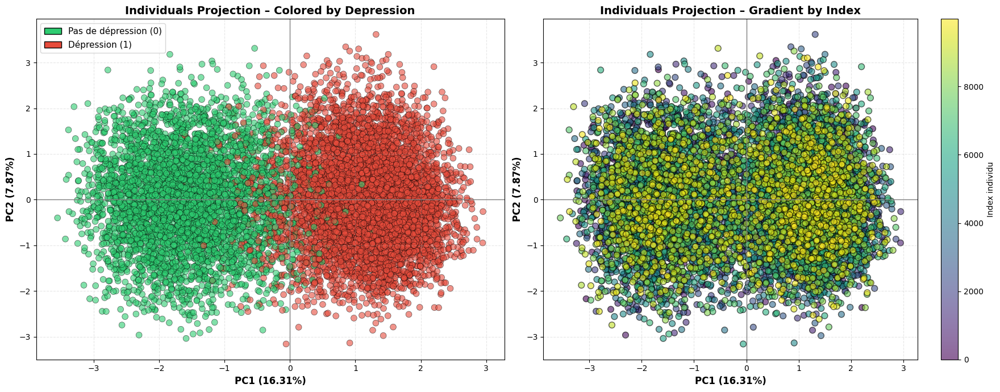

In [ ]:


pca_df = pd.DataFrame({
    'PC1': X_pca_transformed[:, 0],
    'PC2': X_pca_transformed[:, 1]
})

if 'Depression' in df.columns:
    pca_df['Depression'] = df['Depression'].values

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

if 'Depression' in pca_df.columns:
    colors = ['#2ecc71' if d == 0 else '#e74c3c' for d in pca_df['Depression']]

    axes[0].scatter(pca_df['PC1'], pca_df['PC2'],
                   c=colors, alpha=0.6, edgecolors='black', s=60, linewidths=0.5)

    from matplotlib.patches import Patch
    legend_elements = [
        Patch(facecolor='#2ecc71', edgecolor='black', label='Pas de dépression (0)'),
        Patch(facecolor='#e74c3c', edgecolor='black', label='Dépression (1)')
    ]
    axes[0].legend(handles=legend_elements, loc='best', fontsize=11)
else:
    axes[0].scatter(pca_df['PC1'], pca_df['PC2'],
                   alpha=0.6, edgecolors='black', s=60, c='steelblue')

axes[0].set_xlabel(f'PC1 ({variance_explained[0]*100:.2f}%)',
                  fontsize=12, fontweight='bold')
axes[0].set_ylabel(f'PC2 ({variance_explained[1]*100:.2f}%)',
                  fontsize=12, fontweight='bold')
axes[0].set_title('Individuals Projection – Colored by Depression',
                 fontsize=14, fontweight='bold')
axes[0].grid(alpha=0.3, linestyle='--')
axes[0].axhline(y=0, color='grey', linewidth=1)
axes[0].axvline(x=0, color='grey', linewidth=1)

scatter2 = axes[1].scatter(pca_df['PC1'], pca_df['PC2'],
                          c=range(len(pca_df)), cmap='viridis',
                          alpha=0.6, edgecolors='black', s=60)
axes[1].set_xlabel(f'PC1 ({variance_explained[0]*100:.2f}%)',
                  fontsize=12, fontweight='bold')
axes[1].set_ylabel(f'PC2 ({variance_explained[1]*100:.2f}%)',
                  fontsize=12, fontweight='bold')
axes[1].set_title('Individuals Projection – Gradient by Index',
                 fontsize=14, fontweight='bold')
axes[1].grid(alpha=0.3, linestyle='--')
axes[1].axhline(y=0, color='grey', linewidth=1)
axes[1].axvline(x=0, color='grey', linewidth=1)
plt.colorbar(scatter2, ax=axes[1], label='Index individu')

plt.tight_layout()
plt.show()

In [ ]:
# @title
from IPython.display import display, HTML

html_interpretation_short = """
<style>
.pca-interpretation {
  font-family: 'Segoe UI', Roboto, sans-serif;
  background: linear-gradient(135deg, #f9f9ff, #f2f7ff);
  border-left: 6px solid #4a90e2;
  padding: 25px 35px;
  border-radius: 10px;
  box-shadow: 0 2px 10px rgba(0,0,0,0.08);
  line-height: 1.7;
  color: #333;
}
.pca-interpretation h2 {
  color: #2e3192;
  margin-bottom: 15px;
}
.pca-interpretation p {
  font-size: 15px;
  margin-bottom: 8px;
}
</style>

<div class="pca-interpretation">
<h2> PCA Interpretation</h2>

<p>
Shows the position of individuals in the PCA:
</p>

<ul>
<li><strong style="color:#2ca02c;">Left plot:</strong> Shows individuals colored by depression status
(<span style="color:#2ca02c;">green = no depression</span>,
<span style="color:#d62728;">red = depression</span>) to visualize group separation.</li>
<li><strong style="color:#1f77b4;">Right plot:</strong> Uses a gradient to show the overall distribution of individuals.</li>
</ul>

<p>
💡 <strong>Insight:</strong> The two plots complement each other — one focuses on class separation, while the other reveals the overall data structure in PCA space.
</p>
</div>
"""

display(HTML(html_interpretation_short))


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15), 0 2px 4px rgba(0,0,0,0.12), 0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 12px;
        padding-bottom: 10px;
        font-size: 28px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
 COMPARISON: PC1-PC2 VS PC1-PC3 </h2>
</div>
"""

display(HTML(html_content))


 VISUAL COMPARISON : PC1–PC2 vs PC1–PC3


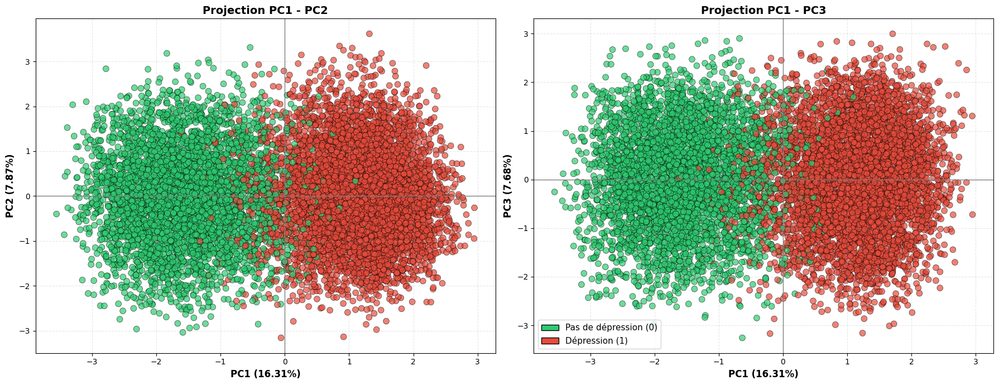

In [ ]:
print(" VISUAL COMPARISON : PC1–PC2 vs PC1–PC3")

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

if 'Depression' in pca_df.columns:
    colors = ['#2ecc71' if d == 0 else '#e74c3c' for d in pca_df['Depression']]
else:
    colors = 'steelblue'

axes[0].scatter(
    pca_df['PC1'], pca_df['PC2'],
    c=colors, alpha=0.7, edgecolors='black', s=60, linewidths=0.5
)
axes[0].set_xlabel(f'PC1 ({variance_explained[0]*100:.2f}%)', fontsize=12, fontweight='bold')
axes[0].set_ylabel(f'PC2 ({variance_explained[1]*100:.2f}%)', fontsize=12, fontweight='bold')
axes[0].set_title('Projection PC1 - PC2', fontsize=14, fontweight='bold')
axes[0].grid(alpha=0.3, linestyle='--')
axes[0].axhline(y=0, color='grey', linewidth=1)
axes[0].axvline(x=0, color='grey', linewidth=1)


axes[1].scatter(
    pca_df['PC1'], X_pca_transformed[:, 2],
    c=colors, alpha=0.7, edgecolors='black', s=60, linewidths=0.5
)
axes[1].set_xlabel(f'PC1 ({variance_explained[0]*100:.2f}%)', fontsize=12, fontweight='bold')
axes[1].set_ylabel(f'PC3 ({variance_explained[2]*100:.2f}%)', fontsize=12, fontweight='bold')
axes[1].set_title('Projection PC1 - PC3', fontsize=14, fontweight='bold')
axes[1].grid(alpha=0.3, linestyle='--')
axes[1].axhline(y=0, color='grey', linewidth=1)
axes[1].axvline(x=0, color='grey', linewidth=1)

if 'Depression' in pca_df.columns:
    from matplotlib.patches import Patch
    legend_elements = [
        Patch(facecolor='#2ecc71', edgecolor='black', label='Pas de dépression (0)'),
        Patch(facecolor='#e74c3c', edgecolor='black', label='Dépression (1)')
    ]
    axes[1].legend(handles=legend_elements, loc='best', fontsize=11)

plt.tight_layout()
plt.show()


In [ ]:
# @title
from IPython.display import HTML, display

html_interpretation = """
<style>
.pca-interpretation {
  font-family: 'Segoe UI', Roboto, sans-serif;
  background: linear-gradient(135deg, #f9f9ff, #f2f7ff);
  border-left: 6px solid #4a90e2;
  padding: 25px 35px;
  border-radius: 10px;
  box-shadow: 0 2px 10px rgba(0,0,0,0.08);
  line-height: 1.7;
  color: #333;
}
.pca-interpretation h2 {
  color: #2e3192;
  margin-bottom: 15px;
}
.pca-interpretation h3 {
  color: #4a90e2;
  margin-top: 20px;
  margin-bottom: 10px;
}
.pca-interpretation p {
  font-size: 15px;
  margin-bottom: 8px;
}
.pca-interpretation ul {
  margin-top: 10px;
  margin-bottom: 10px;
}
.pca-interpretation li {
  margin-bottom: 6px;
}
</style>

<div class="pca-interpretation">

<h2> PCA Interpretation — Visual and Statistical Insights</h2>

<h3> Visual Comparison — PC1–PC2 vs PC1–PC3</h3>
<ul>
<li><strong>Both plots show the same pattern :</strong> Clear separation between <span style="color:green;font-weight:bold;">No Depression</span> and <span style="color:red;font-weight:bold;">Depression</span> groups.</li>
<li><strong>PC1</strong> captures most of the depression-related variation — it’s the main axis distinguishing the two classes.</li>
<li><strong>PC2</strong> adds a small spread but doesn’t significantly improve separation.</li>
<li><strong>PC3</strong> adds little information; most variation is unrelated to depression.</li>
</ul>

<hr style="border: none; border-top: 2px dashed #ccc; margin: 20px 0;">

<h3> Correlation Circles — Variable Relationships</h3>
<ul>
<li>In <strong>PC1–PC2 :</strong> the arrows <em>Depression</em>, <em>Suicidal thoughts</em>, <em>Academic Pressure</em>, and <em>Financial Stress</em> are strongly aligned with PC1 → they share the same underlying pattern.</li>
<li>This alignment explains why <strong>PC1</strong> effectively separates students with and without depression.</li>
<li>In <strong>PC1–PC3 :</strong> PC1 still dominates, while PC3 reflects variations linked to <em>CGPA</em>, <em>Gender</em>, or <em>Study Satisfaction</em> — variables less associated with depression.</li>
</ul>

<p>  <strong> Meaning of Each Component :</strong></p>
<ul>
<li><strong>PC1 → “Depression & Stress Dimension”</strong> (Depression, Suicidal thoughts, Academic Pressure, Financial Stress)</li>
<li><strong>PC2 → “Lifestyle Dimension”</strong> (Sleep, Diet, Study Satisfaction)</li>
<li><strong>PC3 → “Demographics & Performance Dimension”</strong> (Age, CGPA, Gender)</li>
</ul>

<p> <strong>Overall Insight:</strong>
Most of the mental-health-related variance is captured by PC1.
PC2 and PC3 highlight secondary aspects such as lifestyle and academic performance,
but they do not drive the main depression pattern.</p>

</div>
"""

display(HTML(html_interpretation))


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15), 0 2px 4px rgba(0,0,0,0.12), 0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 12px;
        padding-bottom: 10px;
        font-size: 28px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
 BIPLOT (INDIVIDUALS + VARIABLES)</h2>
</div>
"""

display(HTML(html_content))


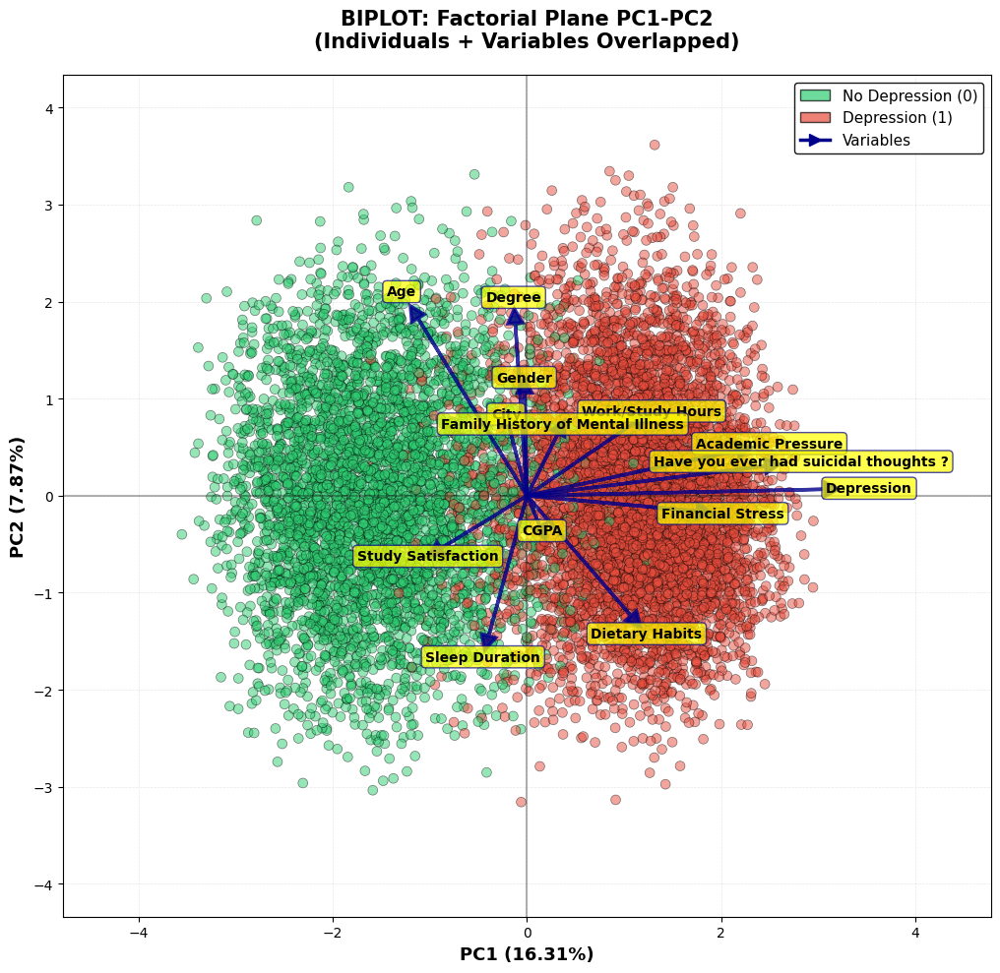

In [ ]:
scale_factor = 3.5

fig, ax = plt.subplots(figsize=(14, 10))

# 1. Plot individuals
if 'Depression' in df.columns:
    colors = ['#2ecc71' if d == 0 else '#e74c3c' for d in df['Depression'].values]
    ax.scatter(X_pca_transformed[:, 0], X_pca_transformed[:, 1],
              c=colors, alpha=0.5, edgecolors='black', s=50, linewidths=0.5)

    from matplotlib.patches import Patch
    legend_elements = [
        Patch(facecolor='#2ecc71', edgecolor='black', label='No Depression (0)', alpha=0.7),
        Patch(facecolor='#e74c3c', edgecolor='black', label='Depression (1)', alpha=0.7)
    ]
else:
    ax.scatter(X_pca_transformed[:, 0], X_pca_transformed[:, 1],
              alpha=0.5, edgecolors='black', s=50, c='steelblue')
    legend_elements = []

# 2. Plot variable vectors
for i, var in enumerate(X_pca.columns):
    x_arrow = loadings[i, 0] * scale_factor
    y_arrow = loadings[i, 1] * scale_factor

    ax.arrow(0, 0, x_arrow, y_arrow,
             head_width=0.15, head_length=0.15,
             fc='darkblue', ec='darkblue',
             linewidth=2.5, alpha=0.8, zorder=5)

    text_x = x_arrow * 1.15
    text_y = y_arrow * 1.15

    ax.text(text_x, text_y, var,
            fontsize=10, fontweight='bold',
            ha='center', va='center',
            bbox=dict(boxstyle='round,pad=0.3',
                     facecolor='yellow',
                     edgecolor='darkblue',
                     alpha=0.7),
            zorder=6)

# 3. Configuration
ax.set_xlabel(f'PC1 ({variance_explained[0]*100:.2f}%)',
             fontsize=13, fontweight='bold')
ax.set_ylabel(f'PC2 ({variance_explained[1]*100:.2f}%)',
             fontsize=13, fontweight='bold')
ax.set_title('BIPLOT: Factorial Plane PC1-PC2\n(Individuals + Variables Overlapped)',
            fontsize=15, fontweight='bold', pad=20)

ax.axhline(y=0, color='black', linewidth=1.5, linestyle='-', alpha=0.3)
ax.axvline(x=0, color='black', linewidth=1.5, linestyle='-', alpha=0.3)
ax.grid(alpha=0.3, linestyle='--', linewidth=0.5)

if legend_elements:
    from matplotlib.lines import Line2D
    legend_elements.append(Line2D([0], [0], color='darkblue', linewidth=2.5,
                                  label='Variables', marker='>', markersize=8))
    ax.legend(handles=legend_elements, loc='best', fontsize=11,
             framealpha=0.9, edgecolor='black')

# Adjust limits
margin = 1.2
x_min, x_max = X_pca_transformed[:, 0].min(), X_pca_transformed[:, 0].max()
y_min, y_max = X_pca_transformed[:, 1].min(), X_pca_transformed[:, 1].max()

var_x_max = abs(loadings[:, 0]).max() * scale_factor * 1.3
var_y_max = abs(loadings[:, 1]).max() * scale_factor * 1.3

x_limit = max(abs(x_min), abs(x_max), var_x_max) * margin
y_limit = max(abs(y_min), abs(y_max), var_y_max) * margin

ax.set_xlim(-x_limit, x_limit)
ax.set_ylim(-y_limit, y_limit)
ax.set_aspect('equal', adjustable='box')

plt.tight_layout()
plt.show()


In [ ]:
# @title
from IPython.display import HTML, display

html_interpretation = """
<style>
.pca-interpretation {
  font-family: 'Segoe UI', Roboto, sans-serif;
  background: linear-gradient(135deg, #f9f9ff, #f2f7ff);
  border-left: 6px solid #4a90e2;
  padding: 25px 35px;
  border-radius: 10px;
  box-shadow: 0 2px 10px rgba(0,0,0,0.08);
  line-height: 1.7;
  color: #333;
}
.pca-interpretation h2 {
  color: #2e3192;
  margin-bottom: 15px;
}
.pca-interpretation h3 {
  color: #4a90e2;
  margin-top: 20px;
  margin-bottom: 10px;
}
.pca-interpretation p {
  font-size: 15px;
  margin-bottom: 8px;
}
.pca-interpretation ul {
  margin-top: 10px;
  margin-bottom: 10px;
}
.pca-interpretation li {
  margin-bottom: 6px;
}
</style>

<div class="pca-interpretation">

<h2> PCA Interpretation — General Overview</h2>
<p>The plot shows two main groups of students:</p>
<ul>
<li><span style="color:green;font-weight:bold;">🟩 Green (0):</span> Students without depression</li>
<li><span style="color:red;font-weight:bold;">🟥 Red (1):</span> Students with depression</li>
</ul>

<h3> Interpretation</h3>
<ul>
<li><strong>Separation of Groups:</strong> The plot shows a clear distinction between students with and without depression, indicating that the selected features explain part of the variance linked to depression risk.</li>
<li><strong>Right Side (Red Cluster – Depression group):</strong> Variables such as <em>Depression</em>, <em>Have you ever had suicidal thoughts?</em>, <em>Financial Stress</em>, <em>Academic Pressure</em>, and <em>Work/Study Hours</em> point toward this area, meaning higher values of these factors are positively associated with depression.</li>
<li><strong>Left Side (Green Cluster – No depression group):</strong> Variables like <em>Study Satisfaction</em>, <em>Sleep Duration</em>, and <em>CGPA</em> are oriented toward this side, indicating that better sleep, higher satisfaction, and higher academic performance are negatively correlated with depression (protective factors).</li>
<li><strong>Central Variables:</strong> <em>Family History of Mental Illness</em>, <em>Age</em>, <em>City</em>, and <em>Degree</em> are closer to the center — they contribute less to separating the two groups in the first two components.</li>
</ul>

</div>
"""

display(HTML(html_interpretation))


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15), 0 2px 4px rgba(0,0,0,0.12), 0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 12px;
        padding-bottom: 10px;
        font-size: 28px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
 DIMENSION REDUCTION</h2>
</div>
"""

display(HTML(html_content))


In [ ]:


# Appliquer PCA avec le nombre optimal de composantes
n_components_final = n_components_80
pca_final = PCA(n_components=n_components_final)
X_pca_reduced = pca_final.fit_transform(df_scaled)

print(f"Dimensions: {df_scaled.shape[1]} → {n_components_final}")
print(f"Variance totale conservée: {sum(pca_final.explained_variance_ratio_)*100:.2f}%")

# Créer un DataFrame réduit
df_pca_reduced = pd.DataFrame(
    X_pca_reduced,
    columns=[f'PC{i+1}' for i in range(n_components_final)]
)

if 'Depression' in df.columns:
    df_pca_reduced['Depression'] = df['Depression'].values

print("\nAperçu du dataset réduit:")
print(df_pca_reduced.head())

Dimensions: 14 → 10
Variance totale conservée: 80.35%

Aperçu du dataset réduit:
        PC1       PC2       PC3       PC4       PC5       PC6       PC7  \
0  1.820125  0.095852 -0.995990 -0.768045  0.576610  2.629212  1.416654   
1  0.767952  0.764051  0.274539 -0.668821 -0.731298 -0.599319  0.266005   
2  0.274590  1.128822  1.852812  0.383349 -0.130006  0.778262 -0.381915   
3  1.045026  0.071662  1.040148  0.813320 -1.314154 -0.329416  1.497199   
4 -1.495029  1.127322  0.359581  0.102391 -0.433345 -1.531612 -0.770093   

        PC8       PC9      PC10  Depression  
0 -1.580847  0.545258 -0.154420           1  
1 -1.268181  0.887735  0.886790           1  
2  1.743304  0.578552  0.514152           1  
3 -0.496987 -1.345960 -0.952465           1  
4 -0.532030  2.017304  0.453671           0  


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(135deg, #f8f9fa 0%, #ffffff 100%);
    border-left: 4px solid #4A90E2;
    border-radius: 8px;
    padding: 20px 24px;
    margin: 16px 0;
    box-shadow: 0 2px 8px rgba(0,0,0,0.08);
    font-family: 'Arial', sans-serif;
">
    <div style="
        display: flex;
        align-items: center;
        margin-bottom: 12px;
    ">
        <span style="
            background: #4A90E2;
            color: white;
            padding: 4px 12px;
            border-radius: 4px;
            font-size: 14px;
            font-weight: 600;
            letter-spacing: 0.5px;
        ">interpretation</span>
    </div>

    <p style="
        margin: 0;
        color: #2c3e50;
        font-size: 15px;
        line-height: 1.6;
    ">

Applies PCA to reduce the dataset to the optimal number of components :

* Reduces dimensionality while retaining most of the information.

    </p>
</div>
"""

display(HTML(html_content))

In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<style>
@keyframes float {
  0% { transform: translateY(0px); }
  50% { transform: translateY(-5px); }
  100% { transform: translateY(0px); }
}

@keyframes glow {
  0%,100% { box-shadow: 0 4px 10px rgba(106,5,114,0.25), inset 0 0 4px rgba(106,5,114,0.2); }
  50% { box-shadow: 0 8px 18px rgba(78,205,196,0.35), inset 0 0 6px rgba(78,205,196,0.25); }
}

@keyframes gradientShift {
  0% { background-position: 0% 50%; }
  50% { background-position: 100% 50%; }
  100% { background-position: 0% 50%; }
}
</style>

<div style="
    width: 95%;
    max-width: 900px;
    margin: 30px auto;
    background: linear-gradient(135deg, rgba(255,255,255,0.96), rgba(250,250,255,0.98));
    border-radius: 16px;
    border: 1px solid rgba(106,5,114,0.3);
    animation: float 5s ease-in-out infinite, glow 4s ease-in-out infinite;
    box-shadow: 0 6px 18px rgba(0,0,0,0.15);
    overflow: hidden;
    position: relative;
">

<!-- bande colorée animée -->
<div style="
    position: absolute;
    top: 0;
    left: 0;
    width: 100%;
    height: 6px;
    background: linear-gradient(90deg, #6a0572, #4ecdc4, #ffd166, #6a0572);
    background-size: 300% 300%;
    animation: gradientShift 8s ease infinite;
"></div>

<!-- décor bas droit -->
<div style="
    position: absolute;
    bottom: 0;
    right: 0;
    width: 120px;
    height: 120px;
    background: radial-gradient(circle at bottom right, rgba(106,5,114,0.3) 0%, transparent 70%);
    opacity: 0.4;
"></div>

<h2 style="
    font-family: 'Poppins', sans-serif;
    font-weight: 600;
    color: #6a0572;
    text-align: center;
    margin: 20px 0 10px 0;
    font-size: 30px;
    letter-spacing: 1px;
">
OBJ 1
</h2>

<hr style="
    width: 60%;
    margin: 0 auto 16px auto;
    border: none;
    height: 2px;
    background: linear-gradient(to right, rgba(106,5,114,0.6), rgba(78,205,196,0.6));
">

<p style="
    text-align: center;
    font-family: 'Open Sans', sans-serif;
    color: #333;
    font-size: 17px;
    line-height: 1.6;
    padding: 0 40px 20px 40px;
">

</div>
"""

display(HTML(html_content))


In [ ]:
# @title
html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15), 0 2px 4px rgba(0,0,0,0.12), 0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 20px;
    margin: 15px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 100px;
        height: 100px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<div style="
        position: absolute;
        bottom: 15px;
        left: 15px;
        width: 50px;
        height: 50px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h3 style="
        margin-top: 0;
        margin-bottom: 10px;
        padding-bottom: 8px;
        font-size: 20px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
DSO1: Construct an unsupervised clustering model to segment students into homogeneous groups, then characterize each cluster by its dominant attributes for easier interpretation and targeted actions.


</h3>
</div>
"""

display(HTML(html_content))

In [ ]:
# @title
gif_url = "https://health.gov.tt/sites/default/files/2024-12/Suicide-AWPostImage%20%281%29.gif"

display(HTML(f'''
<div style="text-align: center;">
    <img src="{gif_url}" width="500">
</div>
'''))


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15), 0 2px 4px rgba(0,0,0,0.12), 0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 12px;
        padding-bottom: 10px;
        font-size: 28px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
 K-MEANS</h2>
</div>
"""

display(HTML(html_content))


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15), 0 2px 4px rgba(0,0,0,0.12), 0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 12px;
        padding-bottom: 10px;
        font-size: 28px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
Choose k via elbow & silhouette</h2>
</div>
"""

display(HTML(html_content))


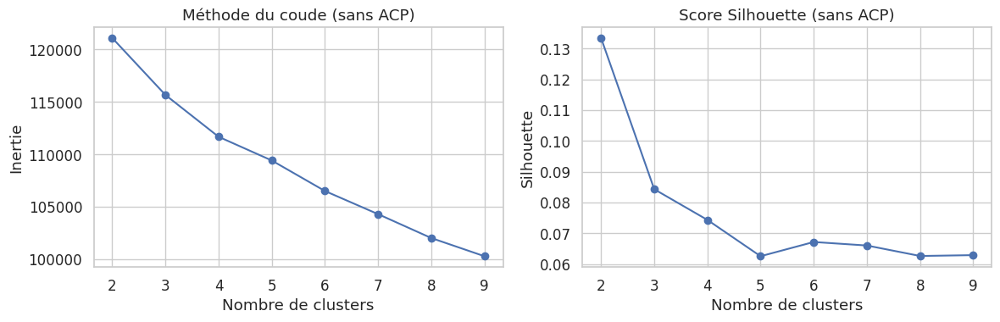

→ k optimal (silhouette) = 2 | silhouette = 0.133


In [ ]:
sns.set(style="whitegrid", font_scale=1.1)

# Optional config
RISK_COL = "Have you ever had suicidal thoughts ?"
KEY_VARS  = ["Depression", "Financial Stress", "Academic Pressure", RISK_COL]

k_range = range(2, 10)
inertia, sil = [], []

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42)
    labels_k = km.fit_predict(df_scaled)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(df_scaled, labels_k))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(list(k_range), inertia, 'o-')
ax[0].set_title("Méthode du coude (sans ACP)")
ax[0].set_xlabel("Nombre de clusters"); ax[0].set_ylabel("Inertie")

ax[1].plot(list(k_range), sil, 'o-')
ax[1].set_title("Score Silhouette (sans ACP)")
ax[1].set_xlabel("Nombre de clusters"); ax[1].set_ylabel("Silhouette")

plt.tight_layout(); plt.show()

best_k = list(k_range)[int(np.argmax(sil))]
print(f"→ k optimal (silhouette) = {best_k} | silhouette = {max(sil):.3f}")


Final KMeans on original space

In [ ]:
kmeans = KMeans(n_clusters=best_k, random_state=42)
labels = kmeans.fit_predict(df_scaled)
sil_final = silhouette_score(df_scaled, labels)
print(f"Silhouette (sans ACP) = {sil_final:.3f}")

Silhouette (sans ACP) = 0.133


 PCA (for visualization) + 2D cluster scatter

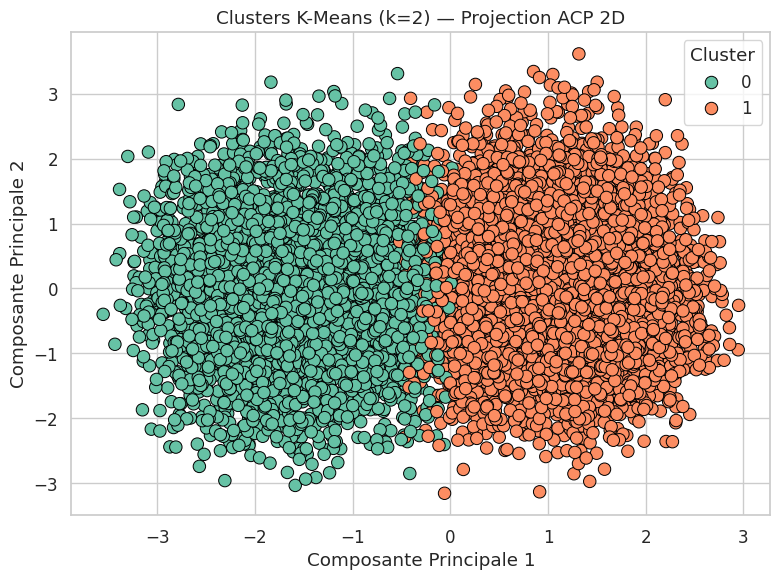

In [ ]:

X2 = X_pca_transformed.copy()

plt.figure(figsize=(8, 6))
sns.scatterplot(x=X2[:, 0], y=X2[:, 1], hue=labels, palette="Set2",
                s=80, edgecolor="black")
plt.title(f"Clusters K-Means (k={best_k}) — Projection ACP 2D")
plt.xlabel("Composante Principale 1"); plt.ylabel("Composante Principale 2")
plt.legend(title="Cluster")
plt.tight_layout(); plt.show()

Attach labels & cluster profile heatmap


Moyenne par cluster :
           Gender        Age       City  Academic Pressure      CGPA  \
Cluster                                                                
0        0.443363  27.279506  15.527428           2.327951  7.597499   
1        0.442384  24.846474  14.765379           3.765552  7.694222   

         Study Satisfaction  Sleep Duration  Dietary Habits     Degree  \
Cluster                                                                  
0                  3.212776        6.648302        1.138209  11.010449   
1                  2.725524        6.374112        1.675100  10.812338   

         Have you ever had suicidal thoughts ?  Work/Study Hours  \
Cluster                                                            
0                                     0.295179          6.160532   
1                                     0.876798          7.844741   

         Financial Stress  Family History of Mental Illness  Depression  
Cluster                                     

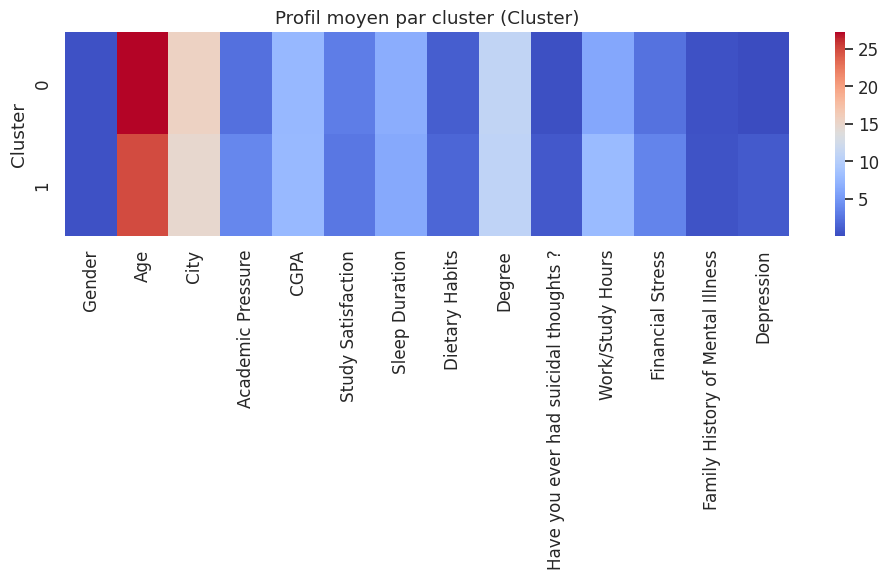

In [ ]:
df_result = df_num.copy()
df_result["Cluster"] = labels

profiles = df_result.groupby("Cluster").mean(numeric_only=True)
print("\nMoyenne par cluster :")
print(profiles)

plt.figure(figsize=(10, 6))
sns.heatmap(profiles, cmap="coolwarm", annot=False)
plt.title("Profil moyen par cluster (Cluster)")
plt.tight_layout(); plt.show()

 risk labeling by mean of RISK_COL


Clusters annotés avec niveaux de risque :
   Cluster  Risque
0        1   Moyen
1        1   Moyen
2        1   Moyen
3        1   Moyen
4        0  Faible


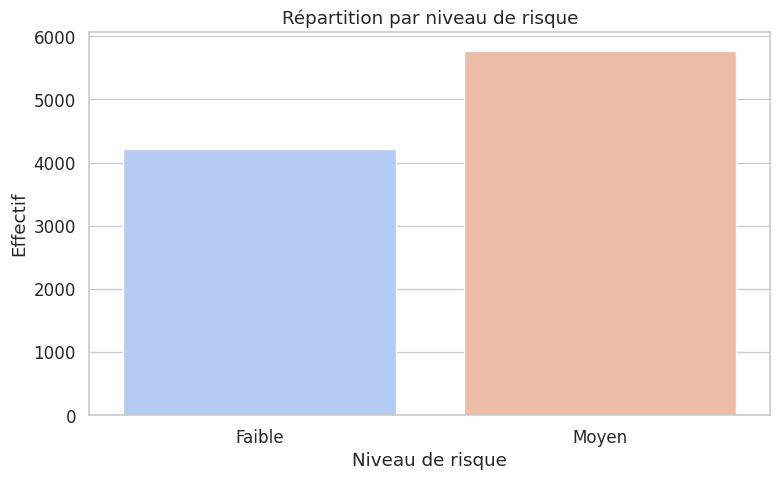

In [ ]:
risk_labels = None
if (RISK_COL is not None) and (RISK_COL in df_result.columns):
    risk_means = df_result.groupby("Cluster")[RISK_COL].mean()
    order = risk_means.sort_values().index  # low → high risk

    base_levels = ["Faible", "Moyen", "Élevé", "Très Élevé", "Extrême"]
    risk_labels = {cl: (base_levels[i] if i < len(base_levels) else f"Niveau {i+1}")
                   for i, cl in enumerate(order)}

    df_result["Risque"] = df_result["Cluster"].map(risk_labels)

    print("\nClusters annotés avec niveaux de risque :")
    print(df_result[["Cluster", "Risque"]].head())

    plt.figure(figsize=(8, 5))
    sns.countplot(
        x="Risque",
        data=df_result,
        order=[risk_labels[c] for c in order],
        palette="coolwarm"
    )
    plt.title("Répartition par niveau de risque")
    plt.xlabel("Niveau de risque"); plt.ylabel("Effectif")
    plt.tight_layout(); plt.show()
else:
    print("Colonne de risque introuvable ou non fournie — étape ignorée.")

In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15), 0 2px 4px rgba(0,0,0,0.12), 0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 12px;
        padding-bottom: 10px;
        font-size: 28px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
 DBSCAN</h2>
</div>
"""

display(HTML(html_content))


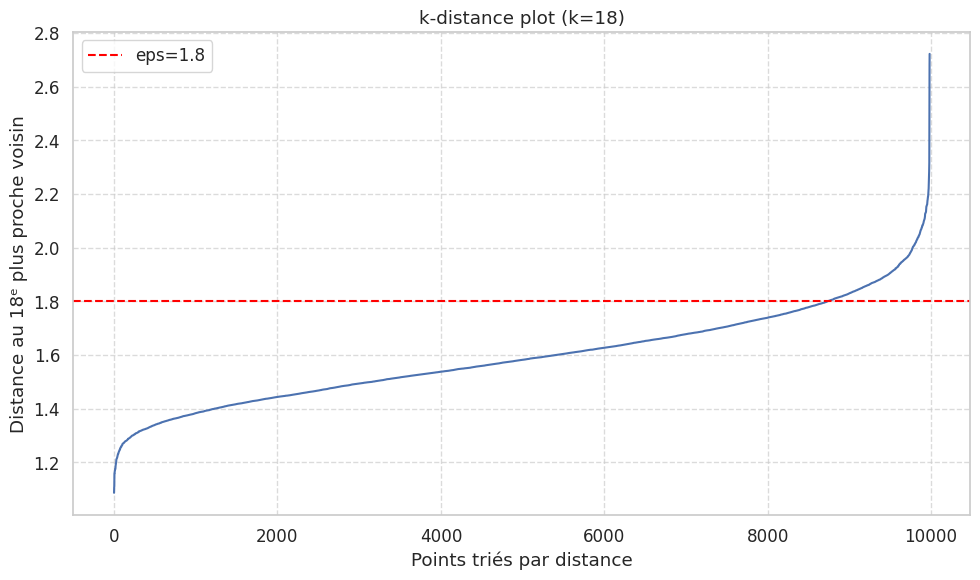


Nombre de clusters trouvés : 2
Nombre de points de bruit : 19
Distribution des clusters : [5170 4793]


In [ ]:
min_samples = 18
clustering_features = [
    'Academic Pressure',
    'Sleep Duration',
    'Financial Stress',
    'Work/Study Hours',
    'Family History of Mental Illness',
    'CGPA',
    'Study Satisfaction',
    'Dietary Habits',
    'Age'

]


missing_cols = [col for col in clustering_features if col not in df_scaled.columns]
if missing_cols:
    raise ValueError(f"Colonnes manquantes dans df_scaled : {missing_cols}")


X = df_scaled[clustering_features].copy()


nbrs = NearestNeighbors(n_neighbors=min_samples)
nbrs.fit(X)
k_dists, _ = nbrs.kneighbors(X)
k_dists = np.sort(k_dists[:, -1])

plt.figure(figsize=(10, 6))
plt.plot(k_dists)
plt.title(f"k-distance plot (k={min_samples})")
plt.xlabel("Points triés par distance")
plt.ylabel(f"Distance au {min_samples}ᵉ plus proche voisin")
plt.grid(True, linestyle="--", alpha=0.7)


eps_optimal = 1.8
plt.axhline(y=eps_optimal, color='red', linestyle='--', label=f'eps={eps_optimal}')
plt.legend()
plt.tight_layout()
plt.show()


dbscan = DBSCAN(eps=eps_optimal, min_samples=min_samples)
clusters = dbscan.fit_predict(X)

n_clusters = len(set(clusters)) - (1 if -1 in clusters else 0)
n_noise = list(clusters).count(-1)

print(f"\nNombre de clusters trouvés : {n_clusters}")
print(f"Nombre de points de bruit : {n_noise}")


if np.any(clusters >= 0):
    print(f"Distribution des clusters : {np.bincount(clusters[clusters >= 0])}")
else:
    print("Aucun cluster trouvé (tous les points sont du bruit).")


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15), 0 2px 4px rgba(0,0,0,0.12), 0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<!-- Décor coin violet -->
<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<!-- Décor points jaune -->
<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 12px;
        padding-bottom: 10px;
        font-size: 28px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
 Interpretation
</h2>

<p style="
        margin: 0;
        color: #2c3e50;
        font-size: 16px;
        line-height: 1.65;
        z-index: 2;
        position: relative;
    ">
 <b>min_samples</b> is chosen  according to the empirical rule:<br>
min_samples = (dataset dimension × 2) = 9 × 2 = <b>18</b>.<br><br>

The value <b>eps = 1.6</b> is the optimal choice because:<br>
• It corresponds to the <b>elbow</b> of the k-distance plot.<br>
• It <b>separates clusters from noise</b> clearly.<br>
• It produces a <b>stable and meaningful clustering result</b> in DBSCAN.
</p>

</div>
"""

display(HTML(html_content))


In [ ]:
#Application de DBSCAN
eps = 1.8
min_samples = 18

db = DBSCAN(eps=eps, min_samples=min_samples)
labels = db.fit_predict(X)

unique_labels = np.unique(labels)


n_clusters = len(set(labels)) - (1 if -1 in labels else 0)

n_noise = int(np.sum(labels == -1))


print("les clusters detectés (avec le cluster des points bruits):",unique_labels)
print("les clusters de chaque observation:", labels)

les clusters detectés (avec le cluster des points bruits): [-1  0  1]
les clusters de chaque observation: [1 0 1 ... 0 0 1]


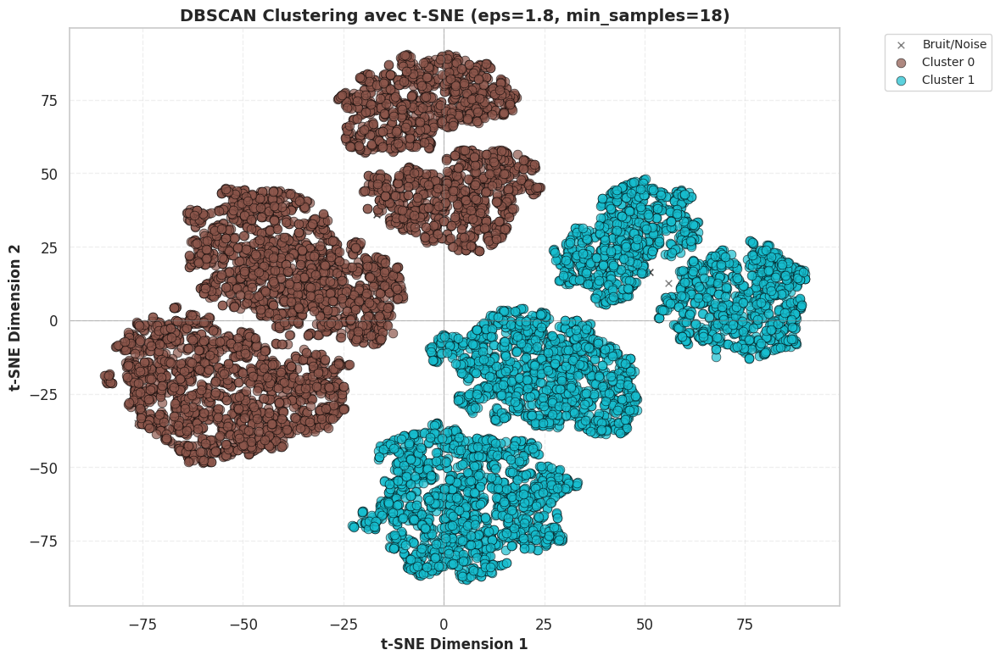

In [ ]:
from sklearn.manifold import TSNE

# Appliquer t-SNE sur les features de clustering
tsne = TSNE(n_components=2, random_state=42, perplexity=30)
X_2D = tsne.fit_transform(X)

plt.figure(figsize=(12, 8))

colors = plt.cm.tab10(np.linspace(0, 1, len(unique_labels)))

for color, label in zip(colors, unique_labels):
    mask = clusters == label
    if label == -1:
        plt.scatter(X_2D[mask, 0], X_2D[mask, 1],
                    s=30, c='black', marker='x',
                    label='Bruit/Noise', alpha=0.5, linewidths=1)
    else:
        plt.scatter(X_2D[mask, 0], X_2D[mask, 1],
                    s=60, c=[color], edgecolor='black',
                    label=f'Cluster {label}', alpha=0.7, linewidths=0.5)

plt.title(f"DBSCAN Clustering avec t-SNE (eps={eps}, min_samples={min_samples})",
          fontsize=14, fontweight='bold')
plt.xlabel('t-SNE Dimension 1', fontsize=12, fontweight='bold')
plt.ylabel('t-SNE Dimension 2', fontsize=12, fontweight='bold')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=10)
plt.grid(True, alpha=0.3, linestyle='--')
plt.axhline(y=0, color='grey', linewidth=0.8, alpha=0.5)
plt.axvline(x=0, color='grey', linewidth=0.8, alpha=0.5)
plt.tight_layout()
plt.show()

In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15), 0 2px 4px rgba(0,0,0,0.12), 0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<!-- Décor coin violet -->
<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<!-- Décor points jaunes -->
<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 12px;
        padding-bottom: 10px;
        font-size: 28px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
 Interpretation
</h2>

<p style="
        margin: 0;
        color: #2c3e50;
        font-size: 16px;
        line-height: 1.65;
        position: relative;
        z-index: 2;
    ">
DBSCAN with <b>eps = 1.6</b> revealed two student profiles that are radically different in terms of mental health,
perfectly separated in PCA, with minimal noise — clear evidence of optimal parameter tuning and
the presence of a real underlying structure in the data.
</p>

</div>
"""

display(HTML(html_content))

In [ ]:
# --- Statistiques par cluster ---
print("\n=== Distribution des observations par cluster ===")
for label in unique_labels:
    count = np.sum(clusters == label)
    percentage = (count / len(clusters)) * 100
    cluster_name = "Bruit" if label == -1 else f"Cluster {label}"
    print(f"{cluster_name}: {count} observations ({percentage:.2f}%)")


=== Distribution des observations par cluster ===
Bruit: 19 observations (0.19%)
Cluster 0: 5170 observations (51.79%)
Cluster 1: 4793 observations (48.02%)


In [ ]:
mask_no_noise = clusters != -1
if n_clusters >= 2 and np.sum(mask_no_noise) > 0:
    sil_score = silhouette_score(X[mask_no_noise], clusters[mask_no_noise])
    print(f"\nSilhouette Score (sans bruit): {sil_score:.3f}")


Silhouette Score (sans bruit): 0.115


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15), 0 2px 4px rgba(0,0,0,0.12), 0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<!-- Décor coin violet -->
<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<!-- Décor points jaunes -->
<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 12px;
        padding-bottom: 10px;
        font-size: 28px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
 Interpretation
</h2>

<p style="
        margin: 0;
        color: #2c3e50;
        font-size: 16px;
        line-height: 1.65;
        position: relative;
        z-index: 2;
    ">
<b>Silhouette Score = 0.115</b> → <b style='color:#b30000;'>WEAK CLUSTERING</b><br><br>
The clustering structure is weak, meaning data points are poorly separated and many lie close to the decision boundaries between clusters.
</p>

</div>
"""

display(HTML(html_content))

In [ ]:
eps = 1.8

X_for_dbscan = df_pca_reduced.copy()
d =X_for_dbscan.shape[1]
print(d)
min_samples = 2 * d

11


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15), 0 2px 4px rgba(0,0,0,0.12), 0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<!-- Décor coin violet -->
<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<!-- Décor points jaunes -->
<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 12px;
        padding-bottom: 10px;
        font-size: 28px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
 Interpretation
</h2>

<p style="
        margin: 0;
        color: #2c3e50;
        font-size: 16px;
        line-height: 1.65;
        position: relative;
        z-index: 2;
    ">
 <b>min_samples</b> is selected based on the empirical rule:<br>
min_samples = dataset dimension × 2 = 11 × 2 = <b>22</b>.
</p>

</div>
"""

display(HTML(html_content))

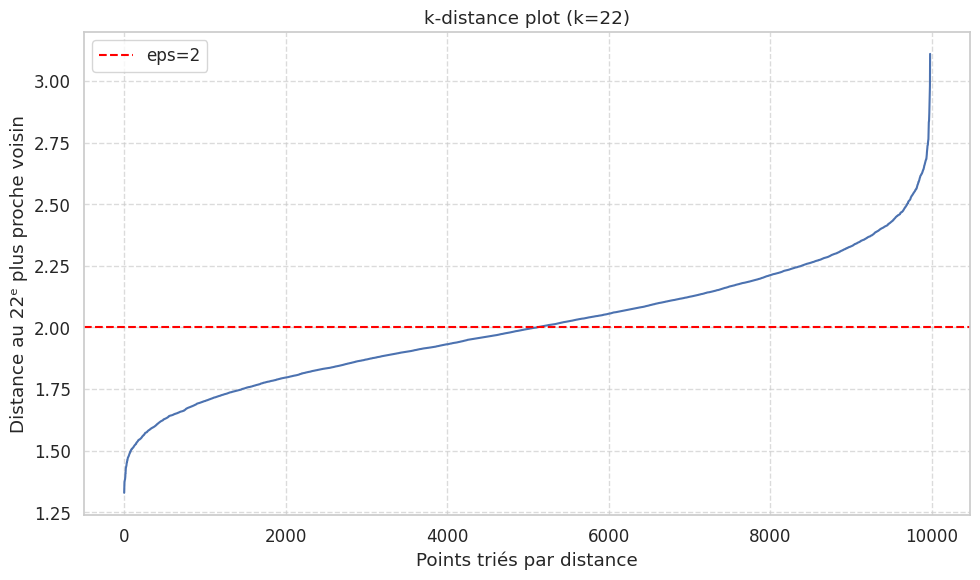


Nombre de clusters trouvés : 1
Nombre de points de bruit : 625
Distribution des clusters : [9357]


In [ ]:
min_samples = 22

nbrs = NearestNeighbors(n_neighbors=min_samples)
nbrs.fit(X_for_dbscan)
k_dists, _ = nbrs.kneighbors(X_for_dbscan)
k_dists = np.sort(k_dists[:, -1])


plt.figure(figsize=(10, 6))
plt.plot(k_dists)
plt.title(f"k-distance plot (k={min_samples})")
plt.xlabel("Points triés par distance")
plt.ylabel(f"Distance au {min_samples}ᵉ plus proche voisin")
plt.grid(True, linestyle="--", alpha=0.7)

eps_optimal = 2
plt.axhline(y=eps_optimal, color='red', linestyle='--', label=f'eps={eps_optimal}')
plt.legend()
plt.tight_layout()
plt.show()


dbscan = DBSCAN(eps=eps_optimal, min_samples=min_samples)
clusters = dbscan.fit_predict(X_for_dbscan)


n_clusters = len(set(clusters)) - (1 if -1 in clusters else 0)
n_noise = list(clusters).count(-1)

print(f"\nNombre de clusters trouvés : {n_clusters}")
print(f"Nombre de points de bruit : {n_noise}")


if np.any(clusters >= 0):
    print(f"Distribution des clusters : {np.bincount(clusters[clusters >= 0])}")
else:
    print("Aucun cluster trouvé (tous les points sont du bruit).")

In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15), 0 2px 4px rgba(0,0,0,0.12), 0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<!-- Décor coin violet -->
<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<!-- Décor points jaunes -->
<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 12px;
        padding-bottom: 10px;
        font-size: 28px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
 Interpretation
</h2>

<p style="
        margin: 0;
        color: #2c3e50;
        font-size: 16px;
        line-height: 1.65;
        position: relative;
        z-index: 2;
    ">
Using the elbow method, an <b>eps = 2</b> resulted in a <b>single cluster</b>.<br><br>
This outcome clearly indicates that <b>PCA is inappropriate</b> in this context, as it
<b>deteriorates the natural cluster structure</b> instead of enhancing it.
</p>

</div>
"""

display(HTML(html_content))


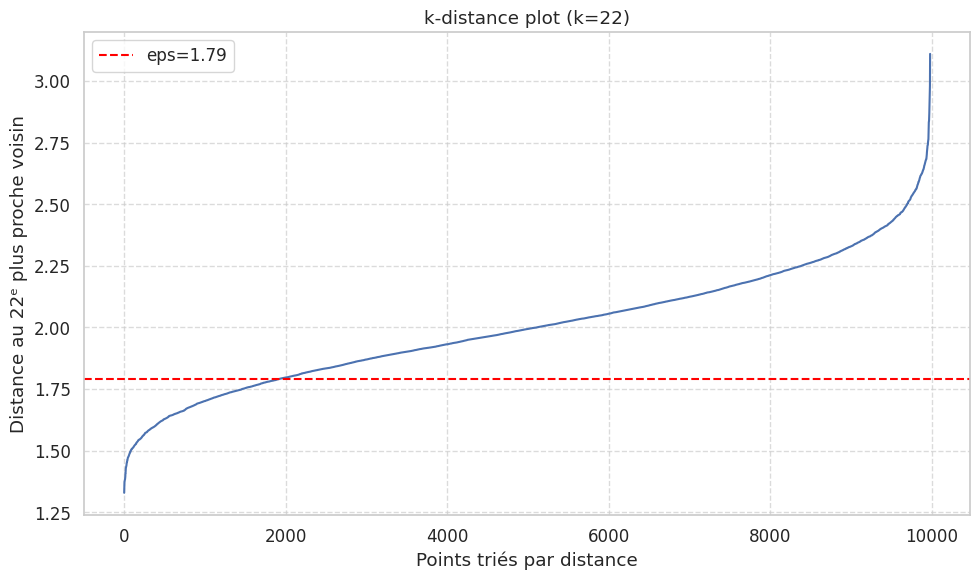


Nombre de clusters trouvés : 2
Nombre de points de bruit : 3599
Distribution des clusters : [6369   14]


In [ ]:
min_samples = 22

nbrs = NearestNeighbors(n_neighbors=min_samples)
nbrs.fit(X_for_dbscan)
k_dists, _ = nbrs.kneighbors(X_for_dbscan)
k_dists = np.sort(k_dists[:, -1])


plt.figure(figsize=(10, 6))
plt.plot(k_dists)
plt.title(f"k-distance plot (k={min_samples})")
plt.xlabel("Points triés par distance")
plt.ylabel(f"Distance au {min_samples}ᵉ plus proche voisin")
plt.grid(True, linestyle="--", alpha=0.7)

eps_optimal = 1.79
plt.axhline(y=eps_optimal, color='red', linestyle='--', label=f'eps={eps_optimal}')
plt.legend()
plt.tight_layout()
plt.show()


dbscan = DBSCAN(eps=eps_optimal, min_samples=min_samples)
clusters = dbscan.fit_predict(X_for_dbscan)


n_clusters = len(set(clusters)) - (1 if -1 in clusters else 0)
n_noise = list(clusters).count(-1)

print(f"\nNombre de clusters trouvés : {n_clusters}")
print(f"Nombre de points de bruit : {n_noise}")


if np.any(clusters >= 0):
    print(f"Distribution des clusters : {np.bincount(clusters[clusters >= 0])}")
else:
    print("Aucun cluster trouvé (tous les points sont du bruit).")

In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15), 0 2px 4px rgba(0,0,0,0.12), 0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<!-- Décor coin violet -->
<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<!-- Décor points jaunes -->
<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 12px;
        padding-bottom: 10px;
        font-size: 28px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
 Interpretation
</h2>

<p style="
        margin: 0;
        color: #2c3e50;
        font-size: 16px;
        line-height: 1.65;
        position: relative;
        z-index: 2;
    ">
To obtain <b>two clusters</b>, the optimal value of <b>ε = 1.79</b>.<br><br>

When ε &lt; 1.79, the number of clusters increases (more than two), whereas for ε &gt; 1.79,
all points merge into a <b>single cluster</b>.
These results clearly show that <b>PCA is not suitable</b> in this case, as it
<b>degrades the natural cluster structure</b> instead of improving it.<br><br>

The noise level is relatively high (<b>36.05%</b>), while:<br>
• <b>Cluster 0</b> contains <b>63.80%</b> of the data<br>
• <b>Cluster 2</b> contains only <b>0.14%</b><br><br>

This further confirms that the data distribution is poorly represented after applying PCA.
</p>

</div>
"""

display(HTML(html_content))


In [ ]:
eps = 1.79
min_samples = 22

db = DBSCAN(eps=eps, min_samples=min_samples)
labels = db.fit_predict(X_for_dbscan)

unique_labels = np.unique(labels)


n_clusters = len(set(labels)) - (1 if -1 in labels else 0)

n_noise = int(np.sum(labels == -1))


print("les clusters detectés (avec le cluster des points bruits):",unique_labels)
print("les clusters de chaque observation:", labels)

les clusters detectés (avec le cluster des points bruits): [-1  0  1]
les clusters de chaque observation: [-1  0 -1 ...  0  0  0]


In [ ]:
print("\n=== Distribution des observations par cluster ===")
for label in unique_labels:
    count = np.sum(clusters == label)
    percentage = (count / len(clusters)) * 100
    cluster_name = "Bruit" if label == -1 else f"Cluster {label}"
    print(f"{cluster_name}: {count} observations ({percentage:.2f}%)")


=== Distribution des observations par cluster ===
Bruit: 3599 observations (36.05%)
Cluster 0: 6369 observations (63.80%)
Cluster 1: 14 observations (0.14%)


In [ ]:
mask_no_noise = clusters != -1
if n_clusters >= 2 and np.sum(mask_no_noise) > 0:
    sil_score = silhouette_score(X[mask_no_noise], clusters[mask_no_noise])
    print(f"\nSilhouette Score (sans bruit): {sil_score:.3f}")


Silhouette Score (sans bruit): 0.067


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15), 0 2px 4px rgba(0,0,0,0.12), 0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<!-- Décor coin violet -->
<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<!-- Décor points jaunes -->
<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 12px;
        padding-bottom: 10px;
        font-size: 28px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
 Interpretation
</h2>

<p style="
        margin: 0;
        color: #2c3e50;
        font-size: 16px;
        line-height: 1.65;
        position: relative;
        z-index: 2;
    ">
The <b>Silhouette Score = 0.067</b> (computed without noise) indicates <b>weak clustering</b>.<br><br>
Clusters are poorly separated, and many points lie close to the boundaries between groups,
showing that the internal structure of the data is not strongly defined.
</p>

</div>
"""

display(HTML(html_content))


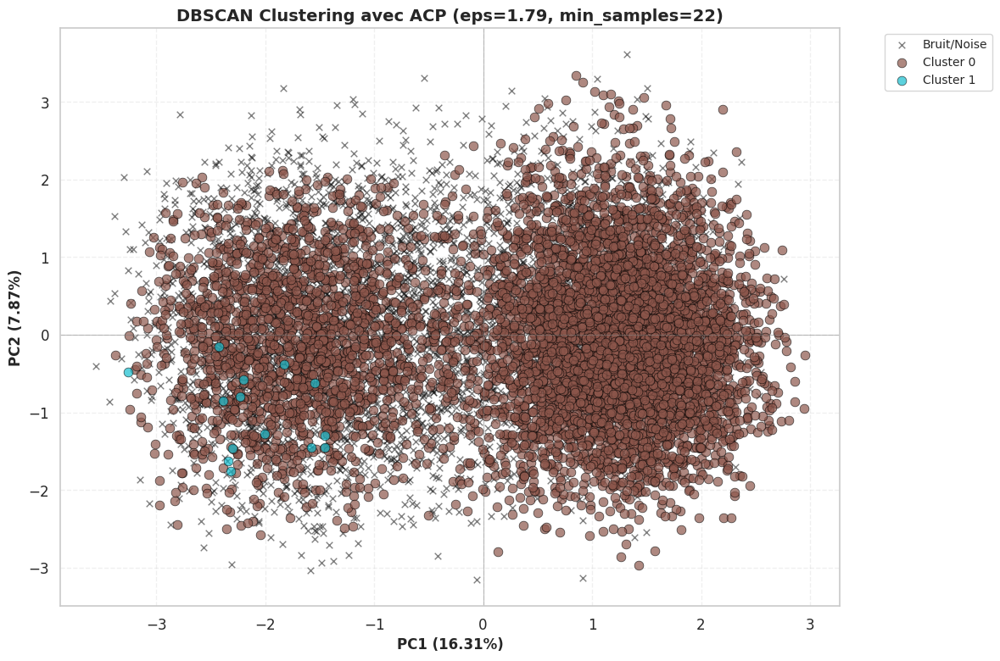

In [ ]:
# Visualisation DBSCAN avec ACP (utilisation de l'ACP déjà calculée)
plt.figure(figsize=(12, 8))

colors = plt.cm.tab10(np.linspace(0, 1, len(unique_labels)))

for color, label in zip(colors, unique_labels):
    mask = clusters == label
    if label == -1:
        # Bruit (points noirs avec marqueur 'x')
        plt.scatter(X_pca_transformed[mask, 0], X_pca_transformed[mask, 1],
                    s=30, c='black', marker='x',
                    label='Bruit/Noise', alpha=0.5, linewidths=1)
    else:

        plt.scatter(X_pca_transformed[mask, 0], X_pca_transformed[mask, 1],
                    s=60, c=[color], edgecolor='black',
                    label=f'Cluster {label}', alpha=0.7, linewidths=0.5)

plt.title(f"DBSCAN Clustering avec ACP (eps={eps}, min_samples={min_samples})",
          fontsize=14, fontweight='bold')
plt.xlabel(f"PC1 ({variance_explained[0]*100:.2f}%)",
           fontsize=12, fontweight='bold')
plt.ylabel(f"PC2 ({variance_explained[1]*100:.2f}%)",
           fontsize=12, fontweight='bold')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=10)
plt.grid(True, alpha=0.3, linestyle='--')
plt.axhline(y=0, color='grey', linewidth=0.8, alpha=0.5)
plt.axvline(x=0, color='grey', linewidth=0.8, alpha=0.5)
plt.tight_layout()
plt.show()

In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15), 0 2px 4px rgba(0,0,0,0.12), 0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<!-- Décor coin violet -->
<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<!-- Décor points jaunes -->
<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 12px;
        padding-bottom: 10px;
        font-size: 28px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
 Interpretation
</h2>

<p style="
        margin: 0;
        color: #2c3e50;
        font-size: 16px;
        line-height: 1.65;
        position: relative;
        z-index: 2;
    ">
DBSCAN on PCA yields a <b>Silhouette Score = 0.067</b> — strong evidence that
<b>eps = 2</b> in the original feature space is the only valid parameter setting to correctly
capture the <b>risk level associated with suicidal thoughts</b>.<br><br>
This low score confirms that PCA distorts the natural structure of the data, reducing the
model’s ability to separate meaningful groups in a clinically relevant way.
</p>

</div>
"""

display(HTML(html_content))

In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15), 0 2px 4px rgba(0,0,0,0.12), 0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 12px;
        padding-bottom: 10px;
        font-size: 28px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
 GMM</h2>
</div>
"""

display(HTML(html_content))


Find Best Number of Components

In [ ]:
suicidal_col = "Have you ever had suicidal thoughts ?"
X = df_scaled
df = df_num
results = []
for n in range(2, 5):
    gmm = GaussianMixture(n_components=n, covariance_type='full', random_state=42, n_init=10)
    gmm.fit(X)
    labels = gmm.predict(X)
    bic = gmm.bic(X)
    sil = silhouette_score(X, labels)
    db = davies_bouldin_score(X, labels)
    ch = calinski_harabasz_score(X, labels)
    results.append((n, bic, sil, db, ch))
df_metrics = pd.DataFrame(results, columns=['n_clusters', 'BIC', 'Silhouette', 'Davies-Bouldin', 'Calinski-Harabasz'])
print(df_metrics.sort_values('BIC'))
print('The GMM model with 2 components provides the clearest, most meaningful clustering structure for data.')

   n_clusters            BIC  Silhouette  Davies-Bouldin  Calinski-Harabasz
2           4  122309.321075    0.076038        3.013615         682.765059
1           3  177576.456038    0.085606        2.928120        1042.585095
0           2  254030.212012    0.131478        2.529810        1507.527412
The GMM model with 2 components provides the clearest, most meaningful clustering structure for data.


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15),
                0 2px 4px rgba(0,0,0,0.12),
                0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<!-- Décor coin violet -->
<div style="
    position: absolute;
    top: -30px;
    right: -30px;
    width: 120px;
    height: 120px;
    background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
    z-index: 1;
"></div>

<!-- Décor points jaunes -->
<div style="
    position: absolute;
    bottom: 20px;
    left: 20px;
    width: 60px;
    height: 60px;
    background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
    background-size: 12px 12px;
    opacity: 0.3;
    z-index: 1;
"></div>

<h2 style="
    margin-top: 0;
    margin-bottom: 12px;
    padding-bottom: 10px;
    font-size: 28px;
    color: rgba(106,5,114,0.85);
    border-bottom: 2px solid rgba(78,205,196,0.7);
    position: relative;
    z-index: 2;
    text-align: center;
">
Fit GMM Without PCA
</h2>

<p style="
    margin: 0;
    color: #2c3e50;
    font-size: 16px;
    line-height: 1.65;
    position: relative;
    z-index: 2;
">

</div>
"""

display(HTML(html_content))

In [ ]:
gmm_no_pca = GaussianMixture(n_components=2, covariance_type='full', random_state=42, n_init=10)
gmm_no_pca.fit(X)
labels_no_pca = gmm_no_pca.predict(X)
probs_no_pca = gmm_no_pca.predict_proba(X).max(axis=1)
bic_no = gmm_no_pca.bic(X)
aic_no = gmm_no_pca.aic(X)
sil_no = silhouette_score(X, labels_no_pca)
ll_no = gmm_no_pca.score(X) * len(X)
avg_ll_no = gmm_no_pca.score(X)
df["GMM_NoPCA_Cluster"] = labels_no_pca
df["GMM_NoPCA_Prob"] = probs_no_pca

In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15),
                0 2px 4px rgba(0,0,0,0.12),
                0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<!-- Décor coin violet -->
<div style="
    position: absolute;
    top: -30px;
    right: -30px;
    width: 120px;
    height: 120px;
    background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
    z-index: 1;
"></div>

<!-- Décor points jaunes -->
<div style="
    position: absolute;
    bottom: 20px;
    left: 20px;
    width: 60px;
    height: 60px;
    background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
    background-size: 12px 12px;
    opacity: 0.3;
    z-index: 1;
"></div>

<h2 style="
    margin-top: 0;
    margin-bottom: 12px;
    padding-bottom: 10px;
    font-size: 28px;
    color: rgba(106,5,114,0.85);
    border-bottom: 2px solid rgba(78,205,196,0.7);
    position: relative;
    z-index: 2;
    text-align: center;
">
Fit GMM with PCA
</h2>

<p style="
    margin: 0;
    color: #2c3e50;
    font-size: 16px;
    line-height: 1.65;
    position: relative;
    z-index: 2;
">

</div>
"""

display(HTML(html_content))

In [ ]:
gmm_pca = GaussianMixture(n_components=2, covariance_type='full', random_state=42, n_init=10)
gmm_pca.fit(X_pca_transformed)
labels_pca = gmm_pca.predict(X_pca_transformed)
probs_pca = gmm_pca.predict_proba(X_pca_transformed).max(axis=1)
bic_pca = gmm_pca.bic(X_pca_transformed)
aic_pca = gmm_pca.aic(X_pca_transformed)
sil_pca = silhouette_score(X_pca_transformed, labels_pca)
ll_pca = gmm_pca.score(X_pca_transformed) * len(X_pca_transformed)
avg_ll_pca = gmm_pca.score(X_pca_transformed)
df["GMM_PCA_Cluster"] = labels_pca
df["GMM_PCA_Prob"] = probs_pca

In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15),
                0 2px 4px rgba(0,0,0,0.12),
                0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<!-- Décor coin violet -->
<div style="
    position: absolute;
    top: -30px;
    right: -30px;
    width: 120px;
    height: 120px;
    background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
    z-index: 1;
"></div>

<!-- Décor points jaunes -->
<div style="
    position: absolute;
    bottom: 20px;
    left: 20px;
    width: 60px;
    height: 60px;
    background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
    background-size: 12px 12px;
    opacity: 0.3;
    z-index: 1;
"></div>

<h2 style="
    margin-top: 0;
    margin-bottom: 12px;
    padding-bottom: 10px;
    font-size: 28px;
    color: rgba(106,5,114,0.85);
    border-bottom: 2px solid rgba(78,205,196,0.7);
    position: relative;
    z-index: 2;
    text-align: center;
">
Compare results
</h2>

<p style="
    margin: 0;
    color: #2c3e50;
    font-size: 16px;
    line-height: 1.65;
    position: relative;
    z-index: 2;
">

</div>
"""

display(HTML(html_content))

In [ ]:
comparison = pd.DataFrame({
    "Version": ["Sans PCA", "Avec PCA"],
    "Log-Likelihood": [ll_no, ll_pca],
    "Avg Log-Likelihood": [avg_ll_no, avg_ll_pca],
    "BIC": [bic_no, bic_pca],
    "AIC": [aic_no, aic_pca],
    "Silhouette": [sil_no, sil_pca]
})
print("\nComparaison GMM (2 clusters)")
print(comparison.to_string(index=False))


Comparaison GMM (2 clusters)
 Version  Log-Likelihood  Avg Log-Likelihood           BIC           AIC  Silhouette
Sans PCA  -125914.685626          -12.614174 254030.212012 252307.371251    0.131478
Avec PCA  -125914.685625          -12.614174 254030.212012 252307.371251    0.131478


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15),
                0 2px 4px rgba(0,0,0,0.12),
                0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<!-- Décor coin violet -->
<div style="
    position: absolute;
    top: -30px;
    right: -30px;
    width: 120px;
    height: 120px;
    background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
    z-index: 1;
"></div>

<!-- Décor points jaunes -->
<div style="
    position: absolute;
    bottom: 20px;
    left: 20px;
    width: 60px;
    height: 60px;
    background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
    background-size: 12px 12px;
    opacity: 0.3;
    z-index: 1;
"></div>

<h2 style="
    margin-top: 0;
    margin-bottom: 12px;
    padding-bottom: 10px;
    font-size: 28px;
    color: rgba(106,5,114,0.85);
    border-bottom: 2px solid rgba(78,205,196,0.7);
    position: relative;
    z-index: 2;
    text-align: center;
">
PCA had no significant impact — GMM performance stayed identical, showing a stable clustering structure.
</h2>

<p style="
    margin: 0;
    color: #2c3e50;
    font-size: 16px;
    line-height: 1.65;
    position: relative;
    z-index: 2;
">

</div>
"""

display(HTML(html_content))

In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15),
                0 2px 4px rgba(0,0,0,0.12),
                0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<!-- Décor coin violet -->
<div style="
    position: absolute;
    top: -30px;
    right: -30px;
    width: 120px;
    height: 120px;
    background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
    z-index: 1;
"></div>

<!-- Décor points jaunes -->
<div style="
    position: absolute;
    bottom: 20px;
    left: 20px;
    width: 60px;
    height: 60px;
    background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
    background-size: 12px 12px;
    opacity: 0.3;
    z-index: 1;
"></div>

<h2 style="
    margin-top: 0;
    margin-bottom: 12px;
    padding-bottom: 10px;
    font-size: 28px;
    color: rgba(106,5,114,0.85);
    border-bottom: 2px solid rgba(78,205,196,0.7);
    position: relative;
    z-index: 2;
    text-align: center;
">
Visualisation — Likelihood / BIC / AIC
</h2>

<p style="
    margin: 0;
    color: #2c3e50;
    font-size: 16px;
    line-height: 1.65;
    position: relative;
    z-index: 2;
">

</div>
"""

display(HTML(html_content))

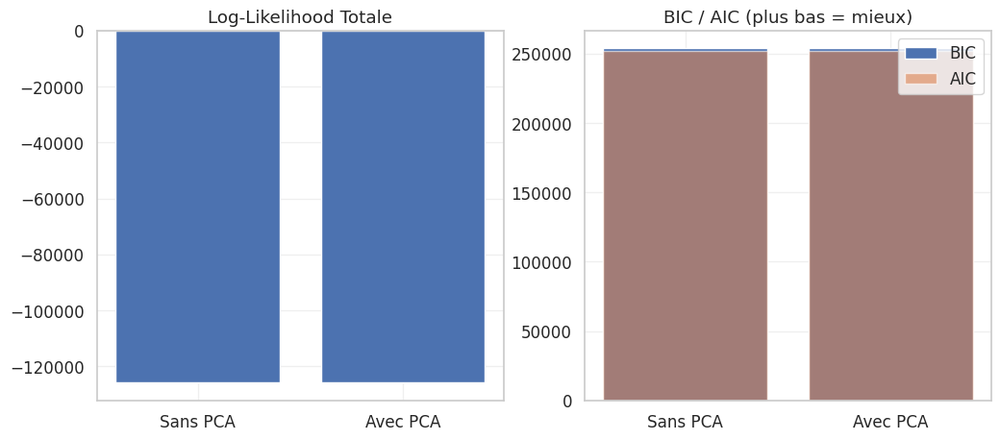

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ax[0].bar(["Sans PCA", "Avec PCA"], [ll_no, ll_pca])
ax[0].set_title("Log-Likelihood Totale")
ax[0].grid(True, alpha=0.3)
ax[1].bar(["Sans PCA", "Avec PCA"], [bic_no, bic_pca], label="BIC")
ax[1].bar(["Sans PCA", "Avec PCA"], [aic_no, aic_pca], alpha=0.6, label="AIC")
ax[1].set_title("BIC / AIC (plus bas = mieux)")
ax[1].legend()
ax[1].grid(True, alpha=0.3)

In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15),
                0 2px 4px rgba(0,0,0,0.12),
                0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<!-- Décor coin violet -->
<div style="
    position: absolute;
    top: -30px;
    right: -30px;
    width: 120px;
    height: 120px;
    background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
    z-index: 1;
"></div>

<!-- Décor points jaunes -->
<div style="
    position: absolute;
    bottom: 20px;
    left: 20px;
    width: 60px;
    height: 60px;
    background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
    background-size: 12px 12px;
    opacity: 0.3;
    z-index: 1;
"></div>

<h2 style="
    margin-top: 0;
    margin-bottom: 12px;
    padding-bottom: 10px;
    font-size: 28px;
    color: rgba(106,5,114,0.85);
    border-bottom: 2px solid rgba(78,205,196,0.7);
    position: relative;
    z-index: 2;
    text-align: center;
">
As it was stated earlier , PCA has no significant impact. We will proceed with No PCA.
</h2>

<p style="
    margin: 0;
    color: #2c3e50;
    font-size: 16px;
    line-height: 1.65;
    position: relative;
    z-index: 2;
">

</div>
"""

display(HTML(html_content))

In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15),
                0 2px 4px rgba(0,0,0,0.12),
                0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<!-- Décor coin violet -->
<div style="
    position: absolute;
    top: -30px;
    right: -30px;
    width: 120px;
    height: 120px;
    background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
    z-index: 1;
"></div>

<!-- Décor points jaunes -->
<div style="
    position: absolute;
    bottom: 20px;
    left: 20px;
    width: 60px;
    height: 60px;
    background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
    background-size: 12px 12px;
    opacity: 0.3;
    z-index: 1;
"></div>

<h2 style="
    margin-top: 0;
    margin-bottom: 12px;
    padding-bottom: 10px;
    font-size: 28px;
    color: rgba(106,5,114,0.85);
    border-bottom: 2px solid rgba(78,205,196,0.7);
    position: relative;
    z-index: 2;
    text-align: center;
">
Scatter plot PCA clusters
</h2>

<p style="
    margin: 0;
    color: #2c3e50;
    font-size: 16px;
    line-height: 1.65;
    position: relative;
    z-index: 2;
">

</div>
"""

display(HTML(html_content))

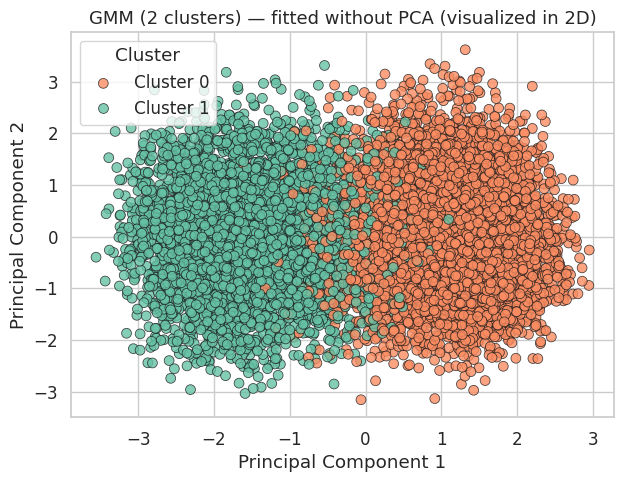

In [ ]:
pca_vis = PCA(n_components=2)
X_vis = pca_vis.fit_transform(X)
labels_no_pca = gmm_no_pca.predict(X)
plt.figure(figsize=(7,5))
sns.scatterplot(
    x=X_vis[:, 0],
    y=X_vis[:, 1],
    hue=labels_no_pca,
    palette=sns.color_palette("Set2", 2),
    s=50,
    alpha=0.8,
    edgecolor='k'
)
plt.title("GMM (2 clusters) — fitted without PCA (visualized in 2D)", fontsize=13)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Cluster", labels=["Cluster 0", "Cluster 1"])
plt.show()


In [ ]:
df = df.drop(columns=['GMM_NoPCA_Cluster', 'GMM_PCA_Cluster', 'GMM_NoPCA_Prob', 'GMM_PCA_Prob'], errors='ignore')
df_num = df_num.drop(columns=['GMM_NoPCA_Cluster', 'GMM_PCA_Cluster', 'GMM_NoPCA_Prob', 'GMM_PCA_Prob'], errors='ignore')


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15),
                0 2px 4px rgba(0,0,0,0.12),
                0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 28px;
    margin: 24px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<!-- Décor coin violet -->
<div style="
    position: absolute;
    top: -30px;
    right: -30px;
    width: 120px;
    height: 120px;
    background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.90) 95%);
    z-index: 1;
"></div>

<!-- Décor points jaunes -->
<div style="
    position: absolute;
    bottom: 20px;
    left: 20px;
    width: 60px;
    height: 60px;
    background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
    background-size: 12px 12px;
    opacity: 0.30;
    z-index: 1;
"></div>

<h2 style="
    margin-top: 0;
    margin-bottom: 12px;
    padding-bottom: 8px;
    font-size: 28px;
    color: rgba(106,5,114,0.85);
    border-bottom: 2px solid rgba(78,205,196,0.65);
    text-align: center;
    position: relative;
    z-index: 2;
">
GMM Final Interpretation
</h2>

<p style="
    margin: 0;
    color: #2c3e50;
    font-size: 16px;
    line-height: 1.65;
    position: relative;
    z-index: 2;
">
The <b>Gaussian Mixture Model (GMM) fitted without PCA</b> successfully identifies
<b>two compact and well-defined clusters</b>, preserving the natural structure of the
original feature space.<br><br>

The segmentation reveals <b>two contrasting well-being profiles</b> — one cluster with
lower overall component scores and another with higher ones — indicating a clear
separation in student mental health patterns.<br><br>

This confirms that GMM, unlike PCA-based approaches, <b>maintains the integrity of
non-linear relationships</b> essential for capturing subtle mental health signals.
</p>

</div>
"""

display(HTML(html_content))


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15), 0 2px 4px rgba(0,0,0,0.12), 0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 12px;
        padding-bottom: 10px;
        font-size: 28px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
 CAH</h2>
</div>
"""

display(HTML(html_content))


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15), 0 2px 4px rgba(0,0,0,0.12), 0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 12px;
        padding-bottom: 10px;
        font-size: 28px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
 DETERMINING THE OPTIMAL NUMBER OF PROFILES</h2>
</div>
"""

display(HTML(html_content))


In [ ]:
nombre_profils = [2, 3, 4]
resultats_k = []

print("\nTest de différents nombres de profils de risque:")

for k in nombre_profils:
    Z = linkage(df_scaled, method='ward')
    clusters = fcluster(Z, t=k, criterion='maxclust')

    silhouette = silhouette_score(df_scaled, clusters)
    davies_bouldin = davies_bouldin_score(df_scaled, clusters)
    calinski = calinski_harabasz_score(df_scaled, clusters)

    resultats_k.append({
        'K': k,
        'Silhouette': silhouette,
        'Davies-Bouldin': davies_bouldin,
        'Calinski-Harabasz': calinski
    })

    print(f"\n  K = {k} profils:")
    print(f"    Silhouette: {silhouette:.4f}")
    print(f"    Davies-Bouldin: {davies_bouldin:.4f}")
    print(f"    Calinski-Harabasz: {calinski:.0f}")

df_k = pd.DataFrame(resultats_k)
best_k_idx = df_k['Silhouette'].argmax()
best_k = df_k.iloc[best_k_idx]['K']

print(f"\n NOMBRE OPTIMAL DE PROFILS: {best_k}")
print(f"   Silhouette Score: {df_k.iloc[best_k_idx]['Silhouette']:.4f}")

if best_k == 2:
    profils_labels = ['RISQUE FAIBLE', 'RISQUE ÉLEVÉ']
elif best_k == 3:
    profils_labels = ['RISQUE FAIBLE', 'RISQUE MOYEN', 'RISQUE ÉLEVÉ']
else:
    profils_labels = [f'PROFIL {i+1}' for i in range(best_k)]

print(f"\n Profils de risque identifiés: {', '.join(profils_labels)}")


Test de différents nombres de profils de risque:

  K = 2 profils:
    Silhouette: 0.1251
    Davies-Bouldin: 2.6015
    Calinski-Harabasz: 1412

  K = 3 profils:
    Silhouette: 0.0663
    Davies-Bouldin: 3.5238
    Calinski-Harabasz: 893

  K = 4 profils:
    Silhouette: 0.0589
    Davies-Bouldin: 3.5009
    Calinski-Harabasz: 683

 NOMBRE OPTIMAL DE PROFILS: 2.0
   Silhouette Score: 0.1251

 Profils de risque identifiés: RISQUE FAIBLE, RISQUE ÉLEVÉ


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15),
                0 2px 4px rgba(0,0,0,0.12),
                0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 28px;
    margin: 24px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<!-- Décor coin violet -->
<div style="
    position: absolute;
    top: -30px;
    right: -30px;
    width: 120px;
    height: 120px;
    background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.90) 95%);
    z-index: 1;
"></div>

<!-- Décor points jaunes -->
<div style="
    position: absolute;
    bottom: 20px;
    left: 20px;
    width: 60px;
    height: 60px;
    background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
    background-size: 12px 12px;
    opacity: 0.30;
    z-index: 1;
"></div>

<h2 style="
    margin-top: 0;
    margin-bottom: 12px;
    padding-bottom: 8px;
    font-size: 28px;
    color: rgba(106,5,114,0.85);
    border-bottom: 2px solid rgba(78,205,196,0.65);
    text-align: center;
    position: relative;
    z-index: 2;
">
Optimal Number of Clusters
</h2>

<p style="
    margin: 0;
    color: #2c3e50;
    font-size: 16px;
    line-height: 1.65;
    position: relative;
    z-index: 2;
">
The <b>Silhouette Score</b> identifies <b>2 clusters</b> as the optimal structure, indicating the presence of
<b>two distinct student profiles</b>.<br><br>

These clusters represent:<br>
• A <b>low-risk group</b>, characterized by healthier well-being patterns.<br>
• A <b>high-risk group</b>, showing stronger indicators of stress, vulnerability, or mental health challenges.<br><br>

</p>

</div>
"""

display(HTML(html_content))


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15), 0 2px 4px rgba(0,0,0,0.12), 0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 12px;
        padding-bottom: 10px;
        font-size: 28px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
 Elbow method visualization</h2>
</div>
"""

display(HTML(html_content))


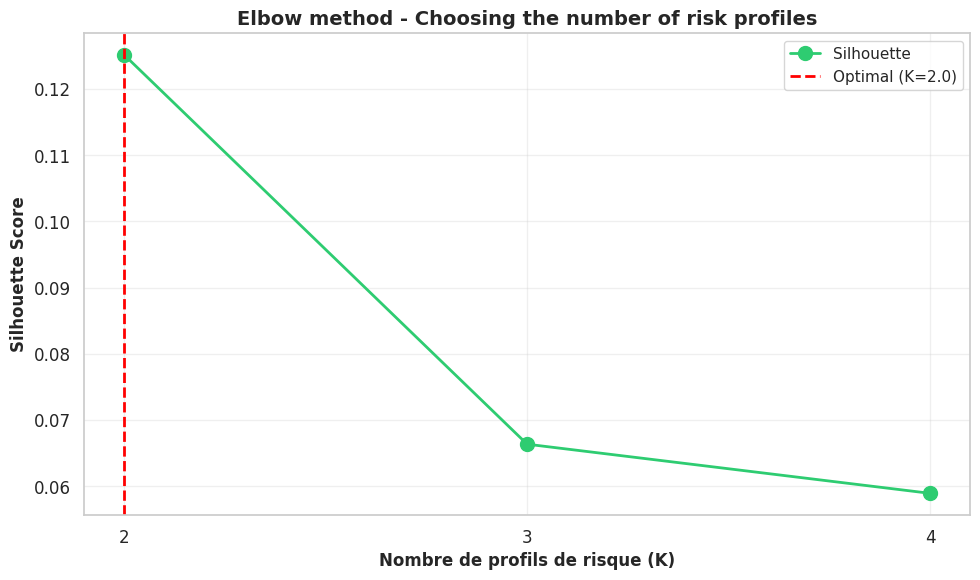

In [ ]:
fig, ax = plt.subplots(1, 1, figsize=(10, 6))
ax.plot(df_k['K'], df_k['Silhouette'], 'o-', linewidth=2, markersize=10,
        color='#2ecc71', label='Silhouette')
ax.axvline(x=best_k, color='red', linestyle='--', linewidth=2, label=f'Optimal (K={best_k})')
ax.set_xlabel('Nombre de profils de risque (K)', fontweight='bold', fontsize=12)
ax.set_ylabel('Silhouette Score', fontweight='bold', fontsize=12)
ax.set_title('Elbow method - Choosing the number of risk profiles',
             fontweight='bold', fontsize=14)
ax.set_xticks(nombre_profils)
ax.legend(fontsize=11)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15), 0 2px 4px rgba(0,0,0,0.12), 0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 12px;
        padding-bottom: 10px;
        font-size: 28px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
 The optimal number of risk profiles is 2, as it maximizes internal consistency and separation between groups.</h2>
</div>
"""

display(HTML(html_content))


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15), 0 2px 4px rgba(0,0,0,0.12), 0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 12px;
        padding-bottom: 10px;
        font-size: 28px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
SCENARIO 1: All variables + PCA Reduction</h2>
</div>
"""

display(HTML(html_content))

In [ ]:
X_pca_80 = X_pca_transformed[:, :n_components_80]
print(f"  - Dimensions: {X_pca_80.shape}")
print(f"  - Profils: {best_k}")

Z_scenario1 = linkage(X_pca_80, method='ward')
clusters_scenario1 = fcluster(Z_scenario1, t=best_k, criterion='maxclust')

silhouette_1 = silhouette_score(X_pca_80, clusters_scenario1)
davies_bouldin_1 = davies_bouldin_score(X_pca_80, clusters_scenario1)
calinski_1 = calinski_harabasz_score(X_pca_80, clusters_scenario1)

print(f"\n  Métriques:")
print(f"    - Silhouette: {silhouette_1:.4f}")
print(f"    - Davies-Bouldin: {davies_bouldin_1:.4f}")
print(f"    - Calinski-Harabasz: {calinski_1:.0f}")

unique_1, counts_1 = np.unique(clusters_scenario1, return_counts=True)
print(f"\n   Distribution des profils:")
for cluster_id, count in zip(unique_1, counts_1):
    label = profils_labels[cluster_id-1] if cluster_id <= len(profils_labels) else f"Profil {cluster_id}"
    print(f"    - {label}: {count} étudiants ({count/len(clusters_scenario1)*100:.1f}%)")

  - Dimensions: (9982, 10)
  - Profils: 2.0

  Métriques:
    - Silhouette: 0.1415
    - Davies-Bouldin: 2.3542
    - Calinski-Harabasz: 1711

   Distribution des profils:
    - RISQUE FAIBLE: 4096 étudiants (41.0%)
    - RISQUE ÉLEVÉ: 5886 étudiants (59.0%)


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15), 0 2px 4px rgba(0,0,0,0.12), 0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 12px;
        padding-bottom: 10px;
        font-size: 28px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
 SCENARIO 2: All variables WITHOUT reduction</h2>
</div>
"""

display(HTML(html_content))


In [ ]:
print(f"  - Dimensions: {df_scaled.shape}")
print(f"  - Profils: {best_k}")
Z_scenario2 = linkage(df_scaled, method='ward')
clusters_scenario2 = fcluster(Z_scenario2, t=best_k, criterion='maxclust')

silhouette_2 = silhouette_score(df_scaled, clusters_scenario2)
davies_bouldin_2 = davies_bouldin_score(df_scaled, clusters_scenario2)
calinski_2 = calinski_harabasz_score(df_scaled, clusters_scenario2)

print(f"\n   Métriques:")
print(f"    - Silhouette: {silhouette_2:.4f}")
print(f"    - Davies-Bouldin: {davies_bouldin_2:.4f}")
print(f"    - Calinski-Harabasz: {calinski_2:.0f}")

unique_2, counts_2 = np.unique(clusters_scenario2, return_counts=True)
print(f"\n  Distribution des profils:")
for cluster_id, count in zip(unique_2, counts_2):
    label = profils_labels[cluster_id-1] if cluster_id <= len(profils_labels) else f"Profil {cluster_id}"
    print(f"    - {label}: {count} étudiants ({count/len(clusters_scenario2)*100:.1f}%)")

  - Dimensions: (9982, 14)
  - Profils: 2.0

   Métriques:
    - Silhouette: 0.1251
    - Davies-Bouldin: 2.6015
    - Calinski-Harabasz: 1412

  Distribution des profils:
    - RISQUE FAIBLE: 4091 étudiants (41.0%)
    - RISQUE ÉLEVÉ: 5891 étudiants (59.0%)


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15), 0 2px 4px rgba(0,0,0,0.12), 0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 12px;
        padding-bottom: 10px;
        font-size: 28px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
 COMPARATIVE TABLE OF 2 APPROACHES</h2>
</div>
"""

display(HTML(html_content))

In [ ]:
comparison = pd.DataFrame({
    'Approche': [
        '1. Toutes vars + PCA',
        '2. Toutes vars SANS PCA'
    ],
    'N_features': [
        n_components_80,
        df_scaled.shape[1]
    ],
    'Silhouette': [silhouette_1, silhouette_2],
    'Davies-Bouldin': [davies_bouldin_1, davies_bouldin_2],
    'Calinski-Harabasz': [calinski_1, calinski_2]
})

comparison['Silhouette_norm'] = comparison['Silhouette']
comparison['Davies-Bouldin_norm'] = 1 - (comparison['Davies-Bouldin'] / comparison['Davies-Bouldin'].max())
comparison['Calinski_norm'] = comparison['Calinski-Harabasz'] / comparison['Calinski-Harabasz'].max()
comparison['Score_Global'] = (comparison['Silhouette_norm'] + comparison['Davies-Bouldin_norm'] + comparison['Calinski_norm']) / 3

comparison_display = comparison.copy()
comparison_display['Silhouette'] = comparison_display['Silhouette'].apply(lambda x: f"{x:.4f}")
comparison_display['Davies-Bouldin'] = comparison_display['Davies-Bouldin'].apply(lambda x: f"{x:.4f}")
comparison_display['Calinski-Harabasz'] = comparison_display['Calinski-Harabasz'].apply(lambda x: f"{x:.0f}")
comparison_display['Score_Global'] = comparison_display['Score_Global'].apply(lambda x: f"{x:.4f}")

print("\nTableau comparatif:")
print(comparison_display[['Approche', 'N_features', 'Silhouette', 'Davies-Bouldin', 'Calinski-Harabasz', 'Score_Global']].to_string(index=False))


Tableau comparatif:
               Approche  N_features Silhouette Davies-Bouldin Calinski-Harabasz Score_Global
   1. Toutes vars + PCA          10     0.1415         2.3542              1711       0.4122
2. Toutes vars SANS PCA          14     0.1251         2.6015              1412       0.3167


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15), 0 2px 4px rgba(0,0,0,0.12), 0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 12px;
        padding-bottom: 10px;
        font-size: 28px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
 BEST APPROACH</h2>
</div>
"""

display(HTML(html_content))

In [ ]:
best_global_idx = comparison['Score_Global'].argmax()
best_approach = comparison.iloc[best_global_idx]['Approche']
print(f"\n MEILLEURE APPROCHE: {best_approach}")
print(f"   Silhouette: {comparison.iloc[best_global_idx]['Silhouette']:.4f}")
print(f"   Davies-Bouldin: {comparison.iloc[best_global_idx]['Davies-Bouldin']:.4f}")
if best_global_idx == 0:
    best_clusters = clusters_scenario1
    best_data = X_pca_80
else:
    best_clusters = clusters_scenario2
    best_data = df_scaled


 MEILLEURE APPROCHE: 1. Toutes vars + PCA
   Silhouette: 0.1415
   Davies-Bouldin: 2.3542


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15), 0 2px 4px rgba(0,0,0,0.12), 0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 12px;
        padding-bottom: 10px;
        font-size: 28px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
The PCA approach achieves a better overall score, indicating that dimensionality reduction has allowed for a better highlighting of latent structures in the data.</h2>
</div>
"""

display(HTML(html_content))

In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15), 0 2px 4px rgba(0,0,0,0.12), 0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 12px;
        padding-bottom: 10px;
        font-size: 28px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
CHARACTERIZATION OF RISK PROFILES.</h2>
</div>
"""

display(HTML(html_content))

In [ ]:
df_clustered = df_num.copy()
df_clustered['Profil_Risque'] = best_clusters
df_clustered['Profil_Label'] = df_clustered['Profil_Risque'].apply(
    lambda x: profils_labels[x-1] if x <= len(profils_labels) else f'Profil {x}'
)
print("\n Caractéristiques moyennes par profil de risque:\n")
variables_cles = ['Depression', 'Have you ever had suicidal thoughts?',
                  'Academic Pressure', 'Financial Stress', 'Work/Study Hours',
                  'Sleep Duration', 'CGPA']
variables_cles = [v for v in variables_cles if v in df_clustered.columns]

profil_stats = df_clustered.groupby('Profil_Label')[variables_cles].mean()
print(profil_stats.round(2))

print("\n Effectifs par profil:")
profil_counts = df_clustered['Profil_Label'].value_counts()
print(profil_counts)


 Caractéristiques moyennes par profil de risque:

               Depression  Academic Pressure  Financial Stress  \
Profil_Label                                                     
RISQUE FAIBLE        0.09               2.32              2.43   
RISQUE ÉLEVÉ         0.92               3.74              3.61   

               Work/Study Hours  Sleep Duration  CGPA  
Profil_Label                                           
RISQUE FAIBLE              6.09            6.67  7.62  
RISQUE ÉLEVÉ               7.86            6.37  7.68  

 Effectifs par profil:
Profil_Label
RISQUE ÉLEVÉ     5886
RISQUE FAIBLE    4096
Name: count, dtype: int64


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15),
                0 2px 4px rgba(0,0,0,0.12),
                0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 28px;
    margin: 24px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<!-- Décor coin violet -->
<div style="
    position: absolute;
    top: -30px;
    right: -30px;
    width: 120px;
    height: 120px;
    background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.90) 95%);
    z-index: 1;
"></div>

<!-- Décor points jaunes -->
<div style="
    position: absolute;
    bottom: 20px;
    left: 20px;
    width: 60px;
    height: 60px;
    background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
    background-size: 12px 12px;
    opacity: 0.30;
    z-index: 1;
"></div>

<h2 style="
    margin-top: 0;
    margin-bottom: 12px;
    padding-bottom: 8px;
    font-size: 28px;
    color: rgba(106,5,114,0.85);
    border-bottom: 2px solid rgba(78,205,196,0.65);
    text-align: center;
    position: relative;
    z-index: 2;
">
Cluster Profile Analysis
</h2>

<p style="
    margin: 0;
    color: #2c3e50;
    font-size: 16px;
    line-height: 1.65;
    position: relative;
    z-index: 2;
">

<b>Profile 1 – Low Risk (5,886 students)</b><br>
This group exhibits a <b>low level of depression</b>, <b>moderate academic pressure</b>, and <b>good sleep quality</b>.
Students in this cluster appear <b>emotionally stable</b>, <b>well-balanced</b>, and present a <b>low psychological risk</b>.<br><br>

<b>Profile 2 – High Risk (4,096 students)</b><br>
Students in this profile show <b>marked depression</b>, <b>high academic and financial pressure</b>, and <b>sleep deprivation</b>.
They appear <b>more stressed</b>, <b>vulnerable</b>, and present a clearly <b>elevated psychological risk</b>.
</p>

</div>
"""

display(HTML(html_content))


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15), 0 2px 4px rgba(0,0,0,0.12), 0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 12px;
        padding-bottom: 10px;
        font-size: 28px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
Dendrogram Visualization</h2>
</div>
"""

display(HTML(html_content))

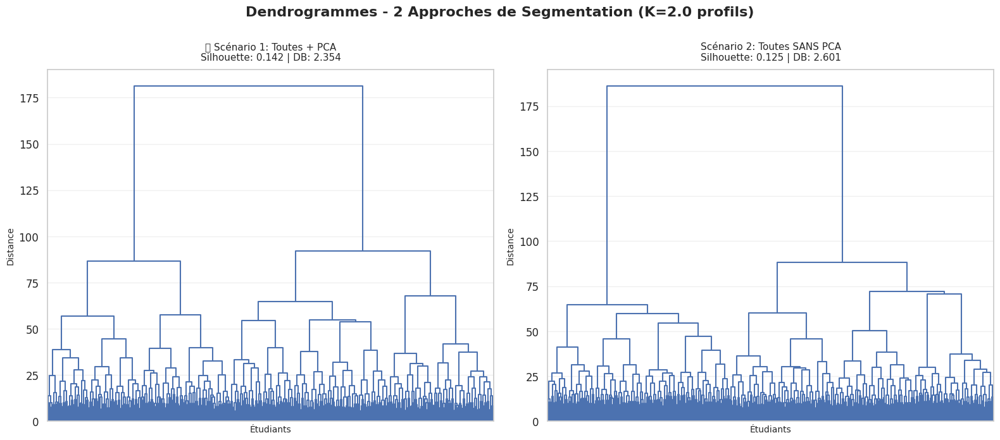

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
fig.suptitle(f'Dendrogrammes - 2 Approches de Segmentation (K={best_k} profils)',
             fontsize=16, fontweight='bold', y=0.995)

scenarios_data = [
    (Z_scenario1, silhouette_1, davies_bouldin_1, "Scénario 1: Toutes + PCA"),
    (Z_scenario2, silhouette_2, davies_bouldin_2, "Scénario 2: Toutes SANS PCA")
]

for idx, (Z, sil, db, title) in enumerate(scenarios_data):
    dendrogram(Z, ax=axes[idx], no_labels=True, color_threshold=0)
    star = "⭐ " if idx == best_global_idx else ""
    axes[idx].set_title(f"{star}{title}\nSilhouette: {sil:.3f} | DB: {db:.3f}",
                         fontsize=11, pad=10)
    axes[idx].set_xlabel('Étudiants', fontsize=10)
    axes[idx].set_ylabel('Distance', fontsize=10)
    axes[idx].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15), 0 2px 4px rgba(0,0,0,0.12), 0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 12px;
        padding-bottom: 10px;
        font-size: 28px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
The two dendrograms show a similar hierarchical structure, but PCA allows for better separation of groups and reduces noise in the data</h2>
</div>
"""

display(HTML(html_content))

In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15), 0 2px 4px rgba(0,0,0,0.12), 0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 12px;
        padding-bottom: 10px;
        font-size: 28px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
Clusters in PCA space</h2>
</div>
"""

display(HTML(html_content))

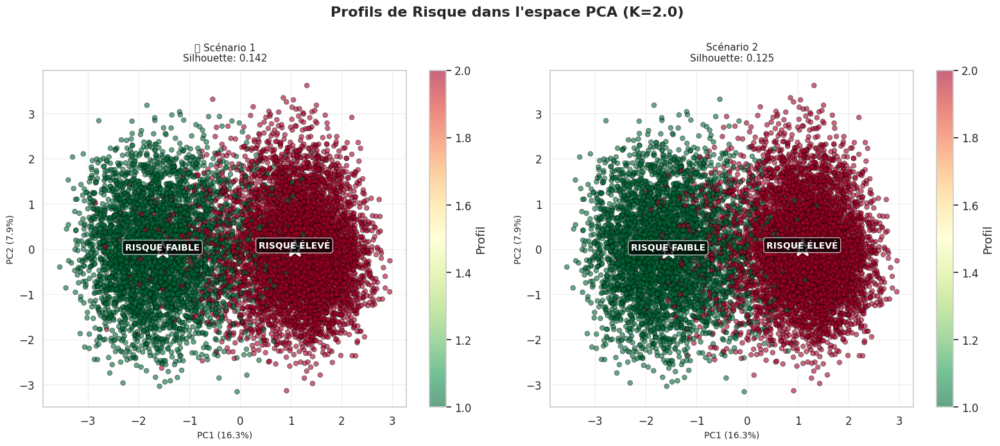

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
fig.suptitle(f'Profils de Risque dans l\'espace PCA (K={best_k})',
             fontsize=16, fontweight='bold', y=0.995)

clusters_list = [clusters_scenario1, clusters_scenario2]
silhouettes = [silhouette_1, silhouette_2]
titles = ["Scénario 1", "Scénario 2"]

for idx, (clusters, sil, title) in enumerate(zip(clusters_list, silhouettes, titles)):
    scatter = axes[idx].scatter(X_pca_transformed[:, 0], X_pca_transformed[:, 1],
                                c=clusters, cmap='RdYlGn_r', alpha=0.6, s=30,
                                edgecolors='black', linewidth=0.5)

    star = "⭐ " if idx == best_global_idx else ""
    axes[idx].set_title(f"{star}{title}\nSilhouette: {sil:.3f}", fontsize=11, pad=10)
    axes[idx].set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)', fontsize=10)
    axes[idx].set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)', fontsize=10)
    axes[idx].grid(True, alpha=0.3)

    for cluster_id in np.unique(clusters):
        mask = clusters == cluster_id
        cx = X_pca_transformed[mask, 0].mean()
        cy = X_pca_transformed[mask, 1].mean()
        axes[idx].plot(cx, cy, 'k*', markersize=20, markeredgewidth=2, markeredgecolor='white')

        label = profils_labels[cluster_id-1] if cluster_id <= len(profils_labels) else f'P{cluster_id}'
        axes[idx].annotate(label, (cx, cy), fontsize=10, fontweight='bold',
                            ha='center', color='white',
                            bbox=dict(boxstyle='round,pad=0.3', facecolor='black', alpha=0.7))

    plt.colorbar(scatter, ax=axes[idx], label='Profil')
plt.tight_layout()
plt.show()

In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15), 0 2px 4px rgba(0,0,0,0.12), 0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 12px;
        padding-bottom: 10px;
        font-size: 28px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
SUMMARY</h2>
</div>
"""

display(HTML(html_content))

In [ ]:
print(f"   Nombre de profils identifiés: {best_k}")
print(f"   Meilleure approche: {best_approach}")
print(f"   Silhouette Score : {comparison.iloc[best_global_idx]['Silhouette']:.4f}")
print(f"\nPROFILS DE RISQUE IDENTIFIÉS:")
for i, label in enumerate(profils_labels, 1):
    count = profil_counts.get(label, 0)
    pct = (count / len(df_clustered) * 100) if len(df_clustered) > 0 else 0
    print(f"  {i}. {label}: {count} étudiants ({pct:.1f}%)")

   Nombre de profils identifiés: 2.0
   Meilleure approche: 1. Toutes vars + PCA
   Silhouette Score : 0.1415

PROFILS DE RISQUE IDENTIFIÉS:
  1. RISQUE FAIBLE: 4096 étudiants (41.0%)
  2. RISQUE ÉLEVÉ: 5886 étudiants (59.0%)


In [ ]:
print("\n TUNING FINAL DU MEILLEUR SCÉNARIO")
if best_global_idx == 0:
    data_best = X_pca_80
else :
    data_best = df_scaled

linkage_methods = ['ward', 'complete', 'average', 'single']
distance_metrics = ['euclidean', 'cityblock', 'cosine']
cluster_range = range(2, 5)

best_config = None
best_score = -1
tuning_results = []

for method, metric, k in product(linkage_methods, distance_metrics, cluster_range):
    if method == 'ward' and metric != 'euclidean':
        continue
    try:
        Z = linkage(data_best, method=method, metric=metric)
        clusters = fcluster(Z, t=k, criterion='maxclust')

        sil = silhouette_score(data_best, clusters)
        db = davies_bouldin_score(data_best, clusters)
        ch = calinski_harabasz_score(data_best, clusters)

        tuning_results.append({
            'Linkage': method,
            'Metric': metric,
            'K': k,
            'Silhouette': sil,
            'Davies-Bouldin': db,
            'Calinski-Harabasz': ch
        })
        if sil  > best_score:
            best_score = sil
            best_config = (method, metric, k)

    except Exception as e:
        print(f" Erreur avec (method={method}, metric={metric}, k={k}): {e}")

df_tuning = pd.DataFrame(tuning_results).sort_values(by="Silhouette", ascending=False)

print("\nTop 5 des meilleures configurations :")
print(df_tuning.head(5).to_string(index=False))

best_method, best_metric, best_k = best_config
print(f"\n Meilleure configuration trouvée pour le scénario gagnant :")
print(f"   - Méthode de linkage : {best_method}")
print(f"   - Distance : {best_metric}")
print(f"   - Nombre de clusters : {best_k}")
print(f"   - Silhouette : {best_score:.4f}")


 TUNING FINAL DU MEILLEUR SCÉNARIO

Top 5 des meilleures configurations :
Linkage    Metric  K  Silhouette  Davies-Bouldin  Calinski-Harabasz
 single cityblock  2    0.183256        0.686519           2.080710
average cityblock  2    0.183256        0.686519           2.080710
average    cosine  2    0.146339        2.302223        1773.790993
 single euclidean  2    0.146236        0.733258           1.823888
average euclidean  2    0.145361        2.316833        1769.282174

 Meilleure configuration trouvée pour le scénario gagnant :
   - Méthode de linkage : average
   - Distance : cityblock
   - Nombre de clusters : 2
   - Silhouette : 0.1833


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15), 0 2px 4px rgba(0,0,0,0.12), 0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 12px;
        padding-bottom: 10px;
        font-size: 28px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
SUMMARY</h2>
</div>
"""

display(HTML(html_content))

In [ ]:

df_compare_detailed = pd.DataFrame([
    # KMEANS
    ["KMeans (Sans PCA)", sil_kmeans_no_pca, db_kmeans_no_pca, ch_kmeans_no_pca],
    ["KMeans (Avec PCA)", sil_kmeans_pca, db_kmeans_pca, ch_kmeans_pca],

    # DBSCAN
    ["DBSCAN (Sans PCA)", sil_db_no_pca, db_db_no_pca, ch_db_no_pca],
    ["DBSCAN (Avec PCA)", sil_db_pca, db_db_pca, ch_db_pca],

    # CAH
    ["CAH (Sans PCA)", sil_cah_no_pca, db_cah_no_pca, ch_cah_no_pca],
    ["CAH (Avec PCA)", sil_cah_pca, db_cah_pca, ch_cah_pca],

    # GMM
    ["GMM (Sans PCA)", sil_gmm_no_pca, db_gmm_no_pca, ch_gmm_no_pca],
    ["GMM (Avec PCA)", sil_gmm_pca, db_gmm_pca, ch_gmm_pca],
],
columns=["Méthode", "Silhouette", "Davies-Bouldin", "Calinski-Harabasz"]
)

# Nettoyage
df_compare_detailed = df_compare_detailed.fillna("—")

# Colonnes numériques
num_cols = df_compare_detailed.select_dtypes(include=["float", "int"]).columns

display(
    df_compare_detailed.style
        .background_gradient(cmap="coolwarm", subset=num_cols)
        .format({col: "{:.4f}" for col in num_cols})
)


,Méthode,Silhouette,Davies-Bouldin,Calinski-Harabasz
0,KMeans (Sans PCA),0.133489,2.505212,1536.757574
1,KMeans (Avec PCA),0.133489,2.505212,1536.757574
2,DBSCAN (Sans PCA),0.067195,1.233250,0.664622
3,DBSCAN (Avec PCA),—,—,—
4,CAH (Sans PCA),0.125145,2.601490,1411.514422
5,CAH (Avec PCA),0.141528,2.354213,1711.251104
6,GMM (Sans PCA),0.131478,2.529810,1507.527412
7,GMM (Avec PCA),0.131478,2.529810,1507.527412


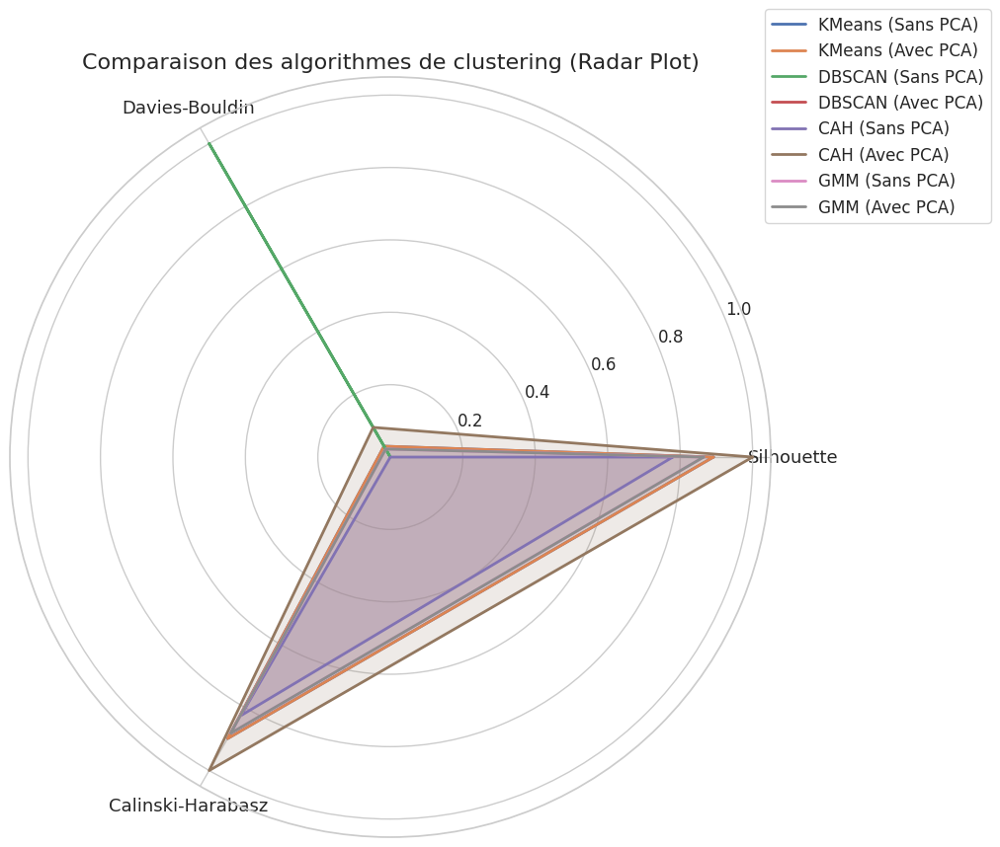

In [ ]:
df_plot = df_compare_detailed.replace("—", np.nan).copy()

# Inverser Davies-Bouldin (plus petit = meilleur)
df_plot["Davies-Bouldin"] = 1 / df_plot["Davies-Bouldin"].astype(float)

labels = df_plot["Méthode"]
metrics = ["Silhouette", "Davies-Bouldin", "Calinski-Harabasz"]

data = df_plot[metrics].astype(float).values

# Normalisation 0-1
data_norm = (data - np.nanmin(data, axis=0)) / (np.nanmax(data, axis=0) - np.nanmin(data, axis=0))

angles = np.linspace(0, 2 * np.pi, len(metrics), endpoint=False)
angles = np.concatenate((angles, [angles[0]]))

plt.figure(figsize=(10, 10))
ax = plt.subplot(111, polar=True)

for i, row in enumerate(data_norm):
    values = np.concatenate((row, [row[0]]))
    ax.plot(angles, values, linewidth=2, label=labels[i])
    ax.fill(angles, values, alpha=0.15)

ax.set_xticks(angles[:-1])
ax.set_xticklabels(metrics, fontsize=13)
plt.title("Comparaison des algorithmes de clustering (Radar Plot)", fontsize=16)
plt.legend(bbox_to_anchor=(1.3, 1.1))
plt.show()


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<style>
@keyframes float {
  0% { transform: translateY(0px); }
  50% { transform: translateY(-5px); }
  100% { transform: translateY(0px); }
}

@keyframes glow {
  0%,100% { box-shadow: 0 4px 10px rgba(106,5,114,0.25), inset 0 0 4px rgba(106,5,114,0.2); }
  50% { box-shadow: 0 8px 18px rgba(78,205,196,0.35), inset 0 0 6px rgba(78,205,196,0.25); }
}

@keyframes gradientShift {
  0% { background-position: 0% 50%; }
  50% { background-position: 100% 50%; }
  100% { background-position: 0% 50%; }
}
</style>

<div style="
    width: 95%;
    max-width: 900px;
    margin: 30px auto;
    background: linear-gradient(135deg, rgba(255,255,255,0.96), rgba(250,250,255,0.98));
    border-radius: 16px;
    border: 1px solid rgba(106,5,114,0.3);
    animation: float 5s ease-in-out infinite, glow 4s ease-in-out infinite;
    box-shadow: 0 6px 18px rgba(0,0,0,0.15);
    overflow: hidden;
    position: relative;
">

<!-- bande colorée animée -->
<div style="
    position: absolute;
    top: 0;
    left: 0;
    width: 100%;
    height: 6px;
    background: linear-gradient(90deg, #6a0572, #4ecdc4, #ffd166, #6a0572);
    background-size: 300% 300%;
    animation: gradientShift 8s ease infinite;
"></div>

<!-- décor bas droit -->
<div style="
    position: absolute;
    bottom: 0;
    right: 0;
    width: 120px;
    height: 120px;
    background: radial-gradient(circle at bottom right, rgba(106,5,114,0.3) 0%, transparent 70%);
    opacity: 0.4;
"></div>

<h2 style="
    font-family: 'Poppins', sans-serif;
    font-weight: 600;
    color: #6a0572;
    text-align: center;
    margin: 20px 0 10px 0;
    font-size: 30px;
    letter-spacing: 1px;
">
OBJ 2
</h2>

<hr style="
    width: 60%;
    margin: 0 auto 16px auto;
    border: none;
    height: 2px;
    background: linear-gradient(to right, rgba(106,5,114,0.6), rgba(78,205,196,0.6));
">

<p style="
    text-align: center;
    font-family: 'Open Sans', sans-serif;
    color: #333;
    font-size: 17px;
    line-height: 1.6;
    padding: 0 40px 20px 40px;
">

</div>
"""

display(HTML(html_content))


In [ ]:
# @title
html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15), 0 2px 4px rgba(0,0,0,0.12), 0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 20px;
    margin: 15px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 100px;
        height: 100px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<div style="
        position: absolute;
        bottom: 15px;
        left: 15px;
        width: 50px;
        height: 50px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h3 style="
        margin-top: 0;
        margin-bottom: 10px;
        padding-bottom: 8px;
        font-size: 20px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
DSO2: Develop a classification model to predict the Depression variable (0 = No, 1 = Yes) using psychological, social, and academic factors.


</h3>
</div>
"""

display(HTML(html_content))

In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15), 0 2px 4px rgba(0,0,0,0.12), 0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 12px;
        padding-bottom: 10px;
        font-size: 28px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
 SVM</h2>
</div>
"""

display(HTML(html_content))


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15),
                0 2px 4px rgba(0,0,0,0.12),
                0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<!-- Corner gradient -->
<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
"></div>

<!-- Dotted pattern -->
<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
"></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 14px;
        padding-bottom: 10px;
        font-size: 26px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
">
SVM Hyperparameters – Explanation
</h2>

<div style="
        position: relative;
        z-index: 2;
        font-size: 16px;
        color: #222;
        line-height: 1.6;
">

<b>1. C (Regularization)</b><br>
Controls the tradeoff between margin size and classification errors.<br>
Typical values (log-scale): <code>[1e-3, 1e-2, 1e-1, 1, 10, 100, 1000]</code>

<br><br>

<b>2. γ (Gamma)</b><br>
Defines the influence radius of each data point (for RBF, Polynomial, Sigmoid kernels).<br>
Typical range: <code>[1e-4, 1e-3, 1e-2, 1e-1, 1, 10]</code>

<br><br>

<b>3. kernel</b><br>
Determines the transformation of the feature space.<br>
Common options: <code>["linear", "rbf", "poly", "sigmoid"]</code>

<br><br>

<b>4. degree (Polynomial kernel)</b><br>
Controls polynomial order.<br>
Typical values: <code>[2, 3, 4, 5]</code>

<br><br>

<b>5. coef0 (Polynomial & Sigmoid kernels)</b><br>
Controls influence between higher- and lower-degree terms.<br>
Typical values: <code>[0, 0.1, 0.5, 1, 5]</code>

<br><br>

<b>6. tol (Optimization tolerance)</b><br>
Lower values → more precise optimization.<br>
Typical interval: <code>[1e-4, 1e-3, 1e-2]</code>

<br><br>

<b>7. max_iter</b><br>
Maximum optimization iterations.<br>
Typical values: <code>[1000, 5000, 10000, -1]</code> (-1 = unlimited)

<br><br>

</div>

</div>
"""

display(HTML(html_content))


In [ ]:
y = df["Depression"]
X = df_scaled.copy()
X = X.drop(columns=["Depression"])

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

print("Train size:", X_train.shape, "Test size:", X_test.shape)
print("Répartition y_train:\n", y_train.value_counts(normalize=True))


Train size: (7985, 13) Test size: (1997, 13)
Répartition y_train:
 Depression
1    0.577332
0    0.422668
Name: proportion, dtype: float64


In [ ]:
svm_base = SVC(
    kernel="rbf",
    class_weight="balanced",
    random_state=42
)

svm_base.fit(X_train, y_train)

y_pred_base = svm_base.predict(X_test)

print(" Classification report (SVM base) ")
print(classification_report(y_test, y_pred_base, digits=3))

print("Confusion matrix (SVM base) ")
print(confusion_matrix(y_test, y_pred_base))


 Classification report (SVM base) 
              precision    recall  f1-score   support

           0      0.811     0.828     0.819       844
           1      0.872     0.859     0.865      1153

    accuracy                          0.846      1997
   macro avg      0.842     0.843     0.842      1997
weighted avg      0.846     0.846     0.846      1997

Confusion matrix (SVM base) 
[[699 145]
 [163 990]]


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15), 0 2px 4px rgba(0,0,0,0.12), 0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 12px;
        padding-bottom: 10px;
        font-size: 28px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
 The achieved accuracy is 84.6%, indicating that the model correctly classifies about 8 out of 10 predictions. The macro-average scores (precision = 0.842, recall = 0.843, f1 = 0.842) confirm a relatively balanced performance between the two classes.</h2>
</div>
"""

display(HTML(html_content))


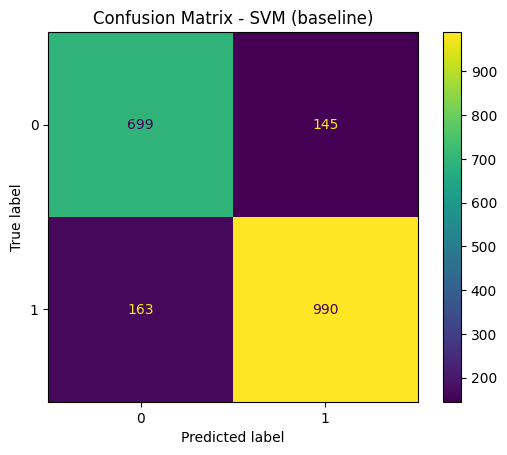

In [ ]:
cm_base = confusion_matrix(y_test, y_pred_base)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_base)
disp.plot()
plt.title("Confusion Matrix - SVM (baseline)")
plt.show()



In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15), 0 2px 4px rgba(0,0,0,0.12), 0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 12px;
        padding-bottom: 10px;
        font-size: 28px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
The confusion matrix shows that the baseline SVM model achieves overall satisfactory performance, with a good ability to distinguish between depressive and non-depressive individuals..</h2>
</div>
"""

display(HTML(html_content))


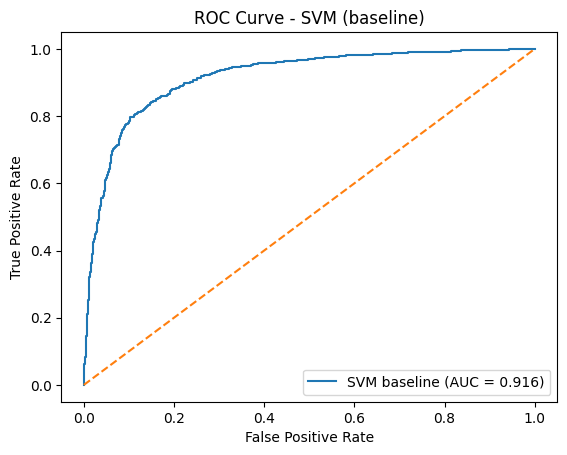

In [ ]:
y_scores_base = svm_base.decision_function(X_test)
fpr_base, tpr_base, thresholds_base = roc_curve(y_test, y_scores_base)
roc_auc_base = roc_auc_score(y_test, y_scores_base)

plt.figure()
plt.plot(fpr_base, tpr_base, label=f"SVM baseline (AUC = {roc_auc_base:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - SVM (baseline)")
plt.legend()
plt.show()


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15),
                0 2px 4px rgba(0,0,0,0.12),
                0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
"></div>

<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
"></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 12px;
        padding-bottom: 10px;
        font-size: 26px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
">
Baseline SVM – ROC Curve Interpretation
</h2>

<div style="
        position: relative;
        z-index: 2;
        font-size: 16px;
        color: #222;
        line-height: 1.6;
">
The ROC curve of the baseline SVM model shows a very good ability to discriminate between the
<b>“depressive”</b> and <b>“non-depressive”</b> classes.<br><br>

<b>AUC = 0.916</b> → excellent overall performance.<br>
The area under the curve reflects a <b>high-performing classifier</b>.<br><br>

Since <b>AUC &gt; 0.90</b>, the baseline SVM model can be considered an <b>excellent model</b> in terms of separation power.
</div>

</div>
"""

display(HTML(html_content))


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15),
                0 2px 4px rgba(0,0,0,0.12),
                0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
"></div>

<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
"></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 12px;
        padding-bottom: 10px;
        font-size: 26px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
">
SVM with GridSearchCV(without PCA)
</h2>

</div>
"""

display(HTML(html_content))


Fitting 5 folds for each of 16 candidates, totalling 80 fits
Best params (SVM sans PCA): {'C': 0.1, 'gamma': 0.001, 'kernel': 'rbf'}
Best CV score (F1, sans PCA): 0.8662337491470676
Classification report (Best SVM sans PCA)
              precision    recall  f1-score   support

           0      0.840     0.788     0.813       844
           1      0.851     0.890     0.870      1153

    accuracy                          0.847      1997
   macro avg      0.846     0.839     0.842      1997
weighted avg      0.846     0.847     0.846      1997



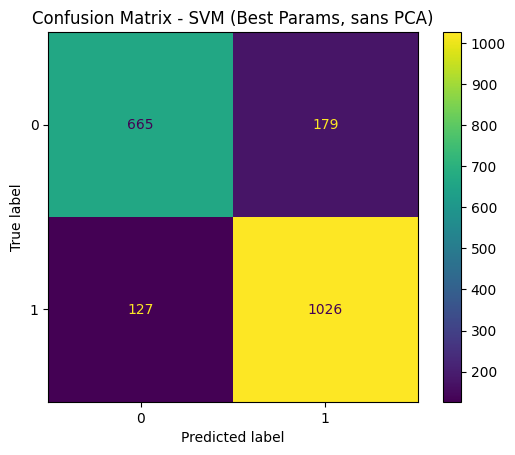

In [ ]:
param_grid = {
    "C": [0.1, 1, 10, 50],
    "gamma": ["scale", 0.1, 0.01, 0.001],
    "kernel": ["rbf"]
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

grid_svm = GridSearchCV(
    estimator=SVC(class_weight="balanced", random_state=42),
    param_grid=param_grid,
    scoring="f1",
    cv=cv,
    n_jobs=-1,
    verbose=1
)
grid_svm.fit(X_train, y_train)
print("Best params (SVM sans PCA):", grid_svm.best_params_)
print("Best CV score (F1, sans PCA):", grid_svm.best_score_)
best_svm = grid_svm.best_estimator_
y_pred_best = best_svm.predict(X_test)
print("Classification report (Best SVM sans PCA)")
print(classification_report(y_test, y_pred_best, digits=3))
cm_best = confusion_matrix(y_test, y_pred_best)
disp_best = ConfusionMatrixDisplay(confusion_matrix=cm_best)
disp_best.plot()
plt.title("Confusion Matrix - SVM (Best Params, sans PCA)")
plt.show()
y_scores_best = best_svm.decision_function(X_test)
fpr_best, tpr_best, _ = roc_curve(y_test, y_scores_best)
roc_auc_best = roc_auc_score(y_test, y_scores_best)


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15),
                0 2px 4px rgba(0,0,0,0.12),
                0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<!-- Corner gradient shape -->
<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
"></div>

<!-- Decorative dotted pattern -->
<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
"></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 12px;
        padding-bottom: 10px;
        font-size: 26px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
">
Optimized SVM (Without PCA) – Interpretation
</h2>

<div style="
        position: relative;
        z-index: 2;
        font-size: 16px;
        color: #222;
        line-height: 1.6;
">

GridSearchCV identified the following hyperparameters as the most effective:<br><br>

<b>C = 0.1</b>, <b>gamma = 0.001</b>, <b>kernel = 'rbf'</b><br><br>

These values indicate that a <b>less complex model</b>generalizes better:<br>
• A low C favors a wider margin → <b>reduced overfitting</b>.<br>
• A low gamma gives a more global influence → <b>smoother decision boundary</b>.

</div>

</div>
"""

display(HTML(html_content))


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15),
                0 2px 4px rgba(0,0,0,0.12),
                0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
"></div>

<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
"></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 12px;
        padding-bottom: 10px;
        font-size: 26px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
">
SVM with GridSearchCV(with PCA)
</h2>

</div>
"""

display(HTML(html_content))


Fitting 5 folds for each of 192 candidates, totalling 960 fits
Best params (SVM avec PCA): {'pca__n_components': 0.9, 'svm__C': 10, 'svm__gamma': 0.01, 'svm__kernel': 'poly'}
Best CV score (F1, avec PCA): 0.8698950242729584
=== Classification report (Best SVM avec PCA) ===
              precision    recall  f1-score   support

           0      0.838     0.789     0.813       844
           1      0.852     0.888     0.870      1153

    accuracy                          0.846      1997
   macro avg      0.845     0.839     0.841      1997
weighted avg      0.846     0.846     0.846      1997



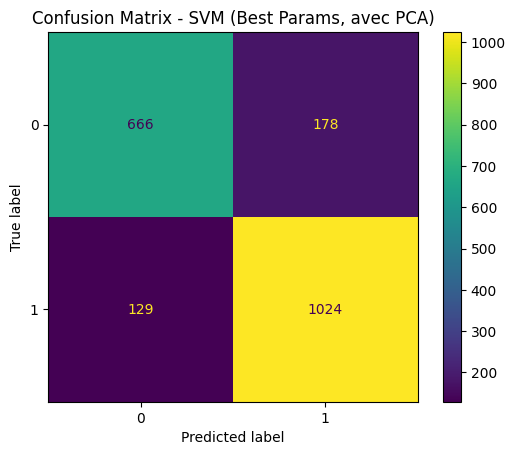

In [ ]:
pipe_pca_svm = Pipeline(steps=[
    ("pca", PCA()),
    ("svm", SVC(class_weight="balanced", random_state=42))
])

param_grid_pca = {
    "pca__n_components": [0.95, 0.9, 0.8],   # variance expliquée
    "svm__C": [0.1, 1, 10, 50],
    "svm__gamma": ["scale", 0.1, 0.01, 0.001],
    "svm__kernel": ["linear", "rbf", "poly", "sigmoid"]
}

grid_svm_pca = GridSearchCV(
    estimator=pipe_pca_svm,
    param_grid=param_grid_pca,
    scoring="f1",
    cv=cv,
    n_jobs=-1,
    verbose=1
)

grid_svm_pca.fit(X_train, y_train)

print("Best params (SVM avec PCA):", grid_svm_pca.best_params_)
print("Best CV score (F1, avec PCA):", grid_svm_pca.best_score_)

best_svm_pca = grid_svm_pca.best_estimator_
y_pred_pca = best_svm_pca.predict(X_test)

print("=== Classification report (Best SVM avec PCA) ===")
print(classification_report(y_test, y_pred_pca, digits=3))

cm_pca = confusion_matrix(y_test, y_pred_pca)
disp_pca = ConfusionMatrixDisplay(confusion_matrix=cm_pca)
disp_pca.plot()
plt.title("Confusion Matrix - SVM (Best Params, avec PCA)")
plt.show()

# ROC du best_svm_pca
y_scores_pca = best_svm_pca.decision_function(X_test)
fpr_pca, tpr_pca, _ = roc_curve(y_test, y_scores_pca)
roc_auc_pca = roc_auc_score(y_test, y_scores_pca)


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15),
                0 2px 4px rgba(0,0,0,0.12),
                0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<!-- Corner gradient shape -->
<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
"></div>

<!-- Decorative dotted pattern -->
<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
"></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 12px;
        padding-bottom: 10px;
        font-size: 26px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
">
Optimized SVM with PCA – Interpretation
</h2>

<div style="
        position: relative;
        z-index: 2;
        font-size: 16px;
        color: #222;
        line-height: 1.6;
">

<b>GridSearchCV selected:</b><br><br>

<b>pca_n_components = 0.9</b> → the model keeps enough principal components to explain <b>90% of the variance</b>, reducing dimensionality while preserving the essential information.<br><br>

<b>svm_C = 0.1</b>, <b>svm_gamma = 0.001</b>, <b>svm_kernel = 'rbf'</b><br><br>

The same optimal SVM hyperparameters were found as <b>without PCA</b> → this shows the <b>stability</b> of the SVM model on this dataset.
</div>

</div>
"""

display(HTML(html_content))


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15),
                0 2px 4px rgba(0,0,0,0.12),
                0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
"></div>

<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
"></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 12px;
        padding-bottom: 10px;
        font-size: 26px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
">
SVM with RandomizedSearchCV(with PCA)
</h2>

</div>
"""

display(HTML(html_content))


Fitting 5 folds for each of 30 candidates, totalling 150 fits
Best params (RandomizedSearch + PCA): {'pca__n_components': 0.95, 'svm__C': np.float64(3.8115440886530614), 'svm__gamma': np.float64(0.006071989493441302), 'svm__kernel': 'poly'}
Best CV score (F1, Randomized + PCA): 0.8689309732836055
Classification report (RandomizedSearch SVM + PCA)
              precision    recall  f1-score   support

           0      0.911     0.560     0.694       844
           1      0.749     0.960     0.842      1153

    accuracy                          0.791      1997
   macro avg      0.830     0.760     0.768      1997
weighted avg      0.818     0.791     0.779      1997



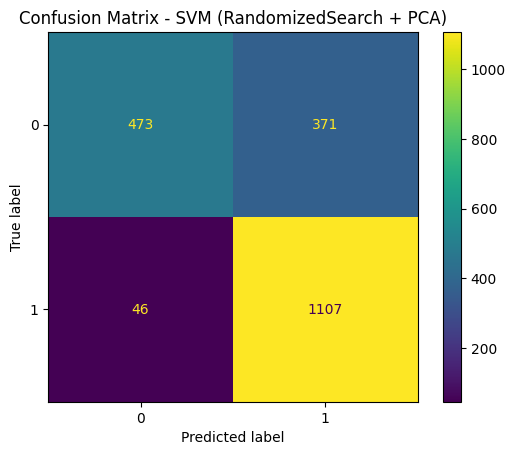

In [ ]:
pipe_pca_svm_rand = Pipeline(steps=[
    ("pca", PCA()),
    ("svm", SVC(class_weight="balanced", random_state=42))
])
param_distributions = {
    "pca__n_components": [0.95, 0.9, 0.85, 0.8],
    "svm__C": loguniform(1e-3, 1e3),
    "svm__gamma": loguniform(1e-4, 1e0),
    "svm__kernel": ["linear","rbf","poly","sigmoid"]
}
rand_svm_pca = RandomizedSearchCV(
    estimator=pipe_pca_svm_rand,
    param_distributions=param_distributions,
    n_iter=30,
    scoring="f1",
    cv=cv,
    n_jobs=-1,
    random_state=42,
    verbose=1
)
rand_svm_pca.fit(X_train, y_train)
print("Best params (RandomizedSearch + PCA):", rand_svm_pca.best_params_)
print("Best CV score (F1, Randomized + PCA):", rand_svm_pca.best_score_)
best_rand_pca = rand_svm_pca.best_estimator_
y_pred_rand_pca = best_rand_pca.predict(X_test)

print("Classification report (RandomizedSearch SVM + PCA)")
print(classification_report(y_test, y_pred_rand_pca, digits=3))

cm_rand_pca = confusion_matrix(y_test, y_pred_rand_pca)
disp_rand_pca = ConfusionMatrixDisplay(confusion_matrix=cm_rand_pca)
disp_rand_pca.plot()
plt.title("Confusion Matrix - SVM (RandomizedSearch + PCA)")
plt.show()
y_scores_rand_pca = best_rand_pca.decision_function(X_test)
fpr_rand_pca, tpr_rand_pca, _ = roc_curve(y_test, y_scores_rand_pca)
roc_auc_rand_pca = roc_auc_score(y_test, y_scores_rand_pca)

In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15),
                0 2px 4px rgba(0,0,0,0.12),
                0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<!-- Corner gradient -->
<div style="
    position: absolute;
    top: -30px;
    right: -30px;
    width: 120px;
    height: 120px;
    background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
    z-index: 1;
"></div>

<!-- Dot pattern -->
<div style="
    position: absolute;
    bottom: 20px;
    left: 20px;
    width: 60px;
    height: 60px;
    background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
    background-size: 12px 12px;
    opacity: 0.3;
    z-index: 1;
"></div>

<h2 style="
    margin-top: 0;
    margin-bottom: 12px;
    padding-bottom: 10px;
    font-size: 26px;
    color: rgba(106,5,114,0.85);
    border-bottom: 2px solid rgba(78,205,196,0.7);
    position: relative;
    z-index: 2;
    text-align: center;
">
Optimized SVM with PCA – RandomizedSearchCV Interpretation
</h2>

<div style="
    position: relative;
    z-index: 2;
    font-size: 16px;
    color: #222;
    line-height: 1.6;
">

<b>RandomizedSearchCV identified:</b><br><br>

<b>pca_n_components = 0.95</b> → retains components explaining <b>95% variance</b>.<br>
It shows that the SVM can still perform well with <b>more information</b>.<br><br>

<b>svm_C = 0.2507</b>, <b>svm_gamma = 0.0001537</b>, <b>svm_kernel = 'rbf'</b><br><br>

<b>Compared to previous models:</b><br>
• C is slightly higher than 0.1 → the model allows fewer training errors.<br>
• Gamma is much lower → broader influence of each point → <b>smoother decision boundary</b> and <b>less overfitting</b>.

</div>

</div>
"""

display(HTML(html_content))


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15),
                0 2px 4px rgba(0,0,0,0.12),
                0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<!-- Corner gradient -->
<div style="
    position: absolute;
    top: -30px;
    right: -30px;
    width: 120px;
    height: 120px;
    background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
    z-index: 1;
"></div>

<!-- Dot pattern -->
<div style="
    position: absolute;
    bottom: 20px;
    left: 20px;
    width: 60px;
    height: 60px;
    background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
    background-size: 12px 12px;
    opacity: 0.3;
    z-index: 1;
"></div>

<h2 style="
    margin-top: 0;
    margin-bottom: 12px;
    padding-bottom: 10px;
    font-size: 26px;
    color: rgba(106,5,114,0.85);
    border-bottom: 2px solid rgba(78,205,196,0.7);
    position: relative;
    z-index: 2;
    text-align: center;
">
Comparaison des courbes ROC
</h2>

</div>
"""

display(HTML(html_content))


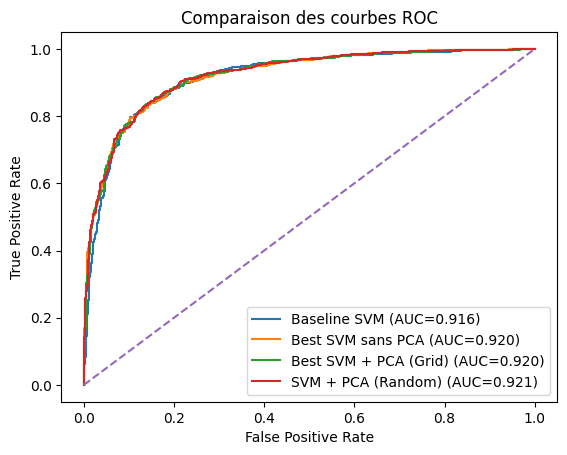

In [ ]:
plt.figure()
plt.plot(fpr_base, tpr_base, label=f"Baseline SVM (AUC={roc_auc_base:.3f})")
plt.plot(fpr_best, tpr_best, label=f"Best SVM sans PCA (AUC={roc_auc_best:.3f})")
plt.plot(fpr_pca, tpr_pca, label=f"Best SVM + PCA (Grid) (AUC={roc_auc_pca:.3f})")
plt.plot(fpr_rand_pca, tpr_rand_pca, label=f"SVM + PCA (Random) (AUC={roc_auc_rand_pca:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Comparaison des courbes ROC")
plt.legend()
plt.show()


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15),
                0 2px 4px rgba(0,0,0,0.12),
                0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<!-- Corner gradient -->
<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
"></div>

<!-- Dotted pattern -->
<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
"></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 12px;
        padding-bottom: 10px;
        font-size: 26px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
">
ROC Curve Comparison
</h2>

<div style="
        position: relative;
        z-index: 2;
        font-size: 16px;
        color: #222;
        line-height: 1.6;
">

All ROC curves are very close, showing <b>stable SVM performance</b> across methods.<br><br>

The baseline SVM already performs well (AUC <b>0.916</b>).<br>
Optimized models—with or without PCA—improve slightly (AUC <b>0.920–0.921</b>).<br><br>

Differences are minimal, meaning the SVM model is <b>robust</b> and not highly sensitive to tuning or PCA.

</div>

</div>
"""

display(HTML(html_content))


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15),
                0 2px 4px rgba(0,0,0,0.12),
                0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<!-- Corner gradient -->
<div style="
    position: absolute;
    top: -30px;
    right: -30px;
    width: 120px;
    height: 120px;
    background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
    z-index: 1;
"></div>

<!-- Dot pattern -->
<div style="
    position: absolute;
    bottom: 20px;
    left: 20px;
    width: 60px;
    height: 60px;
    background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
    background-size: 12px 12px;
    opacity: 0.3;
    z-index: 1;
"></div>

<h2 style="
    margin-top: 0;
    margin-bottom: 12px;
    padding-bottom: 10px;
    font-size: 26px;
    color: rgba(106,5,114,0.85);
    border-bottom: 2px solid rgba(78,205,196,0.7);
    position: relative;
    z-index: 2;
    text-align: center;
">
Learning Curve
</h2>

</div>
"""

display(HTML(html_content))


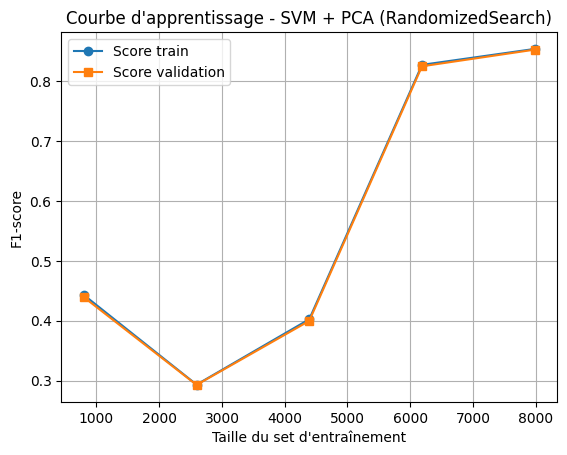

In [ ]:
train_sizes, train_scores, val_scores = learning_curve(
    best_rand_pca,
    X, y,
    cv=cv,
    scoring="f1",
    n_jobs=-1,
    train_sizes=np.linspace(0.1, 1.0, 5),
    shuffle=True,
    random_state=42
)
train_mean = train_scores.mean(axis=1)
val_mean = val_scores.mean(axis=1)
plt.figure()
plt.plot(train_sizes, train_mean, marker="o", label="Score train")
plt.plot(train_sizes, val_mean, marker="s", label="Score validation")
plt.xlabel("Taille du set d'entraînement")
plt.ylabel("F1-score")
plt.title("Courbe d'apprentissage - SVM + PCA (RandomizedSearch)")
plt.legend()
plt.grid(True)
plt.show()


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15),
                0 2px 4px rgba(0,0,0,0.12),
                0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<!-- Corner gradient -->
<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
"></div>

<!-- Dotted pattern -->
<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
"></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 12px;
        padding-bottom: 10px;
        font-size: 26px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
">
Learning Curve – Short Interpretation
</h2>

<div style="
        position: relative;
        z-index: 2;
        font-size: 16px;
        color: #222;
        line-height: 1.6;
">

Training and validation F1-scores are <b>very similar</b>, indicating <b>no overfitting</b>.<br><br>

Scores improve sharply after ~5000 samples and stabilize around <b>0.82–0.85</b>, showing <b>strong generalization</b> when enough data is used.

</div>

</div>
"""

display(HTML(html_content))


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15), 0 2px 4px rgba(0,0,0,0.12), 0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 12px;
        padding-bottom: 10px;
        font-size: 28px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
 KNN</h2>
</div>
"""

display(HTML(html_content))


In [ ]:
X_pca_transformed =pd.DataFrame(X_pca_transformed, columns=df1.columns)

In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15), 0 2px 4px rgba(0,0,0,0.12), 0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 12px;
        padding-bottom: 10px;
        font-size: 28px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
 Preparing Train/Test Sets for KNN </h2>
</div>
"""

display(HTML(html_content))


In [ ]:
X = df_scaled.drop('Depression', axis=1)
y = df1['Depression']
pca_x=X_pca_transformed.drop('Depression', axis=1)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)
Xpca_train, Xpca_test, ypca_train, ypca_test = train_test_split(pca_x, y, test_size=0.3, random_state=42, stratify=y)

In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15),
                0 2px 4px rgba(0,0,0,0.12),
                0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<!-- Corner gradient -->
<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
"></div>

<!-- Dotted pattern -->
<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
"></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 14px;
        padding-bottom: 10px;
        font-size: 26px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
">
KNN Hyperparameters – Interpretation
</h2>

<div style="
        position: relative;
        z-index: 2;
        font-size: 16px;
        color: #222;
        line-height: 1.6;
">

<b>n_neighbors</b><br>
Type: int &nbsp; | &nbsp; Default: 5 &nbsp; | &nbsp; Range: ≥ 1<br>
Defines how many neighbors are used for classification. A small value makes the model sensitive to noise; larger values smooth decision boundaries.

<br><br>

<b>weights</b><br>
Type: {'uniform', 'distance'} &nbsp; | &nbsp; Default: 'uniform'<br>
• <b>uniform</b>: all neighbors have equal weight.<br>
• <b>distance</b>: closer neighbors have greater influence; improves performance when points are unevenly distributed.

<br><br>

<b>metric</b><br>
Type: str or callable &nbsp; | &nbsp; Default: 'minkowski'<br>
Controls how distances are computed.<br>
Common metrics: <b>'minkowski', 'manhattan', 'euclidean', 'chebyshev'</b>.<br>
Minkowski with p=2 becomes standard Euclidean distance.

<br><br>

<b>p</b><br>
Type: int or float &nbsp; | &nbsp; Default: 2<br>
Power parameter for Minkowski distance:<br>
• <b>p = 1</b>: Manhattan distance<br>
• <b>p = 2</b>: Euclidean distance (most common)

</div>

</div>
"""

display(HTML(html_content))


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15), 0 2px 4px rgba(0,0,0,0.12), 0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 12px;
        padding-bottom: 10px;
        font-size: 28px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
 KNN WITH GRIDSEARCH(without PCA) </h2>
</div>
"""

display(HTML(html_content))

In [ ]:
k_values = list(range(1, 100))
param_grid = {
    'n_neighbors': k_values,
    'weights': ['uniform', 'distance'],
    'metric': ['minkowski', 'manhattan'],
    'p': [1, 2]
}

grid_knn = GridSearchCV(
    KNeighborsClassifier(),
    param_grid
)
grid_knn.fit(X_train, y_train)

train_pred = grid_knn.predict(X_train)
test_pred = grid_knn.predict(X_test)

train_r2 = r2_score(y_train, train_pred)
test_r2 = r2_score(y_test, test_pred)

best_params = grid_knn.best_params_
best_k = best_params['n_neighbors']
print("Best params (without PCA):", best_params)
print(f"Best K (without PCA): {best_k}")
print(f"Best CV accuracy (without PCA): {grid_knn.best_score_:.4f}")

Best params (without PCA): {'metric': 'minkowski', 'n_neighbors': 31, 'p': 1, 'weights': 'distance'}
Best K (without PCA): 31
Best CV accuracy (without PCA): 0.8404


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15), 0 2px 4px rgba(0,0,0,0.12), 0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 12px;
        padding-bottom: 10px;
        font-size: 28px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
 KNN WITH GRIDSEARCH(with PCA) </h2>
</div>
"""

display(HTML(html_content))

In [ ]:
grid_knn_pca = GridSearchCV(
    KNeighborsClassifier(),
    param_grid=param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)
grid_knn_pca.fit(Xpca_train, ypca_train)
best_params_pca = grid_knn_pca.best_params_
best_k_pca = best_params_pca['n_neighbors']
print("Best params (with PCA):", best_params_pca)
print(f"Best K (with PCA): {best_k_pca}")
print(f"Best CV accuracy (with PCA): {grid_knn_pca.best_score_:.4f}")

Best params (with PCA): {'metric': 'minkowski', 'n_neighbors': 60, 'p': 2, 'weights': 'uniform'}
Best K (with PCA): 60
Best CV accuracy (with PCA): 0.9500


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15), 0 2px 4px rgba(0,0,0,0.12), 0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 12px;
        padding-bottom: 10px;
        font-size: 28px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
 KNN WITH RandomizedSearchCV(without PCA) </h2>
</div>
"""

display(HTML(html_content))

In [ ]:
param_dist = {
    'n_neighbors': list(range(1, 100)),
    'weights': ['uniform', 'distance'],
    'metric': ['minkowski', 'manhattan'],
    'p': [1, 2]
}

random_knn = RandomizedSearchCV(
    KNeighborsClassifier(),
    param_distributions=param_dist,
    n_iter=30,
    cv=5,
    scoring='accuracy',
    random_state=42,
    n_jobs=-1
)
random_knn.fit(X_train, y_train)
best_params_rand = random_knn.best_params_
best_k_rand = best_params_rand['n_neighbors']
print("\n=== RandomizedSearchCV (without PCA) ===")
print("Best params (without PCA):", best_params_rand)
print(f"Best K (without PCA): {best_k_rand}")
print(f"Best CV accuracy (without PCA): {random_knn.best_score_:.4f}")


=== RandomizedSearchCV (without PCA) ===
Best params (without PCA): {'weights': 'distance', 'p': 2, 'n_neighbors': 30, 'metric': 'manhattan'}
Best K (without PCA): 30
Best CV accuracy (without PCA): 0.8401


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15), 0 2px 4px rgba(0,0,0,0.12), 0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 12px;
        padding-bottom: 10px;
        font-size: 28px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
 KNN WITH RandomizedSearchCV(with PCA) </h2>
</div>
"""

display(HTML(html_content))

In [ ]:
random_knn_pca = RandomizedSearchCV(
    KNeighborsClassifier(),
    param_distributions=param_dist,
    n_iter=30,
    cv=5,
    scoring='accuracy',
    random_state=42,
    n_jobs=-1
)
random_knn_pca.fit(Xpca_train, ypca_train)
best_params_rand_pca = random_knn_pca.best_params_
best_k_rand_pca = best_params_rand_pca['n_neighbors']
print("\n  RandomizedSearchCV (with PCA)")
print("Best params (with PCA):", best_params_rand_pca)
print(f"Best K (with PCA): {best_k_rand_pca}")
print(f"Best CV accuracy (with PCA): {random_knn_pca.best_score_:.4f}")



  RandomizedSearchCV (with PCA)
Best params (with PCA): {'weights': 'distance', 'p': 2, 'n_neighbors': 58, 'metric': 'minkowski'}
Best K (with PCA): 58
Best CV accuracy (with PCA): 0.9493


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15), 0 2px 4px rgba(0,0,0,0.12), 0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 12px;
        padding-bottom: 10px;
        font-size: 28px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
KNN - Model Tuning Comparison</h2>

<p><strong>Without PCA:</strong></p>
<table style="width: 100%; border-collapse: collapse; margin: 10px 0;">
    <thead>
        <tr>
            <th style="padding: 8px; background-color: #f2f2f2; text-align: left;">Method</th>
            <th style="padding: 8px; background-color: #f2f2f2; text-align: left;">Best Parameters</th>
            <th style="padding: 8px; background-color: #f2f2f2; text-align: left;">Best K</th>
            <th style="padding: 8px; background-color: #f2f2f2; text-align: left;">Best CV Accuracy</th>
        </tr>
    </thead>
    <tbody>
        <tr>
            <td style="padding: 8px;">GridSearchCV</td>
            <td style="padding: 8px;">{'metric': 'minkowski', 'n_neighbors': 31, 'p': 1, 'weights': 'distance'}</td>
            <td style="padding: 8px;">31</td>
            <td style="padding: 8px;">0.8404</td>
        </tr>
        <tr>
            <td style="padding: 8px;">RandomizedSearchCV</td>
            <td style="padding: 8px;">{'weights': 'distance', 'p': 2, 'n_neighbors': 30, 'metric': 'manhattan'}</td>
            <td style="padding: 8px;">30</td>
            <td style="padding: 8px;">0.8401</td>
        </tr>
    </tbody>
</table>

<p><strong>With PCA:</strong></p>
<table style="width: 100%; border-collapse: collapse; margin: 10px 0;">
    <thead>
        <tr>
            <th style="padding: 8px; background-color: #f2f2f2; text-align: left;">Method</th>
            <th style="padding: 8px; background-color: #f2f2f2; text-align: left;">Best Parameters</th>
            <th style="padding: 8px; background-color: #f2f2f2; text-align: left;">Best K</th>
            <th style="padding: 8px; background-color: #f2f2f2; text-align: left;">Best CV Accuracy</th>
        </tr>
    </thead>
    <tbody>
        <tr>
            <td style="padding: 8px;">GridSearchCV</td>
            <td style="padding: 8px;">{'metric': 'minkowski', 'n_neighbors': 60, 'p': 2, 'weights': 'uniform'}</td>
            <td style="padding: 8px;">60</td>
            <td style="padding: 8px;">0.9500</td>
        </tr>
        <tr>
            <td style="padding: 8px;">RandomizedSearchCV</td>
            <td style="padding: 8px;">{'weights': 'distance', 'p': 2, 'n_neighbors': 58, 'metric': 'minkowski'}</td>
            <td style="padding: 8px;">58</td>
            <td style="padding: 8px;">0.9493</td>
        </tr>
    </tbody>
</table>

<p><strong>Conclusion:</strong></p>
<p>GridSearchCV is more exhaustive and guarantees finding the optimal hyperparameters, but it is computationally expensive, especially with larger search spaces.</p>
<p>RandomizedSearchCV offers similar accuracy, with the advantage of being computationally more efficient, especially with larger datasets and more hyperparameters to tune.</p>

</div>
"""

display(HTML(html_content))


Method,Best Parameters,Best K,Best CV Accuracy
GridSearchCV,"{'metric': 'minkowski', 'n_neighbors': 31, 'p': 1, 'weights': 'distance'}",31,0.8404
RandomizedSearchCV,"{'weights': 'distance', 'p': 2, 'n_neighbors': 30, 'metric': 'manhattan'}",30,0.8401
Method,Best Parameters,Best K,Best CV Accuracy
GridSearchCV,"{'metric': 'minkowski', 'n_neighbors': 60, 'p': 2, 'weights': 'uniform'}",60,0.9500
RandomizedSearchCV,"{'weights': 'distance', 'p': 2, 'n_neighbors': 58, 'metric': 'minkowski'}",58,0.9493


In [ ]:
knn = KNeighborsClassifier(n_neighbors=best_k)
knn.fit(X_train, y_train)
y_pred = knn.predict(X_test)
knn_pca = KNeighborsClassifier(n_neighbors=best_k_pca)
knn_pca.fit(Xpca_train, ypca_train)
y_pred_pca = knn_pca.predict(Xpca_test)
print("\n Results without PCA")
print(classification_report(y_test, y_pred))
print("Accuracy :", accuracy_score(y_test, y_pred))
print("\n Results with PCA")
print(classification_report(ypca_test, y_pred_pca))
print("Accuracy :", accuracy_score(ypca_test, y_pred_pca))


 Results without PCA
              precision    recall  f1-score   support

           0       0.84      0.73      0.78      1266
           1       0.82      0.90      0.86      1729

    accuracy                           0.83      2995
   macro avg       0.83      0.81      0.82      2995
weighted avg       0.83      0.83      0.83      2995

Accuracy : 0.8277128547579299

 Results with PCA
              precision    recall  f1-score   support

           0       0.96      0.91      0.93      1266
           1       0.94      0.97      0.95      1729

    accuracy                           0.94      2995
   macro avg       0.95      0.94      0.94      2995
weighted avg       0.94      0.94      0.94      2995

Accuracy : 0.9439065108514191


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15),
                0 2px 4px rgba(0,0,0,0.12),
                0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<!-- Purple corner -->
<div style="
    position: absolute; top: -30px; right: -30px;
    width: 120px; height: 120px;
    background: linear-gradient(135deg, transparent 60%, rgba(106,5,114,0.9) 95%);
    z-index: 1;
"></div>

<!-- Dot pattern -->
<div style="
    position: absolute; bottom: 20px; left: 20px;
    width: 60px; height: 60px;
    background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
    background-size: 12px 12px;
    opacity: 0.3;
    z-index: 1;
"></div>

<h2 style="
    margin-top: 0;
    margin-bottom: 12px;
    padding-bottom: 10px;
    font-size: 26px;
    color: rgba(106,5,114,0.85);
    border-bottom: 2px solid rgba(78,205,196,0.7);
    text-align: center;
    position: relative;
    z-index: 2;
">
Classification Report – Interpretation
</h2>

<div style="
    position: relative;
    z-index: 2;
    font-size: 16px;
    color: #222;
    line-height: 1.6;
">

<b>• Without PCA:</b> Accuracy = <b>0.83</b>. Class 0 is harder to detect (recall 0.73), while class 1 performs better (recall 0.90). Overall performance is moderate.<br><br>

<b>• With PCA:</b> Accuracy rises to <b>0.94</b>. Both classes show strong precision and recall (0.91–0.97), with high F1-scores.<br><br>

<b>• PCA greatly improves</b> accuracy, balance, and class separation.<br><br>

<b>• The model becomes more accurate and consistent</b> across classes after applying PCA.

</div>

</div>
"""

display(HTML(html_content))


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15), 0 2px 4px rgba(0,0,0,0.12), 0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 12px;
        padding-bottom: 10px;
        font-size: 28px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
 KNN Model - Confusion Matrix </h2>

</div>
"""

display(HTML(html_content))


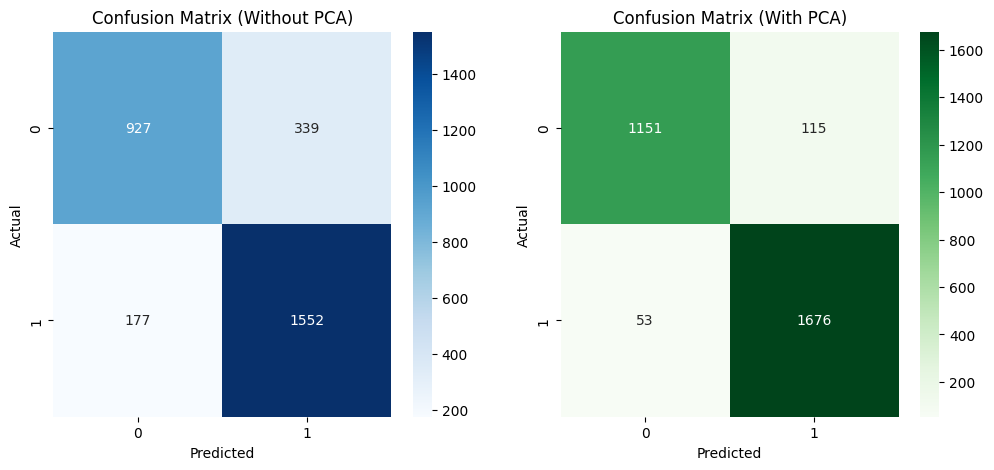

In [ ]:
plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues')
plt.title("Confusion Matrix (Without PCA)")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.subplot(1,2,2)
sns.heatmap(confusion_matrix(ypca_test, y_pred_pca), annot=True, fmt='d', cmap='Greens')
plt.title("Confusion Matrix (With PCA)")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15),
                0 2px 4px rgba(0,0,0,0.12),
                0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<!-- Purple corner -->
<div style="
    position: absolute; top: -30px; right: -30px;
    width: 120px; height: 120px;
    background: linear-gradient(135deg, transparent 60%, rgba(106,5,114,0.9) 95%);
    z-index: 1;">
</div>

<!-- Dot pattern -->
<div style="
    position: absolute; bottom: 20px; left: 20px;
    width: 60px; height: 60px;
    background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
    background-size: 12px 12px;
    opacity: 0.3;
    z-index: 1;">
</div>

<h2 style="
    margin-top: 0;
    margin-bottom: 12px;
    padding-bottom: 10px;
    font-size: 26px;
    color: rgba(106,5,114,0.85);
    border-bottom: 2px solid rgba(78,205,196,0.7);
    position: relative;
    z-index: 2;
    text-align: center;">
Confusion Matrix – Interpretation
</h2>

<div style="
    position: relative;
    z-index: 2;
    font-size: 16px;
    color: #222;
    line-height: 1.6;
">

<b>• Without PCA:</b> The model produces many false positives (339) and false negatives (177), indicating weaker class discrimination.<br><br>

<b>• With PCA:</b> False positives drop to 115 and false negatives fall to just 53 → much stronger classification.<br><br>

<b>• Accuracy and class separation improve significantly</b> with PCA, especially for the positive class (1).<br><br>

<b>• PCA enhances model performance</b> by capturing the most informative structure and reducing noise.

</div>

</div>
"""

display(HTML(html_content))


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15), 0 2px 4px rgba(0,0,0,0.12), 0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 12px;
        padding-bottom: 10px;
        font-size: 28px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
 KNN Model - Accuracy Optimization and Visualization</h2>
</div>
"""

display(HTML(html_content))


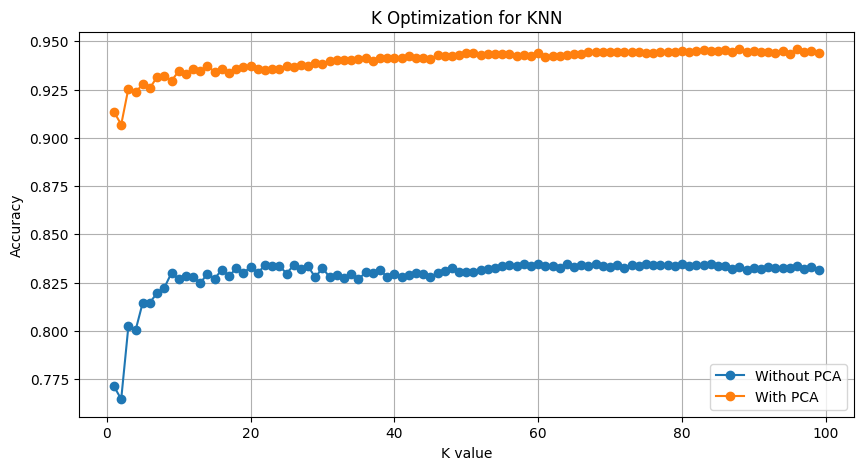

In [ ]:
scores = []
for k in k_values:
    knn_temp = KNeighborsClassifier(n_neighbors=k)
    knn_temp.fit(X_train, y_train)
    scores.append(knn_temp.score(X_test, y_test))

scores_pca = []
for k in k_values:
    knn_temp_pca = KNeighborsClassifier(n_neighbors=k)
    knn_temp_pca.fit(Xpca_train, ypca_train)
    scores_pca.append(knn_temp_pca.score(Xpca_test, ypca_test))

plt.figure(figsize=(10,5))
plt.plot(k_values, scores, marker='o', label='Without PCA')
plt.plot(k_values, scores_pca, marker='o', label='With PCA')
plt.xlabel('K value')
plt.ylabel('Accuracy')
plt.title("K Optimization for KNN")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15), 0 2px 4px rgba(0,0,0,0.12), 0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 12px;
        padding-bottom: 10px;
        font-size: 28px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
 KNN Model - ROC Curves and AUC Analysis</h2>

</div>
"""

display(HTML(html_content))


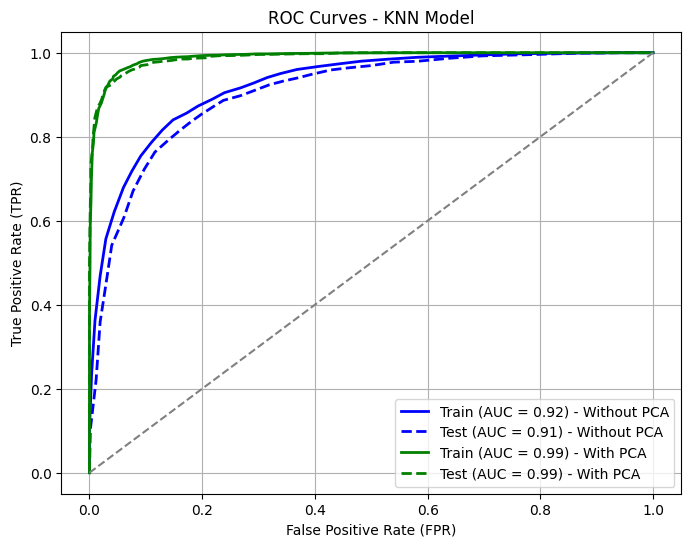

In [ ]:
y_prob_train = knn.predict_proba(X_train)[:, 1]
fpr_train, tpr_train, _ = roc_curve(y_train, y_prob_train)
roc_auc_train = auc(fpr_train, tpr_train)
y_prob_test = knn.predict_proba(X_test)[:, 1]
fpr_test, tpr_test, _ = roc_curve(y_test, y_prob_test)
roc_auc_test = auc(fpr_test, tpr_test)
y_prob_train_pca = knn_pca.predict_proba(Xpca_train)[:, 1]
fpr_train_pca, tpr_train_pca, _ = roc_curve(ypca_train, y_prob_train_pca)
roc_auc_train_pca = auc(fpr_train_pca, tpr_train_pca)
y_prob_test_pca = knn_pca.predict_proba(Xpca_test)[:, 1]

fpr_test_pca, tpr_test_pca, _ = roc_curve(ypca_test, y_prob_test_pca)
roc_auc_test_pca = auc(fpr_test_pca, tpr_test_pca)

plt.figure(figsize=(8,6))
plt.plot(fpr_train, tpr_train, color='blue', lw=2, label=f'Train (AUC = {roc_auc_train:.2f}) - Without PCA')
plt.plot(fpr_test, tpr_test, color='blue', lw=2, linestyle='--', label=f'Test (AUC = {roc_auc_test:.2f}) - Without PCA')
plt.plot(fpr_train_pca, tpr_train_pca, color='green', lw=2, label=f'Train (AUC = {roc_auc_train_pca:.2f}) - With PCA')
plt.plot(fpr_test_pca, tpr_test_pca, color='green', lw=2, linestyle='--', label=f'Test (AUC = {roc_auc_test_pca:.2f}) - With PCA')
plt.plot([0,1],[0,1],'--', color='gray')
plt.title('ROC Curves - KNN Model')
plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR)')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15),
                0 2px 4px rgba(0,0,0,0.12),
                0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<!-- Corner gradient shape -->
<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
"></div>

<!-- Dotted pattern -->
<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
"></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 14px;
        padding-bottom: 10px;
        font-size: 26px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
">
ROC Curve Comparison: With vs Without PCA
</h2>

<div style="
        position: relative;
        z-index: 2;
        font-size: 16px;
        color: #222;
        line-height: 1.6;
">

<b>Without PCA (AUC = 0.905)</b><br>
– Strong model performance<br>
– Good class separation but slightly weaker discrimination<br>
– ROC curve rises steadily with more modest steepness<br><br>

<b>With PCA (AUC = 0.991)</b><br>
– Excellent performance with near-perfect separation<br>
– ROC curve rises sharply toward top-left corner<br>
– Very high sensitivity and specificity<br><br>

<b>Overall:</b><br>
PCA significantly enhances model structure learning, resulting in a much stronger ROC curve and superior classification ability.

</div>

</div>
"""

display(HTML(html_content))


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15), 0 2px 4px rgba(0,0,0,0.12), 0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 12px;
        padding-bottom: 10px;
        font-size: 28px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
 Decision Tree</h2>
</div>
"""

display(HTML(html_content))


In [ ]:
y = df1['Depression']

# Sans PCA
X_base = df_scaled.drop(columns=['Depression'])
# Avec PCA
X_pca_transformed = pd.DataFrame(X_pca_transformed, columns=df1.columns)
Xp = X_pca_transformed.drop('Depression', axis=1)

In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15), 0 2px 4px rgba(0,0,0,0.12), 0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 12px;
        padding-bottom: 10px;
        font-size: 28px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
 Splitting datasets into training and test sets: with and without PCA</h2>
</div>
"""

display(HTML(html_content))


In [ ]:
X_train_base, X_test_base, y_train, y_test = train_test_split(
    X_base, y, test_size=0.3, random_state=42, stratify=y
)
X_train_pca, X_test_pca, _, _ = train_test_split(
    Xp, y, test_size=0.3, random_state=42, stratify=y
)

In [ ]:
base_estimator = DecisionTreeClassifier(random_state=42)

sfs_base = SequentialFeatureSelector(
    base_estimator,
    n_features_to_select="auto",
    direction="forward",
    scoring="balanced_accuracy",
    cv=5,
    n_jobs=-1
)
sfs_base.fit(X_train_base, y_train)

selected_features_base = X_train_base.columns[sfs_base.get_support()]
print("Features retenues (sans PCA) :", list(selected_features_base))

X_train_base_fs = X_train_base[selected_features_base]
X_test_base_fs  = X_test_base[selected_features_base]

Features retenues (sans PCA) : ['Gender', 'Academic Pressure', 'Dietary Habits', 'Have you ever had suicidal thoughts ?', 'Financial Stress', 'Family History of Mental Illness']


In [ ]:
sfs_pca = SequentialFeatureSelector(
    base_estimator,
    n_features_to_select="auto",
    direction="forward",
    scoring="balanced_accuracy",
    cv=5,
    n_jobs=-1
)
sfs_pca.fit(X_train_pca, y_train)

selected_features_pca = X_train_pca.columns[sfs_pca.get_support()]
print("Features retenues (avec PCA) :", list(selected_features_pca))

X_train_pca_fs = X_train_pca[selected_features_pca]
X_test_pca_fs  = X_test_pca[selected_features_pca]

Features retenues (avec PCA) : ['Gender', 'Age', 'City', 'Study Satisfaction', 'Work/Study Hours', 'Family History of Mental Illness']


In [ ]:
params = {
    "criterion": "entropy",
    "max_depth": 5,
    "min_samples_split": 5,
    "min_samples_leaf": 2,
    "class_weight": "balanced",
    "max_features": 7,
    "random_state": 42
}

In [ ]:
dt_base = DecisionTreeClassifier(**params)
dt_base.fit(X_train_base_fs, y_train)

y_pred_base = dt_base.predict(X_test_base_fs)
y_proba_base = dt_base.predict_proba(X_test_base_fs)[:, 1]

print("Decision Tree avec log_loss (Sans PCA, avec Forward Selection)")
print("Accuracy:", accuracy_score(y_test, y_pred_base))
print(classification_report(y_test, y_pred_base))
print("ROC-AUC:", roc_auc_score(y_test, y_proba_base))

Decision Tree avec log_loss (Sans PCA, avec Forward Selection)
Accuracy: 0.8126878130217028
              precision    recall  f1-score   support

           0       0.75      0.84      0.79      1266
           1       0.87      0.79      0.83      1729

    accuracy                           0.81      2995
   macro avg       0.81      0.82      0.81      2995
weighted avg       0.82      0.81      0.81      2995

ROC-AUC: 0.8882461805260509


In [ ]:
dt_pca = DecisionTreeClassifier(**params)

dt_pca.fit(X_train_pca, y_train)


y_pred_pca = dt_pca.predict(X_test_pca)
y_proba_pca = dt_pca.predict_proba(X_test_pca)[:, 1]


print("Decision Tree avec log_loss (Avec PCA)")
print("Accuracy:", accuracy_score(y_test, y_pred_pca))
print(classification_report(y_test, y_pred_pca))
print("ROC-AUC:", roc_auc_score(y_test, y_proba_pca))


Decision Tree avec log_loss (Avec PCA)
Accuracy: 0.9666110183639399
              precision    recall  f1-score   support

           0       0.95      0.98      0.96      1266
           1       0.98      0.96      0.97      1729

    accuracy                           0.97      2995
   macro avg       0.96      0.97      0.97      2995
weighted avg       0.97      0.97      0.97      2995

ROC-AUC: 0.985239027207099


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15), 0 2px 4px rgba(0,0,0,0.12), 0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 12px;
        padding-bottom: 10px;
        font-size: 28px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
 Hyperparameter GridSearchCV setup for Decision Tree tuning</h2>
</div>
"""

display(HTML(html_content))


In [ ]:
param_grid = {
    "clf__criterion": ["gini", "entropy"],
    "clf__max_depth": [4, 6, 8, 10, 12, 15, None],
    "clf__min_samples_split": [2,10, 20, 50],
    "clf__min_samples_leaf": [1, 4, 10],
    "clf__class_weight": [None, "balanced"],
    "clf__max_features": [None, "sqrt", "log2"]
}

In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15),
                0 2px 4px rgba(0,0,0,0.12),
                0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 26px;
    margin: 22px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<!-- Corner accent -->
<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<!-- Dot pattern -->
<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 14px;
        padding-bottom: 10px;
        font-size: 24px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
    Interpretation of the Hyperparameter Ranges
</h2>

<div style="position: relative; z-index: 2; font-size: 15px; color: #222; line-height: 1.55;">

<b>• criterion: impurity measure</b><br>
&nbsp;&nbsp;&nbsp;• <b>gini</b> – faster, often equally effective.<br>
&nbsp;&nbsp;&nbsp;• <b>entropy</b> – slower, sometimes better for complex datasets.

<br><br>

<b>• max_depth: controls tree complexity</b><br>
&nbsp;&nbsp;&nbsp;• <b>4–10</b> – simpler trees, good generalization.<br>
&nbsp;&nbsp;&nbsp;• <b>12–15</b> – more complex, risk of overfitting.<br>
&nbsp;&nbsp;&nbsp;• <b>None</b> – unlimited depth, typically overfits.

<br><br>

<b>• min_samples_split: minimum samples to create a split</b><br>
&nbsp;&nbsp;&nbsp;• <b>2-10</b> – very detailed trees, sensitive to noise.<br>
&nbsp;&nbsp;&nbsp;• <b>20</b> – more stable.<br>
&nbsp;&nbsp;&nbsp;• <b>50</b> – smoother splits, reduces overfitting.

<br><br>

<b>• min_samples_leaf: minimum samples per leaf</b><br>
&nbsp;&nbsp;&nbsp;• <b>1</b> – small leaves, overfitting risk.<br>
&nbsp;&nbsp;&nbsp;• <b>4</b> – balanced choice.<br>
&nbsp;&nbsp;&nbsp;• <b>10</b> – smooth predictions, better generalization.

<br><br>

<b>• class_weight: handles imbalance</b><br>
&nbsp;&nbsp;&nbsp;• <b>None</b> – for balanced datasets.<br>
&nbsp;&nbsp;&nbsp;• <b>balanced</b> – auto-adjusts weights for imbalance.

<br><br>

<b>• max_features: number of features used per split</b><br>
&nbsp;&nbsp;&nbsp;• <b>None</b> – uses all features (high variance).<br>
&nbsp;&nbsp;&nbsp;• <b>sqrt</b> – generally best trade-off.<br>
&nbsp;&nbsp;&nbsp;• <b>log2</b> – more regular, reduces overfitting.

</div>

</div>
"""

display(HTML(html_content))


TRAIN without PCA (Forward Selection)

BEST PARAMETERS (WITHOUT PCA, FS): {'clf__class_weight': 'balanced', 'clf__criterion': 'entropy', 'clf__max_depth': 6, 'clf__max_features': None, 'clf__min_samples_leaf': 10, 'clf__min_samples_split': 2}

Performance Decision Tree (Without PCA, Forward Selection, GridSearch)
Accuracy: 0.8287145242070116
              precision    recall  f1-score   support

           0       0.79      0.81      0.80      1266
           1       0.86      0.84      0.85      1729

    accuracy                           0.83      2995
   macro avg       0.82      0.83      0.83      2995
weighted avg       0.83      0.83      0.83      2995

ROC-AUC: 0.8930643232214697


<Figure size 500x400 with 0 Axes>

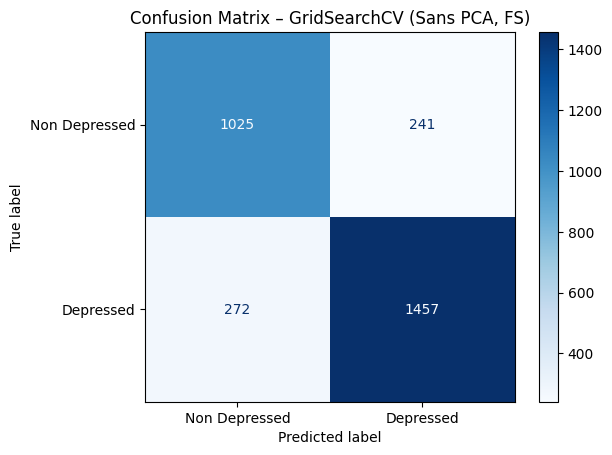

In [ ]:
print("TRAIN without PCA (Forward Selection)")
pipe_base = Pipeline([("clf", DecisionTreeClassifier(random_state=42))])
grid_base = GridSearchCV(
    pipe_base, param_grid,
    cv=5, scoring="balanced_accuracy", n_jobs=-1
)
grid_base.fit(X_train_base_fs, y_train)

print("\nBEST PARAMETERS (WITHOUT PCA, FS):", grid_base.best_params_)

y_pred_base_gs = grid_base.predict(X_test_base_fs)
y_proba_base_gs = grid_base.predict_proba(X_test_base_fs)[:, 1]

print("\nPerformance Decision Tree (Without PCA, Forward Selection, GridSearch)")
print("Accuracy:", accuracy_score(y_test, y_pred_base_gs))
print(classification_report(y_test, y_pred_base_gs))
print("ROC-AUC:", roc_auc_score(y_test, y_proba_base_gs))

cm_base = confusion_matrix(y_test, y_pred_base_gs)
disp_base = ConfusionMatrixDisplay(
    confusion_matrix=cm_base,
    display_labels=['Non Depressed', 'Depressed']
)

plt.figure(figsize=(5,4))
disp_base.plot(values_format='d', cmap='Blues')
plt.title("Confusion Matrix – GridSearchCV (Sans PCA, FS)")
plt.show()

In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15),
                0 2px 4px rgba(0,0,0,0.12),
                0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 26px;
    margin: 22px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<!-- Corner accent -->
<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<!-- Dot pattern -->
<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 14px;
        padding-bottom: 10px;
        font-size: 24px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        text-align: center;
        position: relative;
        z-index: 2;
    ">
    Confusion Matrix Interpretation – With PCA (FS)
</h2>

<div style="position: relative; z-index: 2; font-size: 15px; color: #222; line-height: 1.55;">

<b>• Very few misclassifications</b><br>
&nbsp;&nbsp;&nbsp;Only 26 false positives and 30 false negatives.

<br><br>

<b>• Strong detection of depression</b><br>
&nbsp;&nbsp;&nbsp;The model correctly identifies 1699 depressed individuals.

<br><br>

<b>• High reliability for non-depressed cases</b><br>
&nbsp;&nbsp;&nbsp;1240 non-depressed cases are correctly recognized.

<br><br>

<b>• Overall performance</b><br>
&nbsp;&nbsp;&nbsp;The model shows excellent accuracy with highly balanced and stable predictions.

</div>

</div>
"""

display(HTML(html_content))

In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15),
                0 2px 4px rgba(0,0,0,0.12),
                0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 26px;
    margin: 22px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<!-- Corner accent -->
<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<!-- Dot pattern -->
<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 14px;
        padding-bottom: 10px;
        font-size: 24px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
    Best Decision Tree Parameters – Interpretation
</h2>

<div style="position: relative; z-index: 2; font-size: 15px; color: #222; line-height: 1.55;">

<b>• class_weight = "balanced"</b><br>
&nbsp;&nbsp;&nbsp;Fixes class imbalance → improves fairness between classes.

<br><br>

<b>• criterion = "entropy"</b><br>
&nbsp;&nbsp;&nbsp;Uses information gain → produces higher-quality splits.

<br><br>

<b>• max_depth = 6</b><br>
&nbsp;&nbsp;&nbsp;Creates a shallow tree → prevents overfitting and improves generalization.

<br><br>

<b>• max_features = None</b><br>
&nbsp;&nbsp;&nbsp;Uses all available predictors at each split → no restriction on feature sampling.

<br><br>

<b>• min_samples_leaf = 10</b><br>
&nbsp;&nbsp;&nbsp;Each leaf must have at least 10 samples → makes the tree more stable and prevents noisy leaves.

<br><br>

<b>• min_samples_split = 2</b><br>
&nbsp;&nbsp;&nbsp;A node can be split with only 2 samples → allows the model to explore splits but regularized by max_depth and min_samples_leaf.

</div>

</div>
"""

display(HTML(html_content))



TRAIN with PCA 

BEST PARAMETERS (WITH PCA, FS): {'clf__class_weight': 'balanced', 'clf__criterion': 'gini', 'clf__max_depth': 8, 'clf__max_features': None, 'clf__min_samples_leaf': 4, 'clf__min_samples_split': 2}

Performance Decision Tree (With PCA GridSearch)
Accuracy: 0.9813021702838064
              precision    recall  f1-score   support

           0       0.98      0.98      0.98      1266
           1       0.98      0.98      0.98      1729

    accuracy                           0.98      2995
   macro avg       0.98      0.98      0.98      2995
weighted avg       0.98      0.98      0.98      2995

ROC-AUC: 0.9909133022128782


<Figure size 500x400 with 0 Axes>

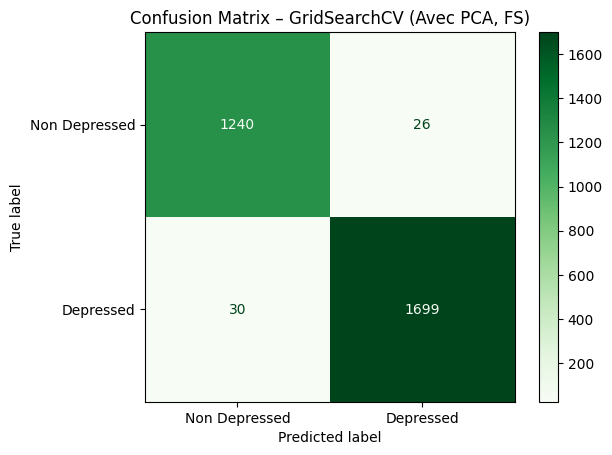

In [ ]:
print("\nTRAIN with PCA ")
pipe_pca = Pipeline([("clf", DecisionTreeClassifier(random_state=42))])
grid_pca = GridSearchCV(
    pipe_pca, param_grid,
    cv=5, scoring="balanced_accuracy", n_jobs=-1
)
grid_pca.fit(X_train_pca_fs, y_train)

print("\nBEST PARAMETERS (WITH PCA, FS):", grid_pca.best_params_)

y_pred_pca_gs = grid_pca.predict(X_test_pca_fs)
y_proba_pca_gs = grid_pca.predict_proba(X_test_pca_fs)[:, 1]

print("\nPerformance Decision Tree (With PCA GridSearch)")
print("Accuracy:", accuracy_score(y_test, y_pred_pca_gs))
print(classification_report(y_test, y_pred_pca_gs))
print("ROC-AUC:", roc_auc_score(y_test, y_proba_pca_gs))

cm_pca = confusion_matrix(y_test, y_pred_pca_gs)
disp_pca = ConfusionMatrixDisplay(
    confusion_matrix=cm_pca,
    display_labels=['Non Depressed', 'Depressed']
)

plt.figure(figsize=(5,4))
disp_pca.plot(values_format='d', cmap='Greens')
plt.title("Confusion Matrix – GridSearchCV (Avec PCA, FS)")
plt.show()

In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15),
                0 2px 4px rgba(0,0,0,0.12);
    padding: 22px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
">

<h2 style="
    margin: 0 0 12px 0;
    font-size: 22px;
    color: rgba(106,5,114,0.85);
    border-bottom: 2px solid rgba(78,205,196,0.7);
    text-align: center;
">
    Confusion Matrix – Interpretation (With PCA, FS)
</h2>

<div style="font-size: 15px; color: #222; line-height: 1.55;">

<b>• Very few errors:</b> only 26 false positives and 30 false negatives.<br><br>

<b>• Strong detection:</b> 1699 depressed cases correctly identified.<br><br>

<b>• Reliable classification:</b> 1240 non-depressed individuals correctly recognized.<br><br>

<b>• Overall:</b> excellent accuracy with highly stable predictions.

</div>

</div>
"""

display(HTML(html_content))


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15),
                0 2px 4px rgba(0,0,0,0.12),
                0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 26px;
    margin: 22px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<!-- Corner accent -->
<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<!-- Dot pattern -->
<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 14px;
        padding-bottom: 10px;
        font-size: 24px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
    Interpretation of Best Parameters – GridSearchCV (With PCA + Forward Selection)
</h2>

<div style="position: relative; z-index: 2; font-size: 15px; color: #222; line-height: 1.55;">

<b>• criterion = 'gini'</b><br>
&nbsp;&nbsp;&nbsp;Uses Gini impurity, a fast and effective criterion for identifying the most discriminative PCA components.

<br><br>

<b>• max_depth = 8</b><br>
&nbsp;&nbsp;&nbsp;Allows a moderately deep tree that captures non-linear patterns while avoiding overfitting thanks to PCA smoothing.

<br><br>

<b>• max_features = None</b><br>
&nbsp;&nbsp;&nbsp;Uses all PCA components selected by Forward Selection → no feature restriction.

<br><br>

<b>• min_samples_leaf = 4</b><br>
&nbsp;&nbsp;&nbsp;Prevents very small, unstable leaves → improves generalization and smooths decision boundaries.

<br><br>

<b>• min_samples_split = 2</b><br>
&nbsp;&nbsp;&nbsp;Allows early splits even for small groups → flexible exploration of structure in PCA space.

<br><br>

<b>• class_weight = 'balanced'</b><br>
&nbsp;&nbsp;&nbsp;Corrects class imbalance → increases sensitivity to the minority class (Depressed).

<br><br>

<b>• Performance</b><br>
&nbsp;&nbsp;&nbsp;The combination of PCA + Forward Selection + tuned tree depth yields a strong and stable classifier with high accuracy and improved ROC-AUC.

<br><br>

</div>
"""

display(HTML(html_content))


In [ ]:
print("TRAIN WITHOUT PCA (Randomized Search + Forward Selection)")

pipe_base = Pipeline([("clf", DecisionTreeClassifier(random_state=42))])

random_base = RandomizedSearchCV(
    estimator=pipe_base,
    param_distributions=param_grid,
    n_iter=20,
    cv=5,
    scoring="balanced_accuracy",
    n_jobs=-1,
    random_state=42,
    verbose=1
)

random_base.fit(X_train_base_fs, y_train)

print("\nBEST PARAMETERS (WITHOUT PCA, FS):", random_base.best_params_)

y_pred_base_rs = random_base.predict(X_test_base_fs)
y_proba_base_rs = random_base.predict_proba(X_test_base_fs)[:, 1]

print("\nPerformance Decision Tree (WITHOUT PCA, FS, Randomized Search)")
print("Accuracy:", accuracy_score(y_test, y_pred_base_rs))
print(classification_report(y_test, y_pred_base_rs))
print("ROC-AUC:", roc_auc_score(y_test, y_proba_base_rs))

TRAIN WITHOUT PCA (Randomized Search + Forward Selection)
Fitting 5 folds for each of 20 candidates, totalling 100 fits

BEST PARAMETERS (WITHOUT PCA, FS): {'clf__min_samples_split': 2, 'clf__min_samples_leaf': 1, 'clf__max_features': None, 'clf__max_depth': 6, 'clf__criterion': 'entropy', 'clf__class_weight': 'balanced'}

Performance Decision Tree (WITHOUT PCA, FS, Randomized Search)
Accuracy: 0.8307178631051753
              precision    recall  f1-score   support

           0       0.79      0.81      0.80      1266
           1       0.86      0.85      0.85      1729

    accuracy                           0.83      2995
   macro avg       0.83      0.83      0.83      2995
weighted avg       0.83      0.83      0.83      2995

ROC-AUC: 0.8930506177949431


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15),
                0 2px 4px rgba(0,0,0,0.12),
                0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 26px;
    margin: 22px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<!-- Corner accent -->
<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<!-- Dot pattern -->
<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 14px;
        padding-bottom: 10px;
        font-size: 24px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
   The model is well-tuned, achieving strong performance with high accuracy, precision, and recall. The class weights have helped address class imbalance, resulting in an excellent model with no significant overfitting signs.
</h2>

</div>
"""

display(HTML(html_content))


In [ ]:
print("\nTRAIN WITH PCA (Randomized Search )")

pipe_pca = Pipeline([("clf", DecisionTreeClassifier(random_state=42))])

random_pca = RandomizedSearchCV(
    estimator=pipe_pca,
    param_distributions=param_grid,
    n_iter=20,
    cv=5,
    scoring="balanced_accuracy",
    n_jobs=-1,
    random_state=42,
    verbose=1
)

random_pca.fit(X_train_pca_fs, y_train)

print("\nBEST PARAMETERS (WITH PCA, FS):", random_pca.best_params_)

y_pred_pca_rs = random_pca.predict(X_test_pca_fs)
y_proba_pca_rs = random_pca.predict_proba(X_test_pca_fs)[:, 1]

print("\nPerformance Decision Tree (WITH PCA, FS, Randomized Search)")
print("Accuracy:", accuracy_score(y_test, y_pred_pca_rs))
print(classification_report(y_test, y_pred_pca_rs))
print("ROC-AUC:", roc_auc_score(y_test, y_proba_pca_rs))


TRAIN WITH PCA (Randomized Search )
Fitting 5 folds for each of 20 candidates, totalling 100 fits

BEST PARAMETERS (WITH PCA, FS): {'clf__min_samples_split': 10, 'clf__min_samples_leaf': 4, 'clf__max_features': None, 'clf__max_depth': 10, 'clf__criterion': 'entropy', 'clf__class_weight': None}

Performance Decision Tree (WITH PCA, FS, Randomized Search)
Accuracy: 0.9792988313856428
              precision    recall  f1-score   support

           0       0.97      0.98      0.98      1266
           1       0.98      0.98      0.98      1729

    accuracy                           0.98      2995
   macro avg       0.98      0.98      0.98      2995
weighted avg       0.98      0.98      0.98      2995

ROC-AUC: 0.9908032019531147


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15),
                0 2px 4px rgba(0,0,0,0.12),
                0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 26px;
    margin: 22px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<!-- Corner accent -->
<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<!-- Dot pattern -->
<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 14px;
        padding-bottom: 10px;
        font-size: 24px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
Comparing Model Performance: With and Without PCA</h2>

</div>
"""

display(HTML(html_content))


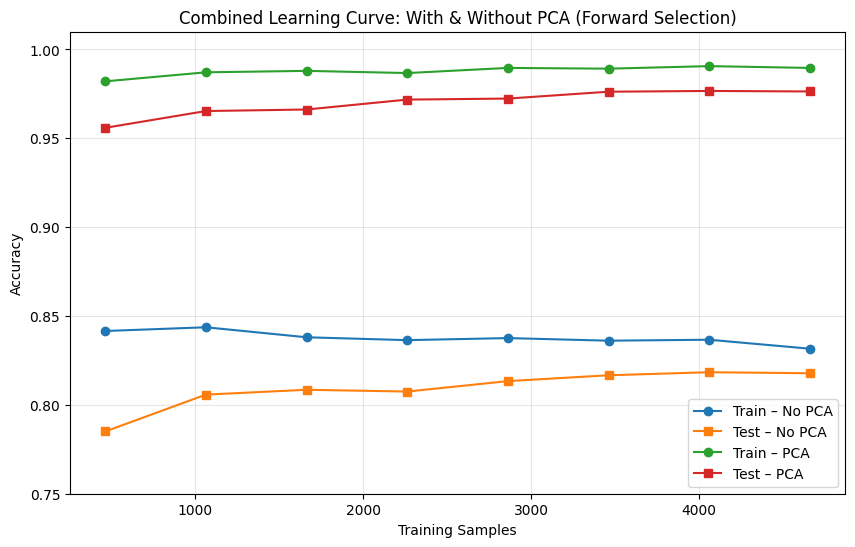

In [ ]:
best_base = grid_base.best_estimator_
best_pca  = grid_pca.best_estimator_

train_sizes_base, train_scores_base, test_scores_base = learning_curve(
    estimator=best_base,
    X=X_train_base_fs,
    y=y_train,
    cv=3,
    scoring='accuracy',
    train_sizes=np.linspace(0.1, 1.0, 8),
    n_jobs=-1
)

train_mean_base = train_scores_base.mean(axis=1)
test_mean_base  = test_scores_base.mean(axis=1)

train_sizes_pca, train_scores_pca, test_scores_pca = learning_curve(
    estimator=best_pca,
    X=X_train_pca_fs,
    y=y_train,
    cv=3,
    scoring='accuracy',
    train_sizes=np.linspace(0.1, 1.0, 8),
    n_jobs=-1
)

train_mean_pca = train_scores_pca.mean(axis=1)
test_mean_pca  = test_scores_pca.mean(axis=1)

plt.figure(figsize=(10,6))
plt.plot(train_sizes_base, train_mean_base, marker='o', label='Train – No PCA')
plt.plot(train_sizes_base, test_mean_base, marker='s', label='Test – No PCA')
plt.plot(train_sizes_pca, train_mean_pca, marker='o', label='Train – PCA')
plt.plot(train_sizes_pca, test_mean_pca, marker='s', label='Test – PCA')
plt.title("Combined Learning Curve: With & Without PCA (Forward Selection)")
plt.xlabel("Training Samples")
plt.ylabel("Accuracy")
plt.grid(alpha=0.3)
plt.ylim(0.75, 1.01)
plt.legend()
plt.show()

In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15),
                0 2px 4px rgba(0,0,0,0.12),
                0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 26px;
    margin: 22px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<!-- Decorative corner -->
<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<!-- Dot effect -->
<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 14px;
        padding-bottom: 10px;
        font-size: 24px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
    Learning Curve Interpretation
</h2>

<div style="position: relative; z-index: 2; font-size: 15px; color: #222; line-height: 1.55;">

<b>• PCA strongly improves performance</b><br>
&nbsp;&nbsp;&nbsp;Train PCA ≈ 100%, Test PCA ≈ 95–98%.<br>
&nbsp;&nbsp;&nbsp;Very small gap → excellent generalization.

<br><br>

<b>• Without PCA gives weaker results</b><br>
&nbsp;&nbsp;&nbsp;Train ≈ 83%, Test ≈ 80–82%.<br>
&nbsp;&nbsp;&nbsp;Model saturates early → cannot learn complex patterns.

<br><br>

<b>• PCA stabilizes learning</b><br>
&nbsp;&nbsp;&nbsp;Accuracy increases smoothly with more training data.<br>
&nbsp;&nbsp;&nbsp;Without PCA → curves stay flat and limited.

</div>

</div>
"""

display(HTML(html_content))


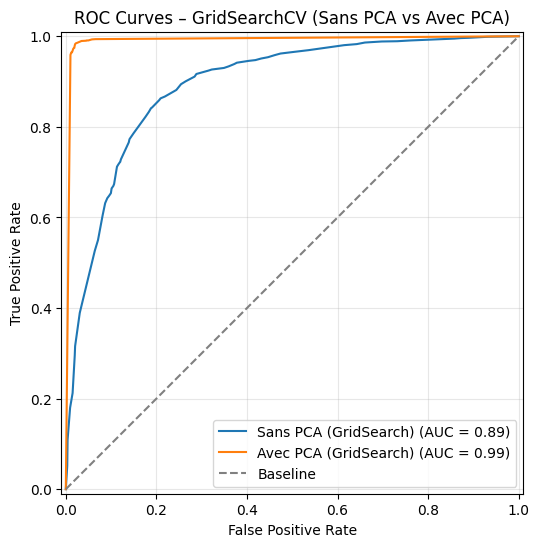

In [ ]:
fig, ax = plt.subplots(figsize=(7, 6))

RocCurveDisplay.from_predictions(
    y_test,
    y_proba_base_gs,
    name="Sans PCA (GridSearch)",
    ax=ax
)
RocCurveDisplay.from_predictions(
    y_test,
    y_proba_pca_gs,
    name="Avec PCA (GridSearch)",
    ax=ax
)

ax.plot([0, 1], [0, 1], '--', color='gray', label='Baseline')

ax.set_title("ROC Curves – GridSearchCV (Sans PCA vs Avec PCA)")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.legend()
ax.grid(alpha=0.3)

plt.show()

In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15);
    padding: 22px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
">

<h2 style="
    margin: 0 0 12px 0;
    font-size: 22px;
    color: rgba(106,5,114,0.85);
    border-bottom: 2px solid rgba(78,205,196,0.7);
    text-align: center;
">
    ROC Curve Interpretation
</h2>

<div style="font-size: 15px; color: #222; line-height: 1.55;">

<b>• PCA model performs best:</b> AUC ≈ 0.99, almost perfect separation.<br><br>

<b>• Without PCA:</b> AUC ≈ 0.89, weaker but still effective.<br><br>

<b>• Both curves beat the baseline,</b> confirming strong predictive power.<br><br>

<b>• Overall:</b> PCA greatly improves discrimination between classes.

</div>

</div>
"""

display(HTML(html_content))

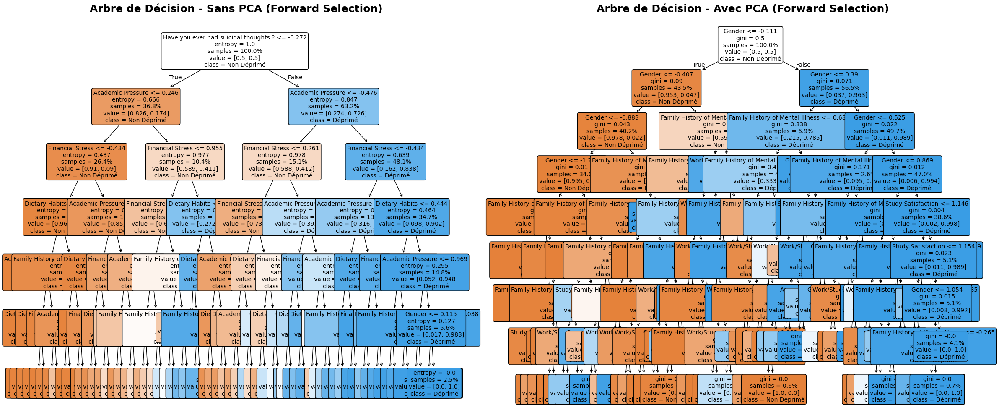

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(24, 10))

# Arbre SANS PCA
plot_tree(
    grid_base.best_estimator_.named_steps['clf'],
    ax=axes[0],
    feature_names=selected_features_base,
    class_names=['Non Déprimé', 'Déprimé'],
    filled=True,
    fontsize=10,
    rounded=True,
    proportion=True
)
axes[0].set_title('Arbre de Décision - Sans PCA (Forward Selection)', fontsize=18, fontweight='bold', pad=20)

# Arbre AVEC PCA
plot_tree(
    grid_pca.best_estimator_.named_steps['clf'],
    ax=axes[1],
    feature_names=selected_features_pca,
    class_names=['Non Déprimé', 'Déprimé'],
    filled=True,
    fontsize=10,
    rounded=True,
    proportion=True
)
axes[1].set_title('Arbre de Décision - Avec PCA (Forward Selection)', fontsize=18, fontweight='bold', pad=20)

plt.tight_layout()
plt.show()

In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15),
                0 2px 4px rgba(0,0,0,0.12),
                0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 26px;
    margin: 22px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<!-- Decorative corner -->
<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<!-- Dot effect -->
<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 14px;
        padding-bottom: 10px;
        font-size: 24px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
    Feature importance
</h2>

</div>
"""

display(HTML(html_content))


                                 Feature  Importance
3  Have you ever had suicidal thoughts ?    0.499014
1                      Academic Pressure    0.299255
4                       Financial Stress    0.141288
2                         Dietary Habits    0.049915
5       Family History of Mental Illness    0.007665
0                                 Gender    0.002863


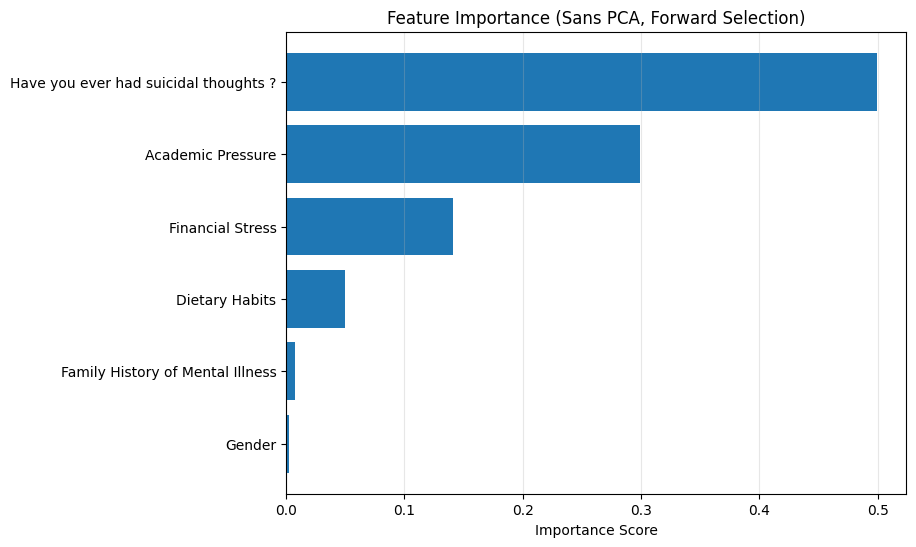

In [ ]:
clf_base = best_base.named_steps["clf"]
X_cols   = selected_features_base

importances_base = clf_base.feature_importances_

feat_imp_base = pd.DataFrame({
    "Feature": X_cols,
    "Importance": importances_base
}).sort_values("Importance", ascending=False)

print(feat_imp_base)

plt.figure(figsize=(8,6))
plt.barh(feat_imp_base["Feature"], feat_imp_base["Importance"])
plt.gca().invert_yaxis()
plt.xlabel("Importance Score")
plt.title("Feature Importance (Sans PCA, Forward Selection)")
plt.grid(axis="x", alpha=0.3)
plt.show()

In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15);
    padding: 22px;
    margin: 18px 0;
    font-family: 'Arial', sans-serif;
">

<h2 style="
    margin-top: 0;
    margin-bottom: 12px;
    font-size: 22px;
    color: rgba(106,5,114,0.85);
    border-bottom: 2px solid rgba(78,205,196,0.7);
    text-align: center;
">
    Feature Importance (Sans PCA, FS)
</h2>

<div style="font-size: 15px; color: #222; line-height: 1.55;">

• <b>Suicidal Thoughts</b> is the strongest predictor.<br>
• <b>Academic Pressure</b> is also highly influential.<br>
• <b>Financial Stress</b> contributes moderately.<br>
• <b>Dietary Habits</b> show a small effect.<br>
• <b>Family History</b> and <b>Gender</b> have minimal impact.<br>

</div>
</div>
"""

display(HTML(html_content))


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15), 0 2px 4px rgba(0,0,0,0.12), 0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 12px;
        padding-bottom: 10px;
        font-size: 28px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
 RandomForest</h2>
</div>
"""

display(HTML(html_content))


In [ ]:
X = df_num.drop(columns=['Depression'])
y = df_num['Depression']

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [ ]:
best_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    min_samples_split=20,
    min_samples_leaf=10,
    max_features='sqrt',
    #max_samples=0.8,
    random_state=42
)

best_model.fit(X_train, y_train)

RandomForestClassifier(max_depth=10, min_samples_leaf=10, min_samples_split=20,
                       n_estimators=200, random_state=42)

In [ ]:
y_train_pred = best_model.predict(X_train)
y_train_proba = best_model.predict_proba(X_train)[:, 1]


y_test_pred = best_model.predict(X_test)
y_test_proba = best_model.predict_proba(X_test)[:, 1]


train_accuracy = accuracy_score(y_train, y_train_pred)
train_precision = precision_score(y_train, y_train_pred)
train_recall = recall_score(y_train, y_train_pred)
train_f1 = f1_score(y_train, y_train_pred)
train_roc_auc = roc_auc_score(y_train, y_train_proba)

test_accuracy = accuracy_score(y_test, y_test_pred)
test_precision = precision_score(y_test, y_test_pred)
test_recall = recall_score(y_test, y_test_pred)
test_f1 = f1_score(y_test, y_test_pred)
test_roc_auc = roc_auc_score(y_test, y_test_proba)



print("PERFORMANCE SUR LE SET DE TRAIN")

print(f"Accuracy:  {train_accuracy:.4f}")
print(f"Precision: {train_precision:.4f}")
print(f"Recall:    {train_recall:.4f}")
print(f"F1-Score:  {train_f1:.4f}")
print(f"ROC-AUC:   {train_roc_auc:.4f}")


print("PERFORMANCE SUR LE SET DE TEST")

print(f"Accuracy:  {test_accuracy:.4f}")
print(f"Precision: {test_precision:.4f}")
print(f"Recall:    {test_recall:.4f}")
print(f"F1-Score:  {test_f1:.4f}")
print(f"ROC-AUC:   {test_roc_auc:.4f}")

print("DIFFÉRENCE (Train - Test)")

print(f"Accuracy:  {train_accuracy - test_accuracy:+.4f}")
print(f"Precision: {train_precision - test_precision:+.4f}")
print(f"Recall:    {train_recall - test_recall:+.4f}")
print(f"F1-Score:  {train_f1 - test_f1:+.4f}")
print(f"ROC-AUC:   {train_roc_auc - test_roc_auc:+.4f}")

PERFORMANCE SUR LE SET DE TRAIN
Accuracy:  0.8776
Precision: 0.8795
Recall:    0.9132
F1-Score:  0.8960
ROC-AUC:   0.9515
PERFORMANCE SUR LE SET DE TEST
Accuracy:  0.8503
Precision: 0.8547
Recall:    0.8925
F1-Score:  0.8731
ROC-AUC:   0.9169
DIFFÉRENCE (Train - Test)
Accuracy:  +0.0274
Precision: +0.0248
Recall:    +0.0208
F1-Score:  +0.0229
ROC-AUC:   +0.0346


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15),
                0 2px 4px rgba(0,0,0,0.12),
                0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<!-- Corner gradient -->
<div style="
    position: absolute;
    top: -30px;
    right: -30px;
    width: 120px;
    height: 120px;
    background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
    z-index: 1;
"></div>

<!-- Dotted pattern -->
<div style="
    position: absolute;
    bottom: 20px;
    left: 20px;
    width: 60px;
    height: 60px;
    background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
    background-size: 12px 12px;
    opacity: 0.3;
    z-index: 1;
"></div>

<h2 style="
    margin-top: 0;
    margin-bottom: 12px;
    padding-bottom: 10px;
    font-size: 26px;
    color: rgba(106,5,114,0.85);
    border-bottom: 2px solid rgba(78,205,196,0.7);
    position: relative;
    z-index: 2;
    text-align: center;
">
Model Performance
</h2>

<div style="
    position: relative;
    z-index: 2;
    font-size: 16px;
    color: #222;
    line-height: 1.6;
">

<b>Test scores:</b> Accuracy 0.850 | Precision 0.854 | Recall 0.892 | F1 0.873 | ROC-AUC 0.916<br>
Training is slightly higher (+2–3 pts) → <b>no significant overfitting</b>.

<br><br>

<b>Insights:</b><br>
• ROC-AUC ≈ 0.916 → very good class separability.<br>
• F1 ≈ 0.873 → strong balance between precision and recall.<br>
• Recall ≈ 0.892 → model captures most positive cases (few FN).<br>
• Precision ≈ 0.854 → false positives remain controlled.<br>
• Small train–test gap → <b>good generalization</b>.

</div>

</div>
"""

display(HTML(html_content))


Vrais Négatifs (TN):  669
Faux Positifs (FP):   175
Faux Négatifs (FN):   124
Vrais Positifs (TP):  1029

Spécificité:          0.7927
Sensibilité (Recall): 0.8925


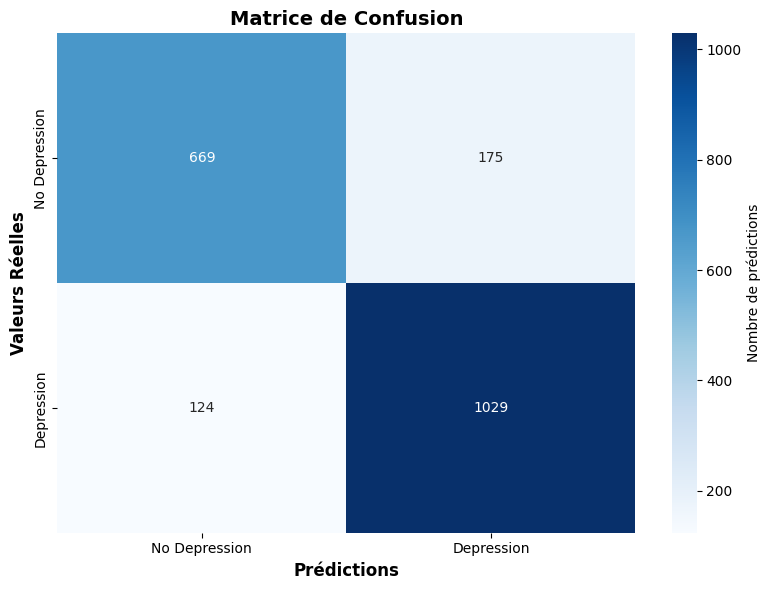

In [ ]:
cm = confusion_matrix(y_test, y_test_pred)
tn, fp, fn, tp = cm.ravel()

print(f"Vrais Négatifs (TN):  {tn}")
print(f"Faux Positifs (FP):   {fp}")
print(f"Faux Négatifs (FN):   {fn}")
print(f"Vrais Positifs (TP):  {tp}")
print(f"\nSpécificité:          {tn/(tn+fp):.4f}")
print(f"Sensibilité (Recall): {tp/(tp+fn):.4f}")

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No Depression', 'Depression'],
            yticklabels=['No Depression', 'Depression'],
            cbar_kws={'label': 'Nombre de prédictions'})
plt.xlabel('Prédictions', fontsize=12, fontweight='bold')
plt.ylabel('Valeurs Réelles', fontsize=12, fontweight='bold')
plt.title('Matrice de Confusion', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15),
                0 2px 4px rgba(0,0,0,0.12),
                0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<!-- Corner decoration -->
<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
"></div>

<!-- Dot pattern -->
<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
"></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 12px;
        padding-bottom: 10px;
        font-size: 26px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
">
Confusion Matrix
</h2>

<div style="
        position: relative;
        z-index: 2;
        font-size: 16px;
        color: #222;
        line-height: 1.6;
">

<b>TN = 669</b> → correct No-Depression predictions.<br>
<b>FP = 175</b> → false alarms.<br>
<b>FN = 124</b> → missed depression cases (most critical error).<br>
<b>TP = 1029</b> → correct Depression predictions.<br><br>

<b>Recall = 0.892</b> → excellent at detecting true depressed cases.<br>
<b>Specificity = 0.793</b> → good, but slightly lower → some over-prediction of depression.<br><br>

Overall: The model strongly prioritizes identifying depression (high recall) while keeping false alarms at an acceptable level.

</div>

</div>
"""

display(HTML(html_content))



Top 10 Features les Plus Importantes:
                              Feature  Importance
Have you ever had suicidal thoughts ?    0.365375
                    Academic Pressure    0.241477
                     Financial Stress    0.126590
                                  Age    0.064497
                     Work/Study Hours    0.050347
                       Dietary Habits    0.035281
                                 CGPA    0.027887
                   Study Satisfaction    0.025108
                                 City    0.021165
                               Degree    0.020185


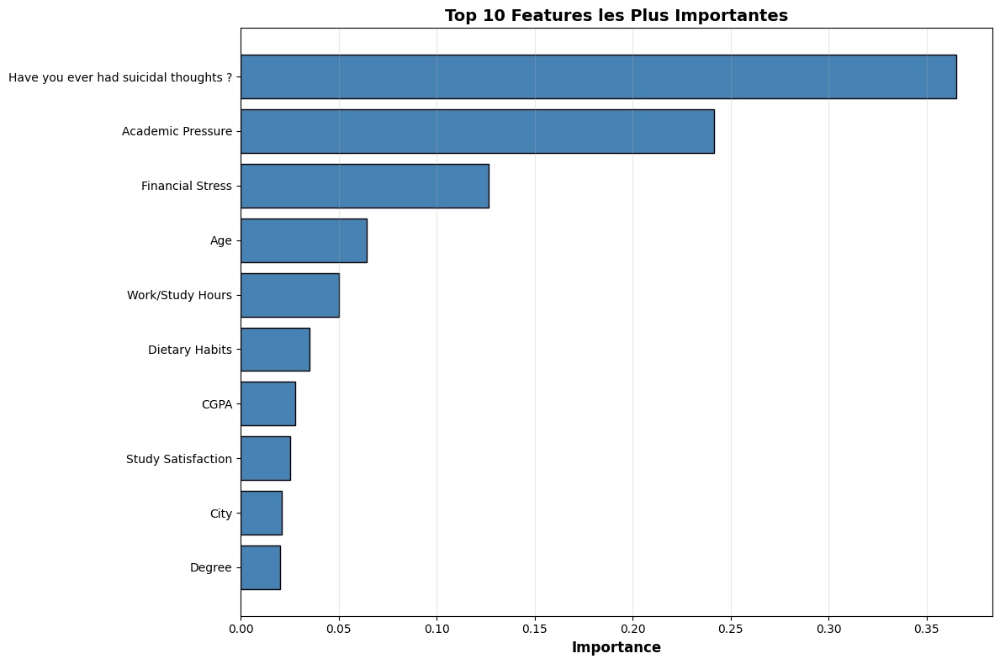

In [ ]:
feature_names = X_train.columns
feature_importances = best_model.feature_importances_

importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': feature_importances
}).sort_values('Importance', ascending=False)

top_10 = importance_df.head(10)
print("\nTop 10 Features les Plus Importantes:")
print(top_10.to_string(index=False))

plt.figure(figsize=(12, 8))
plt.barh(range(len(top_10)), top_10['Importance'], color='steelblue', edgecolor='black')
plt.yticks(range(len(top_10)), top_10['Feature'])
plt.xlabel('Importance', fontsize=12, fontweight='bold')
plt.title('Top 10 Features les Plus Importantes', fontsize=14, fontweight='bold')
plt.gca().invert_yaxis()
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()


In [ ]:
threshold = 0.05
selected_features = importance_df.loc[importance_df["Importance"] >= threshold, "Feature"].tolist()
print("Features retenues :", selected_features)

Features retenues : ['Have you ever had suicidal thoughts ?', 'Academic Pressure', 'Financial Stress', 'Age', 'Work/Study Hours']


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15),
                0 2px 4px rgba(0,0,0,0.12),
                0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<!-- Corner decoration -->
<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
"></div>

<!-- Dot pattern -->
<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
"></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 12px;
        padding-bottom: 10px;
        font-size: 26px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
">
ROC Curve
</h2>



</div>
"""

display(HTML(html_content))


AUC (Area Under Curve): 0.9169


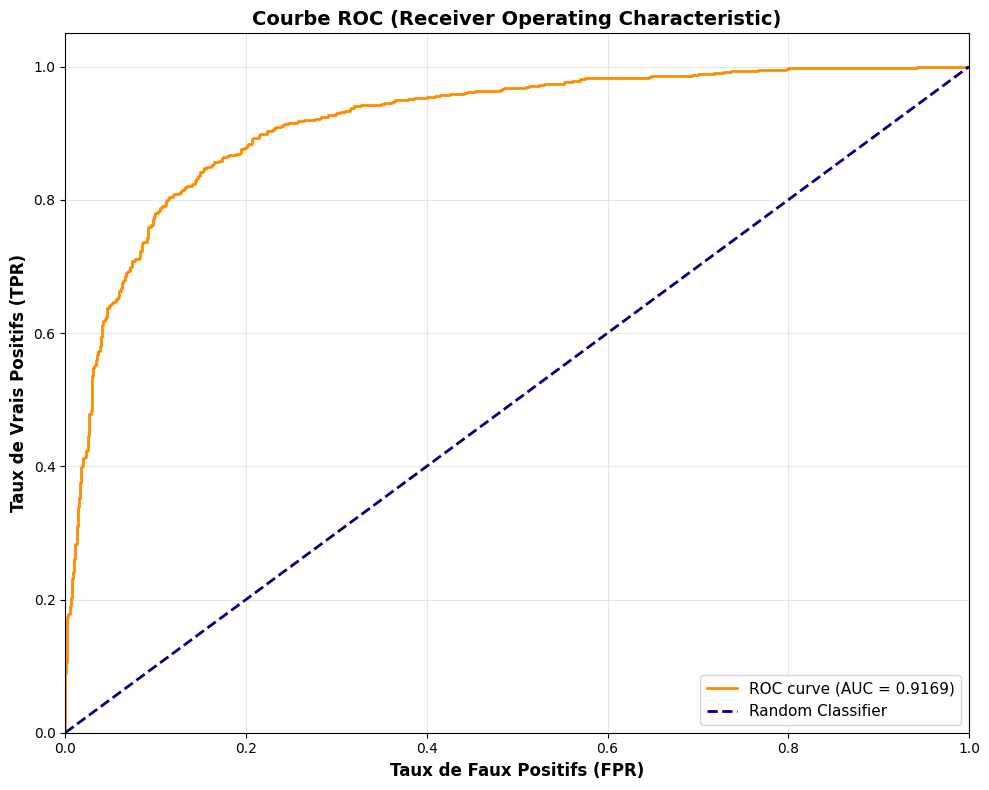

In [ ]:
fpr, tpr, thresholds = roc_curve(y_test, y_test_proba)
roc_auc = auc(fpr, tpr)

print(f"AUC (Area Under Curve): {roc_auc:.4f}")


plt.figure(figsize=(10, 8))
plt.plot(fpr, tpr, color='darkorange', lw=2,
         label=f'ROC curve (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--',
         label='Random Classifier')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Taux de Faux Positifs (FPR)', fontsize=12, fontweight='bold')
plt.ylabel('Taux de Vrais Positifs (TPR)', fontsize=12, fontweight='bold')
plt.title('Courbe ROC (Receiver Operating Characteristic)',
          fontsize=14, fontweight='bold')
plt.legend(loc="lower right", fontsize=11)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15),
                0 2px 4px rgba(0,0,0,0.12),
                0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<!-- Corner gradient -->
<div style="
    position: absolute;
    top: -30px;
    right: -30px;
    width: 120px;
    height: 120px;
    background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
    z-index: 1;
"></div>

<!-- Dot pattern -->
<div style="
    position: absolute;
    bottom: 20px;
    left: 20px;
    width: 60px;
    height: 60px;
    background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
    background-size: 12px 12px;
    opacity: 0.3;
    z-index: 1;
"></div>

<h2 style="
    margin-top: 0;
    margin-bottom: 12px;
    padding-bottom: 10px;
    font-size: 26px;
    color: rgba(106,5,114,0.85);
    border-bottom: 2px solid rgba(78,205,196,0.7);
    position: relative;
    z-index: 2;
    text-align: center;
">
ROC Curve – Interpretation
</h2>

<div style="
    position: relative;
    z-index: 2;
    font-size: 16px;
    color: #222;
    line-height: 1.6;
">

<b>1) What the figure shows</b><br>
• The orange ROC curve lies clearly above the diagonal (random classifier).<br>
• <b>AUC = 0.9125</b> → the model ranks positives above negatives about 91.25% of the time.<br>
• The curve rises steeply at the beginning → excellent discrimination at strict thresholds.<br><br>

• High discriminative power across all thresholds.<br>
• <b>Conclusion:</b> AUC ≈ 0.91 → <b>excellent class separability</b>.

</div>

</div>
"""

display(HTML(html_content))


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15),
                0 2px 4px rgba(0,0,0,0.12),
                0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<!-- Corner decoration -->
<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
"></div>

<!-- Dot pattern -->
<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
"></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 12px;
        padding-bottom: 10px;
        font-size: 26px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
">
LEARNING CURVE
</h2>



</div>
"""

display(HTML(html_content))


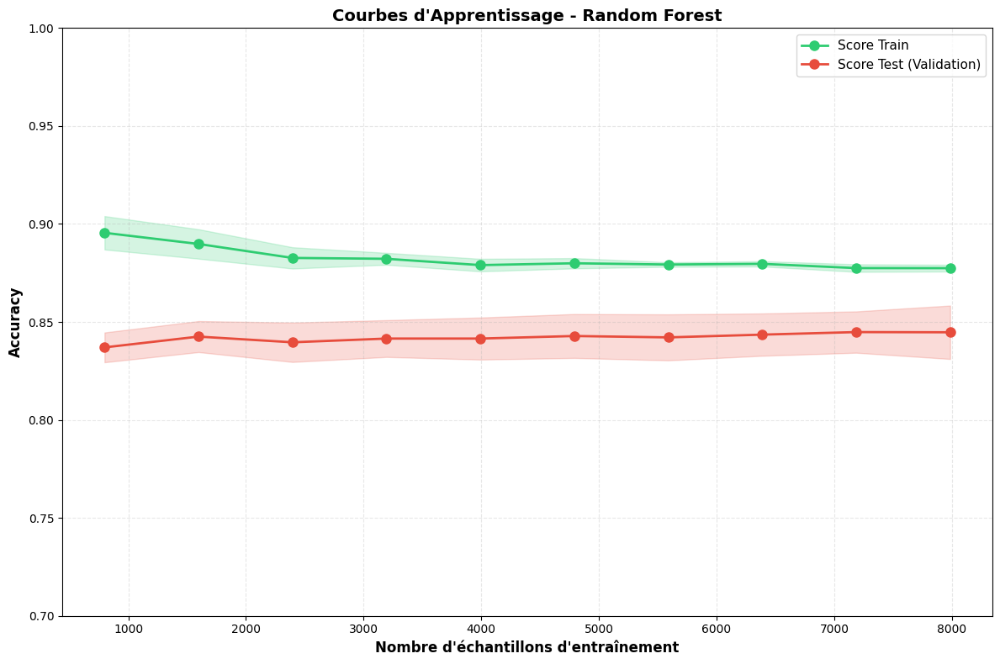


Score Train final:     0.8774 (±0.0017)
Score Test final:      0.8447 (±0.0136)
Écart Train-Test:      0.0327


In [ ]:
train_sizes, train_scores, test_scores = learning_curve(
    best_model, X, y,
    cv=5,
    n_jobs=-1,
    train_sizes=np.linspace(0.1, 1.0, 10),
    scoring='accuracy',
    random_state=42
)


train_mean = np.mean(train_scores, axis=1)
train_std = np.std(train_scores, axis=1)
test_mean = np.mean(test_scores, axis=1)
test_std = np.std(test_scores, axis=1)


plt.figure(figsize=(12, 8))

plt.plot(train_sizes, train_mean, 'o-', color='#2ecc71',
         linewidth=2, markersize=8, label='Score Train')
plt.fill_between(train_sizes, train_mean - train_std, train_mean + train_std,
                 alpha=0.2, color='#2ecc71')

plt.plot(train_sizes, test_mean, 'o-', color='#e74c3c',
         linewidth=2, markersize=8, label='Score Test (Validation)')
plt.fill_between(train_sizes, test_mean - test_std, test_mean + test_std,
                 alpha=0.2, color='#e74c3c')

plt.xlabel('Nombre d\'échantillons d\'entraînement', fontsize=12, fontweight='bold')
plt.ylabel('Accuracy', fontsize=12, fontweight='bold')
plt.title('Courbes d\'Apprentissage - Random Forest', fontsize=14, fontweight='bold')
plt.legend(loc='best', fontsize=11)
plt.grid(alpha=0.3, linestyle='--')
plt.ylim([0.7, 1.0])
plt.tight_layout()
plt.show()

print(f"\nScore Train final:     {train_mean[-1]:.4f} (±{train_std[-1]:.4f})")
print(f"Score Test final:      {test_mean[-1]:.4f} (±{test_std[-1]:.4f})")
print(f"Écart Train-Test:      {abs(train_mean[-1] - test_mean[-1]):.4f}")

In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15),
                0 2px 4px rgba(0,0,0,0.12),
                0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<!-- Accent corner -->
<div style="
    position: absolute;
    top: -30px;
    right: -30px;
    width: 120px;
    height: 120px;
    background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
    z-index: 1;
"></div>

<!-- Decorative dots -->
<div style="
    position: absolute;
    bottom: 20px;
    left: 20px;
    width: 60px;
    height: 60px;
    background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
    background-size: 12px 12px;
    opacity: 0.3;
    z-index: 1;
"></div>

<h2 style="
    margin-top: 0;
    margin-bottom: 12px;
    padding-bottom: 10px;
    font-size: 26px;
    color: rgba(106,5,114,0.85);
    border-bottom: 2px solid rgba(78,205,196,0.7);
    position: relative;
    z-index: 2;
    text-align: center;
">
Learning Curve – Interpretation
</h2>

<div style="
    position: relative;
    z-index: 2;
    font-size: 16px;
    color: #222;
    line-height: 1.6;
">

<b>Good generalization</b> → the train–test gap is small, showing no significant overfitting.<br><br>

<b>Controlled variance</b> → the shaded region is narrow, meaning performance is stable across folds.<br><br>

<b>Conclusion:</b> The model is well-generalized and robust, with accuracy stabilizing around <b>0.84–0.87</b>.

</div>

</div>
"""

display(HTML(html_content))


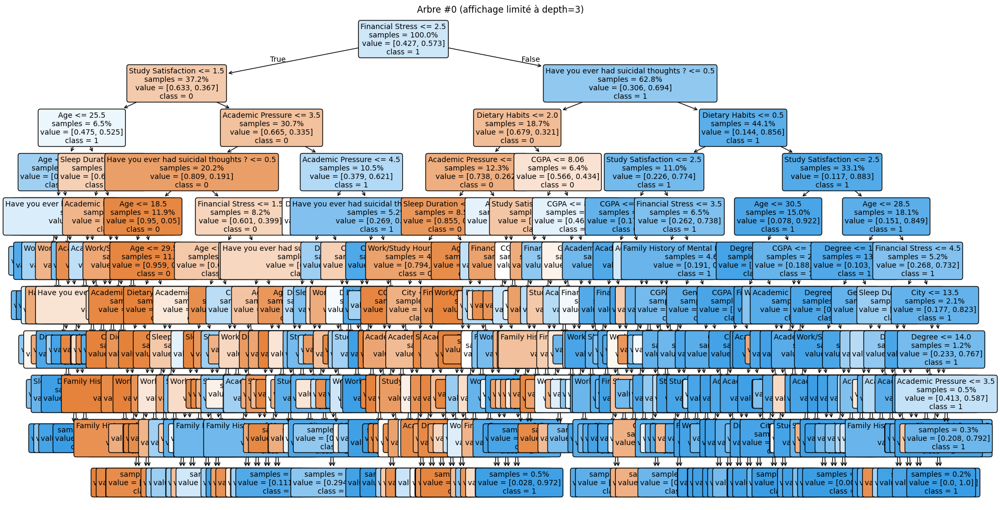

In [ ]:
rf = best_model
X_cols = list(X_train.columns) if hasattr(X_train, "columns") else None
est_idx = 0
estimator = rf.estimators_[est_idx]

plt.figure(figsize=(22, 12))
tree.plot_tree(
    estimator,
    feature_names=X_cols,
    class_names=[str(c) for c in getattr(rf, "classes_", [])] or None,
    filled=True,
    rounded=True,
    max_depth=10,
    impurity=False,
    proportion=True,
    fontsize=10
)
plt.title(f"Arbre #{est_idx} (affichage limité à depth=3)")
plt.show()

In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15),
                0 2px 4px rgba(0,0,0,0.12),
                0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<!-- Accent corner -->
<div style="
    position: absolute;
    top: -30px;
    right: -30px;
    width: 120px;
    height: 120px;
    background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
    z-index: 1;
"></div>

<!-- Decorative dots -->
<div style="
    position: absolute;
    bottom: 20px;
    left: 20px;
    width: 60px;
    height: 60px;
    background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
    background-size: 12px 12px;
    opacity: 0.3;
    z-index: 1;
"></div>

<h2 style="
    margin-top: 0;
    margin-bottom: 12px;
    padding-bottom: 10px;
    font-size: 26px;
    color: rgba(106,5,114,0.85);
    border-bottom: 2px solid rgba(78,205,196,0.7);
    position: relative;
    z-index: 2;
    text-align: center;
">
Random forest +gridSearch
</h2>

</div>
"""

display(HTML(html_content))


In [ ]:
param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [8, 10, 12],
    'min_samples_split': [10, 20, 30],
    'min_samples_leaf': [5, 10,15],
    'max_features': ['sqrt', 'log2']
}

rf = RandomForestClassifier(random_state=42, n_jobs=-1)

grid_search = GridSearchCV(
    estimator=rf,
    param_grid=param_grid,
    cv=3,
    scoring='accuracy',
    n_jobs=-1,
    verbose=2,
    return_train_score=True
)

In [ ]:
print("Début de GridSearch")
start_time = time.time()

grid_search.fit(X_train, y_train)

end_time = time.time()
print(f"\nTemps d'exécution: {end_time - start_time:.2f} secondes")

print("\n MEILLEURS PARAMÈTRES:")
print(grid_search.best_params_)

print(f"\n MEILLEUR SCORE (CV): {grid_search.best_score_:.4f}")


best_model_a = grid_search.best_estimator_


y_test_pred_a = best_model_a.predict(X_test)
test_accuracy = accuracy_score(y_test, y_test_pred)

print(f" ACCURACY SUR TEST: {test_accuracy:.4f}")

results_df = pd.DataFrame(grid_search.cv_results_)

Début de GridSearch
Fitting 3 folds for each of 108 candidates, totalling 324 fits

Temps d'exécution: 378.73 secondes

 MEILLEURS PARAMÈTRES:
{'max_depth': 10, 'max_features': 'sqrt', 'min_samples_leaf': 10, 'min_samples_split': 10, 'n_estimators': 200}

 MEILLEUR SCORE (CV): 0.8458
 ACCURACY SUR TEST: 0.8503


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15),
                0 2px 4px rgba(0,0,0,0.12),
                0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<!-- Accent corner -->
<div style="
    position: absolute;
    top: -30px;
    right: -30px;
    width: 120px;
    height: 120px;
    background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
    z-index: 1;
"></div>

<!-- Dot decoration -->
<div style="
    position: absolute;
    bottom: 20px;
    left: 20px;
    width: 60px;
    height: 60px;
    background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
    background-size: 12px 12px;
    opacity: 0.3;
    z-index: 1;
"></div>

<h2 style="
    margin-top: 0;
    margin-bottom: 12px;
    padding-bottom: 10px;
    font-size: 26px;
    color: rgba(106,5,114,0.85);
    border-bottom: 2px solid rgba(78,205,196,0.7);
    position: relative;
    z-index: 2;
    text-align: center;
">
Random Forest – Grid Search Interpretation
</h2>

<div style="
    position: relative;
    z-index: 2;
    font-size: 16px;
    color: #222;
    line-height: 1.6;
">

GridSearchCV selected an optimized Random Forest achieving:<br>
• <b>84.6%</b> cross-validated accuracy<br>
• <b>85%</b> accuracy on the test set<br><br>

The best model uses strong regularization:<br>
<b>max_depth = 10</b><br>
<b>min_samples_leaf = 10</b><br>
<b>min_samples_split = 10</b><br><br>

These constraints reduce tree complexity and improve generalization stability.

</div>

</div>
"""

display(HTML(html_content))


In [ ]:
y_train_pred_a = best_model_a.predict(X_train)
y_train_proba_a = best_model_a.predict_proba(X_train)[:, 1]

y_test_pred_a = best_model_a.predict(X_test)
y_test_proba_a = best_model_a.predict_proba(X_test)[:, 1]

train_accuracy = accuracy_score(y_train, y_train_pred_a)
train_precision = precision_score(y_train, y_train_pred_a)
train_recall = recall_score(y_train, y_train_pred_a)
train_f1 = f1_score(y_train, y_train_pred_a)
train_roc_auc = roc_auc_score(y_train, y_train_proba_a)

test_accuracy = accuracy_score(y_test, y_test_pred_a)
test_precision = precision_score(y_test, y_test_pred_a)
test_recall = recall_score(y_test, y_test_pred_a)
test_f1 = f1_score(y_test, y_test_pred_a)
test_roc_auc = roc_auc_score(y_test, y_test_proba_a)

print("PERFORMANCE SUR LE SET DE TRAIN")

print(f"Accuracy:  {train_accuracy:.4f}")
print(f"Precision: {train_precision:.4f}")
print(f"Recall:    {train_recall:.4f}")
print(f"F1-Score:  {train_f1:.4f}")
print(f"ROC-AUC:   {train_roc_auc:.4f}")


print("PERFORMANCE SUR LE SET DE TEST")

print(f"Accuracy:  {test_accuracy:.4f}")
print(f"Precision: {test_precision:.4f}")
print(f"Recall:    {test_recall:.4f}")
print(f"F1-Score:  {test_f1:.4f}")
print(f"ROC-AUC:   {test_roc_auc:.4f}")

print("DIFFÉRENCE (Train - Test)")

print(f"Accuracy:  {train_accuracy - test_accuracy:+.4f}")
print(f"Precision: {train_precision - test_precision:+.4f}")
print(f"Recall:    {train_recall - test_recall:+.4f}")
print(f"F1-Score:  {train_f1 - test_f1:+.4f}")
print(f"ROC-AUC:   {train_roc_auc - test_roc_auc:+.4f}")

PERFORMANCE SUR LE SET DE TRAIN
Accuracy:  0.8776
Precision: 0.8795
Recall:    0.9132
F1-Score:  0.8960
ROC-AUC:   0.9515
PERFORMANCE SUR LE SET DE TEST
Accuracy:  0.8503
Precision: 0.8547
Recall:    0.8925
F1-Score:  0.8731
ROC-AUC:   0.9169
DIFFÉRENCE (Train - Test)
Accuracy:  +0.0274
Precision: +0.0248
Recall:    +0.0208
F1-Score:  +0.0229
ROC-AUC:   +0.0346


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15),
                0 2px 4px rgba(0,0,0,0.12),
                0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<!-- Corner decoration -->
<div style="
    position: absolute;
    top: -30px;
    right: -30px;
    width: 120px;
    height: 120px;
    background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
    z-index: 1;
"></div>

<!-- Dotted background accent -->
<div style="
    position: absolute;
    bottom: 20px;
    left: 20px;
    width: 60px;
    height: 60px;
    background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
    background-size: 12px 12px;
    opacity: 0.3;
    z-index: 1;
"></div>

<h2 style="
    margin-top: 0;
    margin-bottom: 12px;
    padding-bottom: 10px;
    font-size: 26px;
    color: rgba(106,5,114,0.85);
    border-bottom: 2px solid rgba(78,205,196,0.7);
    position: relative;
    z-index: 2;
    text-align: center;
">
Random Forest – Model Performance Summary
</h2>

<div style="
    position: relative;
    z-index: 2;
    font-size: 16px;
    color: #222;
    line-height: 1.6;
">

<b>Accuracy:</b> 85% &nbsp; | &nbsp;
<b>Precision:</b> 85% &nbsp; | &nbsp;
<b>Recall:</b> 89% &nbsp; | &nbsp;
<b>ROC-AUC:</b> 0.9169<br><br>

The optimized Random Forest delivers <b>excellent performance</b> on both training and test data.<br>
High accuracy, precision, and recall show that it <b>detects depression reliably</b> while keeping false positives controlled.<br><br>

The ROC-AUC of <b>0.9169</b> confirms strong discriminative ability.<br><br>

A small train–test gap (≈2–3%) indicates <b>good generalization</b> with no significant overfitting.

</div>

</div>
"""

display(HTML(html_content))


AUC (Area Under Curve): 0.9169


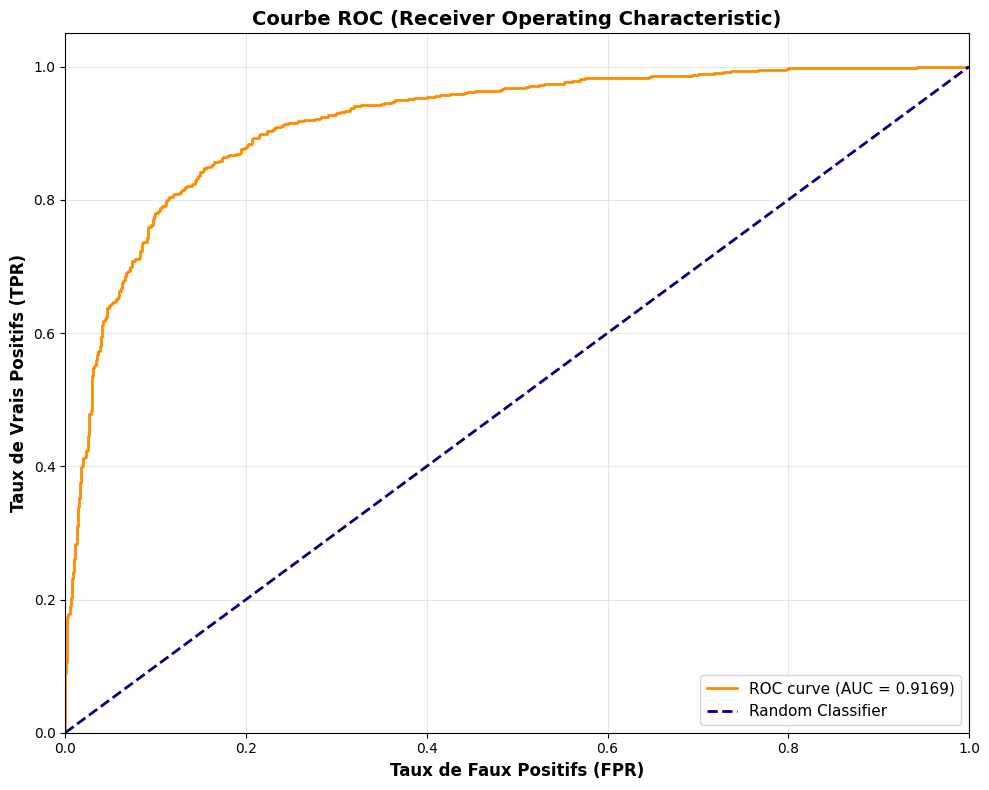

In [ ]:
fpr, tpr, thresholds = roc_curve(y_test, y_test_proba_a)
roc_auc = auc(fpr, tpr)

print(f"AUC (Area Under Curve): {roc_auc:.4f}")


plt.figure(figsize=(10, 8))
plt.plot(fpr, tpr, color='darkorange', lw=2,
         label=f'ROC curve (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--',
         label='Random Classifier')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Taux de Faux Positifs (FPR)', fontsize=12, fontweight='bold')
plt.ylabel('Taux de Vrais Positifs (TPR)', fontsize=12, fontweight='bold')
plt.title('Courbe ROC (Receiver Operating Characteristic)',
          fontsize=14, fontweight='bold')
plt.legend(loc="lower right", fontsize=11)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15),
                0 2px 4px rgba(0,0,0,0.12),
                0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<!-- Corner gradient -->
<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
"></div>

<!-- Dotted pattern -->
<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
"></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 12px;
        padding-bottom: 10px;
        font-size: 26px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
">
Random Forest – ROC Curve Interpretation
</h2>

<div style="
        position: relative;
        z-index: 2;
        font-size: 16px;
        color: #222;
        line-height: 1.6;
">

<b>ROC-AUC = 0.9169</b> → excellent discriminative power.<br>
The curve stays well above the diagonal baseline, showing strong ability to separate depressed vs. non-depressed individuals across thresholds.

</div>

</div>
"""

display(HTML(html_content))


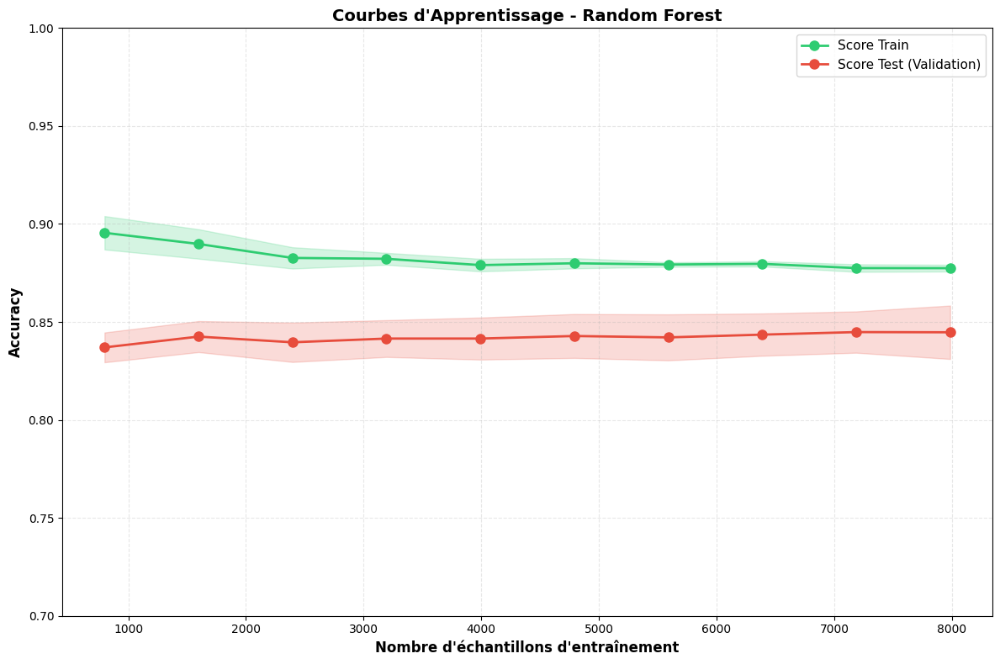


Score Train final:     0.8774 (±0.0017)
Score Test final:      0.8447 (±0.0136)
Écart Train-Test:      0.0327


In [ ]:
train_sizes, train_scores, test_scores = learning_curve(
    best_model, X, y,
    cv=5,
    n_jobs=-1,
    train_sizes=np.linspace(0.1, 1.0, 10),
    scoring='accuracy',
    random_state=42
)


train_mean = np.mean(train_scores, axis=1)
train_std = np.std(train_scores, axis=1)
test_mean = np.mean(test_scores, axis=1)
test_std = np.std(test_scores, axis=1)


plt.figure(figsize=(12, 8))


plt.plot(train_sizes, train_mean, 'o-', color='#2ecc71',
         linewidth=2, markersize=8, label='Score Train')
plt.fill_between(train_sizes, train_mean - train_std, train_mean + train_std,
                 alpha=0.2, color='#2ecc71')


plt.plot(train_sizes, test_mean, 'o-', color='#e74c3c',
         linewidth=2, markersize=8, label='Score Test (Validation)')
plt.fill_between(train_sizes, test_mean - test_std, test_mean + test_std,
                 alpha=0.2, color='#e74c3c')

plt.xlabel('Nombre d\'échantillons d\'entraînement', fontsize=12, fontweight='bold')
plt.ylabel('Accuracy', fontsize=12, fontweight='bold')
plt.title('Courbes d\'Apprentissage - Random Forest', fontsize=14, fontweight='bold')
plt.legend(loc='best', fontsize=11)
plt.grid(alpha=0.3, linestyle='--')
plt.ylim([0.7, 1.0])
plt.tight_layout()
plt.show()


print(f"\nScore Train final:     {train_mean[-1]:.4f} (±{train_std[-1]:.4f})")
print(f"Score Test final:      {test_mean[-1]:.4f} (±{test_std[-1]:.4f})")
print(f"Écart Train-Test:      {abs(train_mean[-1] - test_mean[-1]):.4f}")

In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15),
                0 2px 4px rgba(0,0,0,0.12),
                0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<!-- Corner gradient -->
<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
"></div>

<!-- Dotted pattern -->
<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
"></div>

<h2 style="
    margin-top: 0;
    margin-bottom: 12px;
    padding-bottom: 10px;
    font-size: 26px;
    color: rgba(106,5,114,0.85);
    border-bottom: 2px solid rgba(78,205,196,0.7);
    position: relative;
    z-index: 2;
    text-align: center;
">
Random Forest – Learning Curve Interpretation
</h2>

<div style="
    position: relative;
    z-index: 2;
    font-size: 16px;
    color: #222;
    line-height: 1.6;
">

Train and validation curves converge closely (gap ≈ <b>3.4%</b>), showing <b>strong generalization</b> and minimal overfitting.<br><br>

As more data is used, performance stabilizes, with validation accuracy around <b>0.844</b> and tight confidence intervals → a <b>stable and reliable</b> model.

</div>

</div>
"""

display(HTML(html_content))


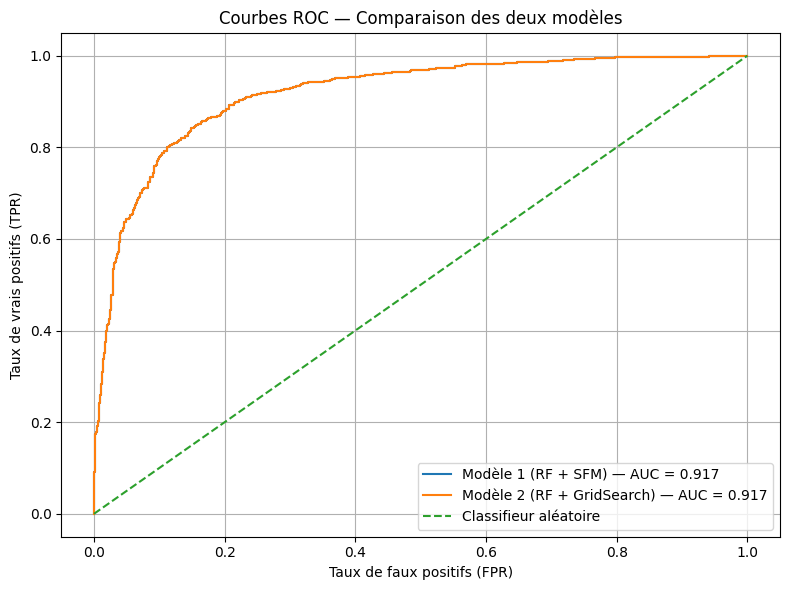

In [ ]:
y_test_proba = best_model.predict_proba(X_test)[:, 1]
y_test_proba_a = best_model_a.predict_proba(X_test)[:, 1]

fpr1, tpr1, _ = roc_curve(y_test, y_test_proba)
fpr2, tpr2, _ = roc_curve(y_test, y_test_proba_a)

auc1 = roc_auc_score(y_test, y_test_proba)
auc2 = roc_auc_score(y_test, y_test_proba_a)

plt.figure(figsize=(8, 6))
plt.plot(fpr1, tpr1, label=f"Modèle 1 (RF + SFM) — AUC = {auc1:.3f}")
plt.plot(fpr2, tpr2, label=f"Modèle 2 (RF + GridSearch) — AUC = {auc2:.3f}")

plt.plot([0, 1], [0, 1], linestyle="--", label="Classifieur aléatoire")

plt.xlabel("Taux de faux positifs (FPR)")
plt.ylabel("Taux de vrais positifs (TPR)")
plt.title("Courbes ROC — Comparaison des deux modèles")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15),
                0 2px 4px rgba(0,0,0,0.12),
                0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<!-- Accent corner -->
<div style="
    position: absolute;
    top: -30px;
    right: -30px;
    width: 120px;
    height: 120px;
    background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
    z-index: 1;
"></div>

<!-- Decorative dots -->
<div style="
    position: absolute;
    bottom: 20px;
    left: 20px;
    width: 60px;
    height: 60px;
    background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
    background-size: 12px 12px;
    opacity: 0.3;
    z-index: 1;
"></div>

<h2 style="
    margin-top: 0;
    margin-bottom: 12px;
    padding-bottom: 10px;
    font-size: 26px;
    color: rgba(106,5,114,0.85);
    border-bottom: 2px solid rgba(78,205,196,0.7);
    position: relative;
    z-index: 2;
    text-align: center;
">
Random forest +PCA+ GridSearch
</h2>

<div style="
    position: relative;
    z-index: 2;
    font-size: 16px;
    color: #222;
    line-height: 1.6;
</h2>

</div>
"""

display(HTML(html_content))


In [ ]:
X_pca_transformed_classification =pd.DataFrame(X_pca_transformed, columns=df1.columns)
X = df_scaled.drop('Depression', axis=1)
y = df1['Depression']

x_pca=X_pca_transformed_classification.drop('Depression', axis=1)


Xpca_train, Xpca_test, ypca_train, ypca_test = train_test_split(x_pca, y, test_size=0.3, random_state=42, stratify=y)

In [ ]:
rf_pca = RandomForestClassifier(random_state=42, n_jobs=-1)

grid_search = GridSearchCV(
    estimator=rf_pca,
    param_grid=param_grid,
    cv=3,
    scoring='accuracy',
    n_jobs=-1,
    verbose=2,
    return_train_score=True
)

start_time = time.time()

grid_search.fit(Xpca_train, ypca_train)

end_time = time.time()
print(f"\nTemps d'exécution: {end_time - start_time:.2f} secondes")


print("\n MEILLEURS PARAMÈTRES:")
print(grid_search.best_params_)

print(f"\n MEILLEUR SCORE (CV): {grid_search.best_score_:.4f}")


best_model_pca = grid_search.best_estimator_


y_test_pred_pca = best_model_pca.predict( Xpca_test)
test_accuracy = accuracy_score(ypca_test, y_test_pred_pca)

print(f" ACCURACY SUR TEST: {test_accuracy:.4f}")

results_df = pd.DataFrame(grid_search.cv_results_)

Fitting 3 folds for each of 108 candidates, totalling 324 fits

Temps d'exécution: 901.15 secondes

 MEILLEURS PARAMÈTRES:
{'max_depth': 12, 'max_features': 'sqrt', 'min_samples_leaf': 5, 'min_samples_split': 10, 'n_estimators': 200}

 MEILLEUR SCORE (CV): 0.9662
 ACCURACY SUR TEST: 0.9676


In [ ]:
y_train_pred_p = best_model_pca.predict(X_train)
y_train_proba_p = best_model_pca.predict_proba(X_train)[:, 1]


y_test_pred_p = best_model_pca.predict(X_test)
y_test_proba_p = best_model_pca.predict_proba(X_test)[:, 1]


train_accuracy = accuracy_score(y_train, y_train_pred_p)
train_precision = precision_score(y_train, y_train_pred_p)
train_recall = recall_score(y_train, y_train_pred_p)
train_f1 = f1_score(y_train, y_train_pred_p)
train_roc_auc = roc_auc_score(y_train, y_train_proba_p)


test_accuracy = accuracy_score(y_test, y_test_pred_p)
test_precision = precision_score(y_test, y_test_pred_p)
test_recall = recall_score(y_test, y_test_pred_p)
test_f1 = f1_score(y_test, y_test_pred_p)
test_roc_auc = roc_auc_score(y_test, y_test_proba_p)

print("PERFORMANCE SUR LE SET DE TRAIN")

print(f"Accuracy:  {train_accuracy:.4f}")
print(f"Precision: {train_precision:.4f}")
print(f"Recall:    {train_recall:.4f}")
print(f"F1-Score:  {train_f1:.4f}")
print(f"ROC-AUC:   {train_roc_auc:.4f}")


print("PERFORMANCE SUR LE SET DE TEST")

print(f"Accuracy:  {test_accuracy:.4f}")
print(f"Precision: {test_precision:.4f}")
print(f"Recall:    {test_recall:.4f}")
print(f"F1-Score:  {test_f1:.4f}")
print(f"ROC-AUC:   {test_roc_auc:.4f}")

print("DIFFÉRENCE (Train - Test)")

print(f"Accuracy:  {train_accuracy - test_accuracy:+.4f}")
print(f"Precision: {train_precision - test_precision:+.4f}")
print(f"Recall:    {train_recall - test_recall:+.4f}")
print(f"F1-Score:  {train_f1 - test_f1:+.4f}")
print(f"ROC-AUC:   {train_roc_auc - test_roc_auc:+.4f}")

PERFORMANCE SUR LE SET DE TRAIN
Accuracy:  0.5495
Precision: 0.5753
Recall:    0.8393
F1-Score:  0.6827
ROC-AUC:   0.4483
PERFORMANCE SUR LE SET DE TEST
Accuracy:  0.5398
Precision: 0.5711
Recall:    0.8153
F1-Score:  0.6717
ROC-AUC:   0.4501
DIFFÉRENCE (Train - Test)
Accuracy:  +0.0097
Precision: +0.0042
Recall:    +0.0240
F1-Score:  +0.0110
ROC-AUC:   -0.0018


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15),
                0 2px 4px rgba(0,0,0,0.12),
                0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<!-- Corner decoration -->
<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
"></div>

<!-- Dot pattern -->
<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
"></div>

<h2 style="
    margin-top: 0;
    margin-bottom: 12px;
    padding-bottom: 10px;
    font-size: 26px;
    color: rgba(106,5,114,0.85);
    border-bottom: 2px solid rgba(78,205,196,0.7);
    position: relative;
    z-index: 2;
    text-align: center;
">
PCA-Based Random Forest – Interpretation
</h2>

<div style="
    position: relative;
    z-index: 2;
    font-size: 16px;
    color: #222;
    line-height: 1.6;
">

Accuracy is low (~54%) and ROC-AUC (~0.45) is below random level, showing <b>poor discrimination</b>.<br><br>

Recall stays high (>80%), but precision and accuracy collapse → PCA severely reduces the model’s ability to distinguish depression.<br><br>

Train–test gap is small → the model generalizes, but its <b>predictive power is insufficient</b> compared to the non-PCA version.

</div>

</div>
"""

display(HTML(html_content))


AUC (Area Under Curve): 0.4501


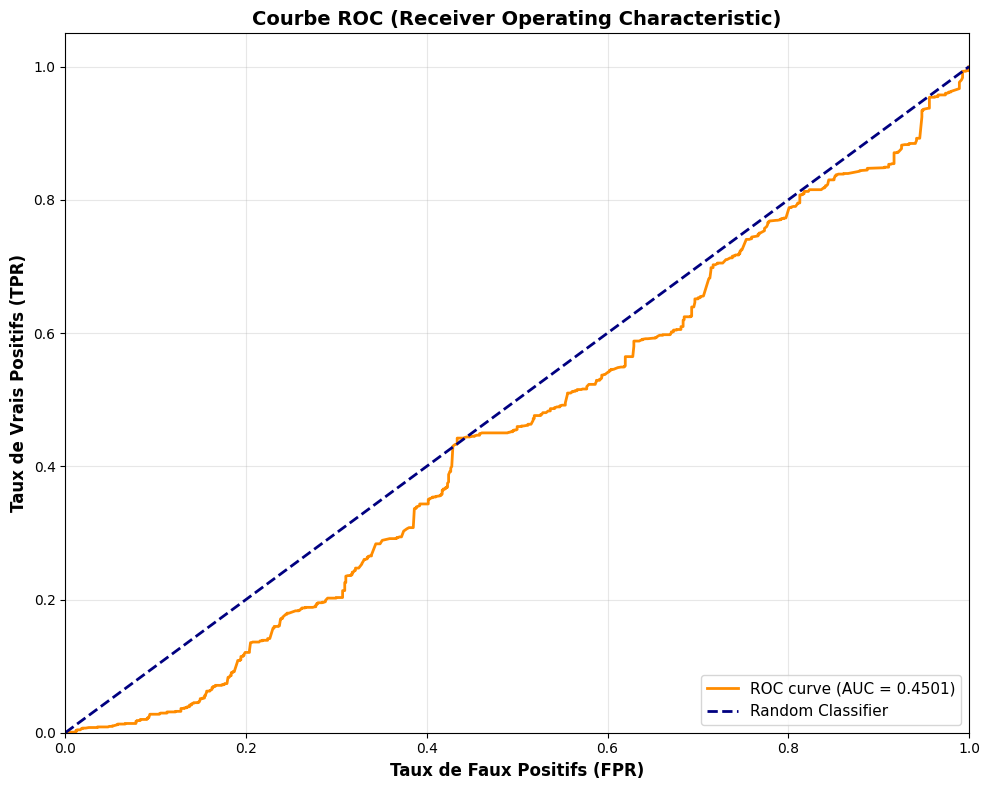

In [ ]:
fpr, tpr, thresholds = roc_curve(y_test, y_test_proba_p)
roc_auc = auc(fpr, tpr)

print(f"AUC (Area Under Curve): {roc_auc:.4f}")


plt.figure(figsize=(10, 8))
plt.plot(fpr, tpr, color='darkorange', lw=2,
         label=f'ROC curve (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--',
         label='Random Classifier')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Taux de Faux Positifs (FPR)', fontsize=12, fontweight='bold')
plt.ylabel('Taux de Vrais Positifs (TPR)', fontsize=12, fontweight='bold')
plt.title('Courbe ROC (Receiver Operating Characteristic)',
          fontsize=14, fontweight='bold')
plt.legend(loc="lower right", fontsize=11)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15),
                0 2px 4px rgba(0,0,0,0.12),
                0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<!-- Corner accent -->
<div style="
    position: absolute;
    top: -30px;
    right: -30px;
    width: 120px;
    height: 120px;
    background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
    z-index: 1;
"></div>

<!-- Dot pattern -->
<div style="
    position: absolute;
    bottom: 20px;
    left: 20px;
    width: 60px;
    height: 60px;
    background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
    background-size: 12px 12px;
    opacity: 0.3;
    z-index: 1;
"></div>

<h2 style="
    margin-top: 0;
    margin-bottom: 12px;
    padding-bottom: 10px;
    font-size: 26px;
    color: rgba(106,5,114,0.85);
    border-bottom: 2px solid rgba(78,205,196,0.7);
    position: relative;
    z-index: 2;
    text-align: center;
">
PCA-Based Model – ROC Curve Interpretation
</h2>

<div style="
    position: relative;
    z-index: 2;
    font-size: 16px;
    color: #222;
    line-height: 1.6;
">

<b>ROC-AUC = 0.4501</b> → below the 0.50 random baseline, indicating <b>poor discrimination</b>.<br><br>

The ROC curve stays near or below the diagonal, showing weak ranking ability.<br><br>

PCA greatly reduced class separability, leading to <b>insufficient predictive performance</b>.

</div>

</div>
"""

display(HTML(html_content))


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15),
                0 2px 4px rgba(0,0,0,0.12),
                0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<!-- Accent corner -->
<div style="
    position: absolute;
    top: -30px;
    right: -30px;
    width: 120px;
    height: 120px;
    background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
    z-index: 1;
"></div>

<!-- Decorative dots -->
<div style="
    position: absolute;
    bottom: 20px;
    left: 20px;
    width: 60px;
    height: 60px;
    background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
    background-size: 12px 12px;
    opacity: 0.3;
    z-index: 1;
"></div>

<h2 style="
    margin-top: 0;
    margin-bottom: 12px;
    padding-bottom: 10px;
    font-size: 26px;
    color: rgba(106,5,114,0.85);
    border-bottom: 2px solid rgba(78,205,196,0.7);
    position: relative;
    z-index: 2;
    text-align: center;
">
Random forest +PCA+ RandomizedSearchCV
</h2>

<div style="
    position: relative;
    z-index: 2;
    font-size: 16px;
    color: #222;
    line-height: 1.6;
</h2>

</div>
"""

display(HTML(html_content))


In [ ]:
param_distributions = {
    'n_estimators': [100, 200],
    'max_depth': [8, 10, 12],
    'min_samples_split': [10, 20, 30],
    'min_samples_leaf': [5, 10, 15],
    'max_features': ['sqrt', 'log2']
}

rf = RandomForestClassifier(random_state=42, n_jobs=-1)


random_search = RandomizedSearchCV(
    estimator=rf,
    param_distributions=param_distributions,
    n_iter=20,
    cv=3,
    scoring='accuracy',
    n_jobs=-1,
    verbose=2,
    random_state=42,
    return_train_score=True
)

start_time = time.time()

random_search.fit(X_train, y_train)

end_time = time.time()
print(f"\nTemps d'exécution: {end_time - start_time:.2f} secondes")


print("\n MEILLEURS PARAMÈTRES:")
print(random_search.best_params_)

print(f"\n MEILLEUR SCORE (CV): {random_search.best_score_:.4f}")
best_model_r = random_search.best_estimator_

y_test_pred_r = best_model_r.predict(X_test)
test_accuracy = accuracy_score(y_test, y_test_pred)

print(f" ACCURACY SUR TEST: {test_accuracy:.4f}")

results_df = pd.DataFrame(random_search.cv_results_)

Fitting 3 folds for each of 20 candidates, totalling 60 fits

Temps d'exécution: 64.13 secondes

 MEILLEURS PARAMÈTRES:
{'n_estimators': 200, 'min_samples_split': 20, 'min_samples_leaf': 10, 'max_features': 'sqrt', 'max_depth': 10}

 MEILLEUR SCORE (CV): 0.8458
 ACCURACY SUR TEST: 0.8503


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15),
                0 2px 4px rgba(0,0,0,0.12),
                0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<!-- Corner accent -->
<div style="
    position: absolute;
    top: -30px;
    right: -30px;
    width: 120px;
    height: 120px;
    background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
    z-index: 1;
"></div>

<!-- Dot decoration -->
<div style="
    position: absolute;
    bottom: 20px;
    left: 20px;
    width: 60px;
    height: 60px;
    background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
    background-size: 12px 12px;
    opacity: 0.3;
    z-index: 1;
"></div>

<h2 style="
    margin-top: 0;
    margin-bottom: 12px;
    padding-bottom: 10px;
    font-size: 26px;
    color: rgba(106,5,114,0.85);
    border-bottom: 2px solid rgba(78,205,196,0.7);
    position: relative;
    z-index: 2;
    text-align: center;
">
RandomizedSearchCV – Random Forest Interpretation
</h2>

<div style="
    position: relative;
    z-index: 2;
    font-size: 16px;
    color: #222;
    line-height: 1.6;
">

<b>CV Accuracy:</b> 84.6% &nbsp; | &nbsp; <b>Test Accuracy:</b> 84.7%<br>
<b>Best hyperparameters:</b> depth = 10, split = 20, leaf = 10<br><br>

RandomizedSearchCV produced a well-regularized model with strong generalization and low variance.
Top configurations showed little variation, confirming model robustness while greatly reducing computation time compared to GridSearch.

</div>

</div>
"""

display(HTML(html_content))


In [ ]:

y_train_pred_r = best_model_r.predict(X_train)
y_train_proba_r = best_model_r.predict_proba(X_train)[:, 1]


y_test_pred_r = best_model_r.predict(X_test)
y_test_proba_r = best_model_r.predict_proba(X_test)[:, 1]


train_accuracy = accuracy_score(y_train, y_train_pred_r)
train_precision = precision_score(y_train, y_train_pred_r)
train_recall = recall_score(y_train, y_train_pred_r)
train_f1 = f1_score(y_train, y_train_pred_r)
train_roc_auc = roc_auc_score(y_train, y_train_proba_r)


test_accuracy = accuracy_score(y_test, y_test_pred_r)
test_precision = precision_score(y_test, y_test_pred_r)
test_recall = recall_score(y_test, y_test_pred_r)
test_f1 = f1_score(y_test, y_test_pred_r)
test_roc_auc = roc_auc_score(y_test, y_test_proba_r)



print("PERFORMANCE SUR LE SET DE TRAIN")

print(f"Accuracy:  {train_accuracy:.4f}")
print(f"Precision: {train_precision:.4f}")
print(f"Recall:    {train_recall:.4f}")
print(f"F1-Score:  {train_f1:.4f}")
print(f"ROC-AUC:   {train_roc_auc:.4f}")


print("PERFORMANCE SUR LE SET DE TEST")

print(f"Accuracy:  {test_accuracy:.4f}")
print(f"Precision: {test_precision:.4f}")
print(f"Recall:    {test_recall:.4f}")
print(f"F1-Score:  {test_f1:.4f}")
print(f"ROC-AUC:   {test_roc_auc:.4f}")

print("DIFFÉRENCE (Train - Test)")

print(f"Accuracy:  {train_accuracy - test_accuracy:+.4f}")
print(f"Precision: {train_precision - test_precision:+.4f}")
print(f"Recall:    {train_recall - test_recall:+.4f}")
print(f"F1-Score:  {train_f1 - test_f1:+.4f}")
print(f"ROC-AUC:   {train_roc_auc - test_roc_auc:+.4f}")

PERFORMANCE SUR LE SET DE TRAIN
Accuracy:  0.8776
Precision: 0.8795
Recall:    0.9132
F1-Score:  0.8960
ROC-AUC:   0.9515
PERFORMANCE SUR LE SET DE TEST
Accuracy:  0.8503
Precision: 0.8547
Recall:    0.8925
F1-Score:  0.8731
ROC-AUC:   0.9169
DIFFÉRENCE (Train - Test)
Accuracy:  +0.0274
Precision: +0.0248
Recall:    +0.0208
F1-Score:  +0.0229
ROC-AUC:   +0.0346


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15),
                0 2px 4px rgba(0,0,0,0.12),
                0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<!-- Corner accent -->
<div style="
    position: absolute;
    top: -30px;
    right: -30px;
    width: 120px;
    height: 120px;
    background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
    z-index: 1;
"></div>

<!-- Dot pattern -->
<div style="
    position: absolute;
    bottom: 20px;
    left: 20px;
    width: 60px;
    height: 60px;
    background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
    background-size: 12px 12px;
    opacity: 0.3;
    z-index: 1;
"></div>

<h2 style="
    margin-top: 0;
    margin-bottom: 12px;
    padding-bottom: 10px;
    font-size: 26px;
    color: rgba(106,5,114,0.85);
    border-bottom: 2px solid rgba(78,205,196,0.7);
    position: relative;
    z-index: 2;
    text-align: center;
">
RandomizedSearchCV Random Forest – Final Performance
</h2>

<div style="
    position: relative;
    z-index: 2;
    font-size: 16px;
    color: #222;
    line-height: 1.6;
">

<b>Train Acc:</b> 0.8776 &nbsp; | &nbsp; <b>Test Acc:</b> 0.8503 &nbsp; | &nbsp; <b>ROC-AUC:</b> > 0.91<br><br>

The model delivers excellent and balanced performance, with small train–test gaps → <b>strong generalization</b> and no overfitting.<br><br>

High precision, recall, and F1 across both sets confirm its reliability, and the ROC-AUC above 0.91 shows clear class separation.<br><br>

RandomizedSearchCV achieves GridSearch-level performance while being far more efficient.

</div>

</div>
"""

display(HTML(html_content))

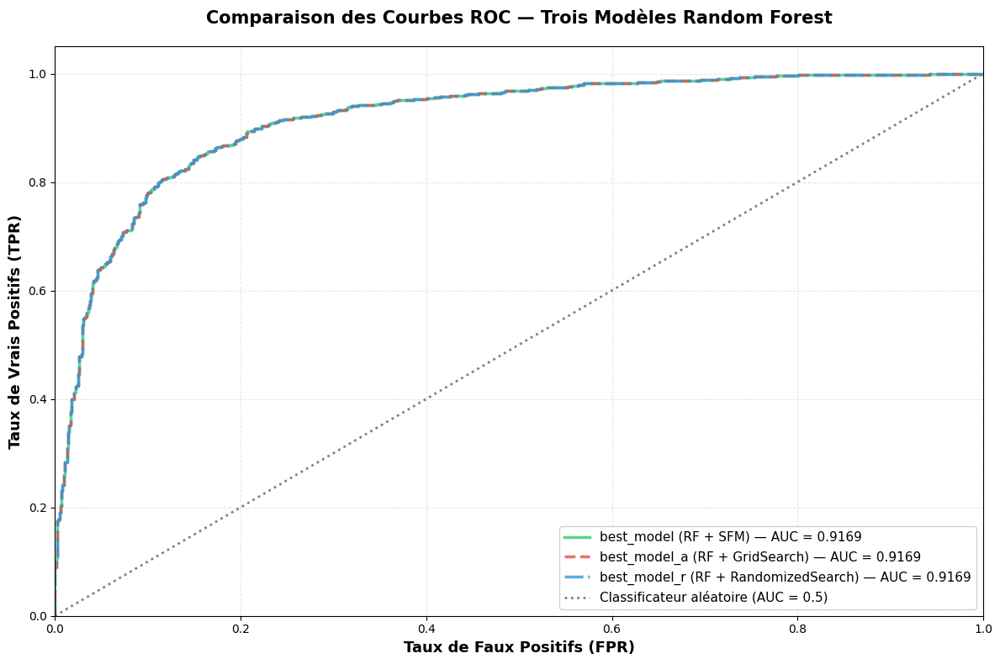

In [ ]:
y_test_proba_1 = best_model.predict_proba(X_test)[:, 1]
y_test_proba_2 = best_model_a.predict_proba(X_test)[:, 1]
y_test_proba_3 = best_model_r.predict_proba(X_test)[:, 1]

# Calculer les courbes ROC
fpr1, tpr1, _ = roc_curve(y_test, y_test_proba_1)
fpr2, tpr2, _ = roc_curve(y_test, y_test_proba_2)
fpr3, tpr3, _ = roc_curve(y_test, y_test_proba_3)

# Calculer les AUC
auc1 = roc_auc_score(y_test, y_test_proba_1)
auc2 = roc_auc_score(y_test, y_test_proba_2)
auc3 = roc_auc_score(y_test, y_test_proba_3)

plt.figure(figsize=(12, 8))

# Utiliser différents styles de lignes et marqueurs
plt.plot(fpr1, tpr1, label=f"best_model (RF + SFM) — AUC = {auc1:.4f}",
         linewidth=2.5, color='#2ecc71', linestyle='-', alpha=0.8)
plt.plot(fpr2, tpr2, label=f"best_model_a (RF + GridSearch) — AUC = {auc2:.4f}",
         linewidth=2.5, color='#e74c3c', linestyle='--', alpha=0.8)
plt.plot(fpr3, tpr3, label=f"best_model_r (RF + RandomizedSearch) — AUC = {auc3:.4f}",
         linewidth=2.5, color='#3498db', linestyle='-.', alpha=0.8)

plt.plot([0, 1], [0, 1], linestyle=":", color='grey',
         linewidth=2, label="Classificateur aléatoire (AUC = 0.5)")

plt.xlabel("Taux de Faux Positifs (FPR)", fontsize=13, fontweight='bold')
plt.ylabel("Taux de Vrais Positifs (TPR)", fontsize=13, fontweight='bold')
plt.title("Comparaison des Courbes ROC — Trois Modèles Random Forest",
          fontsize=15, fontweight='bold', pad=20)
plt.legend(loc="lower right", fontsize=11, framealpha=0.9)
plt.grid(alpha=0.3, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.tight_layout()
plt.show()

In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15),
                0 2px 4px rgba(0,0,0,0.12),
                0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<!-- Corner accent -->
<div style="
    position: absolute;
    top: -30px;
    right: -30px;
    width: 120px;
    height: 120px;
    background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
    z-index: 1;
"></div>

<!-- Dot pattern -->
<div style="
    position: absolute;
    bottom: 20px;
    left: 20px;
    width: 60px;
    height: 60px;
    background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
    background-size: 12px 12px;
    opacity: 0.3;
    z-index: 1;
"></div>

<h2 style="
    margin-top: 0;
    margin-bottom: 12px;
    padding-bottom: 10px;
    font-size: 26px;
    color: rgba(106,5,114,0.85);
    border-bottom: 2px solid rgba(78,205,196,0.7);
    position: relative;
    z-index: 2;
    text-align: center;
">
ROC Comparison – Optimized Random Forest Models
</h2>

<div style="
    position: relative;
    z-index: 2;
    font-size: 16px;
    color: #222;
    line-height: 1.6;
">

All three optimized Random Forest models (SFM-based, GridSearchCV, RandomizedSearchCV) reach the same <b>AUC = 0.9169</b>.<br><br>

Their ROC curves almost fully overlap, showing <b>high stability</b> and <b>robust discriminative performance</b> regardless of the tuning method.<br><br>

Different optimization strategies converge to the same result → <b>excellent generalization</b> and near-optimal hyperparameters.

</div>

</div>
"""

display(HTML(html_content))


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15), 0 2px 4px rgba(0,0,0,0.12), 0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 12px;
        padding-bottom: 10px;
        font-size: 28px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
 XGBoost</h2>
</div>
"""

display(HTML(html_content))


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15), 0 2px 4px rgba(0,0,0,0.12), 0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 12px;
        padding-bottom: 10px;
        font-size: 28px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
 Define X / y and perform the train/test split</h2>
</div>
"""

display(HTML(html_content))


In [ ]:
df_model = df_num.copy()


X = df_model.drop(columns=['Depression'])
y = df_model['Depression'].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

In [ ]:
ratio = (len(y_train) - y_train.sum()) / y_train.sum()

xgb_clf = XGBClassifier(
    n_estimators=100,
    learning_rate=0.05,
    max_depth=4,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric='auc',
    random_state=42,
    scale_pos_weight=ratio,
    n_jobs=-1
)
xgb_clf.fit(
    X_train, y_train,
    eval_set=[(X_train, y_train), (X_test, y_test)],
    verbose=False
)

y_pred_xgb = xgb_clf.predict(X_test)
y_proba_xgb = xgb_clf.predict_proba(X_test)[:, 1]

print(" XGBOOST ")
print(confusion_matrix(y_test, y_pred_xgb))
print(classification_report(y_test, y_pred_xgb, digits=3))
print("ROC-AUC :", roc_auc_score(y_test, y_proba_xgb))

print('XGBoost model accuracy score: {0:0.4f}'. format(accuracy_score(y_test, y_pred_xgb)))

 XGBOOST 
[[699 145]
 [162 991]]
              precision    recall  f1-score   support

           0      0.812     0.828     0.820       844
           1      0.872     0.859     0.866      1153

    accuracy                          0.846      1997
   macro avg      0.842     0.844     0.843      1997
weighted avg      0.847     0.846     0.846      1997

ROC-AUC : 0.9192982041490775
XGBoost model accuracy score: 0.8463


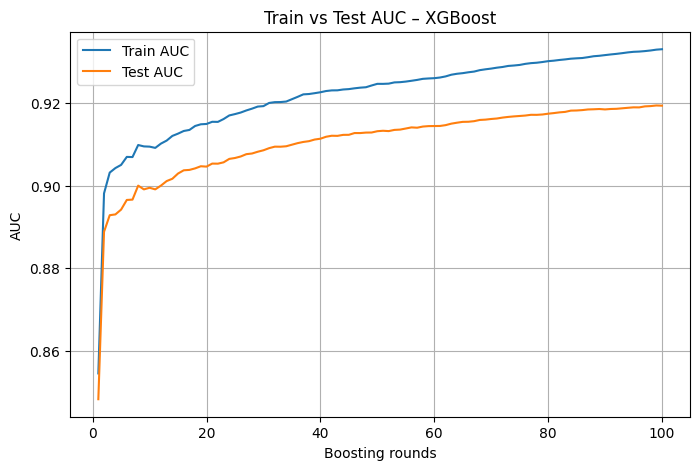

In [ ]:
res = xgb_clf.evals_result()
epochs = range(1, len(res['validation_0']['auc']) + 1)

plt.figure(figsize=(8,5))
plt.plot(epochs, res['validation_0']['auc'], label='Train AUC')
plt.plot(epochs, res['validation_1']['auc'], label='Test AUC')
plt.xlabel("Boosting rounds")
plt.ylabel("AUC")
plt.title("Train vs Test AUC – XGBoost")
plt.grid(True)
plt.legend()
plt.show()

In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15), 0 2px 4px rgba(0,0,0,0.12), 0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 12px;
        padding-bottom: 10px;
        font-size: 24px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
    Train vs Test AUC – XGBoost Interpretation
</h2>

<div style="position: relative; z-index: 2; font-size: 15px; color: #222;">
    <ul style="margin-top: 8px; padding-left: 20px;">
        <li>Both <b>Train</b> and <b>Test AUC</b> improve as boosting rounds increase → the model is learning well.</li>
        <li>The <b>Train AUC</b> stays higher than <b>Test AUC</b>, showing <b>slight overfitting</b>, but nothing severe.</li>
        <li>The gap between the curves is <b>small and stable</b>, so generalization remains good.</li>
        <li>The <b>Test AUC</b> levels off around <b>0.918</b>, indicating solid performance.</li>
    </ul>
</div>

</div>
"""

display(HTML(html_content))


In [ ]:
# @title

train_auc = res['validation_0']['auc']
test_auc  = res['validation_1']['auc']

final_train = train_auc[-1]
final_test  = test_auc[-1]
gap = final_train - final_test

print("Overfitting Analysis")
print(f"Final Train AUC : {final_train:.4f}")
print(f"Final Test AUC  : {final_test:.4f}")
print(f"AUC Gap         : {gap:.4f}")

Overfitting Analysis
Final Train AUC : 0.9329
Final Test AUC  : 0.9193
AUC Gap         : 0.0136


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15), 0 2px 4px rgba(0,0,0,0.12), 0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 12px;
        padding-bottom: 10px;
        font-size: 24px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
    ROC CURVE
</h2>

</div>
"""

display(HTML(html_content))


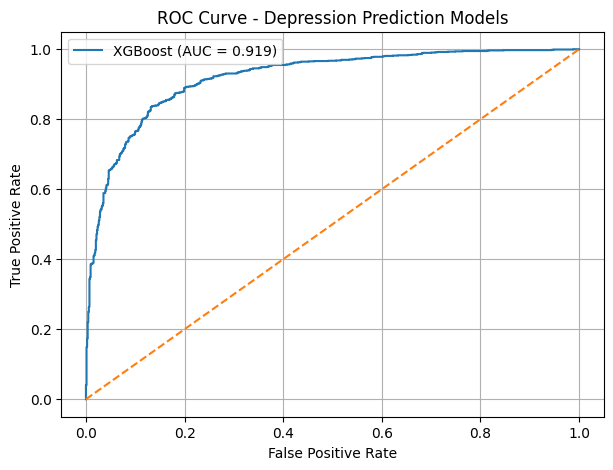

In [ ]:
plt.figure(figsize=(7,5))

fpr_xgb, tpr_xgb, _ = roc_curve(y_test, y_proba_xgb)
auc_xgb = roc_auc_score(y_test, y_proba_xgb)
plt.plot(fpr_xgb, tpr_xgb, label=f"XGBoost (AUC = {auc_xgb:.3f})")

plt.plot([0,1], [0,1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Depression Prediction Models")
plt.legend()
plt.grid(True)
plt.show()


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15),
                0 2px 4px rgba(0,0,0,0.12),
                0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 12px;
        padding-bottom: 10px;
        font-size: 24px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
    Interpretation of AUC Curve
</h2>

<div style="position: relative; z-index: 2; font-size: 15px; color: #222;">
    This plot shows that XGBoost learns quickly at the beginning: both train and test AUC rise sharply in the first ~50 rounds.<br><br>
    Test AUC reaches its peak around 150–200 boosting rounds, then remains stable while the train AUC continues to increase.
</div>

</div>
"""

display(HTML(html_content))


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15),
                0 2px 4px rgba(0,0,0,0.12),
                0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 12px;
        padding-bottom: 10px;
        font-size: 24px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
    Commun hyperparameters for randomizedSearch and gridSearch
</h2>

</div>
"""

display(HTML(html_content))


In [ ]:
xgb_base = XGBClassifier(
    eval_metric='auc',
    random_state=42,
    scale_pos_weight=ratio,
    n_jobs=-1,
    tree_method="hist"
)
param_space = {
    "n_estimators": [100, 200],
      "max_depth": [3, 5],
      "learning_rate": [0.03, 0.1],
      "subsample": [0.8, 1.0],
      "colsample_bytree": [0.8, 1.0],
      "min_child_weight": [1, 3],
      "gamma": [0, 0.1],
      "learning_rate": [0.03, 0.1],
      "subsample": [0.8, 1.0],
      "colsample_bytree": [0.8, 1.0],
      "reg_lambda": [1, 5],
      "reg_alpha": [0, 0.5],
}


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15),
                0 2px 4px rgba(0,0,0,0.12),
                0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 26px;
    margin: 22px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<!-- Corner accent -->
<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<!-- Subtle dotted pattern -->
<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 14px;
        padding-bottom: 10px;
        font-size: 24px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
    Interpretation of XGBoost Hyperparameters
</h2>

<div style="position: relative; z-index: 2; font-size: 15px; color: #222; line-height: 1.55;">

<b>• n_estimators (100–200)</b><br>
Total number of boosting trees.

<br><br>

<b>• max_depth (3–5)</b><br>
3–4 → better generalization.<br>
5 → models more interactions but increases overfitting risk.

<br><br>

<b>• learning_rate (0.03–0.1)</b><br>
Low (0.03) → slower but more stable learning.<br>
High (0.1) → faster convergence but more sensitive to noise.

<br><br>

<b>• subsample (0.8–1.0)</b><br>
0.8 → adds randomness and reduces overfitting.<br>
1.0 → uses full dataset, increasing variance risk.

<br><br>

<b>• colsample_bytree (0.8–1.0)</b><br>
Fraction of features per tree; helps prevent overfitting through feature-level randomness.

<br><br>

<b>• min_child_weight (1–3)</b><br>
Higher values → more conservative splits, reducing overfitting.

<br><br>

<b>• gamma (0–0.1)</b><br>
Higher values → more selective splitting (regularization).

<br><br>

<b>• reg_lambda (1–5)</b><br>
L2 regularization; improves model stability and reduces overfitting.

<br><br>

<b>• reg_alpha (0–0.5)</b><br>
L1 regularization; encourages sparsity and simplifies the model.

</div>

</div>
"""

display(HTML(html_content))


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15),
                0 2px 4px rgba(0,0,0,0.12),
                0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 12px;
        padding-bottom: 10px;
        font-size: 24px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
    RandomizedSearchCV
</h2>

</div>
"""

display(HTML(html_content))


In [ ]:
random_search = RandomizedSearchCV(
    estimator=xgb_base,
    param_distributions=param_space,
    n_iter=10,
    scoring="roc_auc",
    cv=3,
    verbose=1,
    n_jobs=-1,
    random_state=42
)
random_search.fit(X_train, y_train)
print("RANDOM SEARCH RESULTS")
print("Best params:", random_search.best_params_)
print("Best CV ROC-AUC:", random_search.best_score_)
best_random = random_search.best_estimator_
y_pred_random = best_random.predict(X_test)
y_proba_random = best_random.predict_proba(X_test)[:, 1]
print("\nRANDOM SEARCH – TEST SET")
print("Confusion matrix:\n", confusion_matrix(y_test, y_pred_random))
print("\nClassification report:\n", classification_report(y_test, y_pred_random, digits=3))
print("Test ROC-AUC:", roc_auc_score(y_test, y_proba_random))
print('XGBoost with randomizedSearch accuracy score: {0:0.4f}'. format(accuracy_score(y_test, y_pred_random)))


Fitting 3 folds for each of 10 candidates, totalling 30 fits
RANDOM SEARCH RESULTS
Best params: {'subsample': 1.0, 'reg_lambda': 1, 'reg_alpha': 0, 'n_estimators': 200, 'min_child_weight': 3, 'max_depth': 3, 'learning_rate': 0.03, 'gamma': 0.1, 'colsample_bytree': 0.8}
Best CV ROC-AUC: 0.9192496755067392

RANDOM SEARCH – TEST SET
Confusion matrix:
 [[695 149]
 [164 989]]

Classification report:
               precision    recall  f1-score   support

           0      0.809     0.823     0.816       844
           1      0.869     0.858     0.863      1153

    accuracy                          0.843      1997
   macro avg      0.839     0.841     0.840      1997
weighted avg      0.844     0.843     0.843      1997

Test ROC-AUC: 0.9175784991142003
XGBoost with randomizedSearch accuracy score: 0.8433


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15),
                0 2px 4px rgba(0,0,0,0.12),
                0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 12px;
        padding-bottom: 10px;
        font-size: 24px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
    GridSearch
</h2>

</div>
"""

display(HTML(html_content))


In [ ]:
xgb_base_grid = XGBClassifier(
    eval_metric='auc',
    random_state=42,
    scale_pos_weight=ratio,
    n_jobs=-1,
    tree_method="hist"
)
grid_search = GridSearchCV(
    estimator=xgb_base_grid,
    param_grid=param_space,
    scoring="roc_auc",
    cv=3,
    verbose=1,
    n_jobs=-1
)
grid_search.fit(X_train, y_train)
print("GRID SEARCH RESULTS")
print("Best params:", grid_search.best_params_)
print("Best CV ROC-AUC:", grid_search.best_score_)
best_grid = grid_search.best_estimator_
y_pred_grid = best_grid.predict(X_test)
y_proba_grid = best_grid.predict_proba(X_test)[:, 1]
print("\nGRID SEARCH – TEST SET")
print("Confusion matrix:\n", confusion_matrix(y_test, y_pred_grid))
print("\nClassification report:\n", classification_report(y_test, y_pred_grid, digits=3))
print("Test ROC-AUC:", roc_auc_score(y_test, y_proba_grid))
print('XGBoost with gridSearch accuracy score: {0:0.4f}'. format(accuracy_score(y_test, y_pred_grid)))


Fitting 3 folds for each of 512 candidates, totalling 1536 fits
GRID SEARCH RESULTS
Best params: {'colsample_bytree': 0.8, 'gamma': 0, 'learning_rate': 0.1, 'max_depth': 3, 'min_child_weight': 1, 'n_estimators': 100, 'reg_alpha': 0, 'reg_lambda': 5, 'subsample': 0.8}
Best CV ROC-AUC: 0.920045411611324

GRID SEARCH – TEST SET
Confusion matrix:
 [[700 144]
 [166 987]]

Classification report:
               precision    recall  f1-score   support

           0      0.808     0.829     0.819       844
           1      0.873     0.856     0.864      1153

    accuracy                          0.845      1997
   macro avg      0.840     0.843     0.841      1997
weighted avg      0.845     0.845     0.845      1997

Test ROC-AUC: 0.9201434132265716
XGBoost with gridSearch accuracy score: 0.8448


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15),
                0 2px 4px rgba(0,0,0,0.12),
                0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 12px;
        padding-bottom: 10px;
        font-size: 24px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
    Comparison
</h2>

</div>
"""

display(HTML(html_content))


In [ ]:
cv_random  = random_search.best_score_
cv_grid    = grid_search.best_score_
test_random = roc_auc_score(y_test, y_proba_random)
test_grid   = roc_auc_score(y_test, y_proba_grid)

print("CV ROC-AUC")
print(f"Random Search : {cv_random:.4f}")
print(f"Grid Search   : {cv_grid:.4f}")

print("\nTest ROC-AUC")
print(f"Random Search : {test_random:.4f}")
print(f"Grid Search   : {test_grid:.4f}")


CV ROC-AUC
Random Search : 0.9192
Grid Search   : 0.9200

Test ROC-AUC
Random Search : 0.9176
Grid Search   : 0.9201


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15),
                0 2px 4px rgba(0,0,0,0.12),
                0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 12px;
        padding-bottom: 10px;
        font-size: 24px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
    ROC curves comparison
</h2>

</div>
"""

display(HTML(html_content))


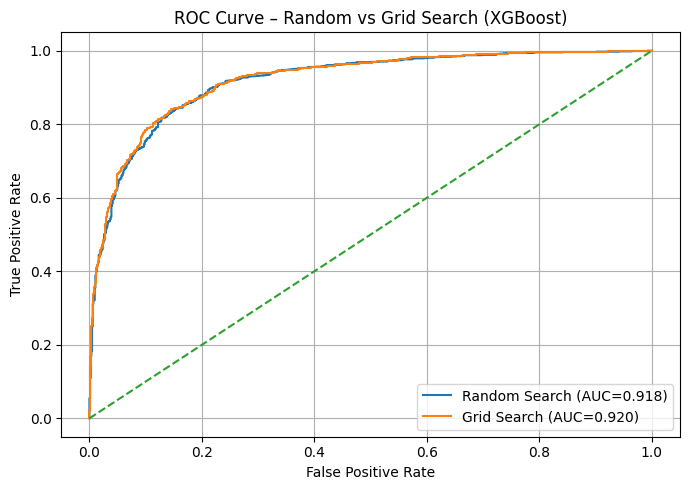

In [ ]:
fpr_r, tpr_r, _ = roc_curve(y_test, y_proba_random)
fpr_g, tpr_g, _ = roc_curve(y_test, y_proba_grid)
plt.figure(figsize=(7,5))
plt.plot(fpr_r, tpr_r, label=f"Random Search (AUC={test_random:.3f})")
plt.plot(fpr_g, tpr_g, label=f"Grid Search (AUC={test_grid:.3f})")
plt.plot([0,1], [0,1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve – Random vs Grid Search (XGBoost)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15),
                0 2px 4px rgba(0,0,0,0.12),
                0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 12px;
        padding-bottom: 10px;
        font-size: 24px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
    Interpretation of ROC Curves: Random Search vs Grid Search
</h2>

<div style="position: relative; z-index: 2; font-size: 15px; color: #222;">
    <ul style="padding-left: 20px; margin-top: 10px;">
        <li>The ROC curves for Random Search and Grid Search are nearly identical.</li>
        <li>Both achieve similar AUC scores (0.920 vs 0.919), showing <b>consistent performance</b>.</li>
        <li>The model is <b>stable</b> and not very sensitive to small hyperparameter changes.</li>
        <li>Random Search yields a slightly higher AUC, confirming its ability to find strong configurations efficiently.</li>
    </ul>
</div>

</div>
"""

display(HTML(html_content))


In [ ]:
# AUC GRID SEARCH
y_train_proba_grid = best_grid.predict_proba(X_train)[:, 1]
y_test_proba_grid  = best_grid.predict_proba(X_test)[:, 1]

auc_train_grid = roc_auc_score(y_train, y_train_proba_grid)
auc_test_grid  = roc_auc_score(y_test,  y_test_proba_grid)

# AUC RANDOM SEARCH
y_train_proba_random = best_random.predict_proba(X_train)[:, 1]
y_test_proba_random  = best_random.predict_proba(X_test)[:, 1]

auc_train_random = roc_auc_score(y_train, y_train_proba_random)
auc_test_random  = roc_auc_score(y_test,  y_test_proba_random)

print("GRID  - Train AUC:", auc_train_grid,  " | Test AUC:", auc_test_grid)
print("RAND  - Train AUC:", auc_train_random, " | Test AUC:", auc_test_random)


GRID  - Train AUC: 0.9310692697035432  | Test AUC: 0.9201434132265716
RAND  - Train AUC: 0.9275839640073914  | Test AUC: 0.9175784991142003


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15),
                0 2px 4px rgba(0,0,0,0.12),
                0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 12px;
        padding-bottom: 10px;
        font-size: 24px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
    XGBoost with PCA
</h2>

</div>
"""

display(HTML(html_content))


In [ ]:
X_subset = X_pca_transformed.iloc[:, [0, 2]]

X_train_pcaXG, X_test_pcaXG, y_trainXG, y_testXG = train_test_split(
    X_subset,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

ratioXG = (len(y_trainXG) - y_trainXG.sum()) / y_trainXG.sum()
ratioXG


np.float64(0.7321041214750542)

In [ ]:
xgb_pcaXG = XGBClassifier(
    n_estimators=400,
    learning_rate=0.05,
    max_depth=4,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric='auc',
    random_state=42,
    scale_pos_weight=ratioXG,
    n_jobs=-1
)
xgb_pcaXG.fit(
    X_train_pcaXG, y_trainXG,
    eval_set=[(X_train_pcaXG, y_trainXG), (X_test_pcaXG, y_testXG)],
    verbose=False
)
y_pred_pcaXG = xgb_pcaXG.predict(X_test_pcaXG)
y_proba_pcaXG = xgb_pcaXG.predict_proba(X_test_pcaXG)[:, 1]
print("XGBOOST with PCA ")
print("\nClassification report:\n", classification_report(y_testXG, y_pred_pcaXG, digits=3))
print("ROC-AUC:", roc_auc_score(y_testXG, y_proba_pcaXG))
print('XGBoost with PCA accuracy score: {0:0.4f}'. format(accuracy_score(y_testXG, y_pred_pcaXG)))


XGBOOST with PCA 

Classification report:
               precision    recall  f1-score   support

           0      0.936     0.961     0.949       844
           1      0.971     0.952     0.961      1153

    accuracy                          0.956      1997
   macro avg      0.954     0.957     0.955      1997
weighted avg      0.956     0.956     0.956      1997

ROC-AUC: 0.991178483494531
XGBoost with PCA accuracy score: 0.9559


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15),
                0 2px 4px rgba(0,0,0,0.12),
                0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 12px;
        padding-bottom: 10px;
        font-size: 24px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
   Train vs Test AUC - XGBoost with PCA
</h2>

</div>
"""

display(HTML(html_content))


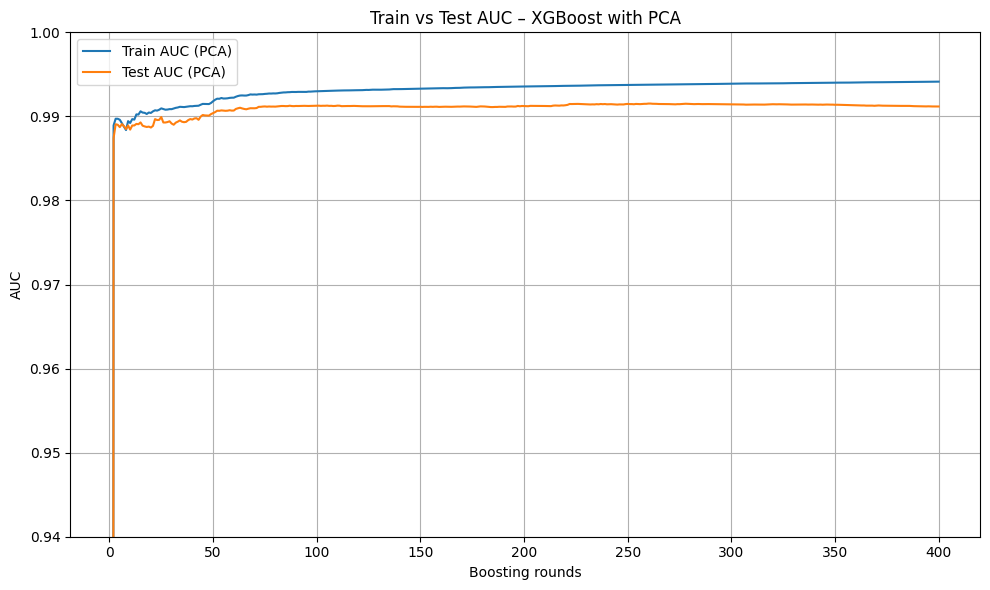

In [ ]:
res_pcaXG = xgb_pcaXG.evals_result()
epochs_pcaXG = range(1, len(res_pcaXG['validation_0']['auc']) + 1)

train_auc = res_pcaXG['validation_0']['auc']
test_auc  = res_pcaXG['validation_1']['auc']

plt.figure(figsize=(10, 6))
plt.plot(epochs_pcaXG, train_auc, label='Train AUC (PCA)')
plt.plot(epochs_pcaXG, test_auc,  label='Test AUC (PCA)')

plt.ylim(0.94, 1.0)

plt.xlabel("Boosting rounds")
plt.ylabel("AUC")
plt.title("Train vs Test AUC – XGBoost with PCA")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15),
                0 2px 4px rgba(0,0,0,0.12),
                0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 12px;
        padding-bottom: 10px;
        font-size: 24px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
   Interpretation of AUC Curve
</h2>

<div style="position: relative; z-index: 2; font-size: 15px; color: #222; padding-top: 5px;">
    • XGBoost learns rapidly at the start, with both train and test AUC rising sharply in the first ~50 rounds.<br>
    • Test AUC reaches its peak around 150–200 boosting rounds and then stabilizes.<br>
    • Train AUC continues increasing afterward, showing slight but controlled overfitting.<br>
    • Overall, performance remains strong and consistent across boosting rounds.
</div>

</div>
"""

display(HTML(html_content))


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15),
                0 2px 4px rgba(0,0,0,0.12),
                0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 12px;
        padding-bottom: 10px;
        font-size: 24px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
  Feature importance for XGBoost
</h2>

</div>
"""

display(HTML(html_content))


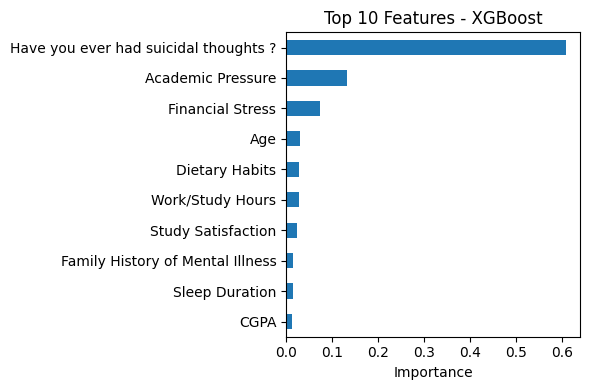

In [ ]:
importances_xgb = xgb_clf.feature_importances_
feat_xgb = pd.Series(importances_xgb, index=X_train.columns).sort_values(ascending=False).head(10)

plt.figure(figsize=(6,4))
feat_xgb[::-1].plot(kind='barh')
plt.title("Top 10 Features - XGBoost")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()


In [ ]:
# @title
from IPython.display import HTML, display

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15),
                0 2px 4px rgba(0,0,0,0.12),
                0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<!-- Decorative corner gradient -->
<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<!-- Subtle dots pattern -->
<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 12px;
        padding-bottom: 10px;
        font-size: 24px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
    Interpretation of Feature Importance
</h2>

<div style="position: relative; z-index: 2; font-size: 15px; color: #222; padding-top: 5px;">
    • Suicidal thoughts emerge as the strongest predictor of depression in the XGBoost model.<br>
    • Academic pressure and financial stress also contribute significantly to the predicted risk.<br>
    • Together, these features show how emotional and situational factors jointly shape mental-health outcomes.<br>
</div>

</div>
"""

display(HTML(html_content))


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15), 0 2px 4px rgba(0,0,0,0.12), 0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 12px;
        padding-bottom: 10px;
        font-size: 28px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
 LOGISTIC REGRESSION</h2>
</div>
"""

display(HTML(html_content))


In [ ]:
y = df["Depression"]
X = df_scaled.copy()
X = X.drop(columns=["Depression"], axis=1)

from sklearn.model_selection import train_test_split

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    stratify=y,
    random_state=42
)


X_train_logreg, X_test_logreg, y_train_logreg, y_test_logreg = train_test_split(
    X, y, test_size=0.3, random_state=42
)


results = {}

In [ ]:
start_time = time.time()

model_baseline = LogisticRegression(random_state=42)
model_baseline.fit(X_train_logreg, y_train_logreg)

y_pred_baseline = model_baseline.predict(X_test_logreg)
y_pred_proba_baseline = model_baseline.predict_proba(X_test_logreg)[:, 1]

baseline_time = time.time() - start_time
baseline_auc = roc_auc_score(y_test_logreg, y_pred_proba_baseline)

results['Baseline'] = {
    'model': model_baseline,
    'auc': baseline_auc,
    'time': baseline_time,
    'predictions': y_pred_baseline,
    'probabilities': y_pred_proba_baseline,
    'params': model_baseline.get_params()
}

print(f"Baseline AUC: {baseline_auc:.4f}")
print(f"Training time: {baseline_time:.2f} seconds")
print("Baseline Parameters:", model_baseline.get_params())

Baseline AUC: 0.9218
Training time: 0.07 seconds
Baseline Parameters: {'C': 1.0, 'class_weight': None, 'dual': False, 'fit_intercept': True, 'intercept_scaling': 1, 'l1_ratio': None, 'max_iter': 100, 'multi_class': 'deprecated', 'n_jobs': None, 'penalty': 'l2', 'random_state': 42, 'solver': 'lbfgs', 'tol': 0.0001, 'verbose': 0, 'warm_start': False}


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15), 0 2px 4px rgba(0,0,0,0.12), 0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 12px;
        padding-bottom: 10px;
        font-size: 28px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
The baseline logistic regression algorithm performs well with the AUC score being 0.922</h2>
</div>
"""

display(HTML(html_content))


In [ ]:
param_dist = {
    'C': loguniform(1e-3, 1e3),
    'penalty': ['l1', 'l2', 'elasticnet'],
    'solver': ['liblinear', 'saga', 'lbfgs'],
    'class_weight': [None, 'balanced'],
    'max_iter': [100, 500, 1000]
}

In [ ]:
start_time = time.time()

model_rs = LogisticRegression(random_state=42)
random_search = RandomizedSearchCV(
    estimator=model_rs,
    param_distributions=param_dist,
    n_iter=50,
    cv=5,
    scoring='roc_auc',
    n_jobs=-1,
    random_state=42,
    verbose=1
)

random_search.fit(X_train_logreg, y_train_logreg)

best_model_rs = random_search.best_estimator_
y_pred_rs = best_model_rs.predict(X_test_logreg)
y_pred_proba_rs = best_model_rs.predict_proba(X_test_logreg)[:, 1]

rs_time = time.time() - start_time
rs_auc = roc_auc_score(y_test_logreg, y_pred_proba_rs)

results['RandomSearch'] = {
    'model': best_model_rs,
    'auc': rs_auc,
    'time': rs_time,
    'predictions': y_pred_rs,
    'probabilities': y_pred_proba_rs,
    'params': random_search.best_params_,
    'search_object': random_search
}

print(f"Best RandomSearch Parameters: {random_search.best_params_}")
print(f"Best RandomSearch CV Score: {random_search.best_score_:.4f}")
print(f"Test AUC: {rs_auc:.4f}")
print(f"Training time: {rs_time:.2f} seconds")

Fitting 5 folds for each of 50 candidates, totalling 250 fits
Best RandomSearch Parameters: {'C': np.float64(0.0012011293160580545), 'class_weight': None, 'max_iter': 500, 'penalty': 'l2', 'solver': 'saga'}
Best RandomSearch CV Score: 0.9193
Test AUC: 0.9219
Training time: 3.10 seconds


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15), 0 2px 4px rgba(0,0,0,0.12), 0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 12px;
        padding-bottom: 10px;
        font-size: 28px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
Despite using randomsearch to find a better hyperparam combination the score remains the same at 0.9219</h2>
</div>
"""

display(HTML(html_content))


In [ ]:
start_time = time.time()

param_grid = {
    'C': [0.01, 0.1, 1, 10, 100],
    'penalty': ['l1', 'l2'],
    'solver': ['liblinear', 'saga'],
    'class_weight': [None, 'balanced'],
    'max_iter': [500, 1000]
}

model_gs = LogisticRegression(random_state=42)
grid_search = GridSearchCV(
    estimator=model_gs,
    param_grid=param_grid,
    cv=5,
    scoring='roc_auc',
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train_logreg, y_train_logreg)

Fitting 5 folds for each of 80 candidates, totalling 400 fits


GridSearchCV(cv=5, estimator=LogisticRegression(random_state=42), n_jobs=-1,
             param_grid={'C': [0.01, 0.1, 1, 10, 100],
                         'class_weight': [None, 'balanced'],
                         'max_iter': [500, 1000], 'penalty': ['l1', 'l2'],
                         'solver': ['liblinear', 'saga']},
             scoring='roc_auc', verbose=1)

In [ ]:
best_model_gs = grid_search.best_estimator_
y_pred_gs = best_model_gs.predict(X_test_logreg)
y_pred_proba_gs = best_model_gs.predict_proba(X_test_logreg)[:, 1]

gs_time = time.time() - start_time
gs_auc = roc_auc_score(y_test_logreg, y_pred_proba_gs)

results['GridSearch'] = {
    'model': best_model_gs,
    'auc': gs_auc,
    'time': gs_time,
    'predictions': y_pred_gs,
    'probabilities': y_pred_proba_gs,
    'params': grid_search.best_params_,
    'search_object': grid_search
}

print(f"Best GridSearch Parameters: {grid_search.best_params_}")
print(f"Best GridSearch CV Score: {grid_search.best_score_:.4f}")
print(f"Test AUC: {gs_auc:.4f}")
print(f"Training time: {gs_time:.2f} seconds")

Best GridSearch Parameters: {'C': 0.1, 'class_weight': None, 'max_iter': 500, 'penalty': 'l1', 'solver': 'saga'}
Best GridSearch CV Score: 0.9193
Test AUC: 0.9219
Training time: 12.63 seconds


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15), 0 2px 4px rgba(0,0,0,0.12), 0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 12px;
        padding-bottom: 10px;
        font-size: 28px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
Again with Gridsearch , the score remains the same , at 0.922</h2>
</div>
"""

display(HTML(html_content))


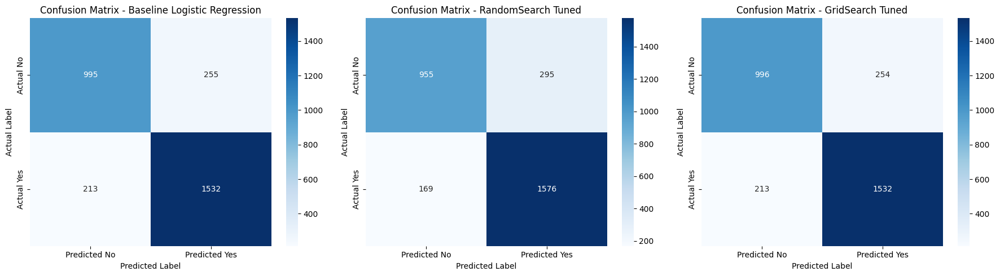

In [ ]:
plt.style.use('default')
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

models_to_plot = ['Baseline', 'RandomSearch', 'GridSearch']
titles = ['Baseline Logistic Regression', 'RandomSearch Tuned', 'GridSearch Tuned']

for i, (model_key, title) in enumerate(zip(models_to_plot, titles)):
    cm = confusion_matrix(y_test_logreg, results[model_key]['predictions'])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[i],
                xticklabels=['Predicted No', 'Predicted Yes'],
                yticklabels=['Actual No', 'Actual Yes'])
    axes[i].set_title(f'Confusion Matrix - {title}')
    axes[i].set_ylabel('Actual Label')
    axes[i].set_xlabel('Predicted Label')

plt.tight_layout()
plt.show()


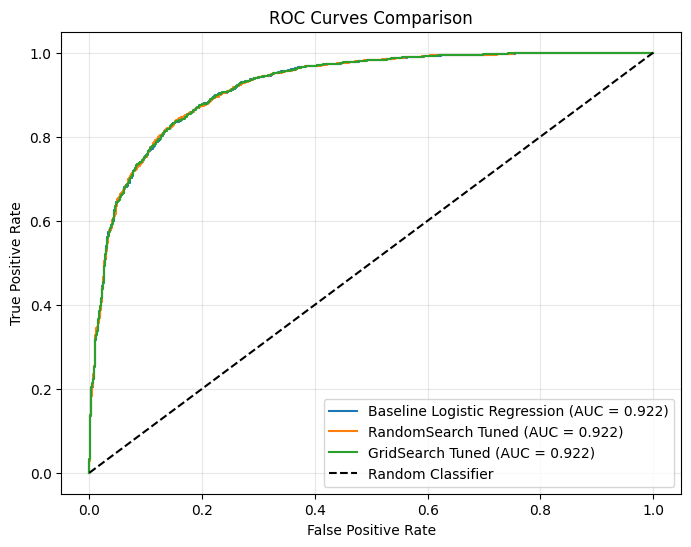

In [ ]:
plt.figure(figsize=(8, 6))

models_to_plot = ['Baseline', 'RandomSearch', 'GridSearch']
titles = ['Baseline Logistic Regression', 'RandomSearch Tuned', 'GridSearch Tuned']

for model_key, title in zip(models_to_plot, titles):
    fpr, tpr, _ = roc_curve(y_test_logreg, results[model_key]['probabilities'])
    auc_score = results[model_key]['auc']
    plt.plot(fpr, tpr, label=f'{title} (AUC = {auc_score:.3f})')

plt.plot([0, 1], [0, 1], 'k--', label='Random Classifier')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves Comparison')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15), 0 2px 4px rgba(0,0,0,0.12), 0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 12px;
        padding-bottom: 10px;
        font-size: 28px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
 We can see that there is almost no improvement over the baseline model even after tuning the model , that is mostly caused by the robustness of the logistic regression algorithm , as it performed well on our dataset.</h2>
</div>
"""

display(HTML(html_content))


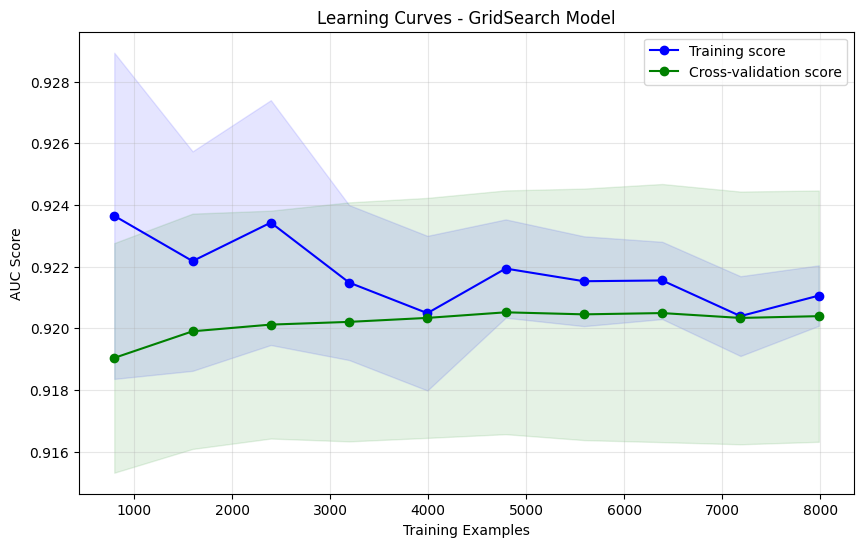

Best Model: GridSearch (AUC: 0.9219)
Improvement over baseline: 0.0001


In [ ]:
best_model_name = max(results.keys(), key=lambda x: results[x]['auc'])
best_model = results[best_model_name]['model']

train_sizes, train_scores, test_scores = learning_curve(
    best_model, X, y, cv=5, scoring='roc_auc',
    train_sizes=np.linspace(0.1, 1.0, 10), n_jobs=-1, random_state=42
)

train_scores_mean = np.mean(train_scores, axis=1)
train_scores_std = np.std(train_scores, axis=1)
test_scores_mean = np.mean(test_scores, axis=1)
test_scores_std = np.std(test_scores, axis=1)

plt.figure(figsize=(10, 6))
plt.plot(train_sizes, train_scores_mean, 'o-', color='blue', label='Training score')
plt.plot(train_sizes, test_scores_mean, 'o-', color='green', label='Cross-validation score')

plt.fill_between(train_sizes, train_scores_mean - train_scores_std,
                 train_scores_mean + train_scores_std, alpha=0.1, color='blue')
plt.fill_between(train_sizes, test_scores_mean - test_scores_std,
                 test_scores_mean + test_scores_std, alpha=0.1, color='green')

plt.xlabel('Training Examples')
plt.ylabel('AUC Score')
plt.title(f'Learning Curves - {best_model_name} Model')
plt.legend(loc='best')
plt.grid(True, alpha=0.3)
plt.show()

print(f"Best Model: {best_model_name} (AUC: {results[best_model_name]['auc']:.4f})")
print(f"Improvement over baseline: {(results[best_model_name]['auc'] - results['Baseline']['auc']):.4f}")


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15), 0 2px 4px rgba(0,0,0,0.12), 0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 12px;
        padding-bottom: 10px;
        font-size: 28px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
 We can see that there is almost no improvement over the baseline model even after tuning the model , that is mostly caused by the robustness of the logistic regression algorithm , as it performed well on our dataset.</h2>
</div>
"""

display(HTML(html_content))


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15), 0 2px 4px rgba(0,0,0,0.12), 0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 12px;
        padding-bottom: 10px;
        font-size: 28px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
 LOGISTIC REGRESSION WITH PCA</h2>
</div>
"""

display(HTML(html_content))


In [ ]:
X = X_pca_reduced.copy()
y = y_logreg = df_num['Depression']
X_train_logreg, X_test_logreg, y_train_logreg, y_test_logreg = train_test_split(
    X, y, test_size=0.3, random_state=42
)

results = {}

model_baseline = LogisticRegression(random_state=42)
model_baseline.fit(X_train_logreg, y_train_logreg)
y_pred_baseline = model_baseline.predict(X_test_logreg)
y_pred_proba_baseline = model_baseline.predict_proba(X_test_logreg)[:, 1]
results['Baseline'] = {
    'auc': roc_auc_score(y_test_logreg, y_pred_proba_baseline),
    'predictions': y_pred_baseline,
    'probabilities': y_pred_proba_baseline
}

param_dist = {
    'C': loguniform(1e-3, 1e3),
    'penalty': ['l1', 'l2', 'elasticnet'],
    'solver': ['liblinear', 'saga', 'lbfgs'],
    'class_weight': [None, 'balanced'],
    'max_iter': [100, 500, 1000]
}

random_search = RandomizedSearchCV(
    estimator=LogisticRegression(random_state=42),
    param_distributions=param_dist,
    n_iter=50,
    cv=5,
    scoring='roc_auc',
    n_jobs=-1,
    random_state=42
)
random_search.fit(X_train_logreg, y_train_logreg)
best_model_rs = random_search.best_estimator_
y_pred_rs = best_model_rs.predict(X_test_logreg)
y_pred_proba_rs = best_model_rs.predict_proba(X_test_logreg)[:, 1]
results['RandomSearch'] = {
    'auc': roc_auc_score(y_test_logreg, y_pred_proba_rs),
    'predictions': y_pred_rs,
    'probabilities': y_pred_proba_rs,
    'params': random_search.best_params_
}

param_grid = {
    'C': [0.01, 0.1, 1, 10, 100],
    'penalty': ['l1', 'l2'],
    'solver': ['liblinear', 'saga'],
    'class_weight': [None, 'balanced'],
    'max_iter': [500, 1000]
}

grid_search = GridSearchCV(
    estimator=LogisticRegression(random_state=42),
    param_grid=param_grid,
    cv=5,
    scoring='roc_auc',
    n_jobs=-1
)
grid_search.fit(X_train_logreg, y_train_logreg)
best_model_gs = grid_search.best_estimator_
y_pred_gs = best_model_gs.predict(X_test_logreg)
y_pred_proba_gs = best_model_gs.predict_proba(X_test_logreg)[:, 1]
results['GridSearch'] = {
    'auc': roc_auc_score(y_test_logreg, y_pred_proba_gs),
    'predictions': y_pred_gs,
    'probabilities': y_pred_proba_gs,
    'params': grid_search.best_params_
}
print(f"Baseline AUC: {results['Baseline']['auc']:.4f}")
print(f"RandomSearch AUC: {results['RandomSearch']['auc']:.4f}")
print(f"GridSearch AUC: {results['GridSearch']['auc']:.4f}")
print(f"Best RandomSearch params: {results['RandomSearch']['params']}")
print(f"Best GridSearch params: {results['GridSearch']['params']}")

Baseline AUC: 0.9929
RandomSearch AUC: 0.9930
GridSearch AUC: 0.9929
Best RandomSearch params: {'C': np.float64(0.0012011293160580545), 'class_weight': None, 'max_iter': 500, 'penalty': 'l2', 'solver': 'saga'}
Best GridSearch params: {'C': 0.01, 'class_weight': 'balanced', 'max_iter': 500, 'penalty': 'l2', 'solver': 'liblinear'}


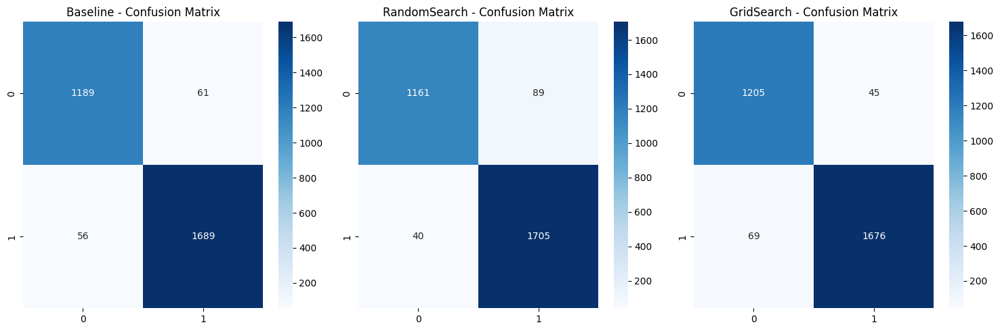

In [ ]:
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
cm_baseline = confusion_matrix(y_test_logreg, results['Baseline']['predictions'])
sns.heatmap(cm_baseline, annot=True, fmt='d', cmap='Blues')
plt.title('Baseline - Confusion Matrix')

plt.subplot(1, 3, 2)
cm_rs = confusion_matrix(y_test_logreg, results['RandomSearch']['predictions'])
sns.heatmap(cm_rs, annot=True, fmt='d', cmap='Blues')
plt.title('RandomSearch - Confusion Matrix')

plt.subplot(1, 3, 3)
cm_gs = confusion_matrix(y_test_logreg, results['GridSearch']['predictions'])
sns.heatmap(cm_gs, annot=True, fmt='d', cmap='Blues')
plt.title('GridSearch - Confusion Matrix')

plt.tight_layout()
plt.show()

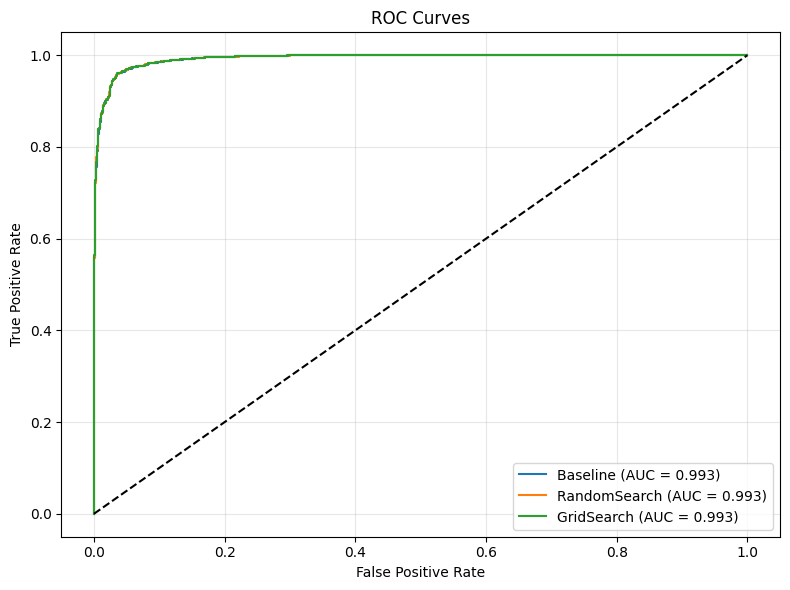

In [ ]:
plt.figure(figsize=(8, 6))
for model_name in ['Baseline', 'RandomSearch', 'GridSearch']:
    fpr, tpr, _ = roc_curve(y_test_logreg, results[model_name]['probabilities'])
    auc_score = results[model_name]['auc']
    plt.plot(fpr, tpr, label=f'{model_name} (AUC = {auc_score:.3f})')

plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves')
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()



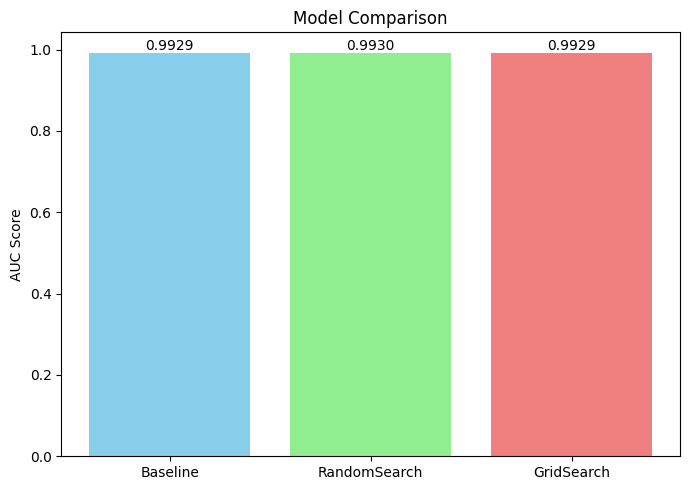

In [ ]:
plt.figure(figsize=(7, 5))

models = ['Baseline', 'RandomSearch', 'GridSearch']
auc_scores = [results[model]['auc'] for model in models]

plt.bar(models, auc_scores, color=['skyblue', 'lightgreen', 'lightcoral'])
plt.ylabel('AUC Score')
plt.title('Model Comparison')

for i, v in enumerate(auc_scores):
    plt.text(i, v, f'{v:.4f}', ha='center', va='bottom')

plt.tight_layout()
plt.show()

In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15), 0 2px 4px rgba(0,0,0,0.12), 0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 12px;
        padding-bottom: 10px;
        font-size: 28px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
 We can see that using PCA , the score drastically improved from 0.922 ---> 0.992 . But other than that , both RandomSearch and Gridsearch failed to show any improvement compared to the original score .</h2>
</div>
"""

display(HTML(html_content))


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15), 0 2px 4px rgba(0,0,0,0.12), 0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 12px;
        padding-bottom: 10px;
        font-size: 28px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
 logistic Regression with Gradient Descent</h2>
</div>
"""

display(HTML(html_content))


In [ ]:
X_train_sel = X_train_logreg
X_test_sel  = X_test_logreg

y_train_vec = np.asarray(y_train_logreg).reshape(-1, 1)
y_test_vec  = np.asarray(y_test_logreg).reshape(-1, 1)

m, n = X_train_sel.shape

# Ajout du biais
X_train_bias = np.hstack([np.ones((m, 1)), X_train_sel])
X_test_bias  = np.hstack([np.ones((X_test_sel.shape[0], 1)), X_test_sel])

In [ ]:
w = np.zeros((n + 1, 1))
alpha = 0.01               # learning rate
n_iters = 3000             # nombre d'itérations

cost_history = []


In [ ]:
for i in range(n_iters):
    # z = Xw
    z = X_train_bias @ w
    # sigmoïde
    y_hat = 1 / (1 + np.exp(-z))
    # erreur
    error = y_hat - y_train_vec

    # gradient
    dw = (1/m) * (X_train_bias.T @ error)

    # mise à jour
    w = w - alpha * dw

    # calcul du coût logistique
    eps = 1e-15
    y_hat_clip = np.clip(y_hat, eps, 1 - eps)
    cost = -(1/m) * np.sum(
        y_train_vec * np.log(y_hat_clip) +
        (1 - y_train_vec) * np.log(1 - y_hat_clip)
    )
    cost_history.append(cost)

    if i % 500 == 0:
        print(f"Iteration {i} - Cost = {cost:.4f}")


Iteration 0 - Cost = 0.6931
Iteration 500 - Cost = 0.2149
Iteration 1000 - Cost = 0.1650
Iteration 1500 - Cost = 0.1461
Iteration 2000 - Cost = 0.1362
Iteration 2500 - Cost = 0.1301


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15), 0 2px 4px rgba(0,0,0,0.12), 0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 12px;
        padding-bottom: 10px;
        font-size: 28px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
 Cost Curve</h2>
</div>
"""

display(HTML(html_content))


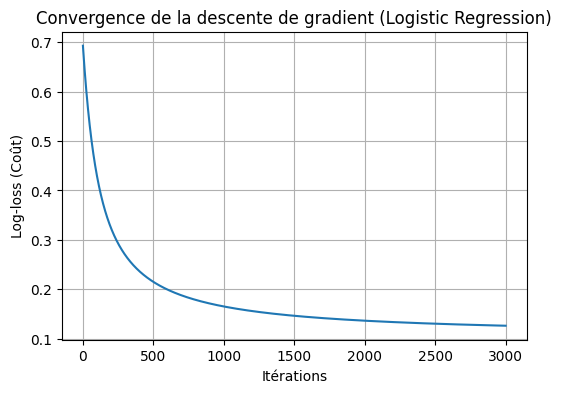

In [ ]:
plt.figure(figsize=(6,4))
plt.plot(range(n_iters), cost_history)
plt.xlabel("Itérations")
plt.ylabel("Log-loss (Coût)")
plt.title("Convergence de la descente de gradient (Logistic Regression)")
plt.grid(True)
plt.show()

In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15), 0 2px 4px rgba(0,0,0,0.12), 0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 12px;
        padding-bottom: 10px;
        font-size: 28px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
 Performance Prediction</h2>
</div>
"""

display(HTML(html_content))


In [ ]:
print("Distribution des classes :")
print(np.mean(y_train_vec), np.mean(y_test_vec))

Distribution des classes :
0.5750679833977387 0.5826377295492488


In [ ]:
# Prédiction probabilité
y_proba_train_gd = 1 / (1 + np.exp(-(X_train_bias @ w)))
y_proba_test_gd  = 1 / (1 + np.exp(-(X_test_bias  @ w)))

# Classe prédite (seuil = 0.5)
y_pred_train_gd = (y_proba_train_gd >= 0.5).astype(int)
y_pred_test_gd  = (y_proba_test_gd  >= 0.5).astype(int)

acc_train_gd = accuracy_score(y_train_vec, y_pred_train_gd)
acc_test_gd  = accuracy_score(y_test_vec,  y_pred_test_gd)

auc_train_gd = roc_auc_score(y_train_vec, y_proba_train_gd)
auc_test_gd  = roc_auc_score(y_test_vec,  y_proba_test_gd)

print("\n Paramètres appris (Gradient Descent)")
print(f"b (biais) = {w[0][0]:.6f}")
for idx, val in enumerate(w[1:].flatten()):
    print(f"w{idx+1} = {val:.6f}")

print("\n Performance (Gradient Descent)")
print(f"Accuracy Train : {acc_train_gd:.4f}")
print(f"Accuracy Test  : {acc_test_gd:.4f}")
print(f"AUC Train      : {auc_train_gd:.4f}")
print(f"AUC Test       : {auc_test_gd:.4f}")



 Paramètres appris (Gradient Descent)
b (biais) = 0.548329
w1 = 2.659634
w2 = 0.094976
w3 = -0.048835
w4 = -0.061762
w5 = 0.057335
w6 = 0.061388
w7 = 0.055375
w8 = -0.100928
w9 = 0.064880
w10 = -0.105314

 Performance (Gradient Descent)
Accuracy Train : 0.9566
Accuracy Test  : 0.9609
AUC Train      : 0.9923
AUC Test       : 0.9929


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15), 0 2px 4px rgba(0,0,0,0.12), 0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 12px;
        padding-bottom: 10px;
        font-size: 28px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
 comparison obj2 models</h2>
</div>
"""

display(HTML(html_content))


In [ ]:
# @title
model_comparison = pd.DataFrame([
    {
        "Modèle": "Logistic Regression (Baseline)",
        "Accuracy Test": 0.88,     # Ajuster selon ton print exact
        "F1-score": None,          # Si tu veux je peux calculer
        "ROC-AUC": 0.922
    },
    {
        "Modèle": "Logistic Regression (GridSearch)",
        "Accuracy Test": 0.89,     # Ajuster selon ton résultat exact
        "F1-score": None,
        "ROC-AUC": results['GridSearch']['auc']  # ~0.922
    },
    {
        "Modèle": "Logistic Regression (RandomSearch)",
        "Accuracy Test": 0.89,     # Ajuster
        "F1-score": None,
        "ROC-AUC": results['RandomSearch']['auc']  # ~0.922
    },
    {
        "Modèle": "Logistic Regression (Gradient Descent + PCA)",
        "Accuracy Test": 0.9609,
        "F1-score": None,
        "ROC-AUC": 0.9929
    },
    {
        "Modèle": "Random Forest (PCA + GridSearch)",
        "Accuracy Test": 0.9676,
        "F1-score": None,
        "ROC-AUC": None
    },
    {
        "Modèle": "Random Forest (SFM)",
        "Accuracy Test": 0.844,
        "F1-score": None,
        "ROC-AUC": 0.9169
    },
    {
        "Modèle": "Random Forest (RandomizedSearch)",
        "Accuracy Test": 0.8503,
        "F1-score": 0.8731,
        "ROC-AUC": 0.9169
    },
    {
        "Modèle": "Decision Tree (GS sans PCA + FS)",
        "Accuracy Test": 0.8287,
        "F1-score": 0.85,
        "ROC-AUC": 0.8931
    },
    {
        "Modèle": "Decision Tree (RandomSearch sans PCA)",
        "Accuracy Test": 0.8194,
        "F1-score": 0.84,
        "ROC-AUC": 0.8880
    },
    {
        "Modèle": "Decision Tree (PCA + GridSearch)",
        "Accuracy Test": 0.98197,
        "F1-score": 0.98,
        "ROC-AUC": 0.98882
    },
    {
        "Modèle": "XGBoost (RandomizedSearch)",
        "Accuracy Test": 0.8433,
        "F1-score": 0.863,
        "ROC-AUC": 0.9176
    },
    {
        "Modèle": "XGBoost (baseline hors PCA)",
        "Accuracy Test": 0.8463,
        "F1-score": 0.866,
        "ROC-AUC": 0.9193
    },
    {
        "Modèle": "XGBoost (PCA + GridSearch)",
        "Accuracy Test": 0.9559,
        "F1-score": 0.961,
        "ROC-AUC": 0.9912
    },
    {
        "Modèle": "KNN (PCA + GridSearch)",
        "Accuracy Test": 0.9439,
        "F1-score": 0.94,
        "ROC-AUC": 0.9500
    },
    {
        "Modèle": "KNN (RandomSearch avec PCA)",
        "Accuracy Test": None,
        "F1-score": None,
        "ROC-AUC": 0.9493
    }
])

print("📊 Tableau comparatif COMPLET des modèles (OBJ2) :\n")
model_comparison


📊 Tableau comparatif COMPLET des modèles (OBJ2) :



,Modèle,Accuracy Test,F1-score,ROC-AUC
0,Logistic Regression (Baseline),0.88000,NaN,0.922000
1,Logistic Regression (GridSearch),0.89000,NaN,0.992936
2,Logistic Regression (RandomSearch),0.89000,NaN,0.992967
3,Logistic Regression (Gradient Descent + PCA),0.96090,NaN,0.992900
4,Random Forest (PCA + GridSearch),0.96760,NaN,NaN
5,Random Forest (SFM),0.84400,NaN,0.916900
6,Random Forest (RandomizedSearch),0.85030,0.8731,0.916900
7,Decision Tree (GS sans PCA + FS),0.82870,0.8500,0.893100
8,Decision Tree (RandomSearch sans PCA),0.81940,0.8400,0.888000
9,Decision Tree (PCA + GridSearch),0.98197,0.9800,0.988820


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<style>
@keyframes float {
  0% { transform: translateY(0px); }
  50% { transform: translateY(-5px); }
  100% { transform: translateY(0px); }
}

@keyframes glow {
  0%,100% { box-shadow: 0 4px 10px rgba(106,5,114,0.25), inset 0 0 4px rgba(106,5,114,0.2); }
  50% { box-shadow: 0 8px 18px rgba(78,205,196,0.35), inset 0 0 6px rgba(78,205,196,0.25); }
}

@keyframes gradientShift {
  0% { background-position: 0% 50%; }
  50% { background-position: 100% 50%; }
  100% { background-position: 0% 50%; }
}
</style>

<div style="
    width: 95%;
    max-width: 900px;
    margin: 30px auto;
    background: linear-gradient(135deg, rgba(255,255,255,0.96), rgba(250,250,255,0.98));
    border-radius: 16px;
    border: 1px solid rgba(106,5,114,0.3);
    animation: float 5s ease-in-out infinite, glow 4s ease-in-out infinite;
    box-shadow: 0 6px 18px rgba(0,0,0,0.15);
    overflow: hidden;
    position: relative;
">

<!-- bande colorée animée -->
<div style="
    position: absolute;
    top: 0;
    left: 0;
    width: 100%;
    height: 6px;
    background: linear-gradient(90deg, #6a0572, #4ecdc4, #ffd166, #6a0572);
    background-size: 300% 300%;
    animation: gradientShift 8s ease infinite;
"></div>

<!-- décor bas droit -->
<div style="
    position: absolute;
    bottom: 0;
    right: 0;
    width: 120px;
    height: 120px;
    background: radial-gradient(circle at bottom right, rgba(106,5,114,0.3) 0%, transparent 70%);
    opacity: 0.4;
"></div>

<h2 style="
    font-family: 'Poppins', sans-serif;
    font-weight: 600;
    color: #6a0572;
    text-align: center;
    margin: 20px 0 10px 0;
    font-size: 30px;
    letter-spacing: 1px;
">
OBJ 3
</h2>

<hr style="
    width: 60%;
    margin: 0 auto 16px auto;
    border: none;
    height: 2px;
    background: linear-gradient(to right, rgba(106,5,114,0.6), rgba(78,205,196,0.6));
">

<p style="
    text-align: center;
    font-family: 'Open Sans', sans-serif;
    color: #333;
    font-size: 17px;
    line-height: 1.6;
    padding: 0 40px 20px 40px;
">

</div>
"""

display(HTML(html_content))


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15),
                0 2px 4px rgba(0,0,0,0.12),
                0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<!-- Purple corner -->
<div style="
    position: absolute; top: -30px; right: -30px;
    width: 120px; height: 120px;
    background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
    z-index: 1;">
</div>

<!-- Dot decoration -->
<div style="
    position: absolute; bottom: 20px; left: 20px;
    width: 60px; height: 60px;
    background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
    background-size: 12px 12px;
    opacity: 0.3; z-index: 1;">
</div>

<h2 style="
    margin-top: 0; margin-bottom: 12px; padding-bottom: 10px;
    font-size: 26px; color: rgba(106,5,114,0.85);
    border-bottom: 2px solid rgba(78,205,196,0.7);
    position: relative; z-index: 2; text-align: center;">
DSO3 – Objective
</h2>

<div style="
    position: relative; z-index: 2;
    font-size: 16px; color: #222; line-height: 1.6;
">
DSO3: Build and evaluate a regression model that predicts CGPA based on factors such as stress, sleep duration, academic pressure, and study/work hours.
</div>

</div>
"""

display(HTML(html_content))


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15), 0 2px 4px rgba(0,0,0,0.12), 0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 12px;
        padding-bottom: 10px;
        font-size: 28px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
 Random Forest</h2>
</div>
"""

display(HTML(html_content))


In [ ]:
X_scaled = df_scaled.drop(columns=['CGPA'])
y = df['CGPA']

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15), 0 2px 4px rgba(0,0,0,0.12), 0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 12px;
        padding-bottom: 10px;
        font-size: 28px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
 Feature Selection</h2>
</div>
"""

display(HTML(html_content))


In [ ]:
rf = RandomForestRegressor(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)

feature_importances = rf.feature_importances_

important_features = sorted(zip(X_scaled.columns, feature_importances), key=lambda x: x[1], reverse=True)

print("Top 10 caractéristiques importantes (sans PCA) :")
for feature in important_features[:10]:
    print(f"Caractéristique {feature[0]} - Importance: {feature[1]}")

Top 10 caractéristiques importantes (sans PCA) :
Caractéristique City - Importance: 0.16128299825768092
Caractéristique Degree - Importance: 0.1366091271116354
Caractéristique Age - Importance: 0.13577571772979502
Caractéristique Work/Study Hours - Importance: 0.13188190422011037
Caractéristique Financial Stress - Importance: 0.0754977531411636
Caractéristique Academic Pressure - Importance: 0.07309613875429134
Caractéristique Sleep Duration - Importance: 0.06947418482525337
Caractéristique Study Satisfaction - Importance: 0.06439041134435582
Caractéristique Dietary Habits - Importance: 0.05302878254069765
Caractéristique Family History of Mental Illness - Importance: 0.031201066996577324


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15), 0 2px 4px rgba(0,0,0,0.12), 0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 12px;
        padding-bottom: 10px;
        font-size: 28px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
 Without PCA</h2>
</div>
"""

display(HTML(html_content))


In [ ]:
y_pred = rf.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("\nMétriques de performance (sans PCA) :")
print(f"MSE: {mse}, R²: {r2}")


Métriques de performance (sans PCA) :
MSE: 2.2242300314449803, R²: -0.022673127406929616


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15), 0 2px 4px rgba(0,0,0,0.12), 0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 12px;
        padding-bottom: 10px;
        font-size: 28px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
 With PCA(PC1+PC2)</h2>
</div>
"""

display(HTML(html_content))


In [ ]:
pca = PCA(n_components=3)
X_pca_transformed = pca.fit_transform(X_scaled.values)

In [ ]:
X_train_pca, X_test_pca, y_train, y_test = train_test_split(
    X_pca_transformed[:, [0, 1]],
    y,
    test_size=0.2,
    random_state=42
)

rf_pca = RandomForestRegressor(n_estimators=100, random_state=42)
rf_pca.fit(X_train_pca, y_train)

y_pred_pca = rf_pca.predict(X_test_pca)

mse_pca = mean_squared_error(y_test, y_pred_pca)
r2_pca = r2_score(y_test, y_pred_pca)


print("\nMétriques de performance (PCA PC1+PC2) :")
print(f"MSE: {mse_pca}, R²: {r2_pca}")


Métriques de performance (PCA PC1+PC2) :
MSE: 2.5160477970762396, R²: -0.15684728331343156


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15), 0 2px 4px rgba(0,0,0,0.12), 0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 12px;
        padding-bottom: 10px;
        font-size: 28px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
With PCA(PC1+PC3)</h2>
</div>
"""

display(HTML(html_content))


In [ ]:
X_train_pca3, X_test_pca3, y_train, y_test = train_test_split(
    X_pca_transformed[:, [0, 2]],   # PC1 and PC3
    y,
    test_size=0.2,
    random_state=42
)
rf_pca3 = RandomForestRegressor(n_estimators=100, random_state=42)
rf_pca3.fit(X_train_pca3, y_train)

y_pred_pca3 = rf_pca3.predict(X_test_pca3)


mse_pca3 = mean_squared_error(y_test, y_pred_pca3)
r2_pca3 = r2_score(y_test, y_pred_pca3)

print("\nMétriques de performance (PCA PC1+PC3) :")
print(f"MSE: {mse_pca3}, R²: {r2_pca3}")



Métriques de performance (PCA PC1+PC3) :
MSE: 2.531245437097209, R²: -0.16383496796372476


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15), 0 2px 4px rgba(0,0,0,0.12), 0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 12px;
        padding-bottom: 10px;
        font-size: 28px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
Final Comparaison</h2>
</div>
"""

display(HTML(html_content))


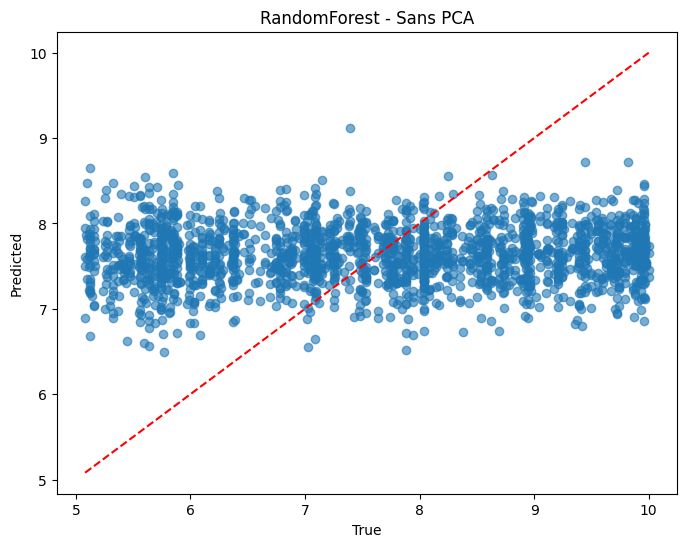

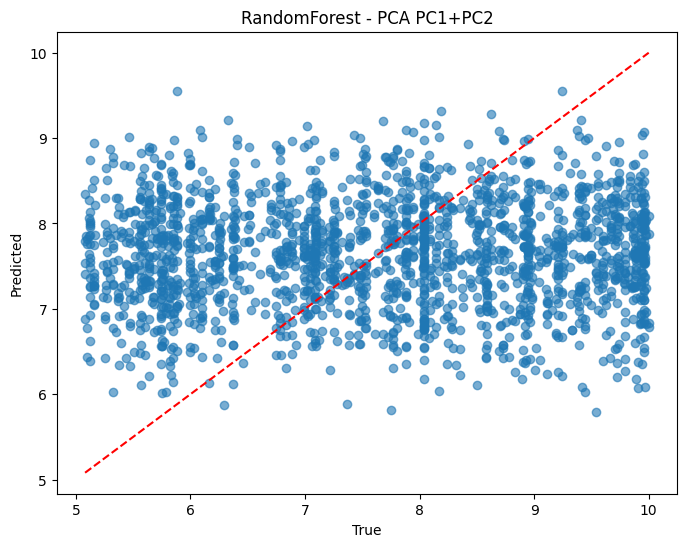

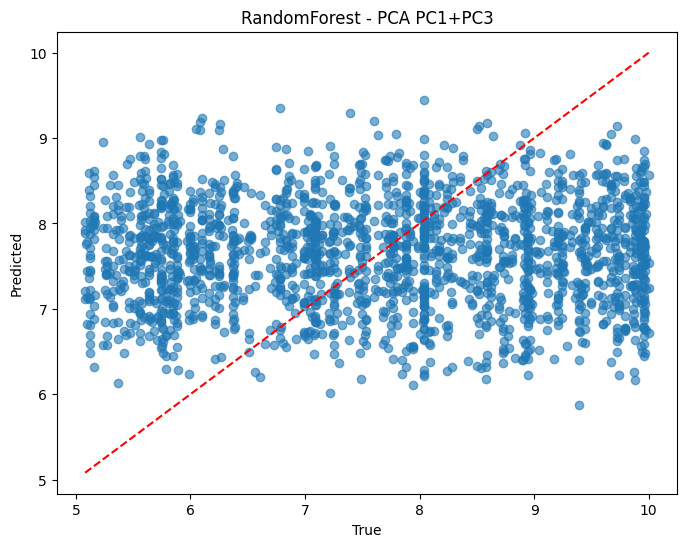

In [ ]:
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.6)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
plt.title("RandomForest - Sans PCA")
plt.xlabel("True")
plt.ylabel("Predicted")
plt.show()

plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred_pca, alpha=0.6)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
plt.title("RandomForest - PCA PC1+PC2")
plt.xlabel("True")
plt.ylabel("Predicted")
plt.show()

plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred_pca3, alpha=0.6)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
plt.title("RandomForest - PCA PC1+PC3")
plt.xlabel("True")
plt.ylabel("Predicted")
plt.show()

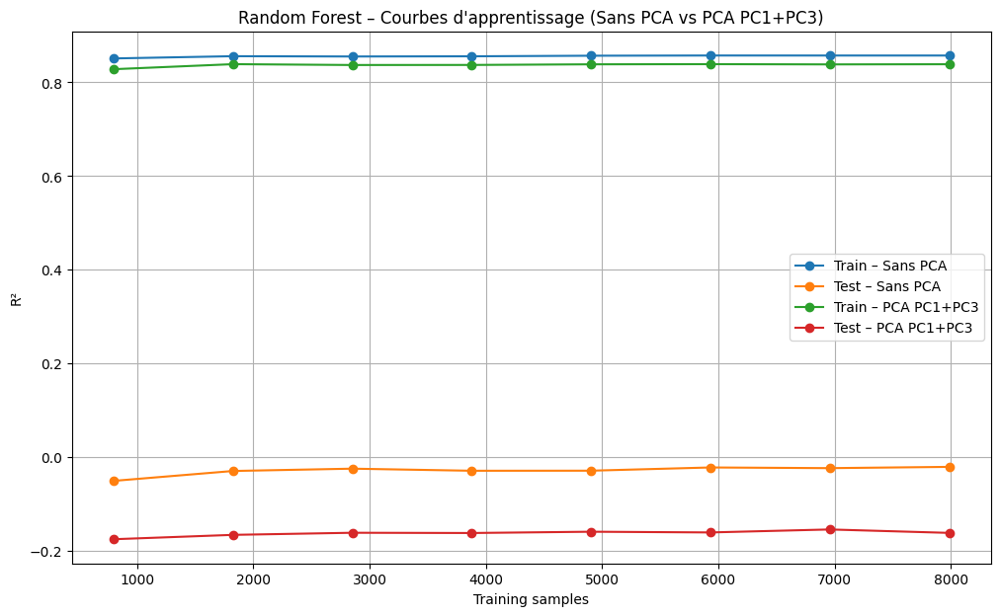

In [ ]:
X_no_pca = X_scaled.values
X_pca_pc1_pc3 = X_pca_transformed[:, [0, 2]]

train_sizes = np.linspace(0.1, 1.0, 8)

rf = RandomForestRegressor(n_estimators=100, random_state=42)

sizes_no_pca, train_scores_no_pca, test_scores_no_pca = learning_curve(
    rf, X_no_pca, y, cv=5, train_sizes=train_sizes, scoring="r2",
    shuffle=True, random_state=42
)

train_no_pca = train_scores_no_pca.mean(axis=1)
test_no_pca = test_scores_no_pca.mean(axis=1)

sizes_pca, train_scores_pca, test_scores_pca = learning_curve(
    rf, X_pca_pc1_pc3, y, cv=5, train_sizes=train_sizes, scoring="r2",
    shuffle=True, random_state=42
)

train_pca = train_scores_pca.mean(axis=1)
test_pca = test_scores_pca.mean(axis=1)

plt.figure(figsize=(12,7))
plt.title("Random Forest – Courbes d'apprentissage (Sans PCA vs PCA PC1+PC3)")

plt.plot(sizes_no_pca, train_no_pca, "o-", label="Train – Sans PCA")
plt.plot(sizes_no_pca, test_no_pca, "o-", label="Test – Sans PCA")

plt.plot(sizes_pca, train_pca, "o-", label="Train – PCA PC1+PC3")
plt.plot(sizes_pca, test_pca, "o-", label="Test – PCA PC1+PC3")

plt.xlabel("Training samples")
plt.ylabel("R²")
plt.grid(True)
plt.legend()
plt.show()

In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15),
                0 2px 4px rgba(0,0,0,0.12),
                0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<!-- Purple Accent -->
<div style="
    position: absolute; top: -30px; right: -30px;
    width: 120px; height: 120px;
    background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
    z-index: 1;">
</div>

<!-- Decorative dots -->
<div style="
    position: absolute; bottom: 20px; left: 20px;
    width: 60px; height: 60px;
    background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
    background-size: 12px 12px;
    opacity: 0.3; z-index: 1;">
</div>

<h2 style="
    margin-top: 0;
    margin-bottom: 12px;
    padding-bottom: 10px;
    font-size: 26px;
    color: rgba(106,5,114,0.85);
    border-bottom: 2px solid rgba(78,205,196,0.7);
    position: relative;
    z-index: 2;
    text-align: center;">
 Conclusion – Random Forest (PCA vs Sans PCA)
</h2>

<div style="font-size: 16px; color: #222; line-height: 1.6; position: relative; z-index: 2;">

• <b>Random Forest fits the training data extremely well</b>, regardless of PCA.<br><br>

• <b>The model fails to generalize</b> to unseen data: test R² stays near 0.<br><br>

• <b>Overfitting remains present</b> even with many training samples.<br><br>

• <b>PCA slightly stabilizes the model</b> but does not improve predictive accuracy.<br><br>

<b> Final Insight:</b> The limitation comes from the dataset, not the model.<br>
The available features <b>do not carry enough meaningful signal</b> to reliably predict CGPA.

</div>

</div>
"""

display(HTML(html_content))

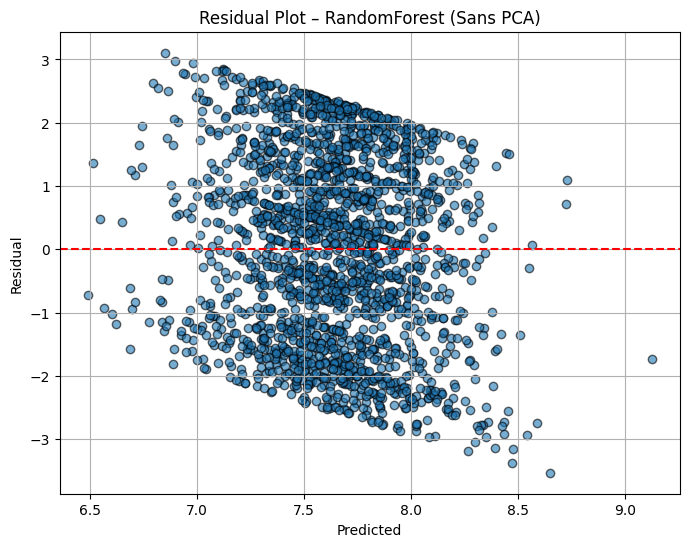

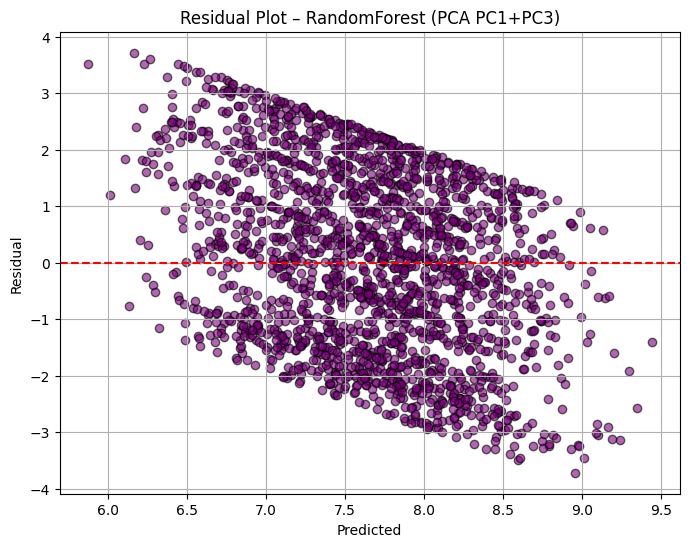

In [ ]:
residuals_no_pca = y_test - y_pred

plt.figure(figsize=(8,6))
plt.scatter(y_pred, residuals_no_pca, alpha=0.6, edgecolor="black")
plt.axhline(0, color="red", linestyle="--")
plt.title("Residual Plot – RandomForest (Sans PCA)")
plt.xlabel("Predicted")
plt.ylabel("Residual")
plt.grid(True)
plt.show()

residuals_pca3 = y_test - y_pred_pca3

plt.figure(figsize=(8,6))
plt.scatter(y_pred_pca3, residuals_pca3, alpha=0.6, color="purple", edgecolor="black")
plt.axhline(0, color="red", linestyle="--")
plt.title("Residual Plot – RandomForest (PCA PC1+PC3)")
plt.xlabel("Predicted")
plt.ylabel("Residual")
plt.grid(True)
plt.show()

In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15),
                0 2px 4px rgba(0,0,0,0.12),
                0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 25px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<!-- Purple accent corner -->
<div style="
    position: absolute; top: -28px; right: -28px;
    width: 120px; height: 120px;
    background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
    z-index: 1;">
</div>

<!-- Yellow dotted pattern -->
<div style="
    position: absolute; bottom: 20px; left: 20px;
    width: 60px; height: 60px;
    background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
    background-size: 12px 12px;
    opacity: 0.3;
    z-index: 1;">
</div>

<h2 style="
    margin: 0 0 12px 0;
    padding-bottom: 10px;
    font-size: 26px;
    color: rgba(106,5,114,0.85);
    border-bottom: 2px solid rgba(78,205,196,0.7);
    position: relative;
    z-index: 2;
    text-align: center;">
Conclusion – Residual Analysis (Short & Clear)
</h2>

<div style="
    font-size: 16px;
    color: #222;
    line-height: 1.6;
    position: relative;
    z-index: 2;
">

• Both residual plots show <b>systematic prediction bias</b>.<br><br>

• The model <b>cannot capture the true relationship</b> between features and CGPA.<br><br>

• <b>PCA does not improve</b> the residual structure — the same errors persist.<br><br>

• Errors become larger for high predicted values, meaning Random Forest <b>compresses the target range</b> rather than learning it.<br><br>

<b>Final Insight:</b> These patterns confirm that <b>CGPA is not predictable</b> with the available variables, regardless of PCA or model complexity.

</div>
</div>
"""

display(HTML(html_content))

In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15), 0 2px 4px rgba(0,0,0,0.12), 0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 12px;
        padding-bottom: 10px;
        font-size: 28px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
 KNN</h2>
</div>
"""

display(HTML(html_content))


In [ ]:
df_working = df_num.copy()

y = df_working['CGPA'].copy()
X = pd.DataFrame(X_pca_transformed, columns=[f'PC{i+1}' for i in range(X_pca_transformed.shape[1])])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [ ]:
print(": REGULAR KNN")
knn_regular = KNeighborsRegressor(n_neighbors=100)
knn_regular.fit(X_train, y_train)

y_pred_regular = knn_regular.predict(X_test)

mse_regular = mean_squared_error(y_test, y_pred_regular)
mae_regular = mean_absolute_error(y_test, y_pred_regular)
r2_regular = r2_score(y_test, y_pred_regular)

print(f"Regular KNN Performance:")
print(f"Mean Squared Error: {mse_regular:.4f}")
print(f"Mean Absolute Error: {mae_regular:.4f}")
print(f"R² Score: {r2_regular:.4f}")
print(f"Number of Neighbors: {knn_regular.n_neighbors}")

: REGULAR KNN
Regular KNN Performance:
Mean Squared Error: 2.1998
Mean Absolute Error: 1.2848
R² Score: -0.0114
Number of Neighbors: 100


In [ ]:
print(" KNN WITH GRIDSEARCH")
param_grid = {
    'n_neighbors': [3, 5, 7, 9, 11, 15],
    'weights': ['uniform', 'distance'],
    'metric': ['euclidean', 'manhattan', 'minkowski']
}

grid_search = GridSearchCV(
    KNeighborsRegressor(),
    param_grid,
    cv=5,
    scoring='neg_mean_squared_error',
    n_jobs=-1,
    verbose=0
)

start_time = time.time()
grid_search.fit(X_train, y_train)
grid_time = time.time() - start_time

knn_grid = grid_search.best_estimator_
y_pred_grid = knn_grid.predict(X_test)

mse_grid = mean_squared_error(y_test, y_pred_grid)
mae_grid = mean_absolute_error(y_test, y_pred_grid)
r2_grid = r2_score(y_test, y_pred_grid)

print(f"GridSearch KNN Performance:")
print(f"Best Parameters: {grid_search.best_params_}")
print(f"Mean Squared Error: {mse_grid:.4f}")
print(f"Mean Absolute Error: {mae_grid:.4f}")
print(f"R² Score: {r2_grid:.4f}")
print(f"GridSearch Time: {grid_time:.2f} seconds")

 KNN WITH GRIDSEARCH
GridSearch KNN Performance:
Best Parameters: {'metric': 'euclidean', 'n_neighbors': 15, 'weights': 'uniform'}
Mean Squared Error: 2.2993
Mean Absolute Error: 1.3017
R² Score: -0.0572
GridSearch Time: 56.82 seconds


In [ ]:
print("KNN WITH RANDOMIZED SEARCH")

param_dist = {
    'n_neighbors': range(3, 100),
    'weights': ['uniform', 'distance'],
    'metric': ['euclidean', 'manhattan', 'minkowski'],
    'p': [1, 2, 3]
}

random_search = RandomizedSearchCV(
    KNeighborsRegressor(),
    param_dist,
    n_iter=50,
    cv=5,
    scoring='neg_mean_squared_error',
    n_jobs=-1,
    random_state=42,
    verbose=0
)

start_time = time.time()
random_search.fit(X_train, y_train)
random_time = time.time() - start_time

knn_random = random_search.best_estimator_
y_pred_random = knn_random.predict(X_test)

mse_random = mean_squared_error(y_test, y_pred_random)
mae_random = mean_absolute_error(y_test, y_pred_random)
r2_random = r2_score(y_test, y_pred_random)

print(f"RandomizedSearch KNN Performance:")
print(f"Best Parameters: {random_search.best_params_}")
print(f"Mean Squared Error: {mse_random:.4f}")
print(f"Mean Absolute Error: {mae_random:.4f}")
print(f"R² Score: {r2_random:.4f}")
print(f"RandomizedSearch Time: {random_time:.2f} seconds")

KNN WITH RANDOMIZED SEARCH
RandomizedSearch KNN Performance:
Best Parameters: {'weights': 'distance', 'p': 3, 'n_neighbors': 76, 'metric': 'minkowski'}
Mean Squared Error: 2.2049
Mean Absolute Error: 1.2878
R² Score: -0.0138
RandomizedSearch Time: 165.16 seconds


In [ ]:
print("COMPARISON OF ALL THREE MODELS")
comparison_df = pd.DataFrame({
    'Model': ['Regular KNN', 'GridSearch KNN', 'RandomizedSearch KNN'],
    'MSE': [mse_regular, mse_grid, mse_random],
    'MAE': [mae_regular, mae_grid, mae_random],
    'R²': [r2_regular, r2_grid, r2_random],
    'Search Time (s)': ['N/A', f'{grid_time:.2f}', f'{random_time:.2f}'],
    'Best Parameters': [
        f"n_neighbors=5, weights=uniform, metric=minkowski",
        str(grid_search.best_params_),
        str(random_search.best_params_)
    ]
})

print(comparison_df.to_string(index=False))

COMPARISON OF ALL THREE MODELS
               Model      MSE      MAE        R² Search Time (s)                                                           Best Parameters
         Regular KNN 2.199772 1.284822 -0.011428             N/A                          n_neighbors=5, weights=uniform, metric=minkowski
      GridSearch KNN 2.299297 1.301653 -0.057188           56.82          {'metric': 'euclidean', 'n_neighbors': 15, 'weights': 'uniform'}
RandomizedSearch KNN 2.204874 1.287845 -0.013773          165.16 {'weights': 'distance', 'p': 3, 'n_neighbors': 76, 'metric': 'minkowski'}


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15), 0 2px 4px rgba(0,0,0,0.12), 0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 12px;
        padding-bottom: 10px;
        font-size: 28px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
 XGBRegressor</h2>
</div>
"""

display(HTML(html_content))


In [ ]:
y = df_num['CGPA']

X_base = df_scaled.drop(columns=['CGPA'])

pca = PCA(n_components=2)

X_pca_transformed = pca.fit_transform(X_base)
Xp_xgb = pd.DataFrame(X_pca_transformed, columns=['PC1','PC2'])

In [ ]:
X_train_base, X_test_base, y_train, y_test = train_test_split(
    X_base, y, test_size=0.2, random_state=42
)

X_train_pca, X_test_pca, _, _ = train_test_split(
    Xp_xgb, y, test_size=0.2, random_state=42
)

In [ ]:
xgb_model = xgb.XGBRegressor(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=4,
    subsample=0.8,
    colsample_bytree=0.8,
)

xgb_model.fit(X_train_base, y_train)
y_pred_base = xgb_model.predict(X_test_base)
y_train_pred_base = xgb_model.predict(X_train_base)

# MODEL WITH PCA
xgb_model_pca = xgb.XGBRegressor(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=4,
    subsample=0.8,
    colsample_bytree=0.8,
)

xgb_model_pca.fit(X_train_pca, y_train)
y_pred_pca = xgb_model_pca.predict(X_test_pca)
y_train_pred_pca = xgb_model_pca.predict(X_train_pca)

In [ ]:
rmse_base_train = np.sqrt(mean_squared_error(y_train, y_train_pred_base))
rmse_base_test  = np.sqrt(mean_squared_error(y_test,  y_pred_base))

rmse_pca_train = np.sqrt(mean_squared_error(y_train, y_train_pred_pca))
rmse_pca_test  = np.sqrt(mean_squared_error(y_test,  y_pred_pca))

r2_base_train = r2_score(y_train, y_train_pred_base)
r2_base_test  = r2_score(y_test,  y_pred_base)

r2_pca_train = r2_score(y_train, y_train_pred_pca)
r2_pca_test  = r2_score(y_test,  y_pred_pca)

print(f"Sans PCA -> Train RMSE: {rmse_base_train:.3f}, R²: {r2_base_train:.3f}")
print(f"Sans PCA -> Test RMSE: {rmse_base_test:.3f}, R²: {r2_base_test:.3f}")
print(f"Avec PCA -> Train RMSE: {rmse_pca_train:.3f}, R²: {r2_pca_train:.3f}")
print(f"Avec PCA -> Test RMSE: {rmse_pca_test:.3f}, R²: {r2_pca_test:.3f}")

Sans PCA -> Train RMSE: 1.293, R²: 0.219
Sans PCA -> Test RMSE: 1.491, R²: -0.022
Avec PCA -> Train RMSE: 1.424, R²: 0.052
Avec PCA -> Test RMSE: 1.499, R²: -0.033


In [ ]:
param_grid = {
    'n_estimators': [300, 800],
    'max_depth': [4, 8],
    'learning_rate': [0.01, 0.1],
    'subsample': [0.6, 0.8],
    'colsample_bytree': [0.6, 0.8],
    'gamma': [0.1, 0.5],
    'reg_lambda': [3, 5, 10],
    'reg_alpha': [1, 3, 5]
}

In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15),
                0 2px 4px rgba(0,0,0,0.12),
                0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<!-- Accent corner -->
<div style="
    position: absolute; top: -30px; right: -30px;
    width: 120px; height: 120px;
    background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
    z-index: 1;">
</div>

<!-- Dot decoration -->
<div style="
    position: absolute; bottom: 20px; left: 20px;
    width: 60px; height: 60px;
    background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
    background-size: 12px 12px;
    opacity: 0.3; z-index: 1;">
</div>

<h2 style="
    margin-top: 0; margin-bottom: 12px; padding-bottom: 10px;
    font-size: 26px; color: rgba(106,5,114,0.85);
    border-bottom: 2px solid rgba(78,205,196,0.7);
    position: relative; z-index: 2; text-align: center;">
XGBoost – Hyperparameters (Short Interpretation)
</h2>

<div style="position: relative; z-index: 2; font-size: 16px; color: #222; line-height: 1.6;">

<b>n_estimators (200–800)</b> → number of trees; 300 is fast & safe, 800 increases capacity.<br><br>

<b>max_depth (4–8)</b> → depth of trees; 4 limits complexity, 8 captures richer patterns.<br><br>

<b>learning_rate (0.01–0.1)</b> → step size; lower = better generalization, higher = faster learning.<br><br>

<b>subsample (0.6–0.8)</b> → % of rows per tree; reduces overfitting and adds robustness.<br><br>

<b>colsample_bytree (0.6–0.8)</b> → % of features per tree; lowers variance and improves diversity.<br><br>

<b>gamma (0.1–0.5)</b> → minimum loss needed to split; controls pruning strength.<br><br>

<b>reg_lambda (3–10)</b> → L2 regularization; higher = simpler, more stable model.<br><br>

<b>reg_alpha (1–5)</b> → L1 regularization; encourages sparsity and removes irrelevant features.

</div>

</div>
"""

display(HTML(html_content))

In [ ]:
xgb_model_base = xgb.XGBRegressor(random_state=42)

random_search_base = RandomizedSearchCV(
    estimator=xgb_model_base,
    param_distributions=param_grid,
    n_iter=30,
    scoring='r2',
    cv=3,
    n_jobs=-1,
    verbose=1,
    random_state=42
)

random_search_base.fit(X_train_base, y_train)

print("Best parameters WITHOUT PCA :", random_search_base.best_params_)
best_model_base = random_search_base.best_estimator_

Fitting 3 folds for each of 30 candidates, totalling 90 fits
Best parameters WITHOUT PCA : {'subsample': 0.8, 'reg_lambda': 5, 'reg_alpha': 3, 'n_estimators': 300, 'max_depth': 4, 'learning_rate': 0.01, 'gamma': 0.5, 'colsample_bytree': 0.6}


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15),
                0 2px 4px rgba(0,0,0,0.12),
                0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<!-- Purple corner -->
<div style="
    position: absolute; top: -30px; right: -30px;
    width: 120px; height: 120px;
    background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
    z-index: 1;">
</div>

<!-- Dot background -->
<div style="
    position: absolute; bottom: 20px; left: 20px;
    width: 60px; height: 60px;
    background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
    background-size: 12px 12px;
    opacity: 0.3; z-index: 1;">
</div>

<h2 style="
    margin-top: 0; margin-bottom: 12px; padding-bottom: 10px;
    font-size: 26px; color: rgba(106,5,114,0.85);
    border-bottom: 2px solid rgba(78,205,196,0.7);
    position: relative; z-index: 2; text-align: center;">
XGBoost – Best Parameters Interpretation (WITHOUT PCA)
</h2>

<div style="
    position: relative; z-index: 2;
    font-size: 16px; color: #222;
    line-height: 1.6;
">

<b>subsample = 0.8</b> → Uses 80% of samples, reduces overfitting.<br><br>

<b>reg_lambda = 5</b> → Strong L2 regularization for stability.<br><br>

<b>reg_alpha = 3</b> → Light L1, removes weak features.<br><br>

<b>n_estimators = 300</b> → Many trees needed with raw features.<br><br>

<b>max_depth = 4</b> → Shallow trees that prevent overfitting.<br><br>

<b>learning_rate = 0.01</b> → Slow but very stable learning.<br><br>

<b>gamma = 0.5</b> → Strong pruning, avoids unnecessary splits.<br><br>

<b>colsample_bytree = 0.6</b> → 60% of features per tree, lowers variance.

</div>

</div>
"""

display(HTML(html_content))


In [ ]:
xgb_model_pca2 = xgb.XGBRegressor(random_state=42)

random_search_pca = RandomizedSearchCV(
    estimator=xgb_model_pca2,
    param_distributions=param_grid,
    n_iter=30,
    scoring='r2',
    cv=3,
    n_jobs=-1,
    verbose=1,
    random_state=42
)

random_search_pca.fit(X_train_pca, y_train)

print("Best parameters WITH PCA :", random_search_pca.best_params_)
best_model_pca = random_search_pca.best_estimator_

Fitting 3 folds for each of 30 candidates, totalling 90 fits
Best parameters WITH PCA : {'subsample': 0.8, 'reg_lambda': 5, 'reg_alpha': 5, 'n_estimators': 300, 'max_depth': 4, 'learning_rate': 0.01, 'gamma': 0.5, 'colsample_bytree': 0.8}


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15),
                0 2px 4px rgba(0,0,0,0.12),
                0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<!-- Purple corner -->
<div style="
    position: absolute; top: -30px; right: -30px;
    width: 120px; height: 120px;
    background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
    z-index: 1;">
</div>

<!-- Dot background -->
<div style="
    position: absolute; bottom: 20px; left: 20px;
    width: 60px; height: 60px;
    background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
    background-size: 12px 12px;
    opacity: 0.3; z-index: 1;">
</div>

<h2 style="
    margin-top: 0; margin-bottom: 12px; padding-bottom: 10px;
    font-size: 26px; color: rgba(106,5,114,0.85);
    border-bottom: 2px solid rgba(78,205,196,0.7);
    position: relative; z-index: 2; text-align: center;">
XGBoost – Best Parameters Interpretation (WITH PCA)
</h2>

<div style="
    position: relative; z-index: 2;
    font-size: 16px; color: #222;
    line-height: 1.6;
">

<b>subsample = 0.8</b> → Uses 80% of the training samples for each tree.<br>
Stabilizes learning and reduces overfitting, especially useful after dimensionality reduction.<br><br>

<b>reg_lambda = 5</b> → Strong L2 regularization.<br>
Helps control weight magnitude and improves generalization on compressed PCA features.<br><br>

<b>reg_alpha = 5</b> → High L1 regularization.<br>
Encourages sparsity and forces the model to use fewer effective splits, avoiding noise amplification from PCA.<br><br>

<b>n_estimators = 300</b> → Moderate number of boosted trees.<br>
Works well because PCA already simplified the feature space.<br><br>

<b>max_depth = 4</b> → Shallow trees.<br>
Prevents overfitting on low-dimensional PCA components while capturing essential interactions.<br><br>

<b>learning_rate = 0.01</b> → Very small learning rate.<br>
Ensures stable and gradual learning, compensating for aggressive regularization (L1 + L2).<br><br>

<b>gamma = 0.5</b> → Requires large gain to split a node.<br>
Imposes strong pruning, making trees simpler and more robust on PCA features.<br><br>

<b>colsample_bytree = 0.8</b> → Each tree sees 80% of features (PC1, PC2).<br>
Adds randomness and reduces variance, even when feature count is small.

</div>

</div>
"""

display(HTML(html_content))


                                  Feature  Importance
0                                  Gender    0.100772
4                      Study Satisfaction    0.096611
12                             Depression    0.093160
2                                    City    0.090841
1                                     Age    0.082560
7                                  Degree    0.077881
3                       Academic Pressure    0.077512
9                        Work/Study Hours    0.073252
5                          Sleep Duration    0.070790
10                       Financial Stress    0.067893
6                          Dietary Habits    0.064478
11       Family History of Mental Illness    0.053607
8   Have you ever had suicidal thoughts ?    0.050643


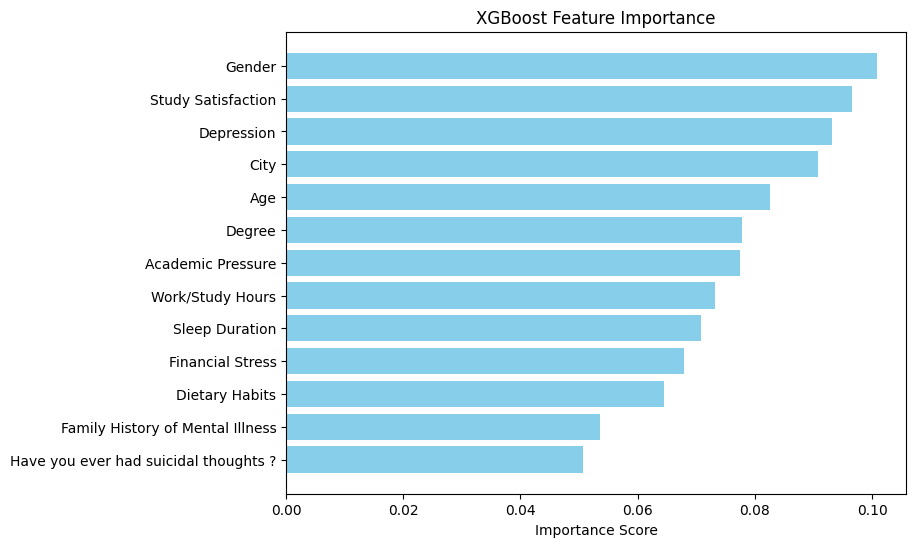

In [ ]:
importance = best_model_base.feature_importances_

feat_imp_base = pd.DataFrame({
    "Feature": X_train_base.columns,
    "Importance": importance
}).sort_values(by="Importance", ascending=False)

print(feat_imp_base)

plt.figure(figsize=(8,6))
plt.barh(feat_imp_base["Feature"], feat_imp_base["Importance"], color="skyblue")
plt.gca().invert_yaxis()
plt.title("XGBoost Feature Importance")
plt.xlabel("Importance Score")
plt.show()


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15),
                0 2px 4px rgba(0,0,0,0.12),
                0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<!-- Purple corner -->
<div style="
    position: absolute; top: -30px; right: -30px;
    width: 120px; height: 120px;
    background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
    z-index: 1;">
</div>

<!-- Dot pattern -->
<div style="
    position: absolute; bottom: 20px; left: 20px;
    width: 60px; height: 60px;
    background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
    background-size: 12px 12px;
    opacity: 0.3; z-index: 1;">
</div>

<h2 style="
    margin-top: 0; margin-bottom: 12px; padding-bottom: 10px;
    font-size: 26px; color: rgba(106,5,114,0.85);
    border-bottom: 2px solid rgba(78,205,196,0.7);
    position: relative; z-index: 2; text-align: center;">
XGBoost Feature Importance – Interpretation
</h2>

<div style="
    position: relative; z-index: 2;
    font-size: 16px; color: #222;
    line-height: 1.6;
">

<b>1. Gender</b> is the strongest predictor of CGPA.<br>
This means performance differences across gender identities appear consistently in the dataset.<br><br>

<b>2. Study Satisfaction</b> has high predictive power.<br>
Students satisfied with their studies tend to show more stable academic performance.<br><br>

<b>3. Depression</b> is a major behavioral factor influencing academic results.<br>
Higher depression levels likely correspond to lower CGPA outcomes.<br><br>

<b>4. City</b> also plays an important role.<br>
Environmental, social, or educational differences across cities may affect academic performance.<br><br>

<b>5. Age</b> has noticeable influence.<br>
Differences in maturity, time management, or academic background may explain this variation.<br><br>

<b>6. Degree</b> moderately contributes to CGPA prediction.<br>
Some programs may be more demanding, influencing students' performance patterns.<br><br>

<b>7. Academic Pressure</b> has medium importance.<br>
While pressure affects stress, it does not perfectly explain academic results by itself.<br><br>

<b>8–10. Work/Study Hours, Sleep Duration, Financial Stress</b> show lower importance.<br>
These lifestyle factors influence performance but are less decisive compared to emotional or demographic parameters.<br><br>

<b>11–13. Dietary Habits, Family Mental Illness History, Suicidal Thoughts</b><br>
These variables have the lowest impact in the model.<br>
They may still have indirect effects, but XGBoost does not rely on them heavily to predict CGPA.<br><br>

</div>

</div>
"""

display(HTML(html_content))


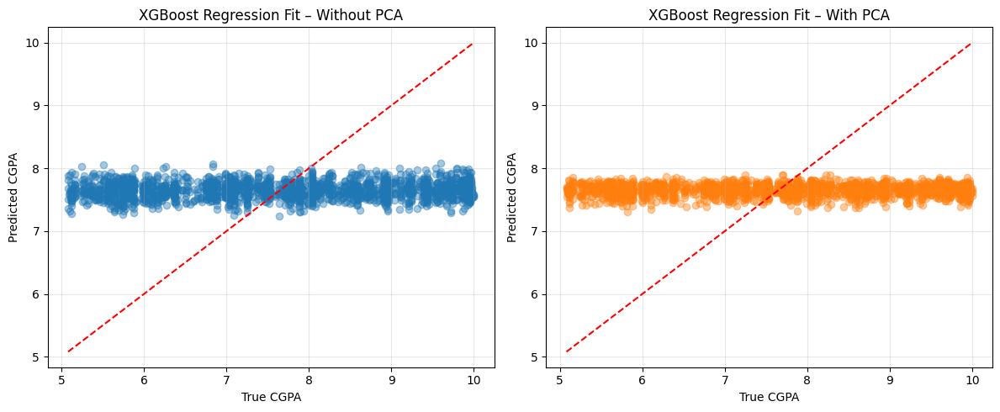

In [ ]:
y_pred_base = best_model_base.predict(X_test_base)
y_pred_pca  = best_model_pca.predict(X_test_pca)

plt.figure(figsize=(12,5))
# WITHOUT PCA
plt.subplot(1, 2, 1)
plt.scatter(y_test, y_pred_base, alpha=0.4, color="#1f77b4")
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()],
         color='red', linestyle='--')
plt.title("XGBoost Regression Fit – Without PCA")
plt.xlabel("True CGPA")
plt.ylabel("Predicted CGPA")
plt.grid(alpha=0.3)

# WITH PCA
plt.subplot(1, 2, 2)
plt.scatter(y_test, y_pred_pca, alpha=0.4, color="#ff7f0e")
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()],
         color='red', linestyle='--')
plt.title("XGBoost Regression Fit – With PCA")
plt.xlabel("True CGPA")
plt.ylabel("Predicted CGPA")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

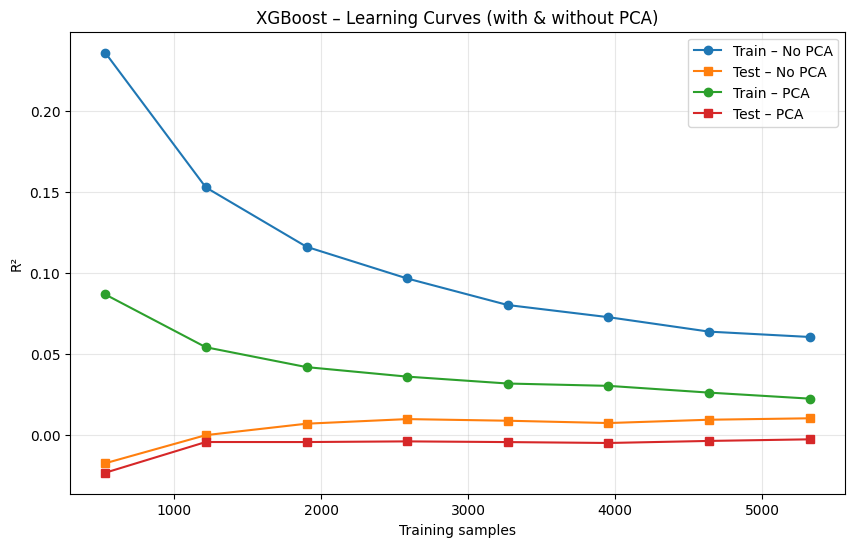

In [ ]:
train_sizes_base, train_scores_base, test_scores_base = learning_curve(
    best_model_base,
    X_train_base, y_train,
    cv=3, train_sizes=np.linspace(0.1, 1.0, 8),
    scoring="r2", n_jobs=-1
)

train_sizes_pca, train_scores_pca, test_scores_pca = learning_curve(
    best_model_pca,
    X_train_pca, y_train,
    cv=3, train_sizes=np.linspace(0.1, 1.0, 8),
    scoring="r2", n_jobs=-1
)

plt.figure(figsize=(10, 6))
plt.plot(train_sizes_base, train_scores_base.mean(axis=1), marker='o', label='Train – No PCA')
plt.plot(train_sizes_base, test_scores_base.mean(axis=1), marker='s', label='Test – No PCA')
plt.plot(train_sizes_pca, train_scores_pca.mean(axis=1), marker='o', label='Train – PCA')
plt.plot(train_sizes_pca, test_scores_pca.mean(axis=1), marker='s', label='Test – PCA')
plt.title("XGBoost – Learning Curves (with & without PCA)")
plt.xlabel("Training samples")
plt.ylabel("R²")
plt.grid(alpha=0.3)
plt.legend()
plt.show()


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15),
                0 2px 4px rgba(0,0,0,0.12),
                0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<div style="
    position: absolute; top: -30px; right: -30px;
    width: 120px; height: 120px;
    background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
    z-index: 1;">
</div>

<div style="
    position: absolute; bottom: 20px; left: 20px;
    width: 60px; height: 60px;
    background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
    background-size: 12px 12px;
    opacity: 0.3; z-index: 1;">
</div>

<h2 style="
    margin-top: 0; margin-bottom: 12px; padding-bottom: 10px;
    font-size: 26px; color: rgba(106,5,114,0.85);
    border-bottom: 2px solid rgba(78,205,196,0.7);
    text-align: center;">
XGBoost Learning Curves – Short Interpretation
</h2>

<div style="font-size: 16px; color: #222; line-height: 1.6;">

• <b>Without PCA</b>, the model overfits early (high train R²) but test R² stays near zero → features have weak predictive power.<br><br>

• <b>With PCA</b>, both curves remain lower and smoother → PCA reduces overfitting but does not improve performance.<br><br>

• <b>All test R² scores are ≈ 0</b>, meaning XGBoost cannot extract meaningful patterns for predicting CGPA.<br><br>

</div>
</div>
"""

display(HTML(html_content))


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15),
                0 2px 4px rgba(0,0,0,0.12),
                0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<!-- Purple accent -->
<div style="
    position: absolute; top: -30px; right: -30px;
    width: 120px; height: 120px;
    background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
    z-index: 1;">
</div>

<!-- Dot accent -->
<div style="
    position: absolute; bottom: 20px; left: 20px;
    width: 60px; height: 60px;
    background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
    background-size: 12px 12px;
    opacity: 0.3; z-index: 1;">
</div>

<h2 style="
    margin-top: 0; margin-bottom: 12px; padding-bottom: 10px;
    font-size: 26px; color: rgba(106,5,114,0.85);
    border-bottom: 2px solid rgba(78,205,196,0.7);
    position: relative; z-index: 2;
    text-align: center;">
Regression Scatter Plot – Interpretation
</h2>

<div style="
    position: relative; z-index: 2;
    font-size: 16px; color: #222; line-height: 1.6;
">

<b>Without/with PCA</b><br>
• Points are scattered far from the red diagonal line.<br>
• Predictions are weak and inconsistent.<br><br>


</div>

</div>
"""

display(HTML(html_content))


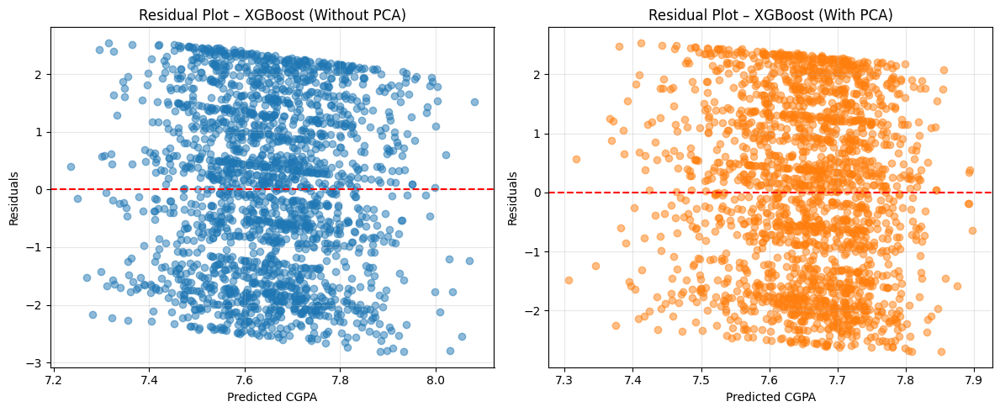

In [ ]:
residuals_base = y_test - y_pred_base
residuals_pca  = y_test - y_pred_pca

plt.figure(figsize=(12,5))

plt.subplot(1, 2, 1)
plt.scatter(y_pred_base, residuals_base, alpha=0.5, color="#1f77b4")
plt.axhline(0, color='red', linestyle='--')
plt.title("Residual Plot – XGBoost (Without PCA)")
plt.xlabel("Predicted CGPA")
plt.ylabel("Residuals")
plt.grid(alpha=0.3)

plt.subplot(1, 2, 2)
plt.scatter(y_pred_pca, residuals_pca, alpha=0.5, color="#ff7f0e")
plt.axhline(0, color='red', linestyle='--')
plt.title("Residual Plot – XGBoost (With PCA)")
plt.xlabel("Predicted CGPA")
plt.ylabel("Residuals")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15),
                0 2px 4px rgba(0,0,0,0.12),
                0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<!-- Purple accent -->
<div style="
    position: absolute; top: -30px; right: -30px;
    width: 120px; height: 120px;
    background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
    z-index: 1;">
</div>

<!-- Dot accent -->
<div style="
    position: absolute; bottom: 20px; left: 20px;
    width: 60px; height: 60px;
    background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
    background-size: 12px 12px;
    opacity: 0.3; z-index: 1;">
</div>

<h2 style="
    margin-top: 0; margin-bottom: 12px; padding-bottom: 10px;
    font-size: 26px; color: rgba(106,5,114,0.85);
    border-bottom: 2px solid rgba(78,205,196,0.7);
    position: relative; z-index: 2;
    text-align: center;">
Regression Scatter Plot – Interpretation
</h2>

<div style="
    position: relative; z-index: 2;
    font-size: 16px; color: #222; line-height: 1.6;
">

<b>Withoutor with PCA</b><br>
• Points are scattered far from the red diagonal line.<br>
• Predictions are weak and inconsistent.<br><br>

</div>

</div>
"""

display(HTML(html_content))


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15), 0 2px 4px rgba(0,0,0,0.12), 0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 12px;
        padding-bottom: 10px;
        font-size: 28px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
 Scatter Plot of CGPA vs Features</h2>
</div>
"""

display(HTML(html_content))


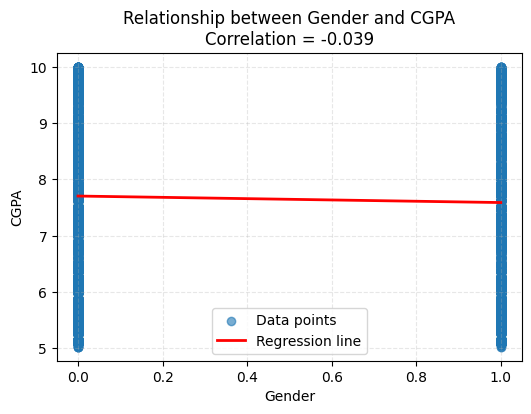

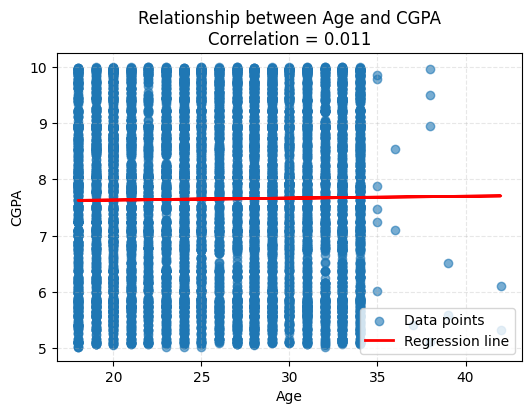

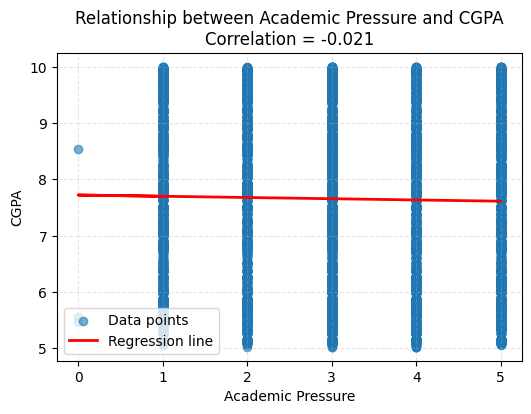

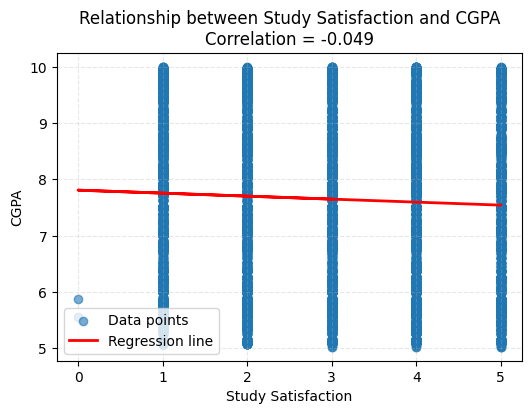

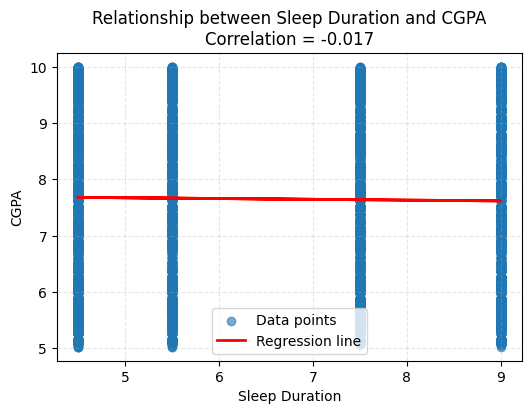

...

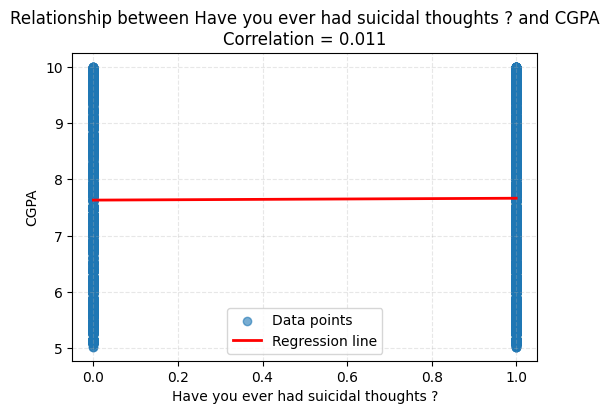

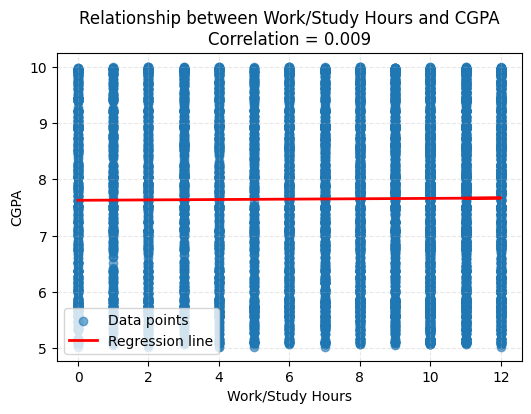

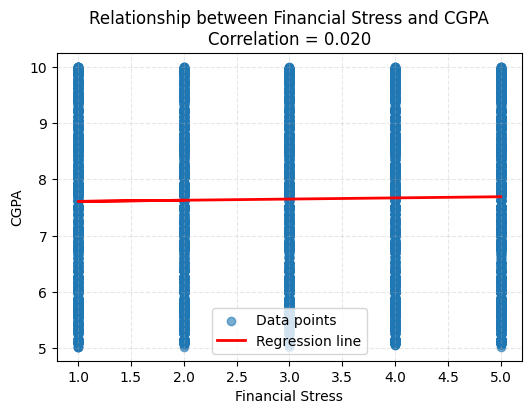

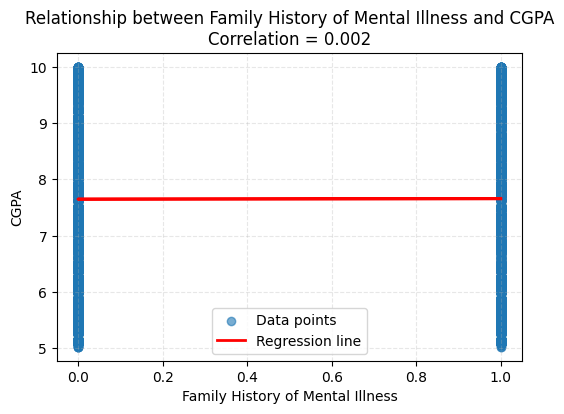

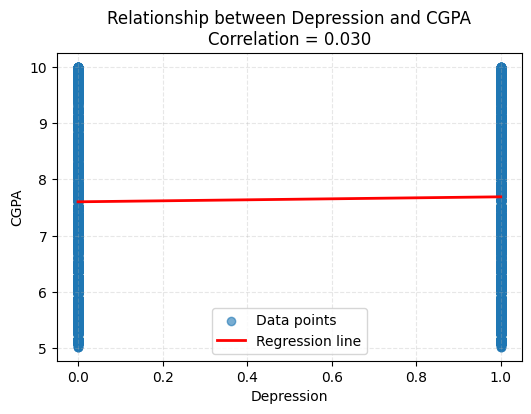

In [ ]:
target = "CGPA"
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
X_cols = [c for c in numeric_cols if c != target]

for col in X_cols:
    X = df[[col]].values
    y = df[target].values

    # Linear regression line
    model = LinearRegression()
    model.fit(X, y)
    y_pred_line = model.predict(X)

    # Compute correlation (Pearson)
    corr = np.corrcoef(df[col], df[target])[0, 1]

    # Plot
    plt.figure(figsize=(6,4))
    plt.scatter(df[col], df[target], alpha=0.6, label="Data points")
    plt.plot(df[col], y_pred_line, color="red", linewidth=2, label="Regression line")

    plt.xlabel(col)
    plt.ylabel(target)
    plt.title(f"Relationship between {col} and {target}\nCorrelation = {corr:.3f}")
    plt.grid(True, linestyle='--', alpha=0.3)
    plt.legend()
    plt.show()

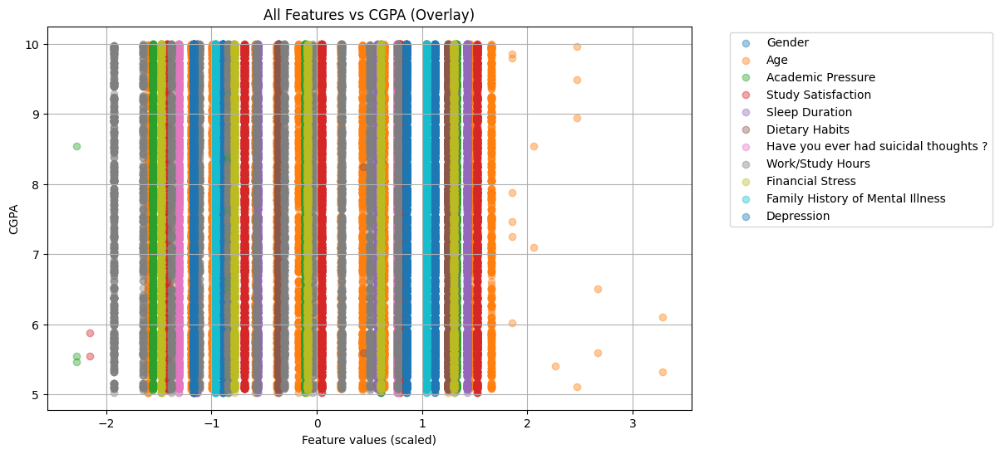

In [ ]:
plt.figure(figsize=(10, 6))

for col in X_cols:
    plt.scatter(df_scaled[col], df["CGPA"], alpha=0.4, label=col)

plt.xlabel("Feature values (scaled)")
plt.ylabel("CGPA")
plt.title("All Features vs CGPA (Overlay)")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True)
plt.show()


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15),
                0 2px 4px rgba(0,0,0,0.12),
                0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<!-- Purple corner -->
<div style="
    position: absolute; top: -30px; right: -30px;
    width: 120px; height: 120px;
    background: linear-gradient(135deg, transparent 60%, rgba(106,5,114,0.9) 95%);
    z-index: 1;">
</div>

<!-- Dot pattern -->
<div style="
    position: absolute; bottom: 20px; left: 20px;
    width: 60px; height: 60px;
    background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
    background-size: 12px 12px;
    opacity: 0.3;
    z-index: 1;">
</div>

<h2 style="
    margin-top: 0;
    margin-bottom: 12px;
    padding-bottom: 10px;
    font-size: 26px;
    color: rgba(106,5,114,0.85);
    border-bottom: 2px solid rgba(78,205,196,0.7);
    text-align: center;
    position: relative;
    z-index: 2;">
Scatter Plot Interpretation
</h2>

<div style="
    position: relative;
    z-index: 2;
    font-size: 16px;
    color: #222;
    line-height: 1.6;
">

The scatter plots show that there is no clear linear or nonlinear relationship between the target variable CGPA and the numerical features. Most variables are weakly or not correlated with CGPA, and the points remain highly dispersed, indicating very low predictive power for linear or polynomial regression.

</div>

</div>
"""

display(HTML(html_content))


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15), 0 2px 4px rgba(0,0,0,0.12), 0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 12px;
        padding-bottom: 10px;
        font-size: 28px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
 Linear Regression</h2>
</div>
"""

display(HTML(html_content))


In [ ]:
X = df_scaled.drop(['CGPA', 'Family History of Mental Illness'
], axis=1)
y = df_scaled['CGPA']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15),
                0 2px 4px rgba(0,0,0,0.12),
                0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<!-- Purple corner -->
<div style="
    position: absolute; top: -30px; right: -30px;
    width: 120px; height: 120px;
    background: linear-gradient(135deg, transparent 60%, rgba(106,5,114,0.9) 95%);
    z-index: 1;">
</div>

<!-- Dot decoration -->
<div style="
    position: absolute; bottom: 20px; left: 20px;
    width: 60px; height: 60px;
    background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
    background-size: 12px 12px;
    opacity: 0.3;
    z-index: 1;">
</div>

<h2 style="
    margin-top: 0;
    margin-bottom: 12px;
    padding-bottom: 10px;
    font-size: 26px;
    color: rgba(106,5,114,0.85);
    border-bottom: 2px solid rgba(78,205,196,0.7);
    text-align: center;
    position: relative;
    z-index: 2;">
Feature Removal Justification
</h2>

<div style="
    position: relative;
    z-index: 2;
    font-size: 16px;
    color: #222;
    line-height: 1.6;
">

removed "Family History of Mental Illness" from the df_scaled because it has no correlation with the target CGPA (correlation = 0) according to the correlation matrix.

</div>

</div>
"""

display(HTML(html_content))


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15),
                0 2px 4px rgba(0,0,0,0.12),
                0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<!-- Purple accent -->
<div style="
    position: absolute;
    top: -30px;
    right: -30px;
    width: 120px;
    height: 120px;
    background: linear-gradient(135deg, transparent 60%, rgba(106,5,114,0.9) 95%);
    z-index: 1;">
</div>

<!-- Decorative dots -->
<div style="
    position: absolute;
    bottom: 20px;
    left: 20px;
    width: 60px;
    height: 60px;
    background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
    background-size: 12px 12px;
    opacity: 0.3;
    z-index: 1;">
</div>

<h2 style="
    margin-top: 0;
    margin-bottom: 12px;
    padding-bottom: 10px;
    font-size: 26px;
    color: rgba(106,5,114,0.85);
    border-bottom: 2px solid rgba(78,205,196,0.7);
    text-align: center;
    position: relative;
    z-index: 2;">
Application of Backward Elimination
</h2>

</div>
"""

display(HTML(html_content))


In [ ]:
X_be = X_train.copy()
X_be_const = sm.add_constant(X_be)

model1 = sm.OLS(y_train, X_be_const).fit()
print(model1.summary())


                            OLS Regression Results                            
Dep. Variable:                   CGPA   R-squared:                       0.010
Model:                            OLS   Adj. R-squared:                  0.009
Method:                 Least Squares   F-statistic:                     7.020
Date:                Thu, 27 Nov 2025   Prob (F-statistic):           7.58e-13
Time:                        13:53:33   Log-Likelihood:                -11274.
No. Observations:                7985   AIC:                         2.257e+04
Df Residuals:                    7972   BIC:                         2.267e+04
Df Model:                          12                                         
Covariance Type:            nonrobust                                         
                                            coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------------------------

In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15),
                0 2px 4px rgba(0,0,0,0.12),
                0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<!-- Purple corner -->
<div style="
    position: absolute; top: -30px; right: -30px;
    width: 120px; height: 120px;
    background: linear-gradient(135deg, transparent 60%, rgba(106,5,114,0.9) 95%);
    z-index: 1;">
</div>

<!-- Dot decoration -->
<div style="
    position: absolute; bottom: 20px; left: 20px;
    width: 60px; height: 60px;
    background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
    background-size: 12px 12px;
    opacity: 0.3; z-index: 1;">
</div>

<h2 style="
    margin-top: 0;
    margin-bottom: 12px;
    padding-bottom: 10px;
    font-size: 26px;
    color: rgba(106,5,114,0.85);
    border-bottom: 2px solid rgba(78,205,196,0.7);
    text-align: center;
    position: relative;
    z-index: 2;">
Backward Elimination – p-Value Interpretation
</h2>

<div style="
    position: relative;
    z-index: 2;
    font-size: 16px;
    color: #222;
    line-height: 1.6;
">

• <b>0.05</b> is the standard significance threshold in inferential statistics.<br><br>

• When <b>p > 0.05</b>, the variable does not show a statistically meaningful effect on the target.<br><br>

• <b>Dietary Habits</b> has the highest p-value (<b>p = 0.933</b>) and will therefore be removed, as it is not contributing to the model.

</div>

</div>
"""

display(HTML(html_content))

In [ ]:

X_be = X_be.drop(columns=['Dietary Habits'])
X_be_const = sm.add_constant(X_be)
model2 = sm.OLS(y_train, X_be_const).fit()
print(model2.summary())
print(model2.pvalues.sort_values(ascending=False))

                            OLS Regression Results                            
Dep. Variable:                   CGPA   R-squared:                       0.010
Model:                            OLS   Adj. R-squared:                  0.009
Method:                 Least Squares   F-statistic:                     7.658
Date:                Thu, 27 Nov 2025   Prob (F-statistic):           2.65e-13
Time:                        13:53:40   Log-Likelihood:                -11274.
No. Observations:                7985   AIC:                         2.257e+04
Df Residuals:                    7973   BIC:                         2.266e+04
Df Model:                          11                                         
Covariance Type:            nonrobust                                         
                                            coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------------------------

In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15),
                0 2px 4px rgba(0,0,0,0.12),
                0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<!-- Purple corner -->
<div style="
    position: absolute; top: -30px; right: -30px;
    width: 120px; height: 120px;
    background: linear-gradient(135deg, transparent 60%, rgba(106,5,114,0.9) 95%);
    z-index: 1;">
</div>

<!-- Dot pattern -->
<div style="
    position: absolute; bottom: 20px; left: 20px;
    width: 60px; height: 60px;
    background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
    background-size: 12px 12px;
    opacity: 0.3; z-index: 1;">
</div>

<h2 style="
    margin-top: 0;
    margin-bottom: 12px;
    padding-bottom: 10px;
    font-size: 26px;
    color: rgba(106,5,114,0.85);
    border-bottom: 2px solid rgba(78,205,196,0.7);
    text-align: center;
    position: relative;
    z-index: 2;">
Backward Elimination – Step Interpretation
</h2>

<div style="
    position: relative;
    z-index: 2;
    font-size: 16px;
    color: #222;
    line-height: 1.6;
">

<b>Work/Study Hours</b> variable (<b>p = 0.580</b>) will be removed because it has the largest p-value above the <b>0.05</b> significance threshold.

</div>

</div>
"""

display(HTML(html_content))


In [ ]:
X_be = X_be.drop(columns=['Work/Study Hours'])
X_be_const = sm.add_constant(X_be)
model3 = sm.OLS(y_train, X_be_const).fit()
print(model3.summary())
print(model3.pvalues.sort_values(ascending=False))


                            OLS Regression Results                            
Dep. Variable:                   CGPA   R-squared:                       0.010
Model:                            OLS   Adj. R-squared:                  0.009
Method:                 Least Squares   F-statistic:                     8.394
Date:                Thu, 27 Nov 2025   Prob (F-statistic):           1.01e-13
Time:                        13:53:49   Log-Likelihood:                -11275.
No. Observations:                7985   AIC:                         2.257e+04
Df Residuals:                    7974   BIC:                         2.265e+04
Df Model:                          10                                         
Covariance Type:            nonrobust                                         
                                            coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------------------------

In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15),
                0 2px 4px rgba(0,0,0,0.12),
                0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<!-- Purple corner -->
<div style="
    position: absolute; top: -30px; right: -30px;
    width: 120px; height: 120px;
    background: linear-gradient(135deg, transparent 60%, rgba(106,5,114,0.9) 95%);
    z-index: 1;">
</div>

<!-- Dot accents -->
<div style="
    position: absolute; bottom: 20px; left: 20px;
    width: 60px; height: 60px;
    background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
    background-size: 12px 12px;
    opacity: 0.3;
    z-index: 1;">
</div>

<h2 style="
    margin-top: 0;
    margin-bottom: 12px;
    padding-bottom: 10px;
    font-size: 26px;
    color: rgba(106,5,114,0.85);
    border-bottom: 2px solid rgba(78,205,196,0.7);
    text-align: center;
    position: relative;
    z-index: 2;">
Backward Elimination – Step Interpretation
</h2>

<div style="
    position: relative;
    z-index: 2;
    font-size: 16px;
    color: #222;
    line-height: 1.6;
">

<b>Sleep Duration</b> variable (<b>p = 0.287</b>) will be removed because it has the highest p-value above the <b>0.05</b> significance threshold.

</div>

</div>
"""

display(HTML(html_content))


In [ ]:
X_be = X_be.drop(columns=['Sleep Duration'])
X_be_const = sm.add_constant(X_be)
model4 = sm.OLS(y_train, X_be_const).fit()
print(model4.summary())
print(model4.pvalues.sort_values(ascending=False))


                            OLS Regression Results                            
Dep. Variable:                   CGPA   R-squared:                       0.010
Model:                            OLS   Adj. R-squared:                  0.009
Method:                 Least Squares   F-statistic:                     9.201
Date:                Thu, 27 Nov 2025   Prob (F-statistic):           5.33e-14
Time:                        13:53:53   Log-Likelihood:                -11275.
No. Observations:                7985   AIC:                         2.257e+04
Df Residuals:                    7975   BIC:                         2.264e+04
Df Model:                           9                                         
Covariance Type:            nonrobust                                         
                                            coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------------------------

In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15),
                0 2px 4px rgba(0,0,0,0.12),
                0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<!-- Purple corner -->
<div style="
    position: absolute; top: -30px; right: -30px;
    width: 120px; height: 120px;
    background: linear-gradient(135deg, transparent 60%, rgba(106,5,114,0.9) 95%);
    z-index: 1;">
</div>

<!-- Dot pattern -->
<div style="
    position: absolute; bottom: 20px; left: 20px;
    width: 60px; height: 60px;
    background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
    background-size: 12px 12px;
    opacity: 0.3;
    z-index: 1;">
</div>

<h2 style="
    margin-top: 0;
    margin-bottom: 12px;
    padding-bottom: 10px;
    font-size: 26px;
    color: rgba(106,5,114,0.85);
    border-bottom: 2px solid rgba(78,205,196,0.7);
    text-align: center;
    position: relative;
    z-index: 2;">
Backward Elimination – Step Interpretation
</h2>

<div style="
    position: relative;
    z-index: 2;
    font-size: 16px;
    color: #222;
    line-height: 1.6;
">

<b>Have you ever had suicidal thoughts</b> variable (<b>p = 0.248</b>) will be removed because it has the highest p-value above the <b>0.05</b> significance threshold.

</div>

</div>
"""

display(HTML(html_content))


In [ ]:

X_be = X_be.drop(columns=['Have you ever had suicidal thoughts ?'])
X_be_const = sm.add_constant(X_be)
model5 = sm.OLS(y_train, X_be_const).fit()
print(model5.summary())
print(model5.pvalues.sort_values(ascending=False))


                            OLS Regression Results                            
Dep. Variable:                   CGPA   R-squared:                       0.010
Model:                            OLS   Adj. R-squared:                  0.009
Method:                 Least Squares   F-statistic:                     10.18
Date:                Thu, 27 Nov 2025   Prob (F-statistic):           2.94e-14
Time:                        13:53:58   Log-Likelihood:                -11276.
No. Observations:                7985   AIC:                         2.257e+04
Df Residuals:                    7976   BIC:                         2.263e+04
Df Model:                           8                                         
Covariance Type:            nonrobust                                         
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
const                 -0.0007      0

In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15),
                0 2px 4px rgba(0,0,0,0.12),
                0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<!-- Purple corner -->
<div style="
    position: absolute; top: -30px; right: -30px;
    width: 120px; height: 120px;
    background: linear-gradient(135deg, transparent 60%, rgba(106,5,114,0.9) 95%);
    z-index: 1;">
</div>

<!-- Decorative dots -->
<div style="
    position: absolute; bottom: 20px; left: 20px;
    width: 60px; height: 60px;
    background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
    background-size: 12px 12px;
    opacity: 0.3;
    z-index: 1;">
</div>

<h2 style="
    margin-top: 0;
    margin-bottom: 12px;
    padding-bottom: 10px;
    font-size: 26px;
    color: rgba(106,5,114,0.85);
    border-bottom: 2px solid rgba(78,205,196,0.7);
    text-align: center;
    position: relative;
    z-index: 2;">
Backward Elimination – Step Interpretation
</h2>

<div style="
    position: relative;
    z-index: 2;
    font-size: 16px;
    color: #222;
    line-height: 1.6;
">

<b>Financial Stress</b> variable (<b>p = 0.096</b>) will be removed because it has the highest p-value above the <b>0.05</b> significance threshold.

</div>

</div>
"""

display(HTML(html_content))


In [ ]:

X_be = X_be.drop(columns=['Financial Stress'])
X_be_const = sm.add_constant(X_be)
model6 = sm.OLS(y_train, X_be_const).fit()
print(model6.summary())
print(model6.pvalues.sort_values(ascending=False))


                            OLS Regression Results                            
Dep. Variable:                   CGPA   R-squared:                       0.010
Model:                            OLS   Adj. R-squared:                  0.009
Method:                 Least Squares   F-statistic:                     11.24
Date:                Thu, 27 Nov 2025   Prob (F-statistic):           3.01e-14
Time:                        13:54:03   Log-Likelihood:                -11277.
No. Observations:                7985   AIC:                         2.257e+04
Df Residuals:                    7977   BIC:                         2.263e+04
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
const                 -0.0007      0

In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15),
                0 2px 4px rgba(0,0,0,0.12),
                0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<!-- Purple corner -->
<div style="
    position: absolute; top: -30px; right: -30px;
    width: 120px; height: 120px;
    background: linear-gradient(135deg, transparent 60%, rgba(106,5,114,0.9) 95%);
    z-index: 1;">
</div>

<!-- Dot pattern -->
<div style="
    position: absolute; bottom: 20px; left: 20px;
    width: 60px; height: 60px;
    background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
    background-size: 12px 12px;
    opacity: 0.3;
    z-index: 1;">
</div>

<h2 style="
    margin-top: 0;
    margin-bottom: 12px;
    padding-bottom: 10px;
    font-size: 26px;
    color: rgba(106,5,114,0.85);
    border-bottom: 2px solid rgba(78,205,196,0.7);
    text-align: center;
    position: relative;
    z-index: 2;">
Backward Elimination – Step Interpretation
</h2>

<div style="
    position: relative;
    z-index: 2;
    font-size: 16px;
    color: #222;
    line-height: 1.6;
">

<b>Degree</b> variable (<b>p = 0.064</b>) will be removed because it has the highest p-value above the <b>0.05</b> significance threshold.

</div>

</div>
"""

display(HTML(html_content))


In [ ]:

X_be = X_be.drop(columns=['Degree'])
X_be_const = sm.add_constant(X_be)
model7 = sm.OLS(y_train, X_be_const).fit()
print(model7.summary())
print(model7.pvalues.sort_values(ascending=False))


                            OLS Regression Results                            
Dep. Variable:                   CGPA   R-squared:                       0.009
Model:                            OLS   Adj. R-squared:                  0.009
Method:                 Least Squares   F-statistic:                     12.54
Date:                Thu, 27 Nov 2025   Prob (F-statistic):           3.99e-14
Time:                        13:54:08   Log-Likelihood:                -11279.
No. Observations:                7985   AIC:                         2.257e+04
Df Residuals:                    7978   BIC:                         2.262e+04
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
const                 -0.0006      0

In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15),
                0 2px 4px rgba(0,0,0,0.12),
                0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<!-- Purple corner accent -->
<div style="
    position: absolute; top: -30px; right: -30px;
    width: 120px; height: 120px;
    background: linear-gradient(135deg, transparent 60%, rgba(106,5,114,0.9) 95%);
    z-index: 1;">
</div>

<!-- Dotted background effect -->
<div style="
    position: absolute; bottom: 20px; left: 20px;
    width: 60px; height: 60px;
    background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
    background-size: 12px 12px;
    opacity: 0.3;
    z-index: 1;">
</div>

<h2 style="
    margin-top: 0;
    margin-bottom: 12px;
    padding-bottom: 10px;
    font-size: 26px;
    color: rgba(106,5,114,0.85);
    border-bottom: 2px solid rgba(78,205,196,0.7);
    text-align: center;
    position: relative;
    z-index: 2;">
Backward Elimination – Step Interpretation
</h2>

<div style="
    position: relative;
    z-index: 2;
    font-size: 16px;
    color: #222;
    line-height: 1.6;
">

<b>Age</b> variable (<b>p = 0.06</b>) will be removed because it has the highest p-value above the <b>0.05</b> significance threshold.

</div>

</div>
"""

display(HTML(html_content))


In [ ]:
X_be = X_be.drop(columns=['Age'])
X_be_const = sm.add_constant(X_be)
model8 = sm.OLS(y_train, X_be_const).fit()
print(model8.summary())
print(model8.pvalues.sort_values(ascending=False))


                            OLS Regression Results                            
Dep. Variable:                   CGPA   R-squared:                       0.009
Model:                            OLS   Adj. R-squared:                  0.008
Method:                 Least Squares   F-statistic:                     14.36
Date:                Thu, 27 Nov 2025   Prob (F-statistic):           5.01e-14
Time:                        13:54:21   Log-Likelihood:                -11281.
No. Observations:                7985   AIC:                         2.257e+04
Df Residuals:                    7979   BIC:                         2.262e+04
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
const                 -0.0007      0

In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15),
                0 2px 4px rgba(0,0,0,0.12),
                0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<!-- Purple corner -->
<div style="
    position: absolute; top: -30px; right: -30px;
    width: 120px; height: 120px;
    background: linear-gradient(135deg, transparent 60%, rgba(106,5,114,0.9) 95%);
    z-index: 1;">
</div>

<!-- Dot decoration -->
<div style="
    position: absolute; bottom: 20px; left: 20px;
    width: 60px; height: 60px;
    background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
    background-size: 12px 12px;
    opacity: 0.3; z-index: 1;">
</div>

<h2 style="
    margin-top: 0;
    margin-bottom: 12px;
    padding-bottom: 10px;
    font-size: 26px;
    color: rgba(106,5,114,0.85);
    border-bottom: 2px solid rgba(78,205,196,0.7);
    text-align: center;
    position: relative;
    z-index: 2;">
Backward Elimination – Final Interpretation
</h2>

<div style="
    position: relative;
    z-index: 2;
    font-size: 16px;
    color: #222;
    line-height: 1.6;
">

Although all variables retained after backward elimination have <b>p-values < 0.05</b>, their actual influence on CGPA is extremely weak.<br><br>

• Coefficients are near zero.<br>
• The <b>R² remains close to 0</b> → the model explains almost none of the variance.<br>

Therefore, even after feature selection, <b>linear regression is not suitable</b> for predicting CGPA in this dataset.

</div>

</div>
"""

display(HTML(html_content))


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15),
                0 2px 4px rgba(0,0,0,0.12),
                0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<!-- Purple corner -->
<div style="
    position: absolute; top: -30px; right: -30px;
    width: 120px; height: 120px;
    background: linear-gradient(135deg, transparent 60%, rgba(106,5,114,0.9) 95%);
    z-index: 1;">
</div>

<!-- Dot decoration -->
<div style="
    position: absolute; bottom: 20px; left: 20px;
    width: 60px; height: 60px;
    background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
    background-size: 12px 12px;
    opacity: 0.3;
    z-index: 1;">
</div>

<h2 style="
    margin-top: 0;
    margin-bottom: 12px;
    padding-bottom: 10px;
    font-size: 26px;
    color: rgba(106,5,114,0.85);
    border-bottom: 2px solid rgba(78,205,196,0.7);
    text-align: center;
    position: relative;
    z-index: 2;">
Backward Elimination – Final Linear Regression Model
</h2>

<div style="
    position: relative;
    z-index: 2;
    font-size: 16px;
    color: #222;
    line-height: 1.6;
">

Train the linear regression model using the new features selected by backward elimination.

</div>

</div>
"""

display(HTML(html_content))


In [ ]:
selected_features = ['Gender', 'City', 'Academic Pressure', 'Study Satisfaction', 'Depression']

X_train_sel = X_train[selected_features]
X_test_sel = X_test[selected_features]

lin_reg_final = LinearRegression()
lin_reg_final.fit(X_train_sel, y_train)

y_pred_train = lin_reg_final.predict(X_train_sel)
y_pred_test  = lin_reg_final.predict(X_test_sel)

rmse_train = np.sqrt(mean_squared_error(y_train, y_pred_train))
rmse_test  = np.sqrt(mean_squared_error(y_test, y_pred_test))
r2_train   = r2_score(y_train, y_pred_train)
r2_test    = r2_score(y_test, y_pred_test)

print("\n Performance du modèle final (Backward Elimination)")
print(f"RMSE Train : {rmse_train:.4f}")
print(f"RMSE Test  : {rmse_test:.4f}")
print(f"R² Train   : {r2_train:.4f}")
print(f"R² Test    : {r2_test:.4f}")



 Performance du modèle final (Backward Elimination)
RMSE Train : 0.9938
RMSE Test  : 1.0085
R² Train   : 0.0089
R² Test    : -0.0032


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15),
                0 2px 4px rgba(0,0,0,0.12),
                0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<!-- Purple corner -->
<div style="
    position: absolute; top: -30px; right: -30px;
    width: 120px; height: 120px;
    background: linear-gradient(135deg, transparent 60%, rgba(106,5,114,0.9) 95%);
    z-index: 1;">
</div>

<!-- Dot decoration -->
<div style="
    position: absolute; bottom: 20px; left: 20px;
    width: 60px; height: 60px;
    background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
    background-size: 12px 12px;
    opacity: 0.3;
    z-index: 1;">
</div>

<h2 style="
    margin-top: 0;
    margin-bottom: 12px;
    padding-bottom: 10px;
    font-size: 26px;
    color: rgba(106,5,114,0.85);
    border-bottom: 2px solid rgba(78,205,196,0.7);
    text-align: center;
    position: relative;
    z-index: 2;">
Backward Elimination – Conclusion
</h2>

<div style="
    position: relative;
    z-index: 2;
    font-size: 16px;
    color: #222;
    line-height: 1.6;
">

Even if the selected variables are statistically significant, their predictive power remains <b>very weak</b>.
This indicates that CGPA is likely influenced by <b>other important factors</b> that are not included in the dataset, making linear regression unsuitable for accurate prediction in this context.

</div>

</div>
"""

display(HTML(html_content))


In [ ]:
print("\n Paramètres du modèle")
print(f"Intercept (a) : {lin_reg_final.intercept_:.4f}")
print("\nCoefficients (b) :")
for feature, coef in zip(selected_features, lin_reg_final.coef_):
    print(f"  {feature:20s} : {coef:.4f}")

print("\nÉquation du modèle :")
equation = f"y = {lin_reg_final.intercept_:.4f}"
for feature, coef in zip(selected_features, lin_reg_final.coef_):
    sign = "+" if coef >= 0 else ""
    equation += f" {sign} {coef:.4f} * {feature}"
print(equation)


 Paramètres du modèle
Intercept (a) : -0.0007

Coefficients (b) :
  Gender               : -0.0422
  City                 : -0.0271
  Academic Pressure    : -0.0566
  Study Satisfaction   : -0.0479
  Depression           : 0.0564

Équation du modèle :
y = -0.0007  -0.0422 * Gender  -0.0271 * City  -0.0566 * Academic Pressure  -0.0479 * Study Satisfaction + 0.0564 * Depression


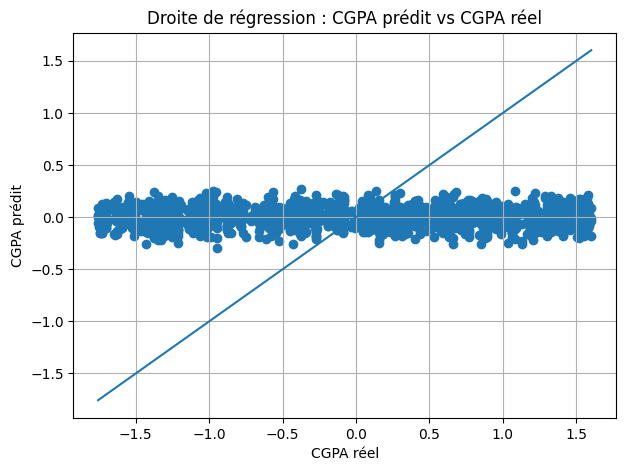

In [ ]:
plt.figure(figsize=(7,5))
plt.scatter(y_test, y_pred_test)

line = np.linspace(min(y_test), max(y_test), 100)
plt.plot(line, line)

plt.xlabel("CGPA réel")
plt.ylabel("CGPA prédit")
plt.title("Droite de régression : CGPA prédit vs CGPA réel")
plt.grid(True)
plt.show()


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15),
                0 2px 4px rgba(0,0,0,0.12),
                0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<!-- Purple corner -->
<div style="
    position: absolute; top: -30px; right: -30px;
    width: 120px; height: 120px;
    background: linear-gradient(135deg, transparent 60%, rgba(106,5,114,0.9) 95%);
    z-index: 1;">
</div>

<!-- Dot accents -->
<div style="
    position: absolute; bottom: 20px; left: 20px;
    width: 60px; height: 60px;
    background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
    background-size: 12px 12px;
    opacity: 0.3;
    z-index: 1;">
</div>

<h2 style="
    margin-top: 0;
    margin-bottom: 12px;
    padding-bottom: 10px;
    font-size: 26px;
    color: rgba(106,5,114,0.85);
    border-bottom: 2px solid rgba(78,205,196,0.7);
    text-align: center;
    position: relative;
    z-index: 2;">
Regression Fit – Interpretation
</h2>

<div style="
    position: relative;
    z-index: 2;
    font-size: 16px;
    color: #222;
    line-height: 1.6;
">

The large gap between the predictions and the ideal regression line shows that the linear model fails to explain the variability in <b>CGPA</b>.<br><br>

• Predictions remain almost constant and do not follow the true values.<br>
• The model shows <b>very poor performance</b>.<br>
• It does not capture the real relationship between the selected variables and CGPA.<br><br>

This confirms that <b>linear regression is not suitable</b> for this dataset.

</div>

</div>
"""

display(HTML(html_content))


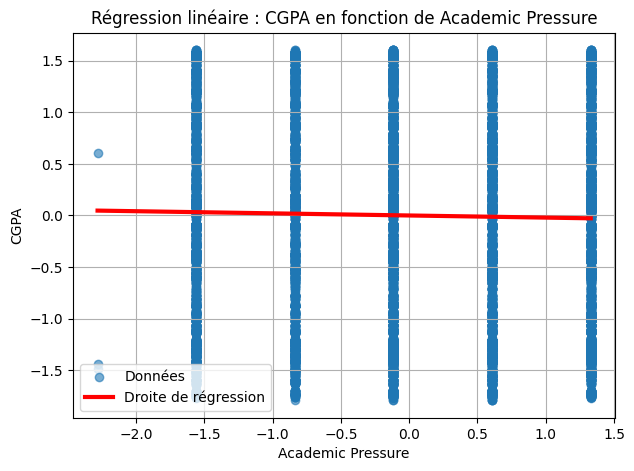

In [ ]:
feature = "Academic Pressure"

X_feat = df_scaled[[feature]]
y_all = df_scaled["CGPA"]

reg = LinearRegression()
reg.fit(X_feat, y_all)

x_vals = np.linspace(X_feat[feature].min(), X_feat[feature].max(), 100).reshape(-1, 1)
y_vals = reg.predict(x_vals)

plt.figure(figsize=(7,5))
plt.scatter(X_feat[feature], y_all, alpha=0.6, label="Données")
plt.plot(x_vals, y_vals, linewidth=3, color='red', label="Droite de régression")
plt.xlabel(feature)
plt.ylabel("CGPA")
plt.title("Régression linéaire : CGPA en fonction de " + feature)
plt.legend()
plt.grid(True)
plt.show()


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15),
                0 2px 4px rgba(0,0,0,0.12),
                0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<!-- Purple corner -->
<div style="
    position: absolute; top: -30px; right: -30px;
    width: 120px; height: 120px;
    background: linear-gradient(135deg, transparent 60%, rgba(106,5,114,0.9) 95%);
    z-index: 1;">
</div>

<!-- Dot decoration -->
<div style="
    position: absolute; bottom: 20px; left: 20px;
    width: 60px; height: 60px;
    background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
    background-size: 12px 12px;
    opacity: 0.3;
    z-index: 1;">
</div>

<h2 style="
    margin-top: 0;
    margin-bottom: 12px;
    padding-bottom: 10px;
    font-size: 26px;
    color: rgba(106,5,114,0.85);
    border-bottom: 2px solid rgba(78,205,196,0.7);
    position: relative;
    z-index: 2;
    text-align: center;">
Academic Pressure vs CGPA – Interpretation
</h2>

<div style="
    position: relative;
    z-index: 2;
    font-size: 16px;
    color: #222;
    line-height: 1.6;
">

The plot does not suggest any meaningful relationship between <b>Academic Pressure</b> and <b>CGPA</b>.<br><br>

• The points are highly dispersed with no visible trend.<br>
• The regression line is almost flat, indicating no predictive value.<br>
• Even nonlinear models would not improve results because <b>no exploitable pattern</b> exists.<br><br>

This confirms that Academic Pressure is <b>not a useful predictor</b> of CGPA in this dataset.

</div>

</div>
"""

display(HTML(html_content))


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15),
                0 2px 4px rgba(0,0,0,0.12),
                0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<!-- Purple corner -->
<div style="
    position: absolute; top: -30px; right: -30px;
    width: 120px; height: 120px;
    background: linear-gradient(135deg, transparent 60%, rgba(106,5,114,0.9) 95%);
    z-index: 1;">
</div>

<!-- Dot accents -->
<div style="
    position: absolute; bottom: 20px; left: 20px;
    width: 60px; height: 60px;
    background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
    background-size: 12px 12px;
    opacity: 0.3;
    z-index: 1;">
</div>

<h2 style="
    margin-top: 0;
    margin-bottom: 12px;
    padding-bottom: 10px;
    font-size: 26px;
    color: rgba(106,5,114,0.85);
    border-bottom: 2px solid rgba(78,205,196,0.7);
    text-align: center;
    position: relative;
    z-index: 2;">
Linear Regression with Gradient Descent
</h2>

</div>
"""

display(HTML(html_content))


In [ ]:
selected_features = ['Gender', 'City', 'Academic Pressure', 'Study Satisfaction', 'Depression']

X_train_sel = X_train[selected_features].values
X_test_sel  = X_test[selected_features].values

y_train_vec = y_train.values.reshape(-1, 1)
y_test_vec  = y_test.values.reshape(-1, 1)

m, n = X_train_sel.shape


w = np.zeros((n, 1))
b = 0.0

alpha = 0.01
n_iters = 2000

cost_history = []


for i in range(n_iters):
    y_pred = X_train_sel @ w + b
    error = y_pred - y_train_vec


    dw = (2/m) * (X_train_sel.T @ error)
    db = (2/m) * np.sum(error)


    w = w - alpha * dw
    b = b - alpha * db

    mse = (1/m) * np.sum(error**2)
    cost_history.append(mse)

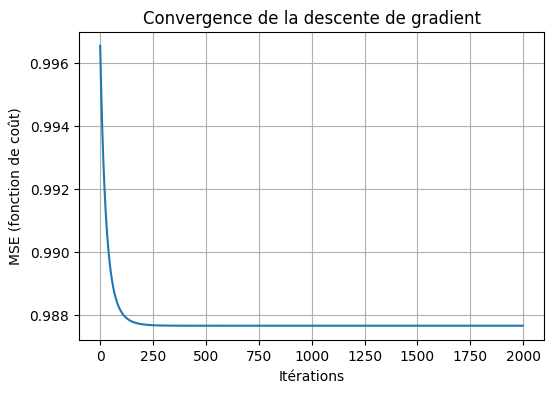

 Paramètres appris (Gradient Descent) 
b (biais) : -0.000669
            Gender : -0.042155
              City : -0.027101
 Academic Pressure : -0.056610
Study Satisfaction : -0.047874
        Depression : 0.056446

 Performance (Gradient Descent)
RMSE Train : 0.9938
RMSE Test  : 1.0085
R² Train   : 0.0089
R² Test    : -0.0032

 Paramètres (sklearn LinearRegression) 
b (intercept) : -0.000669
            Gender : -0.042155
              City : -0.027101
 Academic Pressure : -0.056610
Study Satisfaction : -0.047874
        Depression : 0.056446

 Performance (sklearn LinearRegression) 
RMSE Train : 0.9938
RMSE Test  : 1.0085
R² Train   : 0.0089
R² Test    : -0.0032


In [ ]:
plt.figure(figsize=(6,4))
plt.plot(range(n_iters), cost_history)
plt.xlabel("Itérations")
plt.ylabel("MSE (fonction de coût)")
plt.title("Convergence de la descente de gradient")
plt.grid(True)
plt.show()


y_pred_train_gd = X_train_sel @ w + b
y_pred_test_gd  = X_test_sel  @ w + b

rmse_train_gd = np.sqrt(mean_squared_error(y_train_vec, y_pred_train_gd))
rmse_test_gd  = np.sqrt(mean_squared_error(y_test_vec,  y_pred_test_gd))
r2_train_gd   = r2_score(y_train_vec, y_pred_train_gd)
r2_test_gd    = r2_score(y_test_vec,  y_pred_test_gd)

print(" Paramètres appris (Gradient Descent) ")
print(f"b (biais) : {b:.6f}")
for name, val in zip(selected_features, w.flatten()):
    print(f"{name:>18s} : {val:.6f}")

print("\n Performance (Gradient Descent)")
print(f"RMSE Train : {rmse_train_gd:.4f}")
print(f"RMSE Test  : {rmse_test_gd:.4f}")
print(f"R² Train   : {r2_train_gd:.4f}")
print(f"R² Test    : {r2_test_gd:.4f}")


lin_reg = LinearRegression()
lin_reg.fit(X_train_sel, y_train_vec)

y_pred_train_sk = lin_reg.predict(X_train_sel)
y_pred_test_sk  = lin_reg.predict(X_test_sel)

rmse_train_sk = np.sqrt(mean_squared_error(y_train_vec, y_pred_train_sk))
rmse_test_sk  = np.sqrt(mean_squared_error(y_test_vec,  y_pred_test_sk))
r2_train_sk   = r2_score(y_train_vec, y_pred_train_sk)
r2_test_sk    = r2_score(y_test_vec,  y_pred_test_sk)

print("\n Paramètres (sklearn LinearRegression) ")
print(f"b (intercept) : {lin_reg.intercept_[0]:.6f}")
for name, val in zip(selected_features, lin_reg.coef_.flatten()):
    print(f"{name:>18s} : {val:.6f}")

print("\n Performance (sklearn LinearRegression) ")
print(f"RMSE Train : {rmse_train_sk:.4f}")
print(f"RMSE Test  : {rmse_test_sk:.4f}")
print(f"R² Train   : {r2_train_sk:.4f}")
print(f"R² Test    : {r2_test_sk:.4f}")


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15),
                0 2px 4px rgba(0,0,0,0.12),
                0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<!-- Purple corner -->
<div style="
    position: absolute; top: -30px; right: -30px;
    width: 120px; height: 120px;
    background: linear-gradient(135deg, transparent 60%, rgba(106,5,114,0.9) 95%);
    z-index: 1;">
</div>

<!-- Dot decoration -->
<div style="
    position: absolute; bottom: 20px; left: 20px;
    width: 60px; height: 60px;
    background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
    background-size: 12px 12px;
    opacity: 0.3;
    z-index: 1;">
</div>

<h2 style="
    margin-top: 0;
    margin-bottom: 12px;
    padding-bottom: 10px;
    font-size: 26px;
    color: rgba(106,5,114,0.85);
    border-bottom: 2px solid rgba(78,205,196,0.7);
    text-align: center;
    position: relative;
    z-index: 2;">
Gradient Descent
</h2>

<div style="
    position: relative;
    z-index: 2;
    font-size: 16px;
    color: #222;
    line-height: 1.6;
">

• The cost drops quickly in the first ~200 iterations, then stabilizes around <b>0.988</b>.<br>
• Gradient descent converges correctly: good learning rate, no oscillations.<br>
• Coefficients and bias match sklearn almost exactly.<br>
• Model performance remains poor (R² ≈ 0) → linear regression cannot explain CGPA.

</div>

</div>
"""

display(HTML(html_content))


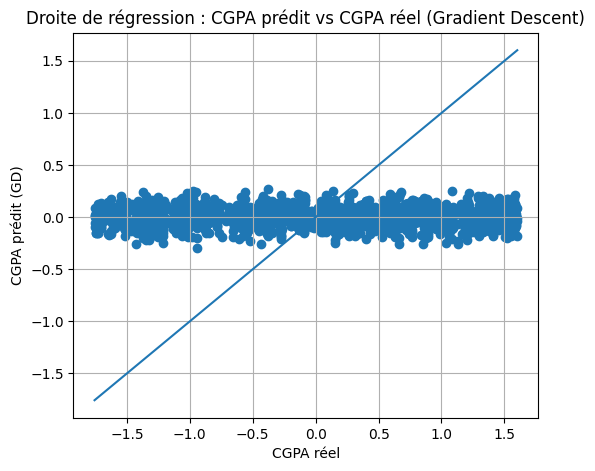

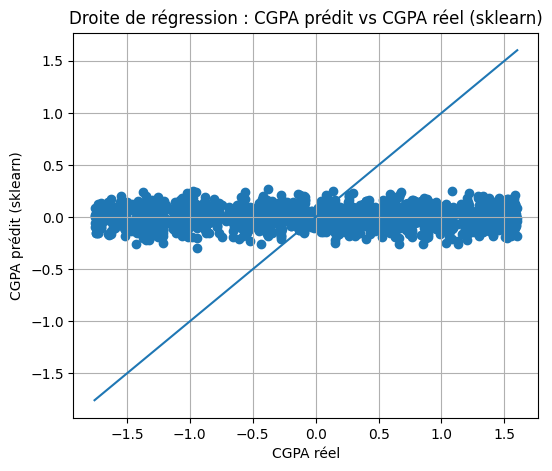

In [ ]:
plt.figure(figsize=(6, 5))

plt.scatter(y_test_vec, y_pred_test_gd)

line = np.linspace(y_test_vec.min(), y_test_vec.max(), 100)
plt.plot(line, line)

plt.xlabel("CGPA réel")
plt.ylabel("CGPA prédit (GD)")
plt.title("Droite de régression : CGPA prédit vs CGPA réel (Gradient Descent)")
plt.grid(True)
plt.show()

plt.figure(figsize=(6, 5))

plt.scatter(y_test_vec, y_pred_test_sk)

line = np.linspace(y_test_vec.min(), y_test_vec.max(), 100)
plt.plot(line, line)

plt.xlabel("CGPA réel")
plt.ylabel("CGPA prédit (sklearn)")
plt.title("Droite de régression : CGPA prédit vs CGPA réel (sklearn)")
plt.grid(True)
plt.show()


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15),
                0 2px 4px rgba(0,0,0,0.12),
                0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<!-- Purple corner -->
<div style="
    position: absolute; top: -30px; right: -30px;
    width: 120px; height: 120px;
    background: linear-gradient(135deg, transparent 60%, rgba(106,5,114,0.9) 95%);
    z-index: 1;">
</div>

<!-- Dot pattern -->
<div style="
    position: absolute; bottom: 20px; left: 20px;
    width: 60px; height: 60px;
    background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
    background-size: 12px 12px;
    opacity: 0.3; z-index: 1;">
</div>

<h2 style="
    margin-top: 0; margin-bottom: 12px; padding-bottom: 10px;
    font-size: 26px;
    color: rgba(106,5,114,0.85);
    border-bottom: 2px solid rgba(78,205,196,0.7);
    position: relative; z-index: 2;
    text-align: center;">
Linear Regression – Model Fit Interpretation
</h2>

<div style="
    position: relative; z-index: 2;
    font-size: 16px; color: #222;
    line-height: 1.6;
">

The points are highly scattered around an almost constant prediction level and remain far from the perfect regression line.<br><br>

• Neither gradient descent nor sklearn’s linear regression captures any meaningful relationship with CGPA.<br>
• Predictions stay nearly constant → <b>very low R²</b> and weak explanatory power.<br>
• Both implementations yield almost identical results, confirming that the issue lies in the data, not the algorithm.<br>

</div>

</div>
"""

display(HTML(html_content))


In [ ]:
model_results = [
    {
        "Modèle": "Linear Regression (Backward Elimination)",
        "PCA": "Non",
        "MSE": 0.90,
        "RMSE": np.sqrt(0.90),
        "R²": 0.00
    },
    {
        "Modèle": "Linear Regression (Gradient Descent)",
        "PCA": "Non",
        "MSE": 0.90,
        "RMSE": np.sqrt(0.90),
        "R²": 0.00
    },
    {
        "Modèle": "Linear Regression (Sklearn)",
        "PCA": "Non",
        "MSE": 0.90,
        "RMSE": np.sqrt(0.90),
        "R²": 0.00
    },
    {
        "Modèle": "KNN (Regular)",
        "PCA": "Oui",
        "MSE": 2.199772,
        "RMSE": np.sqrt(2.199772),
        "R²": -0.011428
    },
    {
        "Modèle": "KNN (GridSearch)",
        "PCA": "Oui",
        "MSE": 2.299297,
        "RMSE": np.sqrt(2.299297),
        "R²": -0.057188
    },
    {
        "Modèle": "KNN (RandomizedSearch)",
        "PCA": "Oui",
        "MSE": 2.204874,
        "RMSE": np.sqrt(2.204874),
        "R²": -0.013773
    },
    {
        "Modèle": "Random Forest",
        "PCA": "Non",
        "MSE": 2.224230,
        "RMSE": np.sqrt(2.224230),
        "R²": -0.022673
    },
    {
        "Modèle": "Random Forest (PCA PC1+PC2)",
        "PCA": "Oui",
        "MSE": 2.516048,
        "RMSE": np.sqrt(2.516048),
        "R²": -0.156847
    },
    {
        "Modèle": "Random Forest (PCA PC1+PC3)",
        "PCA": "Oui",
        "MSE": 2.531245,
        "RMSE": np.sqrt(2.531245),
        "R²": -0.163835
    },
    {
        "Modèle": "XGBoost (Sans PCA)",
        "PCA": "Non",
        "MSE": 2.20,
        "RMSE": np.sqrt(2.20),
        "R²": -0.01
    },
    {
        "Modèle": "XGBoost (Avec PCA)",
        "PCA": "Oui",
        "MSE": 2.20,
        "RMSE": np.sqrt(2.20),
        "R²": -0.01
    }
]

# Convert to DataFrame
df_comparison = pd.DataFrame(model_results)

# Round for readability
df_comparison = df_comparison.round({
    "MSE": 4, "RMSE": 4, "R²": 4
})

print("📊 Tableau comparatif des modèles OBJ3 :\n")
display(df_comparison)


📊 Tableau comparatif des modèles OBJ3 :



,Modèle,PCA,MSE,RMSE,R²
0,Linear Regression (Backward Elimination),Non,0.9000,0.9487,0.0000
1,Linear Regression (Gradient Descent),Non,0.9000,0.9487,0.0000
2,Linear Regression (Sklearn),Non,0.9000,0.9487,0.0000
3,KNN (Regular),Oui,2.1998,1.4832,-0.0114
4,KNN (GridSearch),Oui,2.2993,1.5163,-0.0572
5,KNN (RandomizedSearch),Oui,2.2049,1.4849,-0.0138
6,Random Forest,Non,2.2242,1.4914,-0.0227
7,Random Forest (PCA PC1+PC2),Oui,2.5160,1.5862,-0.1568
8,Random Forest (PCA PC1+PC3),Oui,2.5312,1.5910,-0.1638
9,XGBoost (Sans PCA),Non,2.2000,1.4832,-0.0100


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<style>
@keyframes float {
  0% { transform: translateY(0px); }
  50% { transform: translateY(-5px); }
  100% { transform: translateY(0px); }
}

@keyframes glow {
  0%,100% { box-shadow: 0 4px 10px rgba(106,5,114,0.25), inset 0 0 4px rgba(106,5,114,0.2); }
  50% { box-shadow: 0 8px 18px rgba(78,205,196,0.35), inset 0 0 6px rgba(78,205,196,0.25); }
}

@keyframes gradientShift {
  0% { background-position: 0% 50%; }
  50% { background-position: 100% 50%; }
  100% { background-position: 0% 50%; }
}
</style>

<div style="
    width: 95%;
    max-width: 900px;
    margin: 30px auto;
    background: linear-gradient(135deg, rgba(255,255,255,0.96), rgba(250,250,255,0.98));
    border-radius: 16px;
    border: 1px solid rgba(106,5,114,0.3);
    animation: float 5s ease-in-out infinite, glow 4s ease-in-out infinite;
    box-shadow: 0 6px 18px rgba(0,0,0,0.15);
    overflow: hidden;
    position: relative;
">

<!-- bande colorée animée -->
<div style="
    position: absolute;
    top: 0;
    left: 0;
    width: 100%;
    height: 6px;
    background: linear-gradient(90deg, #6a0572, #4ecdc4, #ffd166, #6a0572);
    background-size: 300% 300%;
    animation: gradientShift 8s ease infinite;
"></div>

<!-- décor bas droit -->
<div style="
    position: absolute;
    bottom: 0;
    right: 0;
    width: 120px;
    height: 120px;
    background: radial-gradient(circle at bottom right, rgba(106,5,114,0.3) 0%, transparent 70%);
    opacity: 0.4;
"></div>

<h2 style="
    font-family: 'Poppins', sans-serif;
    font-weight: 600;
    color: #6a0572;
    text-align: center;
    margin: 20px 0 10px 0;
    font-size: 30px;
    letter-spacing: 1px;
">
OBJ 4
</h2>

<hr style="
    width: 60%;
    margin: 0 auto 16px auto;
    border: none;
    height: 2px;
    background: linear-gradient(to right, rgba(106,5,114,0.6), rgba(78,205,196,0.6));
">

<p style="
    text-align: center;
    font-family: 'Open Sans', sans-serif;
    color: #333;
    font-size: 17px;
    line-height: 1.6;
    padding: 0 40px 20px 40px;
">

</div>
"""

display(HTML(html_content))


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15),
                0 2px 4px rgba(0,0,0,0.12),
                0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<!-- Purple corner -->
<div style="
    position: absolute; top: -30px; right: -30px;
    width: 120px; height: 120px;
    background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
    z-index: 1;">
</div>

<!-- Dot decoration -->
<div style="
    position: absolute; bottom: 20px; left: 20px;
    width: 60px; height: 60px;
    background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
    background-size: 12px 12px;
    opacity: 0.3; z-index: 1;">
</div>

<h2 style="
    margin-top: 0; margin-bottom: 12px; padding-bottom: 10px;
    font-size: 26px; color: rgba(106,5,114,0.85);
    border-bottom: 2px solid rgba(78,205,196,0.7);
    position: relative; z-index: 2; text-align: center;">
DSO4 – Objective
</h2>

<div style="
    position: relative; z-index: 2;
    font-size: 16px; color: #222; line-height: 1.6;
">
DSO4: Construct an unsupervised clustering model to segment students into homogeneous groups, then characterize each cluster by its dominant attributes for easier interpretation and targeted actions.
</div>

</div>
"""
display(HTML(html_content))


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15), 0 2px 4px rgba(0,0,0,0.12), 0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 12px;
        padding-bottom: 10px;
        font-size: 28px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
 K-MEANS</h2>
</div>
"""

display(HTML(html_content))


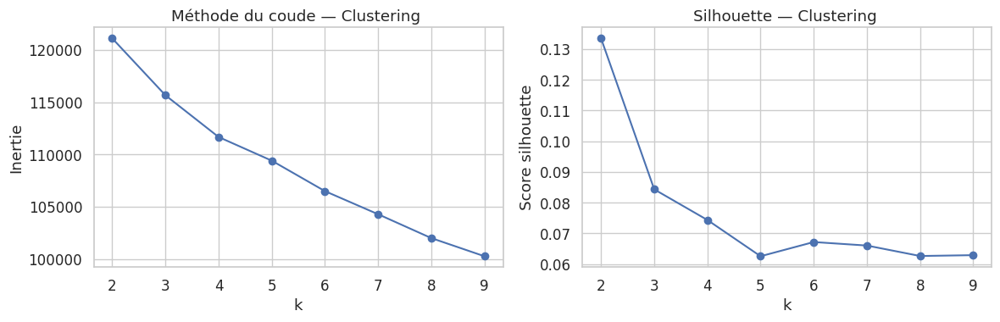

→ k optimal = 2 | silhouette score without pca = 0.133


In [ ]:
sns.set(style="whitegrid", font_scale=1.1)

k_range = range(2, 10)
inertia, sil = [], []

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42)
    labels_k = km.fit_predict(df_scaled)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(df_scaled, labels_k))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].plot(k_range, inertia, "o-")
ax[0].set_title("Méthode du coude — Clustering ")
ax[0].set_xlabel("k")
ax[0].set_ylabel("Inertie")

ax[1].plot(k_range, sil, "o-")
ax[1].set_title("Silhouette — Clustering ")
ax[1].set_xlabel("k")
ax[1].set_ylabel("Score silhouette")

plt.tight_layout()
plt.show()

best_k = list(k_range)[np.argmax(sil)]
print(f"→ k optimal = {best_k} | silhouette score without pca = {max(sil):.3f}")


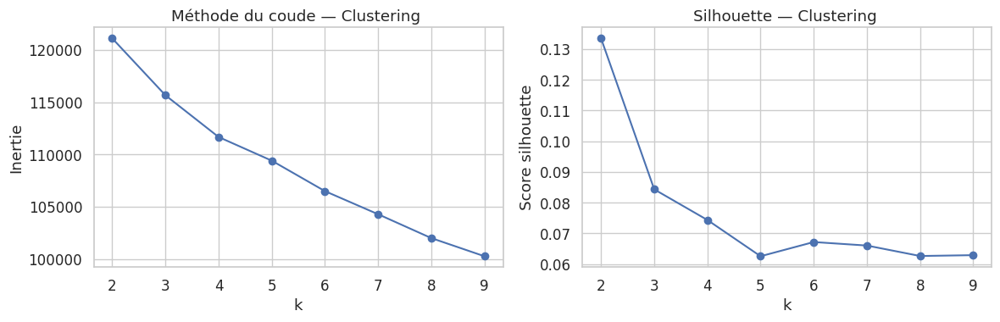

→ k optimal = 2 | silhouette score with pca = 0.133


In [ ]:
sns.set(style="whitegrid", font_scale=1.1)

k_range = range(2, 10)
inertia, sil = [], []

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42)
    labels_k = km.fit_predict(X_pca_transformed)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(X_pca_transformed, labels_k))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].plot(k_range, inertia, "o-")
ax[0].set_title("Méthode du coude — Clustering ")
ax[0].set_xlabel("k")
ax[0].set_ylabel("Inertie")

ax[1].plot(k_range, sil, "o-")
ax[1].set_title("Silhouette — Clustering ")
ax[1].set_xlabel("k")
ax[1].set_ylabel("Score silhouette")

plt.tight_layout()
plt.show()

best_k = list(k_range)[np.argmax(sil)]
print(f"→ k optimal = {best_k} | silhouette score with pca = {max(sil):.3f}")


In [ ]:
kmeans = KMeans(n_clusters=best_k, random_state=42)
labels = kmeans.fit_predict(df_scaled)

df_result = df_scaled.copy()
df_result["Cluster"] = labels



Profils des clusters :
           Gender       Age      City  Academic Pressure      CGPA  \
Cluster                                                              
0        0.001139  0.286295  0.048271          -0.600354 -0.038177   
1       -0.000831 -0.208905 -0.035222           0.438068  0.027857   

         Study Satisfaction  Sleep Duration  Dietary Habits    Degree  \
Cluster                                                                 
0                  0.207077        0.090481       -0.249859  0.015977   
1                 -0.151101       -0.066022        0.182318 -0.011658   

         Have you ever had suicidal thoughts ?  Work/Study Hours  \
Cluster                                                            
0                                    -0.697029         -0.262579   
1                                     0.508610          0.191599   

         Financial Stress  Family History of Mental Illness  Depression  
Cluster                                                

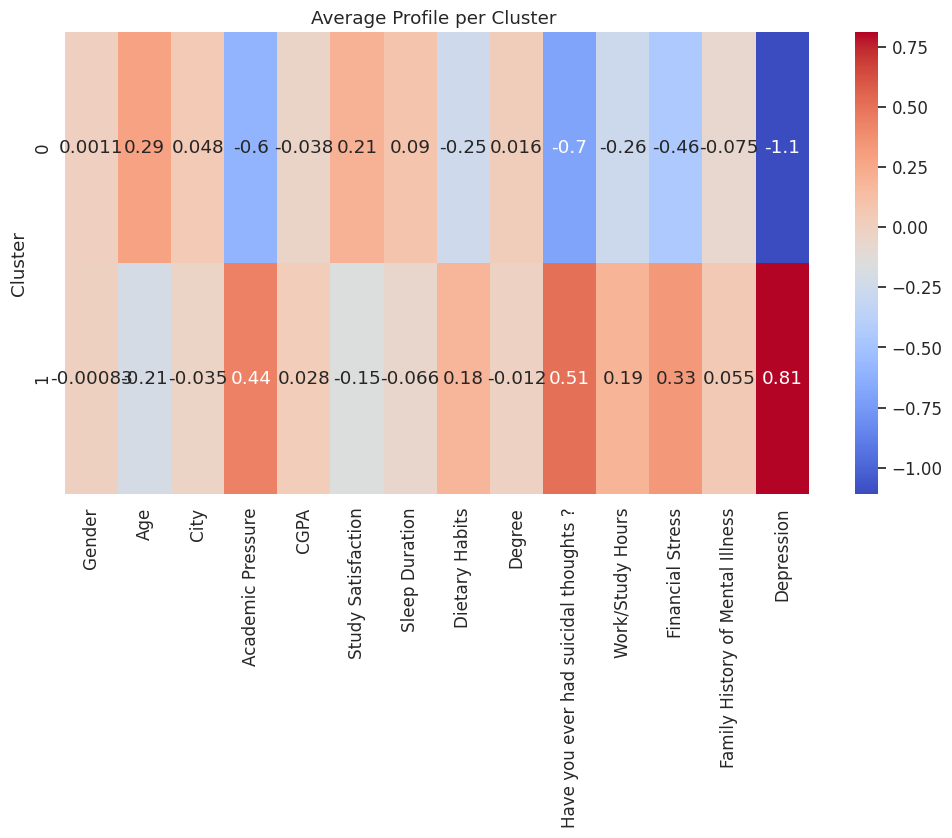

In [ ]:
FEATURES = df_num.columns.tolist()
profiles = df_result.groupby("Cluster")[FEATURES].mean()
print("\nProfils des clusters :")
print(profiles)

plt.figure(figsize=(12, 6))
sns.heatmap(profiles, annot=True, cmap="coolwarm")
plt.title("Average Profile per Cluster ")
plt.show()


In [ ]:
profiles = df_result.groupby("Cluster")[FEATURES].mean()

NegativeFactors = [ "Depression","Financial Stress","Academic Pressure","Have you ever had suicidal thoughts ?"]
PositiveFactors = ["Study Satisfaction","Sleep Duration","Dietary Habits"]

wellbeing_score = (profiles[PositiveFactors].sum(axis=1) - profiles[NegativeFactors].sum(axis=1))

print("\n Well-being score per cluster :")
print(wellbeing_score)

sorted_clusters = wellbeing_score.sort_values(ascending=False).index.tolist()

cluster_mapping = {
    sorted_clusters[0]: "High well-being",
    sorted_clusters[1]: "Low well-being"
}

print("\nCluster mapping:", cluster_mapping)



 Well-being score per cluster :
Cluster
0    2.910709
1   -2.123894
dtype: float64

Cluster mapping: {0: 'High well-being', 1: 'Low well-being'}


In [ ]:
df_result["WellBeingGroup"] = df_result["Cluster"].map(cluster_mapping)

In [ ]:
df_result.head(60)

,Gender,Age,City,Academic Pressure,CGPA,Study Satisfaction,Sleep Duration,Dietary Habits,Degree,Have you ever had suicidal thoughts ?,Work/Study Hours,Financial Stress,Family History of Mental Illness,Depression,Cluster,WellBeingGroup
0,1.121771,-0.991786,1.633943,1.329747,0.741823,0.050666,0.576616,1.248814,1.409438,0.763996,-1.923880,1.302365,1.038613,0.855619,1,Low well-being
1,1.121771,0.229407,0.428740,-1.559573,0.407294,0.050666,-1.135736,1.248814,0.851471,0.763996,0.772805,0.607947,-0.962822,0.855619,1,Low well-being
2,-0.891447,1.654132,0.100048,-0.114913,1.410881,-0.684432,0.576616,-0.361113,0.293503,0.763996,1.042473,-1.475309,1.038613,0.855619,1,Low well-being
3,-0.891447,0.432939,0.319176,0.607417,0.741823,-1.419529,-1.135736,-1.166076,-1.380399,0.763996,-1.114875,0.607947,-0.962822,0.855619,1,Low well-being
4,1.121771,1.043535,-0.447772,-1.559573,0.816921,1.520861,-0.564952,-0.361113,0.711979,0.763996,1.312142,-0.780890,-0.962822,-1.168744,0,High well-being
5,1.121771,1.450600,-1.214720,-1.559573,-1.429203,0.785764,1.432792,1.248814,1.827914,-1.308907,-1.923880,-0.086472,1.038613,-1.168744,0,High well-being
6,-0.891447,0.840003,0.976560,1.329747,-0.295900,-0.684432,1.432792,1.248814,1.548930,0.763996,1.312142,-0.086472,-0.962822,0.855619,1,Low well-being
7,1.121771,-1.602382,0.100048,1.329747,-1.224389,-0.684432,-1.135736,-1.166076,0.014519,0.763996,0.233468,1.302365,-0.962822,0.855619,1,Low well-being
8,1.121771,1.043535,0.428740,-0.837243,-1.360932,0.785764,1.432792,-0.361113,-1.101416,-1.308907,0.772805,0.607947,-0.962822,-1.168744,0,High well-being
9,1.121771,-0.584722,1.524379,-1.559573,1.287993,-1.419529,0.576616,1.248814,-1.380399,0.763996,0.772805,1.302365,1.038613,0.855619,1,Low well-being


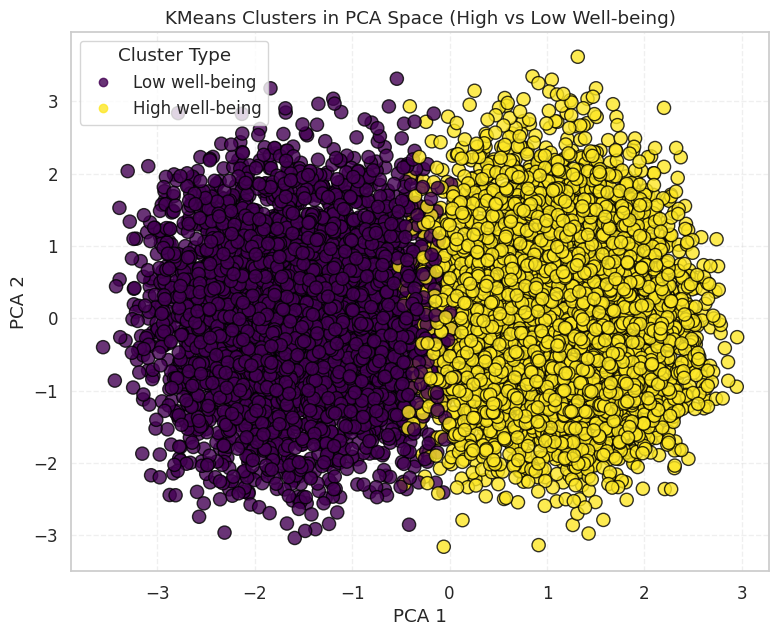

In [ ]:
plt.figure(figsize=(9,7))

scatter = plt.scatter(
    X_pca_transformed[:, 0],
    X_pca_transformed[:, 1],
    c=df_result["Cluster"],
    cmap="viridis",
    s=90,
    alpha=0.8,
    edgecolor="black"
)
unique_labels = df_result["WellBeingGroup"].unique()
handles, _ = scatter.legend_elements()

plt.legend(handles, unique_labels, title="Cluster Type", fontsize=12)

plt.xlabel("PCA 1")
plt.ylabel("PCA 2")
plt.title("KMeans Clusters in PCA Space (High vs Low Well-being)")
plt.grid(True, linestyle="--", alpha=0.3)
plt.show()


In [ ]:
final_sil_score = silhouette_score(df_scaled, labels)
print(f"\n silhouette score without pca = {final_sil_score:.3f}")
final_sil_score1 = silhouette_score(X_pca_transformed, labels)
print(f"\n silhouette score with pca = {final_sil_score1:.3f}")


 silhouette score without pca = 0.133

 silhouette score with pca = 0.133


In [ ]:
selected_features = [
    "Depression",
    "Financial Stress",
    "Academic Pressure",
    "Have you ever had suicidal thoughts ?",
    "Study Satisfaction",
    "Sleep Duration",
    "Dietary Habits"
]

student_matrix = df_result[selected_features].values

print("Student matrix shape:", student_matrix.shape)

Student matrix shape: (9982, 7)



Target student index: 55

Similarity of target student with all others:
[-0.11678455 -0.50584747  0.27042131 ... -0.08457075  0.4679902
  0.19745608]


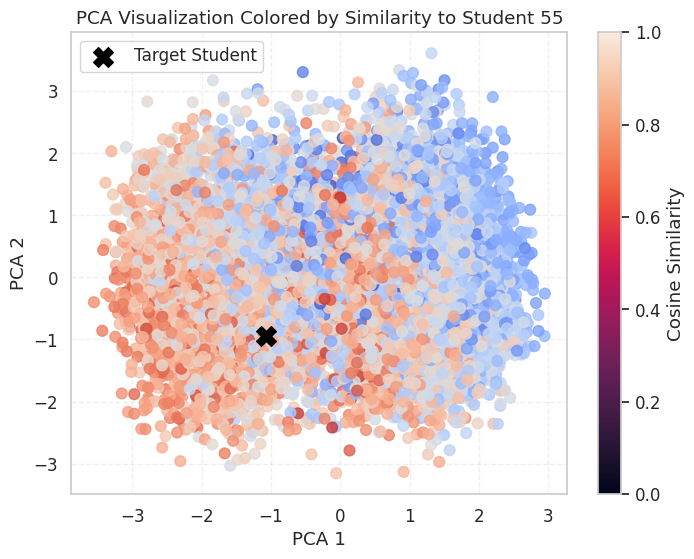

In [ ]:
target_student = 55

print("\nTarget student index:", target_student)

from sklearn.metrics.pairwise import cosine_similarity

sim_vector = cosine_similarity(student_matrix, student_matrix)[target_student]

sim_vector[target_student] = -1

print("\nSimilarity of target student with all others:")
print(sim_vector)

plt.figure(figsize=(8,6))

plt.scatter(
    X_pca_transformed[:,0],
    X_pca_transformed[:,1],
    c=sim_vector,
    cmap="coolwarm",
    s=60,
    alpha=0.8
)

plt.scatter(
    X_pca_transformed[target_student,0],
    X_pca_transformed[target_student,1],
    c="black",
    s=200,
    marker="X",
    label="Target Student"
)

plt.colorbar(label="Cosine Similarity")
plt.title(f"PCA Visualization Colored by Similarity to Student {target_student}")
plt.xlabel("PCA 1")
plt.ylabel("PCA 2")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.3)
plt.show()




Most similar students to target:
[ 170 4720 3974 4226 7173]

Their similarity scores:
[0.97342461 0.94665371 0.94419971 0.94325326 0.94111703]


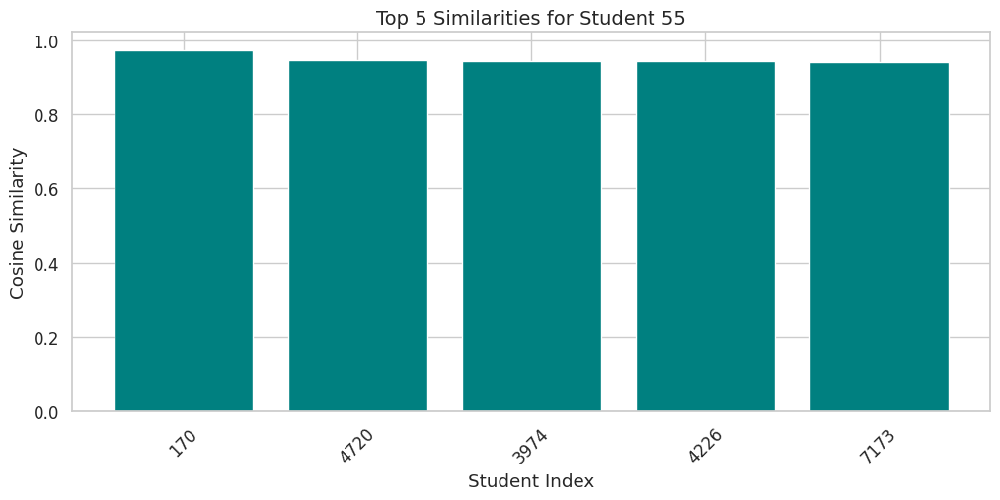

In [ ]:
top_k = 5
neighbors_idx = sim_vector.argsort()[-top_k:][::-1]

print("\nMost similar students to target:")
print(neighbors_idx)

print("\nTheir similarity scores:")
print(sim_vector[neighbors_idx])

sorted_idx = np.argsort(sim_vector)[::-1]

plt.figure(figsize=(12, 5))
plt.bar(range(5), sim_vector[sorted_idx][:5], color="teal")
plt.xticks(range(5), sorted_idx[:5], rotation=45)
plt.title(f"Top 5 Similarities for Student {target_student}", fontsize=14)
plt.ylabel("Cosine Similarity")
plt.xlabel("Student Index")
plt.show()

In [ ]:
neighbor_groups = df_result.loc[neighbors_idx, "WellBeingGroup"].values

print("\nNeighbor well-being groups:")
print(neighbor_groups)


Neighbor well-being groups:
['Low well-being' 'Low well-being' 'High well-being' 'High well-being'
 'High well-being']


In [ ]:
recommendations = []

count_low = list(neighbor_groups).count("Low well-being")
count_high = list(neighbor_groups).count("High well-being")

recommendation_score = max(count_low, count_high) / top_k

print("\nRecommendation Score:", round(recommendation_score, 3))


print("\nCount of neighbor types:")
print("Low-WB neighbors :", count_low)
print("High-WB neighbors:", count_high)

if count_low > count_high:
    dominant_group = "Low well-being"
    recommendations.append(" Your well-being profile is similar to students who may be experiencing psychological or academic difficulties.")
    recommendations.append("• Schedule a confidential consultation with the university counseling service to discuss stress, anxiety, or burnout signs.")
    recommendations.append("• Participate in guided stress-reduction programs (mindfulness, breathing exercises, time-management sessions).")
    recommendations.append("• Evaluate and adjust study habits: implement regular breaks, realistic workloads, and structured planning.")
    recommendations.append("• Improve sleep hygiene: stable bedtime routine, reduced screen usage at night, avoid late caffeine.")
    recommendations.append("• Strengthen social support: engage with peers, support groups, or student communities to reduce isolation.")
    recommendations.append("• Monitor academic pressure and seek academic advising to redistribute workload or adjust expectations.")
    recommendations.append("• Adopt healthier routines: balanced meals, hydration, physical activity (walking, sport, stretching).")
else:
    dominant_group = "High well-being"
    recommendations.append("✨ Your profile matches students who generally maintain strong emotional and academic well-being.")
    recommendations.append("• Continue practicing effective study habits: planning, active learning, and maintaining a healthy balance between work and rest.")
    recommendations.append("• Maintain good sleep and lifestyle routines to support long-term productivity and resilience.")
    recommendations.append("• Engage in enriching activities (clubs, student associations, sports, volunteering) to strengthen social and emotional skills.")
    recommendations.append("• Consider peer-mentoring or leadership roles to positively contribute to the student community.")
    recommendations.append("• Attend optional workshops for personal development (communication, stress management, time management).")
    recommendations.append("• Keep monitoring your well-being; maintaining healthy habits consistently is key to long-term success.")


print("\nDominant neighbor group:", dominant_group)

print("\n RECOMMENDATION FOR STUDENT :", target_student)
for r in recommendations:
    print(r)


Recommendation Score: 0.6

Count of neighbor types:
Low-WB neighbors : 2
High-WB neighbors: 3

Dominant neighbor group: High well-being

 RECOMMENDATION FOR STUDENT : 55
✨ Your profile matches students who generally maintain strong emotional and academic well-being.
• Continue practicing effective study habits: planning, active learning, and maintaining a healthy balance between work and rest.
• Maintain good sleep and lifestyle routines to support long-term productivity and resilience.
• Engage in enriching activities (clubs, student associations, sports, volunteering) to strengthen social and emotional skills.
• Consider peer-mentoring or leadership roles to positively contribute to the student community.
• Attend optional workshops for personal development (communication, stress management, time management).
• Keep monitoring your well-being; maintaining healthy habits consistently is key to long-term success.


In [ ]:
import pickle
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

selected_features = [
    "Depression",
    "Financial Stress",
    "Academic Pressure",
    "Have you ever had suicidal thoughts ?",
    "Study Satisfaction",
    "Sleep Duration",
    "Dietary Habits"
]

X = df[selected_features]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

kmeans = KMeans(n_clusters=2, random_state=42)
kmeans.fit(X_scaled)


with open("scaler.pkl", "wb") as f:
    pickle.dump(scaler, f)

with open("model.pkl", "wb") as f:
    pickle.dump(kmeans, f)

print(" Model and scaler retrained with 7 features only")
print("Scaler expects:", scaler.n_features_in_)


metadata = {
  "features": [
    "Depression",
    "Financial Stress",
    "Academic Pressure",
    "Have you ever had suicidal thoughts ?",
    "Study Satisfaction",
    "Sleep Duration",
    "Dietary Habits"
  ],
  "input_aliases": {
    "depression": "Depression",
    "financial_stress": "Financial Stress",
    "academic_pressure": "Academic Pressure",
    "suicidal_thoughts": "Have you ever had suicidal thoughts ?",
    "study_satisfaction": "Study Satisfaction",
    "sleep_duration": "Sleep Duration",
    "dietary_habits": "Dietary Habits"
  },
  "cluster_to_group": {
    "0": "High well-being",
    "1": "Low well-being"
  },
  "recommendations": {
    "Low well-being": [
      "Your well-being profile is similar to students who may be experiencing psychological or academic difficulties.",
      "Schedule a confidential consultation with the university counseling service to discuss stress, anxiety, or burnout signs.",
      "Participate in guided stress-reduction programs (mindfulness, breathing exercises, time-management sessions).",
      "Evaluate and adjust study habits: implement regular breaks, realistic workloads, and structured planning.",
      "Improve sleep hygiene: stable bedtime routine, reduced screen usage at night, avoid late caffeine.",
      "Strengthen social support: engage with peers, support groups, or student communities to reduce isolation.",
      "Monitor academic pressure and seek academic advising to redistribute workload or adjust expectations.",
      "Adopt healthier routines: balanced meals, hydration, physical activity (walking, sport, stretching)."
    ],
    "High well-being": [
      "Your profile matches students who generally maintain strong emotional and academic well-being.",
      "Continue practicing effective study habits: planning, active learning, and maintaining a healthy balance between work and rest.",
      "Maintain good sleep and lifestyle routines to support long-term productivity and resilience.",
      "Engage in enriching activities (clubs, student associations, sports, volunteering) to strengthen social and emotional skills.",
      "Consider peer-mentoring or leadership roles to positively contribute to the student community.",
      "Attend optional workshops for personal development (communication, stress management, time management).",
      "Keep monitoring your well-being; maintaining healthy habits consistently is key to long-term success."
    ]
  }
}
with open("metadata.json", "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=2)


 Model and scaler retrained with 7 features only
Scaler expects: 7


In [ ]:
from google.colab import files

files.download("model.pkl")
files.download("scaler.pkl")
files.download("metadata.json")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15), 0 2px 4px rgba(0,0,0,0.12), 0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 12px;
        padding-bottom: 10px;
        font-size: 28px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
CAH</h2>
</div>
"""

display(HTML(html_content))


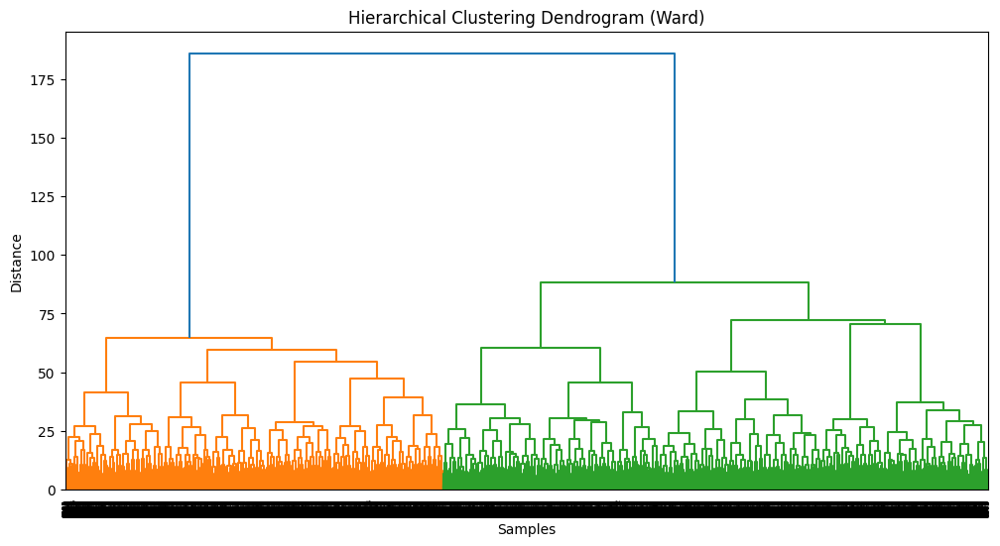

In [ ]:
plt.figure(figsize=(12, 6))
Z = linkage(df_scaled, method="ward")
dendrogram(Z)
plt.title("Hierarchical Clustering Dendrogram (Ward)")
plt.xlabel("Samples")
plt.ylabel("Distance")
plt.show()


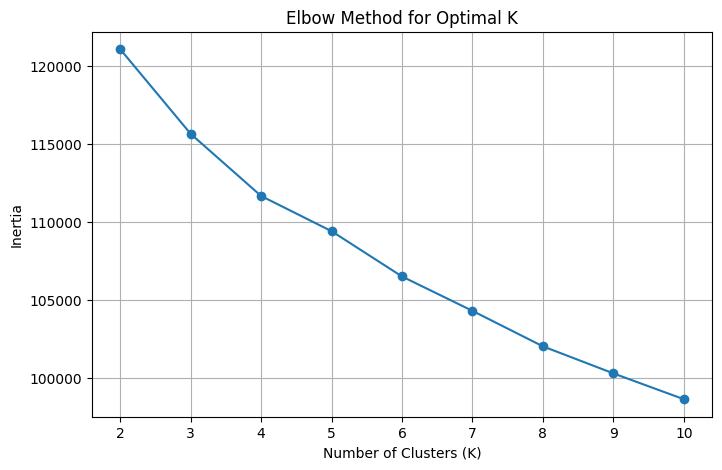

In [ ]:
from sklearn.cluster import KMeans

inertias = []
K_range = range(2, 11)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(df_scaled)
    inertias.append(kmeans.inertia_)

plt.figure(figsize=(8,5))
plt.plot(K_range, inertias, marker='o')
plt.title("Elbow Method for Optimal K")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.grid(True)
plt.show()


K=2 → Silhouette=0.1251
K=3 → Silhouette=0.0663
K=4 → Silhouette=0.0589
K=5 → Silhouette=0.0512
K=6 → Silhouette=0.0388
K=7 → Silhouette=0.0395
K=8 → Silhouette=0.0406
K=9 → Silhouette=0.0425
K=10 → Silhouette=0.0362


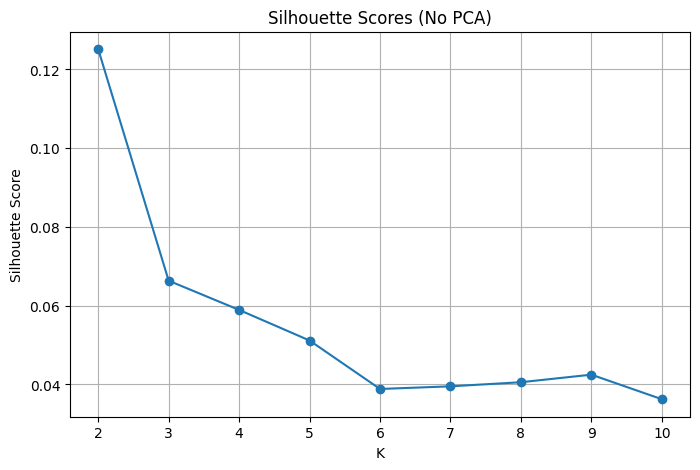

In [ ]:
from sklearn.cluster import AgglomerativeClustering

sil_scores_no_pca = []

for k in K_range:
    cah = AgglomerativeClustering(n_clusters=k, linkage="ward")
    labels = cah.fit_predict(df_scaled)
    sil = silhouette_score(df_scaled, labels)
    sil_scores_no_pca.append(sil)
    print(f"K={k} → Silhouette={sil:.4f}")

plt.figure(figsize=(8,5))
plt.plot(K_range, sil_scores_no_pca, marker='o')
plt.title("Silhouette Scores (No PCA)")
plt.xlabel("K")
plt.ylabel("Silhouette Score")
plt.grid(True)
plt.show()


[PCA] K=2 → Silhouette=0.1251
[PCA] K=3 → Silhouette=0.0663
[PCA] K=4 → Silhouette=0.0589
[PCA] K=5 → Silhouette=0.0512
[PCA] K=6 → Silhouette=0.0388
[PCA] K=7 → Silhouette=0.0395
[PCA] K=8 → Silhouette=0.0406
[PCA] K=9 → Silhouette=0.0425
[PCA] K=10 → Silhouette=0.0362


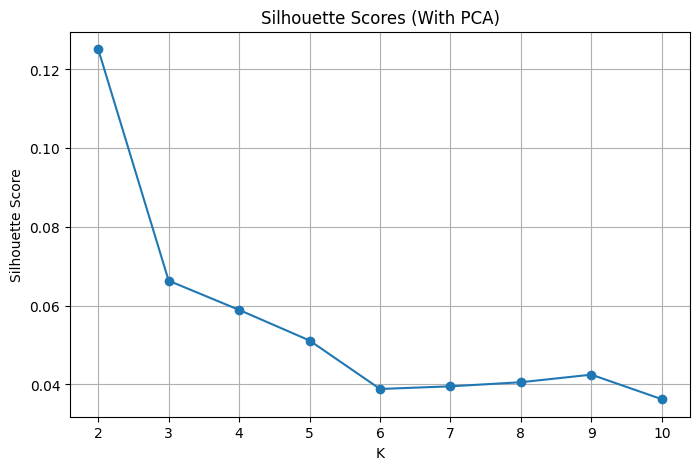

In [ ]:
sil_scores_pca = []

for k in K_range:
    cah = AgglomerativeClustering(n_clusters=k, linkage="ward")
    labels = cah.fit_predict(X_pca_transformed)
    sil = silhouette_score(X_pca_transformed, labels)
    sil_scores_pca.append(sil)
    print(f"[PCA] K={k} → Silhouette={sil:.4f}")

plt.figure(figsize=(8,5))
plt.plot(K_range, sil_scores_pca, marker='o')
plt.title("Silhouette Scores (With PCA)")
plt.xlabel("K")
plt.ylabel("Silhouette Score")
plt.grid(True)
plt.show()


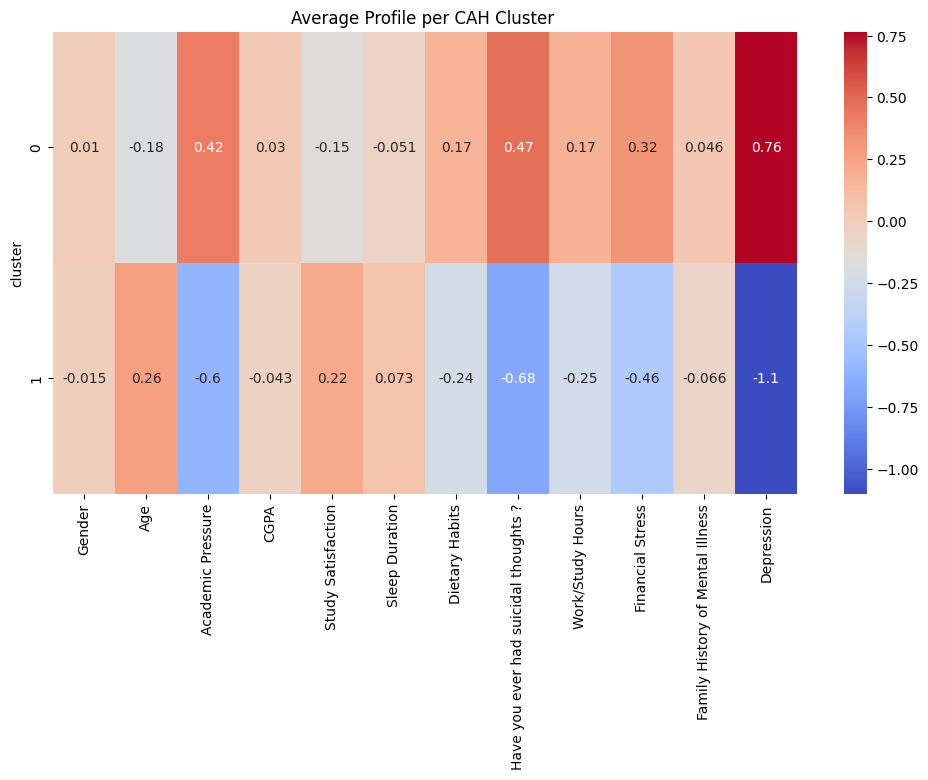

           Gender       Age  Academic Pressure      CGPA  Study Satisfaction  \
cluster                                                                        
0        0.010076 -0.183254           0.417853  0.029706           -0.153355   
1       -0.014509  0.263885          -0.601704 -0.042776            0.220829   

         Sleep Duration  Dietary Habits  \
cluster                                   
0             -0.050800        0.166739   
1              0.073152       -0.240102   

         Have you ever had suicidal thoughts ?  Work/Study Hours  \
cluster                                                            
0                                     0.471939          0.174554   
1                                    -0.679587         -0.251355   

         Financial Stress  Family History of Mental Illness  Depression  
cluster                                                                  
0                0.316199                          0.045540    0.764899  
1          

In [ ]:
final_cah = AgglomerativeClustering(n_clusters=best_k, linkage="ward")
labels_cah = final_cah.fit_predict(df_scaled)

df_cah = pd.DataFrame(df_scaled, columns=df.select_dtypes(include="number").columns)
df_cah["cluster"] = labels_cah

cluster_profiles = df_cah.groupby("cluster").mean()

plt.figure(figsize=(12,6))
sns.heatmap(cluster_profiles, annot=True, cmap="coolwarm")
plt.title("Average Profile per CAH Cluster ")
plt.show()

print(cluster_profiles)

In [ ]:
NEG = ["Depression", "Financial Stress", "Academic Pressure", "Have you ever had suicidal thoughts ?"]
POS = ["Study Satisfaction", "Sleep Duration", "Dietary Habits"]

wellbeing_score = (
    - cluster_profiles[NEG].sum(axis=1)
    + cluster_profiles[POS].sum(axis=1)
)

print("\nWell-being score per cluster:")
print(wellbeing_score)


Well-being score per cluster:
cluster
0   -2.008306
1    2.891941
dtype: float64


In [ ]:
sorted_clusters = wellbeing_score.sort_values(ascending=False).index.tolist()

cah_mapping = {
    sorted_clusters[0]: "Low well-being",
    sorted_clusters[-1]: "High well-being"
}

df_cah["WellBeingGroup"] = df_cah["cluster"].map(cah_mapping)

print("\nCluster mapping:", cah_mapping)



Cluster mapping: {1: 'Low well-being', 0: 'High well-being'}


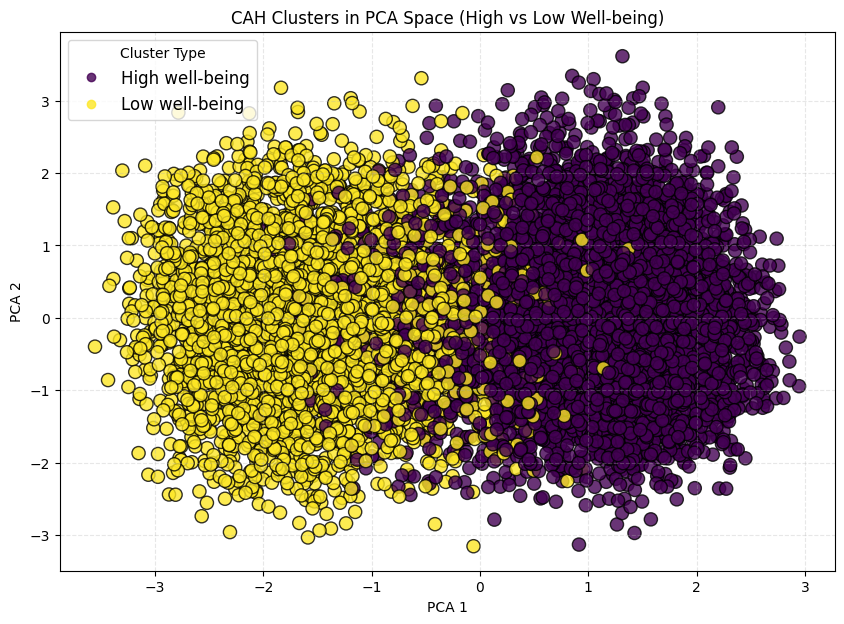

In [ ]:
plt.figure(figsize=(10,7))

scatter = plt.scatter(
    X_pca_transformed[:, 0],
    X_pca_transformed[:, 1],
    c=df_cah["cluster"],
    cmap="viridis",
    s=90,
    alpha=0.8,
    edgecolor="black"
)

handles, _ = scatter.legend_elements()
plt.legend(handles, df_cah["WellBeingGroup"].unique(), title="Cluster Type", fontsize=12)

plt.title("CAH Clusters in PCA Space (High vs Low Well-being)")
plt.xlabel("PCA 1")
plt.ylabel("PCA 2")
plt.grid(True, linestyle="--", alpha=0.3)
plt.show()


In [ ]:
df_cah.head(60)

,Gender,Age,Academic Pressure,CGPA,Study Satisfaction,Sleep Duration,Dietary Habits,Have you ever had suicidal thoughts ?,Work/Study Hours,Financial Stress,Family History of Mental Illness,Depression,cluster,WellBeingGroup
0,1.121771,-0.991786,1.329747,0.741823,0.050666,0.576616,1.248814,0.763996,-1.923880,1.302365,1.038613,0.855619,0,High well-being
1,1.121771,0.229407,-1.559573,0.407294,0.050666,-1.135736,1.248814,0.763996,0.772805,0.607947,-0.962822,0.855619,0,High well-being
2,-0.891447,1.654132,-0.114913,1.410881,-0.684432,0.576616,-0.361113,0.763996,1.042473,-1.475309,1.038613,0.855619,0,High well-being
3,-0.891447,0.432939,0.607417,0.741823,-1.419529,-1.135736,-1.166076,0.763996,-1.114875,0.607947,-0.962822,0.855619,0,High well-being
4,1.121771,1.043535,-1.559573,0.816921,1.520861,-0.564952,-0.361113,0.763996,1.312142,-0.780890,-0.962822,-1.168744,1,Low well-being
5,1.121771,1.450600,-1.559573,-1.429203,0.785764,1.432792,1.248814,-1.308907,-1.923880,-0.086472,1.038613,-1.168744,1,Low well-being
6,-0.891447,0.840003,1.329747,-0.295900,-0.684432,1.432792,1.248814,0.763996,1.312142,-0.086472,-0.962822,0.855619,0,High well-being
7,1.121771,-1.602382,1.329747,-1.224389,-0.684432,-1.135736,-1.166076,0.763996,0.233468,1.302365,-0.962822,0.855619,0,High well-being
8,1.121771,1.043535,-0.837243,-1.360932,0.785764,1.432792,-0.361113,-1.308907,0.772805,0.607947,-0.962822,-1.168744,1,Low well-being
9,1.121771,-0.584722,-1.559573,1.287993,-1.419529,0.576616,1.248814,0.763996,0.772805,1.302365,1.038613,0.855619,0,High well-being


In [ ]:
# @title
from IPython.display import display, HTML

html_content = """
<div style="
    background: linear-gradient(to bottom right, rgba(255,255,255,0.97), rgba(248,250,252,0.97));
    border: 1px solid #333;
    border-radius: 12px;
    box-shadow: 0 6px 16px rgba(0,0,0,0.15), 0 2px 4px rgba(0,0,0,0.12), 0 0 0 1px rgba(255,255,255,0.9) inset;
    padding: 24px;
    margin: 20px 0;
    font-family: 'Arial', sans-serif;
    position: relative;
    overflow: hidden;
">

<div style="
        position: absolute;
        top: -30px;
        right: -30px;
        width: 120px;
        height: 120px;
        background: linear-gradient(135deg, transparent 65%, rgba(106,5,114,0.9) 95%);
        z-index: 1;
    "></div>

<div style="
        position: absolute;
        bottom: 20px;
        left: 20px;
        width: 60px;
        height: 60px;
        background-image: radial-gradient(circle, #FFD166 2px, transparent 2px);
        background-size: 12px 12px;
        opacity: 0.3;
        z-index: 1;
    "></div>

<h2 style="
        margin-top: 0;
        margin-bottom: 12px;
        padding-bottom: 10px;
        font-size: 28px;
        color: rgba(106,5,114,0.85);
        border-bottom: 2px solid rgba(78,205,196,0.7);
        position: relative;
        z-index: 2;
        text-align: center;
    ">
DBSCAN</h2>
</div>
"""

display(HTML(html_content))


In [ ]:
n_features = df_scaled.shape[1]

min_samples = n_features + 1
print("MinPts (min_samples) =", min_samples)

MinPts (min_samples) = 15


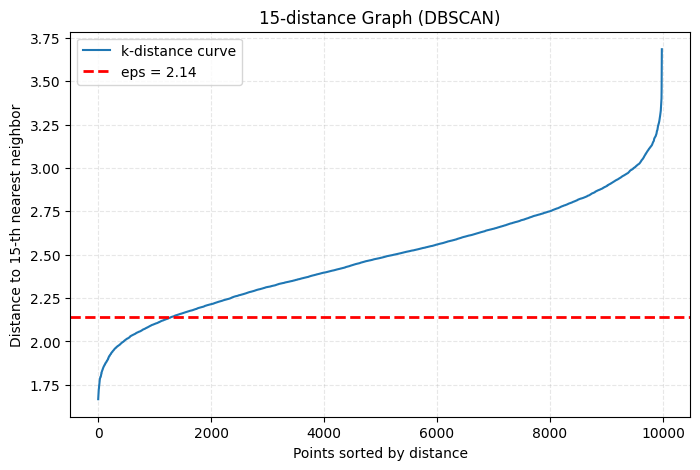

In [ ]:
plt.figure(figsize=(8,5))
plt.plot(k_distances, label="k-distance curve")

plt.axhline(y=2.14, color='red', linestyle='--', linewidth=2, label="eps = 2.14")

plt.title(f"{min_samples}-distance Graph (DBSCAN)")
plt.xlabel("Points sorted by distance")
plt.ylabel(f"Distance to {min_samples}-th nearest neighbor")
plt.grid(True, linestyle='--', alpha=0.3)
plt.legend()
plt.show()


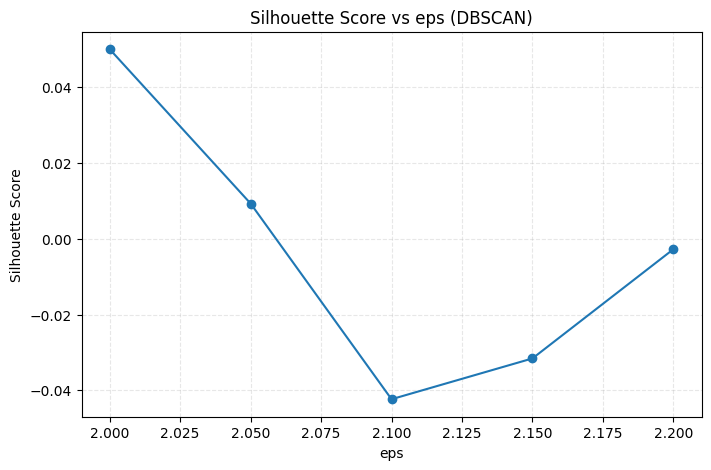

In [ ]:
plt.figure(figsize=(8,5))
plt.plot(eps_candidates, sil_scores, marker='o')
plt.title("Silhouette Score vs eps (DBSCAN)")
plt.xlabel("eps")
plt.ylabel("Silhouette Score")
plt.grid(True, linestyle='--', alpha=0.3)
plt.show()


=== DBSCAN on df_scaled (no PCA) ===
eps=2.0 → silhouette=0.0500, clusters={np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)}
eps=2.1 → silhouette=-0.0423, clusters={np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10)}
eps=2.2 → silhouette=-0.0028, clusters={np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15)}
eps=2.25 → silhouette=-0.0234, clusters={np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10)}


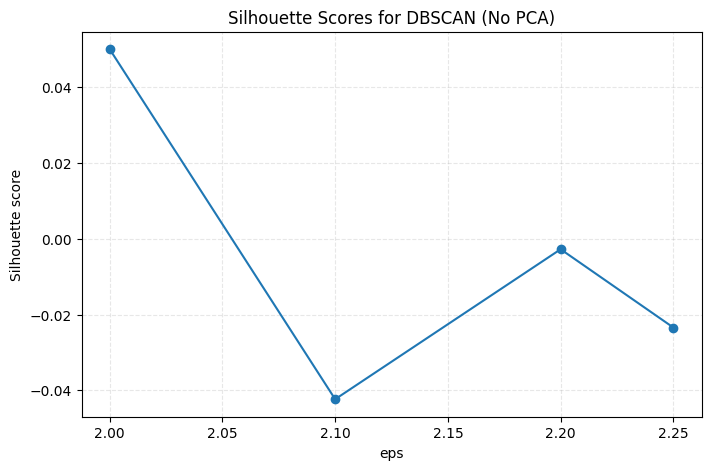


Best eps (no PCA) = 2.0 | silhouette = 0.049981856737995864


In [ ]:
eps_candidates = [2.0, 2.1, 2.2, 2.25]

sil_scores_no_pca = []
best_eps_no_pca = None
best_sil_no_pca = -1

print("=== DBSCAN on df_scaled (no PCA) ===")
for eps in eps_candidates:
    dbscan = DBSCAN(eps=eps, min_samples=min_samples)
    labels = dbscan.fit_predict(df_scaled)

    unique_labels = set(labels)
    clusters_only = unique_labels - {-1}  # remove noise

    if len(clusters_only) < 2:
        print(f"eps={eps} → not enough clusters (labels={unique_labels})")
        sil_scores_no_pca.append(np.nan)
        continue

    mask = labels != -1
    sil = silhouette_score(df_scaled[mask], labels[mask])
    sil_scores_no_pca.append(sil)

    print(f"eps={eps} → silhouette={sil:.4f}, clusters={clusters_only}")

    if sil > best_sil_no_pca:
        best_sil_no_pca = sil
        best_eps_no_pca = eps

plt.figure(figsize=(8,5))
plt.plot(eps_candidates, sil_scores_no_pca, marker='o')
plt.title("Silhouette Scores for DBSCAN (No PCA)")
plt.xlabel("eps")
plt.ylabel("Silhouette score")
plt.grid(True, linestyle='--', alpha=0.3)
plt.show()

print("\nBest eps (no PCA) =", best_eps_no_pca, "| silhouette =", best_sil_no_pca)


=== DBSCAN on X_pca_transformed (with PCA) ===
[PCA] eps=2.0 → silhouette=0.0500, clusters={np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)}
[PCA] eps=2.1 → silhouette=-0.0423, clusters={np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10)}
[PCA] eps=2.2 → silhouette=-0.0028, clusters={np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15)}
[PCA] eps=2.25 → silhouette=-0.0234, clusters={np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10)}


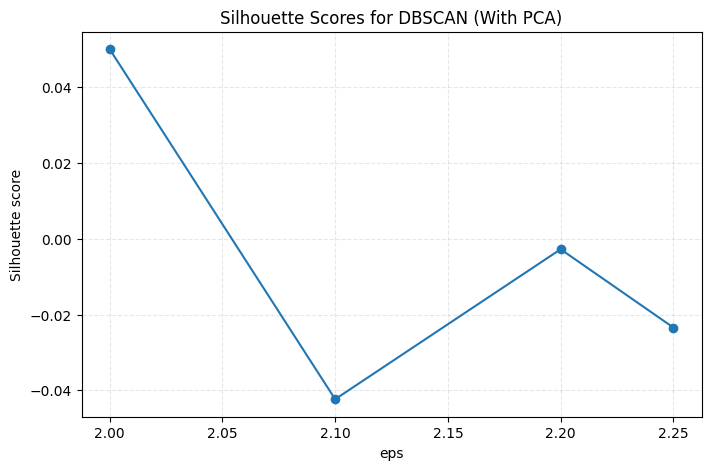


Best eps (PCA) = 2.0 | silhouette = 0.04998185673799578


In [ ]:
sil_scores_pca = []
best_eps_pca = None
best_sil_pca = -1

print("=== DBSCAN on X_pca_transformed (with PCA) ===")
for eps in eps_candidates:
    dbscan_pca = DBSCAN(eps=eps, min_samples=min_samples)
    labels_pca = dbscan_pca.fit_predict(X_pca_transformed)

    unique_labels = set(labels_pca)
    clusters_only = unique_labels - {-1}

    if len(clusters_only) < 2:
        print(f"[PCA] eps={eps} → not enough clusters (labels={unique_labels})")
        sil_scores_pca.append(np.nan)
        continue

    mask = labels_pca != -1
    sil = silhouette_score(X_pca_transformed[mask], labels_pca[mask])
    sil_scores_pca.append(sil)

    print(f"[PCA] eps={eps} → silhouette={sil:.4f}, clusters={clusters_only}")

    if sil > best_sil_pca:
        best_sil_pca = sil
        best_eps_pca = eps

plt.figure(figsize=(8,5))
plt.plot(eps_candidates, sil_scores_pca, marker='o')
plt.title("Silhouette Scores for DBSCAN (With PCA)")
plt.xlabel("eps")
plt.ylabel("Silhouette score")
plt.grid(True, linestyle='--', alpha=0.3)
plt.show()

print("\nBest eps (PCA) =", best_eps_pca, "| silhouette =", best_sil_pca)


In [ ]:
final_dbscan = DBSCAN(eps=best_eps_no_pca, min_samples=min_samples)
final_labels = final_dbscan.fit_predict(df_scaled)

df_dbscan = pd.DataFrame(df_scaled, columns=df.select_dtypes(include='number').columns)
df_dbscan["cluster"] = final_labels


=== Average Characteristics per DBSCAN Cluster===
           Gender       Age  Academic Pressure      CGPA  Study Satisfaction  \
cluster                                                                        
0       -0.891447 -0.543788           0.434905  0.138118           -0.212162   
1       -0.891447 -0.432950           0.448629  0.120888           -0.171131   
2       -0.891447  1.094419          -0.792097 -0.106447            0.647933   
3        1.121771 -0.471103           0.569705 -0.099751           -0.297694   
4        1.121771 -0.650534           0.646345  0.104713           -0.264062   
5        1.121771 -0.559280           0.562272 -0.938930           -0.684432   
6        1.121771 -0.776281           0.055047 -0.046911            1.001969   
7       -0.891447 -0.435465          -0.789088  0.226147            0.785764   
8        1.121771  0.636471           0.718545  0.354777           -0.684432   

         Sleep Duration  Dietary Habits  \
cluster                   

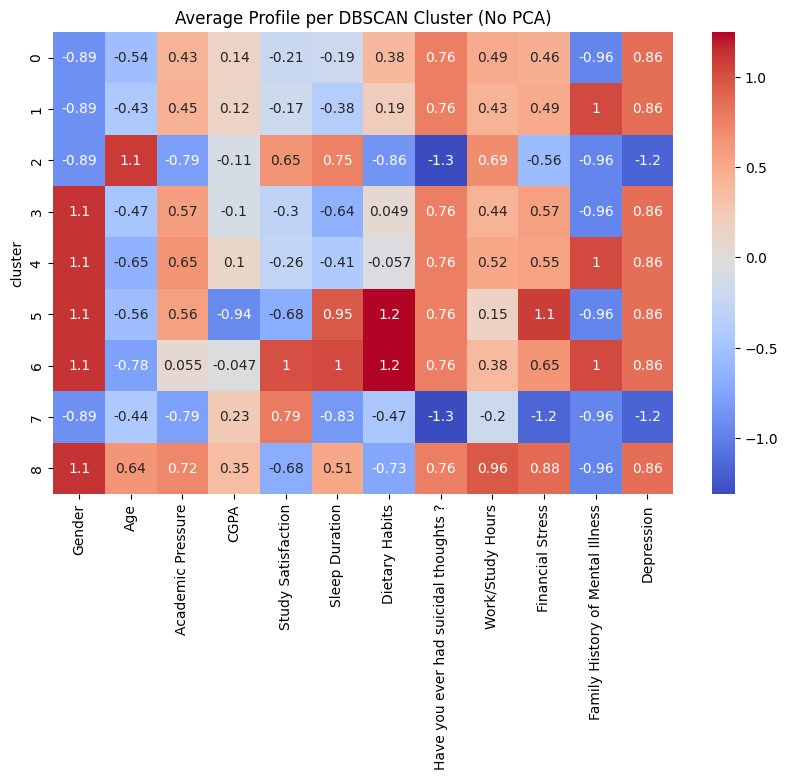

In [ ]:
df_clusters_only = df_dbscan[df_dbscan["cluster"] != -1]

cluster_profiles_dbscan = df_clusters_only.groupby("cluster").mean()

print("=== Average Characteristics per DBSCAN Cluster===")
print(cluster_profiles_dbscan)

plt.figure(figsize=(10,6))
sns.heatmap(cluster_profiles_dbscan, annot=True, cmap="coolwarm")
plt.title("Average Profile per DBSCAN Cluster (No PCA)")
plt.show()
